# Fraud-Risk Intelligence Pipeline

**Task DS_02.** Build a production-oriented fraud decision engine: a calibrated fraud probability, an **Approve / Review / Block** decision, and an explanation for every high-risk transaction, together with the validation, cost analysis, robustness testing, monitoring and governance that a real deployment needs.

| Part | What it does | Main result |
|---|---|---|
| A | Data forensics, quality report, leakage register, hold-out split | 3,000 rows, no duplicates; authentication = None (9.6% of rows) carries signal; 600-row hold-out set locked away |
| B | Exploratory analysis | New device, merchant risk, velocity, amount tail and missing authentication matter; time of day does not; warning signs add up (8.6% to 55.6%) |
| C | Feature engineering | 29 derived features; small, suggestive gain for tree models only |
| D | Baseline and advanced models, nested CV, tuning | PR-AUC about 0.25 for all models; no model statistically better than the baseline |
| E | Cost-sensitive learning | Cost-based thresholds beat the default 0.50 cut-off by 19% to 49%; Random Forest cheapest in 7 of 7 scenarios |
| F | Probability calibration | Platt layer; Random Forest already close to calibrated |
| G | Imbalanced learning | No rebalancing method helped; the plain Random Forest is kept |
| H | Explainable AI (SHAP) | Risk scores, red flags, velocity and amount drive the score; unit-level reasons are only moderately stable |
| I | Operations simulation | Amount-aware policy cuts expected cost by 42% against approving everything; advantage over simple rules not statistically reliable |
| J | Robustness and stress testing | 49 scenarios (28 pass, 9 watch, 10 fail, 2 info); fraud-rate shift is the largest risk |
| K | Model governance | Model card, ten monitors, drift plan, retrain / review / disable rules, answers to the eight questions |

**Rules followed throughout:** one seed (42); a stratified hold-out set created first and never used for selection, tuning, thresholds, calibration or resampling; all learning inside training pipelines; no observations removed to improve metrics; every cost assumption stated and sensitivity-tested; all costs hypothetical.

**How to run:** see `08_README.md`. Run the parts in order; each part reads files written by the earlier ones. The helper modules `fraud_*.py` must sit next to the notebook.

**Companion files:** `02_processed_dataset.csv`, `03_fraud_model_pipeline.joblib`, `04_calibrated_model.joblib`, `05_threshold_cost_analysis.csv`, `06_model_card.pdf`, `07_business_fraud_strategy.pdf`, `08_README.md`.

---

## Part A. Data Forensics & Quality Engineering

**Goal of this part:** prove the data is trustworthy (or document exactly where it is not) *before* any modelling, and record every treatment decision.

| Task A requirement | Section |
|---|---|
| Schema, missingness, duplicates, distributions, cardinality | A1 to A5 |
| Impossible values and extreme observations | A6, A7 |
| Does missingness itself carry signal? | A4 |
| Data-quality report + treatment decisions | A10, A11 |
| Leakage variables and whether they are permissible | A8, A9 |

**Discipline rules used throughout**
1. A stratified hold-out set is carved off **first** (A0) with a fixed seed. Nothing that looks at the `fraud` label ever touches it.
2. Label-free checks (schema, duplicates, rule violations) use all 3,000 rows. Label-conditional checks (fraud rate by missingness, by extremes, by flag) use the **development set only**.
3. No row is deleted and no value is changed in this part. Anything that must *learn* from data (imputation, winsorising, scaling) is deferred into the training pipeline (Parts C/D).

In [1]:
import warnings
from pathlib import Path
import numpy as np, pandas as pd
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 42                      # single global seed, documented in README
np.random.seed(SEED)
pd.set_option("display.width", 220, "display.max_columns", 60, "display.max_rows", 200)

CANDIDATES = [Path("transaction_fraud_risk_advanced_dataset.csv"),
              Path("/mnt/user-data/uploads/transaction_fraud_risk_advanced_dataset.csv")]
DATA_PATH = next(p for p in CANDIDATES if p.exists())
OUT = Path("outputs"); FIG = OUT / "figures"
OUT.mkdir(exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
TARGET, ID = "fraud", "transaction_id"
print("Data:", DATA_PATH, "| seed:", SEED)

Data: transaction_fraud_risk_advanced_dataset.csv | seed: 42


### A0. Load data and create the untouchable hold-out split

In [2]:
df = pd.read_csv(DATA_PATH)
assert df.shape == (3000, 25), df.shape

# 80/20 stratified split. The 20% is the FINAL TEST SET for the whole project.
dev_idx, test_idx = train_test_split(df.index, test_size=0.20, stratify=df[TARGET], random_state=SEED)
dev = df.loc[dev_idx].copy()
split = pd.Series("development", index=df.index); split.loc[test_idx] = "holdout_test"

summary = df.assign(split=split).groupby("split")[TARGET].agg(rows="size", frauds="sum", fraud_rate="mean").round(4)
display(summary)
split.rename("split").to_frame().assign(**{ID: df[ID]})[[ID, "split"]].to_csv(OUT / "split_assignment.csv", index=False)

NUM = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c]) and c != TARGET]
BIN = ["new_device", "billing_address_mismatch"]
CAT = [c for c in df.columns if c not in NUM and c not in (ID, TARGET)]
print("numeric:", NUM); print("categorical:", CAT)

,rows,frauds,fraud_rate
split,,,
development,2400,291,0.1212
holdout_test,600,73,0.1217


numeric: ['hour', 'day_of_week', 'transaction_amount', 'distance_from_usual_location_km', 'transactions_last_1h', 'transactions_last_24h', 'account_age_days', 'failed_logins_24h', 'prior_chargebacks', 'device_age_days', 'merchant_risk_score', 'ip_risk_score', 'email_age_days', 'login_to_transaction_minutes', 'new_device', 'billing_address_mismatch']
categorical: ['card_presence', 'channel', 'country', 'device_type', 'merchant_category', 'authentication_level', 'customer_tier']


### A1. Schema audit
Checks that every column has the expected type, how many values are missing, and how many distinct values it has. `transaction_id` should be a unique identifier, not a feature.

In [3]:
ROLE = {ID: "identifier (not a feature)", TARGET: "target"}
def schema_audit(d):
    rows = []
    for c in d.columns:
        s = d[c]
        rows.append(dict(column=c, dtype=str(s.dtype), role=ROLE.get(c, "binary flag" if c in BIN else ("numeric" if c in NUM else "categorical")),
                         n_missing=int(s.isna().sum()), pct_missing=round(100 * s.isna().mean(), 2),
                         n_unique=int(s.nunique(dropna=True)), example=s.dropna().iloc[0]))
    return pd.DataFrame(rows)

schema = schema_audit(df)
display(schema)

ids = df[ID].str[3:].astype(int)
print("ID format ok:", df[ID].str.fullmatch(r"TXN\d{7}").all(), "| IDs consecutive 1 step:", bool((ids.diff().dropna() == 1).all()))
for c in CAT + [ID]:
    s = df[c].dropna().astype(str)
    assert (s == s.str.strip()).all(), f"whitespace issue in {c}"
print("No leading/trailing whitespace in any text column.")
print("Constant columns:", [c for c in df.columns if df[c].nunique(dropna=True) <= 1] or "none")
print(f"Overall completeness: {100 * (1 - df.isna().sum().sum() / df.size):.2f}% of cells present")

,column,dtype,role,n_missing,pct_missing,n_unique,example
0,transaction_id,str,identifier (not a feature),0,0.00,3000,TXN5000001
1,hour,int64,numeric,0,0.00,24,20
2,day_of_week,int64,numeric,0,0.00,7,0
3,transaction_amount,float64,numeric,53,1.77,2779,35.01
4,distance_from_usual_location_km,float64,numeric,75,2.50,2402,47.93
5,transactions_last_1h,int64,numeric,0,0.00,11,6
6,transactions_last_24h,int64,numeric,0,0.00,25,12
7,account_age_days,int64,numeric,0,0.00,1464,783
8,failed_logins_24h,int64,numeric,0,0.00,4,0
9,prior_chargebacks,int64,numeric,0,0.00,4,0


ID format ok: True | IDs consecutive 1 step: True
No leading/trailing whitespace in any text column.
Constant columns: none
Overall completeness: 99.22% of cells present


### A2. Duplicate audit
Three levels: identical rows, repeated IDs, and identical *content* with a different ID (the sneaky case), plus near-duplicates after rounding.

In [4]:
dup = {
    "exact duplicate rows": int(df.duplicated().sum()),
    "duplicate transaction_id": int(df[ID].duplicated().sum()),
    "duplicate content (ignoring ID)": int(df.drop(columns=ID).duplicated().sum()),
    "near-duplicate content (numerics rounded to 0 dp, ignoring ID)": int(df.drop(columns=ID).round(0).duplicated().sum()),
}
display(pd.Series(dup, name="count").to_frame())

,count
exact duplicate rows,0
duplicate transaction_id,0
duplicate content (ignoring ID),0
"near-duplicate content (numerics rounded to 0 dp, ignoring ID)",0


### A3. Distributions and cardinality
Skewness and kurtosis tell us which numeric variables are heavy-tailed (they will need log transforms for Logistic Regression). The categorical table shows level counts and the smallest level share (rare levels can cause unstable encodings).

In [5]:
desc = df[NUM].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
desc["skew"] = df[NUM].skew(); desc["kurtosis"] = df[NUM].kurt()
desc["skew_after_log1p"] = [np.log1p(df[c].clip(lower=0)).skew() if df[c].min() >= 0 else np.nan for c in NUM]
display(desc.round(3))

card = pd.DataFrame({c: dict(n_levels=df[c].nunique(), n_missing=int(df[c].isna().sum()),
                             largest_level=df[c].value_counts().idxmax(), largest_share=round(df[c].value_counts(normalize=True).max(), 3),
                             smallest_level=df[c].value_counts().idxmin(), smallest_share=round(df[c].value_counts(normalize=True).min(), 3))
                     for c in CAT}).T
display(card)
print("Class balance (all rows):", df[TARGET].value_counts().to_dict(), f"-> fraud rate {df[TARGET].mean():.4f}, imbalance ratio 1:{(1-df[TARGET].mean())/df[TARGET].mean():.1f}")

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew,kurtosis,skew_after_log1p
hour,3000.0,11.623,6.936,0.000,0.000,1.000,6.000,12.000,18.000,22.000,23.000,23.000,-0.031,-1.206,-1.201
day_of_week,3000.0,2.952,1.980,0.000,0.000,0.000,1.000,3.000,5.000,6.000,6.000,6.000,0.051,-1.234,-0.700
transaction_amount,2947.0,134.273,251.375,4.120,11.954,21.518,49.230,88.390,155.260,356.402,679.186,5538.152,15.451,305.056,0.199
distance_from_usual_location_km,2925.0,37.403,48.903,0.490,2.716,6.190,16.810,29.970,48.450,83.334,125.674,1173.269,14.624,290.396,-0.338
transactions_last_1h,3000.0,2.164,1.467,0.000,0.000,0.000,1.000,2.000,3.000,5.000,6.000,10.000,0.726,0.749,-0.503
transactions_last_24h,3000.0,7.778,4.998,0.000,2.000,3.000,6.000,7.000,9.000,12.000,15.000,113.000,13.177,247.940,-0.201
account_age_days,3000.0,886.143,522.155,1.000,21.000,84.000,429.750,887.000,1342.250,1711.000,1778.010,1799.000,0.014,-1.212,-1.761
failed_logins_24h,3000.0,0.330,0.568,0.000,0.000,0.000,0.000,0.000,1.000,1.000,2.000,3.000,1.664,2.485,1.200
prior_chargebacks,3000.0,0.124,0.349,0.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000,3.000,2.795,7.744,2.501
device_age_days,3000.0,747.831,427.847,2.000,18.000,78.950,376.750,741.500,1112.000,1419.000,1480.010,1499.000,0.019,-1.185,-1.800


,n_levels,n_missing,largest_level,largest_share,smallest_level,smallest_share
card_presence,2,0,Present,0.584,Not present,0.416
channel,4,0,E-commerce,0.389,ATM,0.091
country,7,0,Sri Lanka,0.548,USA,0.064
device_type,5,0,Android,0.394,Other,0.081
merchant_category,10,0,Grocery,0.166,Jewelry,0.041
authentication_level,2,289,Strong,0.511,Standard,0.489
customer_tier,4,0,Basic,0.374,Platinum,0.103


Class balance (all rows): {0: 2636, 1: 364} -> fraud rate 0.1213, imbalance ratio 1:7.2


### A4. Missingness forensics: does *missing* carry signal?
Three questions:
1. **How much** is missing, and do values go missing together? (label-free, all rows)
2. Is missingness **random** or tied to other columns? (label-free MAR screen)
3. Is the **fraud rate different** when a value is missing? (label-based, development set only)

Because six variables are tested, a Bonferroni threshold (0.05 / 6) is used so a lucky p-value is not over-interpreted.

In [6]:
MISS = [c for c in df.columns if df[c].isna().any()]
M = df[MISS].isna().astype(int)
print("Columns with missing values:", MISS)
print("Missing cells per row ->", M.sum(axis=1).value_counts().sort_index().to_dict(), "| complete rows:", int((M.sum(axis=1) == 0).sum()))
print("\nCo-occurrence of missingness (correlation of missing flags):")
display(M.corr().round(2))

def mar_screen(d, miss_cols, group_cols):
    rows = []
    for c in miss_cols:
        m = d[c].isna()
        for g in group_cols:
            rows.append(dict(missing_col=c, vs=g, chi2_p=stats.chi2_contingency(pd.crosstab(d[g], m))[1]))
    out = pd.DataFrame(rows)
    out["bonferroni_sig"] = out.chi2_p < 0.05 / len(out)
    return out.sort_values("chi2_p")
mar = mar_screen(df, MISS, CAT + BIN)
print(f"\nMAR screen: {len(mar)} tests, Bonferroni threshold {0.05/len(mar):.5f}. Smallest p-values:")
display(mar.head(6).round(5))

Columns with missing values: ['transaction_amount', 'distance_from_usual_location_km', 'merchant_risk_score', 'ip_risk_score', 'login_to_transaction_minutes', 'authentication_level']
Missing cells per row -> {0: 2458, 1: 503, 2: 38, 3: 1} | complete rows: 2458

Co-occurrence of missingness (correlation of missing flags):


,transaction_amount,distance_from_usual_location_km,merchant_risk_score,ip_risk_score,login_to_transaction_minutes,authentication_level
transaction_amount,1.00,0.03,-0.00,-0.02,0.02,-0.01
distance_from_usual_location_km,0.03,1.00,-0.02,0.03,0.01,-0.02
merchant_risk_score,-0.00,-0.02,1.00,0.00,-0.00,0.07
ip_risk_score,-0.02,0.03,0.00,1.00,-0.02,-0.02
login_to_transaction_minutes,0.02,0.01,-0.00,-0.02,1.00,-0.02
authentication_level,-0.01,-0.02,0.07,-0.02,-0.02,1.00



MAR screen: 54 tests, Bonferroni threshold 0.00093. Smallest p-values:


,missing_col,vs,chi2_p,bonferroni_sig
0,transaction_amount,card_presence,0.01748,False
51,authentication_level,customer_tier,0.02995,False
34,ip_risk_score,new_device,0.04309,False
13,distance_from_usual_location_km,merchant_category,0.07550,False
20,merchant_risk_score,country,0.08041,False
3,transaction_amount,device_type,0.09448,False


In [7]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n); h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return (c - h) / d, (c + h) / d

def missingness_vs_target(d, cols, target=TARGET):
    rows, alpha = [], 0.05 / len(cols)
    for c in cols:
        m = d[c].isna()
        n_m, f_m = int(m.sum()), int(d.loc[m, target].sum()); n_p, f_p = int((~m).sum()), int(d.loc[~m, target].sum())
        p = stats.fisher_exact([[f_m, n_m - f_m], [f_p, n_p - f_p]])[1]
        lo, hi = wilson(f_m, n_m)
        rows.append(dict(column=c, n_missing=n_m, frauds_when_missing=f_m, fraud_rate_if_missing=f_m / n_m, ci95_low=lo, ci95_high=hi,
                         fraud_rate_if_present=f_p / n_p, lift=(f_m / n_m) / (f_p / n_p), fisher_p=p, significant_after_bonferroni=p < alpha))
    return pd.DataFrame(rows).round(4)

miss_target = missingness_vs_target(dev, MISS)          # DEVELOPMENT SET ONLY
display(miss_target)

auth_tab = dev.assign(authentication_level=dev.authentication_level.fillna("MISSING")).pivot_table(
    index="channel", columns="authentication_level", values=TARGET, aggfunc="mean").round(3)
print("Fraud rate by channel x authentication_level (missing as its own level), development set:")
display(auth_tab)

,column,n_missing,frauds_when_missing,fraud_rate_if_missing,ci95_low,ci95_high,fraud_rate_if_present,lift,fisher_p,significant_after_bonferroni
0,transaction_amount,40,3,0.0750,0.0258,0.1986,0.1220,0.6146,0.4703,False
1,distance_from_usual_location_km,56,4,0.0714,0.0281,0.1698,0.1224,0.5834,0.3045,False
2,merchant_risk_score,50,1,0.0200,0.0035,0.1050,0.1234,0.1621,0.0254,False
3,ip_risk_score,32,3,0.0938,0.0324,0.2422,0.1216,0.7708,0.7902,False
4,login_to_transaction_minutes,48,5,0.1042,0.0453,0.2217,0.1216,0.8566,1.0000,False
5,authentication_level,229,48,0.2096,0.1619,0.2669,0.1119,1.8727,0.0001,True


Fraud rate by channel x authentication_level (missing as its own level), development set:


authentication_level,MISSING,Standard,Strong
channel,,,
ATM,0.182,0.096,0.086
E-commerce,0.239,0.133,0.133
Mobile App,0.250,0.116,0.121
POS,0.155,0.098,0.080


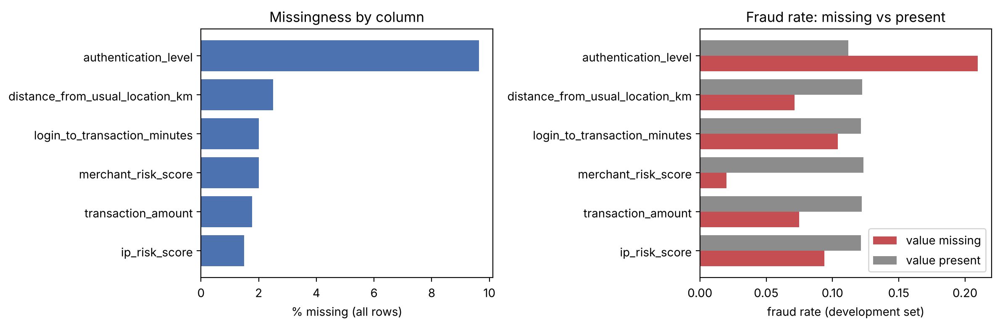

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
pm = (df[MISS].isna().mean() * 100).sort_values()
ax[0].barh(pm.index, pm.values, color="#4C72B0"); ax[0].set_xlabel("% missing (all rows)"); ax[0].set_title("Missingness by column")
mt = miss_target.set_index("column").loc[pm.index]
y = np.arange(len(mt))
ax[1].barh(y - 0.2, mt.fraud_rate_if_missing, 0.4, label="value missing", color="#C44E52")
ax[1].barh(y + 0.2, mt.fraud_rate_if_present, 0.4, label="value present", color="#8C8C8C")
ax[1].set_yticks(y); ax[1].set_yticklabels(mt.index); ax[1].set_xlabel("fraud rate (development set)"); ax[1].legend(); ax[1].set_title("Fraud rate: missing vs present")
plt.tight_layout(); plt.savefig(FIG / "A4_missingness.png", dpi=130); plt.show()

### A5. Why this matters
`authentication_level` is the one column where missing cells behave differently from present ones in a statistically defensible way. The five numeric columns are best treated as ordinary random gaps (see the p-values above against the Bonferroni line). The decision is recorded in A11.

### A6. Impossible and inconsistent values (all 3,000 rows)
Rules are split into **hard** (cannot be true) and **soft** (unusual but possible, depends on how the field is defined). Soft rules are flagged, not "fixed", and each is raised as a question for the data owner.

In [9]:
def rule_masks(d):
    return {
        # ---- hard rules: physically/logically impossible ----
        "H1 amount <= 0":                         ("hard", d.transaction_amount <= 0),
        "H2 distance < 0":                        ("hard", d.distance_from_usual_location_km < 0),
        "H3 risk score outside [0,1]":            ("hard", (d.merchant_risk_score.lt(0) | d.merchant_risk_score.gt(1) | d.ip_risk_score.lt(0) | d.ip_risk_score.gt(1))),
        "H4 hour outside 0-23 or weekday outside 0-6": ("hard", (~d.hour.between(0, 23)) | (~d.day_of_week.between(0, 6))),
        "H5 binary flag not in {0,1}":            ("hard", ~d.new_device.isin([0, 1]) | ~d.billing_address_mismatch.isin([0, 1])),
        "H6 negative count/age":                  ("hard", (d[["transactions_last_1h", "transactions_last_24h", "failed_logins_24h", "prior_chargebacks", "account_age_days", "device_age_days", "email_age_days"]] < 0).any(axis=1)),
        "H7 txns in last 1h > txns in last 24h":  ("hard", d.transactions_last_1h > d.transactions_last_24h),
        "H8 ATM with card 'Not present'":         ("hard", (d.channel == "ATM") & (d.card_presence == "Not present")),
        "H9 E-commerce with card 'Present'":      ("hard", (d.channel == "E-commerce") & (d.card_presence == "Present")),
        # ---- soft rules: suspicious, definition-dependent ----
        "S1 device older than account":           ("soft", d.device_age_days > d.account_age_days),
        "S2 email newer than account":            ("soft", d.email_age_days < d.account_age_days),
        "S3 new_device=1 but device_age > 30d":   ("soft", (d.new_device == 1) & (d.device_age_days > 30)),
        "S4 new_device=0 but device_age <= 7d":   ("soft", (d.new_device == 0) & (d.device_age_days <= 7)),
        "S5 login-to-transaction at 120-min ceiling": ("soft", d.login_to_transaction_minutes >= 120),
        "S6 amount with >2 decimal places":       ("soft", (d.transaction_amount.round(2) - d.transaction_amount).abs() > 1e-9),
        "S7 account_age_days <= 30 (very new)":   ("soft", d.account_age_days <= 30),
    }

RULES = rule_masks(df)
rule_tbl = pd.DataFrame([dict(rule=k, severity=s, n_rows=int(m.sum()), pct_rows=round(100 * m.mean(), 2)) for k, (s, m) in RULES.items()])
display(rule_tbl)
print("Cross-tab channel x card_presence (all rows):"); display(pd.crosstab(df.channel, df.card_presence, margins=True))
print("new_device=1 rows: device_age_days summary:"); display(df.loc[df.new_device == 1, "device_age_days"].describe().round(1).to_frame().T)

,rule,severity,n_rows,pct_rows
0,H1 amount <= 0,hard,0,0.00
1,H2 distance < 0,hard,0,0.00
2,"H3 risk score outside [0,1]",hard,0,0.00
3,H4 hour outside 0-23 or weekday outside 0-6,hard,0,0.00
4,"H5 binary flag not in {0,1}",hard,0,0.00
5,H6 negative count/age,hard,0,0.00
6,H7 txns in last 1h > txns in last 24h,hard,0,0.00
7,H8 ATM with card 'Not present',hard,121,4.03
8,H9 E-commerce with card 'Present',hard,701,23.37
9,S1 device older than account,soft,1240,41.33


Cross-tab channel x card_presence (all rows):


card_presence,Not present,Present,All
channel,,,
ATM,121,153,274
E-commerce,466,701,1167
Mobile App,244,351,595
POS,417,547,964
All,1248,1752,3000


new_device=1 rows: device_age_days summary:


,count,mean,std,min,25%,50%,75%,max
device_age_days,499.0,761.3,420.4,2.0,402.0,758.0,1110.0,1498.0


In [10]:
# Do the flagged rows behave differently on fraud? (DEVELOPMENT SET ONLY)
def flag_vs_target(d, rules):
    rows = []
    for k, (sev, m) in rules.items():
        m = m.loc[d.index]
        n1, n0 = int(m.sum()), int((~m).sum())
        if n1 < 5:
            rows.append(dict(rule=k, n_flagged=n1, note="too few rows to test")); continue
        f1, f0 = int(d.loc[m, TARGET].sum()), int(d.loc[~m, TARGET].sum())
        rows.append(dict(rule=k, n_flagged=n1, fraud_rate_flagged=f1 / n1, fraud_rate_other=f0 / n0,
                         fisher_p=stats.fisher_exact([[f1, n1 - f1], [f0, n0 - f0]])[1]))
    return pd.DataFrame(rows).round(4)
rule_vs_target = flag_vs_target(dev, RULES)
display(rule_vs_target)

,rule,n_flagged,note,fraud_rate_flagged,fraud_rate_other,fisher_p
0,H1 amount <= 0,0,too few rows to test,NaN,NaN,NaN
1,H2 distance < 0,0,too few rows to test,NaN,NaN,NaN
2,"H3 risk score outside [0,1]",0,too few rows to test,NaN,NaN,NaN
3,H4 hour outside 0-23 or weekday outside 0-6,0,too few rows to test,NaN,NaN,NaN
4,"H5 binary flag not in {0,1}",0,too few rows to test,NaN,NaN,NaN
5,H6 negative count/age,0,too few rows to test,NaN,NaN,NaN
6,H7 txns in last 1h > txns in last 24h,0,too few rows to test,NaN,NaN,NaN
7,H8 ATM with card 'Not present',99,NaN,0.1212,0.1213,1.0000
8,H9 E-commerce with card 'Present',560,NaN,0.1250,0.1201,0.7675
9,S1 device older than account,992,NaN,0.1310,0.1143,0.2278


### A7. Extreme observations
Extremes are **kept** (the task forbids removing difficult observations to improve metrics, and fraud often lives in the tail). Fences are learned on the development set only. A 3xIQR rule marks "extreme", and a robust MAD z-score is shown as a second opinion.

In [11]:
HEAVY = ["transaction_amount", "distance_from_usual_location_km", "transactions_last_24h", "login_to_transaction_minutes"]

def extreme_report(d_dev, d_all, cols):
    rows, fences = [], {}
    for c in cols:
        s = d_dev[c].dropna(); q1, q3 = s.quantile([.25, .75]); i = q3 - q1
        lo15, hi15, lo3, hi3 = q1 - 1.5 * i, q3 + 1.5 * i, q1 - 3 * i, q3 + 3 * i
        med = s.median(); mad = (s - med).abs().median()
        fences[c] = hi3
        a = d_all[c]
        ext_dev = d_dev[c] > hi3
        n1 = int(ext_dev.sum()); f1 = int(d_dev.loc[ext_dev, TARGET].sum()); n0 = int((~ext_dev & d_dev[c].notna()).sum()); f0 = int(d_dev.loc[~ext_dev & d_dev[c].notna(), TARGET].sum())
        p = stats.fisher_exact([[f1, n1 - f1], [f0, n0 - f0]])[1] if n1 >= 5 else np.nan
        rows.append(dict(column=c, p99=s.quantile(.99), max=a.max(), upper_fence_1p5=hi15, upper_fence_3=hi3,
                         n_above_1p5_all=int((a > hi15).sum()), n_above_3_all=int((a > hi3).sum()),
                         n_robust_z_gt_3p5_all=int((0.6745 * (a - med).abs() / mad > 3.5).sum()),
                         dev_extreme_n=n1, dev_fraud_rate_extreme=(f1 / n1 if n1 else np.nan), dev_fraud_rate_rest=f0 / n0, fisher_p=p))
    return pd.DataFrame(rows).round(3), fences

ext_tbl, FENCES = extreme_report(dev, df, HEAVY)
display(ext_tbl)
print("Largest values (all rows):")
for c in HEAVY: print(f"  {c}: {df[c].nlargest(6).round(1).tolist()}")
print("\nRows with transactions_last_24h >= 30:"); display(df.loc[df.transactions_last_24h >= 30, [ID, "transactions_last_1h", "transactions_last_24h", "transaction_amount", TARGET]])

,column,p99,max,upper_fence_1p5,upper_fence_3,n_above_1p5_all,n_above_3_all,n_robust_z_gt_3p5_all,dev_extreme_n,dev_fraud_rate_extreme,dev_fraud_rate_rest,fisher_p
0,transaction_amount,684.885,5538.152,316.428,476.523,203,61,174,49,0.265,0.119,0.006
1,distance_from_usual_location_km,125.301,1173.269,95.621,142.875,88,18,48,14,0.429,0.121,0.004
2,transactions_last_24h,15.000,113.000,13.500,18.000,71,6,6,5,0.000,0.122,1.000
3,login_to_transaction_minutes,80.601,120.000,44.556,67.128,166,57,163,44,0.091,0.122,0.647


Largest values (all rows):
  transaction_amount: [5538.2, 5502.8, 5154.5, 5151.8, 5107.9, 2501.2]
  distance_from_usual_location_km: [1173.3, 1130.1, 953.5, 853.8, 833.0, 744.5]
  transactions_last_24h: [113, 107, 105, 96, 94, 89]
  login_to_transaction_minutes: [120.0, 120.0, 120.0, 120.0, 120.0, 120.0]

Rows with transactions_last_24h >= 30:


,transaction_id,transactions_last_1h,transactions_last_24h,transaction_amount,fraud
443,TXN5000444,2,96,157.01,0
1742,TXN5001743,2,94,47.24,0
2394,TXN5002395,3,105,315.18,0
2606,TXN5002607,1,107,156.58,0
2748,TXN5002749,1,89,102.50,0
2780,TXN5002781,4,113,219.79,0


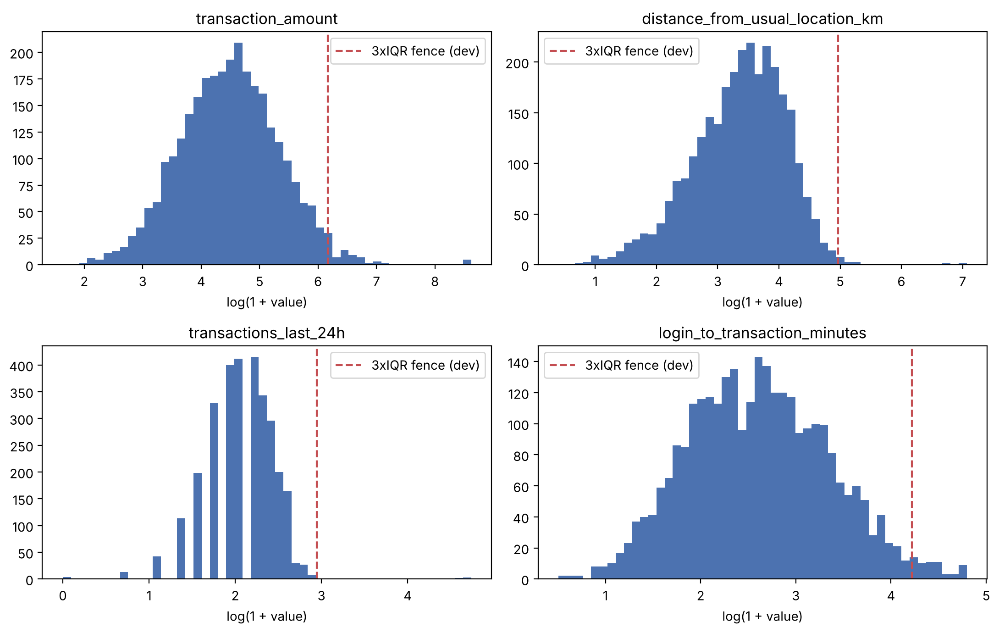

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for a, c in zip(ax.ravel(), HEAVY):
    s = df[c].dropna(); a.hist(np.log1p(s), bins=50, color="#4C72B0"); a.axvline(np.log1p(FENCES[c]), color="#C44E52", ls="--", label="3xIQR fence (dev)")
    a.set_title(c); a.set_xlabel("log(1 + value)"); a.legend()
plt.tight_layout(); plt.savefig(FIG / "A7_extremes.png", dpi=130); plt.show()

### A8. Is there a hidden time axis? (matters for leakage and for the validation design)
The data has `hour` and `day_of_week` but **no date or timestamp**. The IDs are consecutive, so ID order *might* be arrival order. We test whether anything drifts with ID order. If nothing does, a stratified random split is defensible; the limitation is still documented.

In [13]:
order = pd.Series(np.arange(len(df)), index=df.index)
dec = pd.qcut(order.loc[dev.index], 10, labels=False)
tab = dev.groupby(dec)[TARGET].agg(rows="size", frauds="sum", fraud_rate="mean").round(3)
display(tab.T)
chi_p = stats.chi2_contingency(pd.crosstab(dec, dev[TARGET]))[1]
rho, rho_p = stats.spearmanr(order.loc[dev.index], dev[TARGET])
print(f"Fraud rate homogeneity across ID-order deciles: chi2 p = {chi_p:.3f}; Spearman(ID order, fraud) = {rho:.3f} (p = {rho_p:.3f})")
drift = pd.Series({c: stats.spearmanr(order, df[c], nan_policy='omit')[0] for c in NUM}).round(3)
print("Spearman(ID order, feature) for numeric features (label-free, all rows); |rho| > 0.1 would suggest drift:")
display(drift.to_frame("rho").T)

,0,1,2,3,4,5,6,7,8,9
rows,240.000,240.000,240.000,240.000,240.000,240.0,240.000,240.000,240.000,240.000
frauds,33.000,25.000,28.000,21.000,35.000,24.0,40.000,30.000,27.000,28.000
fraud_rate,0.138,0.104,0.117,0.088,0.146,0.1,0.167,0.125,0.112,0.117


Fraud rate homogeneity across ID-order deciles: chi2 p = 0.266; Spearman(ID order, fraud) = 0.005 (p = 0.788)
Spearman(ID order, feature) for numeric features (label-free, all rows); |rho| > 0.1 would suggest drift:


,hour,day_of_week,transaction_amount,distance_from_usual_location_km,transactions_last_1h,transactions_last_24h,account_age_days,failed_logins_24h,prior_chargebacks,device_age_days,merchant_risk_score,ip_risk_score,email_age_days,login_to_transaction_minutes,new_device,billing_address_mismatch
rho,0.008,-0.002,0.0,-0.007,-0.004,0.0,0.017,-0.008,0.026,-0.027,0.025,-0.009,0.003,0.014,0.015,-0.033


### A9. Leakage screen
Leakage = a variable that carries information about the outcome that **would not exist at the moment the transaction is scored**. Two parts: (1) a quantitative sanity check (no single variable should be a near-perfect predictor), and (2) a business-logic register of every field with a verdict.

In [14]:
aucs = {}
for c in NUM:
    x = dev[c].fillna(dev[c].median()); a = roc_auc_score(dev[TARGET], x); aucs[c] = max(a, 1 - a)
auc_tbl = pd.Series(aucs).sort_values(ascending=False).round(3).to_frame("single_feature_AUC (dev, direction-free)")
display(auc_tbl)
print("Max single-feature AUC:", auc_tbl.iloc[0, 0], "-> no variable is a near-perfect predictor, so there is no sign of an obvious target-proxy column.")
print("Min of transactions_last_1h:", df.transactions_last_1h.min(), "| min of transactions_last_24h:", df.transactions_last_24h.min(),
      "-> zeros exist, so the current transaction is NOT counted inside its own velocity window (good).")

,"single_feature_AUC (dev, direction-free)"
transactions_last_1h,0.582
merchant_risk_score,0.572
new_device,0.559
transactions_last_24h,0.554
ip_risk_score,0.549
prior_chargebacks,0.544
account_age_days,0.542
transaction_amount,0.536
billing_address_mismatch,0.525
login_to_transaction_minutes,0.523


Max single-feature AUC: 0.582 -> no variable is a near-perfect predictor, so there is no sign of an obvious target-proxy column.
Min of transactions_last_1h: 0 | min of transactions_last_24h: 0 -> zeros exist, so the current transaction is NOT counted inside its own velocity window (good).


In [15]:
leak = pd.DataFrame([
 (ID, "n/a", "Identifier. Sequential, so could proxy time order.", "EXCLUDE from features", "Used only for audit/ordering. Never a model input."),
 (TARGET, "After the fact", "It is the label.", "TARGET", "Confirmed fraud label. In production it arrives days/weeks later (chargeback delay)."),
 ("transaction_amount", "At scoring", "Known at authorisation.", "PERMIT", "None."),
 ("distance_from_usual_location_km", "At scoring", "Computed from history before this transaction.", "PERMIT", "Baseline location must be built from past data only."),
 ("transactions_last_1h / _24h", "At scoring", "Zeros exist, so current transaction is excluded from the window.", "PERMIT (conditional)", "Confirm windows end strictly BEFORE the scored transaction and are computed from the same feed live."),
 ("account_age_days, device_age_days, email_age_days", "At scoring", "Static history.", "PERMIT", "Ages must be measured at transaction time, not at extract time."),
 ("failed_logins_24h, login_to_transaction_minutes", "At scoring", "Session events before payment.", "PERMIT", "login_to_transaction_minutes is capped at 120 (censored)."),
 ("prior_chargebacks", "At scoring (delayed)", "Chargebacks are confirmed 30-120 days after the original sale, so label delay is a real leakage route.", "PERMIT (conditional)", "Must be a point-in-time count: only chargebacks already CONFIRMED before the scored transaction."),
 ("merchant_risk_score, ip_risk_score", "At scoring", "Often vendor or internally modelled scores. If trained on fraud labels that include this period, they leak.", "PERMIT (conditional)", "Confirm score version is frozen at transaction time and not refit on later outcomes."),
 ("authentication_level", "At scoring (timing risk)", "If step-up authentication is triggered BY the fraud decision or review, it is a consequence, not an input. Missing values are informative.", "PERMIT (conditional)", "Confirm authentication is decided before the model scores. Keep 'Missing' as an explicit level."),
 ("new_device, billing_address_mismatch", "At scoring", "Known at authorisation.", "PERMIT", "new_device definition conflicts with device_age_days (see S3). Clarify."),
 ("card_presence, channel, country, device_type, merchant_category", "At scoring", "Known at authorisation.", "PERMIT", "card_presence vs channel conflicts (see H8/H9). Clarify."),
 ("customer_tier", "At scoring (timing risk)", "Tiers can be re-assigned after loss events (e.g., downgrade after fraud).", "PERMIT (conditional)", "Must be the tier valid at transaction time."),
 ("hour, day_of_week", "At scoring", "Known at authorisation.", "PERMIT", "No calendar date exists, so true out-of-time validation is impossible (see A8)."),
 ("Engineered features (Part C)", "Depends", "Target/mean encodings, group statistics, or anything using full-data aggregates leak.", "RULE", "Every learned transformation is fitted inside the training fold only."),
], columns=["variable", "availability", "leakage_risk", "verdict", "condition_or_note"])
display(leak)

,variable,availability,leakage_risk,verdict,condition_or_note
0,transaction_id,n/a,"Identifier. Sequential, so could proxy time or...",EXCLUDE from features,Used only for audit/ordering. Never a model in...
1,fraud,After the fact,It is the label.,TARGET,Confirmed fraud label. In production it arrive...
2,transaction_amount,At scoring,Known at authorisation.,PERMIT,None.
3,distance_from_usual_location_km,At scoring,Computed from history before this transaction.,PERMIT,Baseline location must be built from past data...
4,transactions_last_1h / _24h,At scoring,"Zeros exist, so current transaction is exclude...",PERMIT (conditional),Confirm windows end strictly BEFORE the scored...
5,"account_age_days, device_age_days, email_age_days",At scoring,Static history.,PERMIT,"Ages must be measured at transaction time, not..."
6,"failed_logins_24h, login_to_transaction_minutes",At scoring,Session events before payment.,PERMIT,login_to_transaction_minutes is capped at 120 ...
7,prior_chargebacks,At scoring (delayed),Chargebacks are confirmed 30-120 days after th...,PERMIT (conditional),Must be a point-in-time count: only chargeback...
8,"merchant_risk_score, ip_risk_score",At scoring,Often vendor or internally modelled scores. If...,PERMIT (conditional),Confirm score version is frozen at transaction...
9,authentication_level,At scoring (timing risk),If step-up authentication is triggered BY the ...,PERMIT (conditional),Confirm authentication is decided before the m...


### A10. Data-quality scorecard

In [16]:
vars_missing = schema.set_index("column").pct_missing
hard_viol = {k: v for k, (s, m) in RULES.items() if s == "hard" for v in [int(m.sum())] if v > 0}
scorecard = pd.Series({
    "rows": len(df), "columns": df.shape[1],
    "completeness_pct_cells": round(100 * (1 - df.isna().sum().sum() / df.size), 2),
    "rows_with_any_missing": int((M.sum(axis=1) > 0).sum()),
    "pct_rows_with_any_missing": round(100 * (M.sum(axis=1) > 0).mean(), 2),
    "exact_duplicate_rows": dup["exact duplicate rows"],
    "duplicate_ids": dup["duplicate transaction_id"],
    "rows_violating_any_hard_rule": int(pd.concat([m for s, m in RULES.values() if s == "hard"], axis=1).any(axis=1).sum()),
    "fraud_rate": round(df[TARGET].mean(), 4),
}, name="value").to_frame()
display(scorecard)
print("Hard rules with violations:", hard_viol or "none")

,value
rows,3000.0000
columns,25.0000
completeness_pct_cells,99.2200
rows_with_any_missing,542.0000
pct_rows_with_any_missing,18.0700
exact_duplicate_rows,0.0000
duplicate_ids,0.0000
rows_violating_any_hard_rule,822.0000
fraud_rate,0.1213


Hard rules with violations: {"H8 ATM with card 'Not present'": 121, "H9 E-commerce with card 'Present'": 701}


### A11. Treatment decision register
Every issue, what was found, what we do, and where it is implemented. Nothing is dropped. Anything that learns from data is fitted inside the training pipeline only.

In [17]:
treat = pd.DataFrame([
 ("T1", "Missing numeric values (amount, distance, merchant risk, ip risk, login minutes)", "Each 1.5% to 2.5% missing; no strong, Bonferroni-surviving link to fraud", "Keep NaN. Add a missing-indicator column. Median-impute INSIDE the pipeline (fit on train fold only).", "Part C/D pipeline"),
 ("T2", "Missing authentication_level (~9.6%)", "Missing rows show a higher fraud rate (see A4) and the gap survives Bonferroni", "Create explicit level 'Missing' (one-hot). Do NOT impute with the mode.", "Part C/D pipeline"),
 ("T3", "Heavy-tailed numerics (amount, distance, 24h count, login minutes)", "Very high skew; log1p reduces it a lot (A3)", "Keep all rows. log1p for Logistic Regression; tree models unaffected. Winsorise only inside pipeline with train-fitted quantiles, if at all.", "Part C/D pipeline"),
 ("T4", "Extreme observations", "Amount and distance extremes show higher fraud rates (A7); extreme 24h counts do not", "Keep. Add dev-fitted extreme flags. Never delete to improve metrics.", "02a_audited_dataset.csv flags"),
 ("T5", "login_to_transaction_minutes capped at 120", "Mass at the ceiling (S5) means the value is censored, not exact", "Keep. Add capped flag. Interpret as '>= 120'.", "flag_login_capped"),
 ("T6", "card_presence conflicts with channel (H8, H9)", "Conflicting combinations are common, so field is unreliable as a literal 'card physically present'", "Keep and flag. Raise with data owner. Test whether the flag adds signal during modelling.", "flag_card_channel_conflict"),
 ("T7", "new_device vs device_age_days disagree (S3, S4)", "Most 'new device' rows have old devices; likely 'new for this customer' vs 'device age overall'", "Keep both, document interpretation, ask data owner. Interactions built with new_device use its flag meaning only.", "Documentation + flag"),
 ("T8", "device older than account (S1), email newer than account (S2)", "Plausible (device/email predate the account or were changed)", "Soft flags only. No change.", "flags"),
 ("T9", "Amounts with more than 2 decimals (S6)", "A handful of very large values in a currency field that is otherwise 2-dp", "Keep, flag, and verify with source (possible injected or converted values).", "flag_amount_nonstandard_precision"),
 ("T10", "transaction_id", "Unique, consecutive, no duplicates", "Exclude from features. Use only as a join key / order reference.", "Part C/D"),
 ("T11", "No timestamp, only hour/day_of_week", "No ID-order drift in fraud rate or features (A8)", "Use stratified random split (seed 42) and repeated stratified CV. Declare that out-of-time validation is not possible.", "split_assignment.csv"),
 ("T12", "Class imbalance (~12% fraud)", "Moderate imbalance, not extreme", "Handle in Part G (class weights vs controlled resampling inside CV). Report PR-AUC, recall, precision, F1, cost.", "Part G"),
 ("T13", "Hold-out discipline", "Test set created before any label-based analysis", "Test set untouched until final evaluation. Selection, tuning, thresholds, calibration, resampling all use development only.", "split_assignment.csv"),
 ("T14", "Unknown categories in production", "New countries/merchant types can appear", "OneHotEncoder(handle_unknown='ignore') in the pipeline.", "Part C/D pipeline"),
], columns=["id", "issue", "evidence", "decision", "implemented_in"])
display(treat)

,id,issue,evidence,decision,implemented_in
0,T1,"Missing numeric values (amount, distance, merc...","Each 1.5% to 2.5% missing; no strong, Bonferro...",Keep NaN. Add a missing-indicator column. Medi...,Part C/D pipeline
1,T2,Missing authentication_level (~9.6%),Missing rows show a higher fraud rate (see A4)...,Create explicit level 'Missing' (one-hot). Do ...,Part C/D pipeline
2,T3,"Heavy-tailed numerics (amount, distance, 24h c...",Very high skew; log1p reduces it a lot (A3),Keep all rows. log1p for Logistic Regression; ...,Part C/D pipeline
3,T4,Extreme observations,Amount and distance extremes show higher fraud...,Keep. Add dev-fitted extreme flags. Never dele...,02a_audited_dataset.csv flags
4,T5,login_to_transaction_minutes capped at 120,Mass at the ceiling (S5) means the value is ce...,Keep. Add capped flag. Interpret as '>= 120'.,flag_login_capped
5,T6,"card_presence conflicts with channel (H8, H9)","Conflicting combinations are common, so field ...",Keep and flag. Raise with data owner. Test whe...,flag_card_channel_conflict
6,T7,"new_device vs device_age_days disagree (S3, S4)",Most 'new device' rows have old devices; likel...,"Keep both, document interpretation, ask data o...",Documentation + flag
7,T8,"device older than account (S1), email newer th...",Plausible (device/email predate the account or...,Soft flags only. No change.,flags
8,T9,Amounts with more than 2 decimals (S6),A handful of very large values in a currency f...,"Keep, flag, and verify with source (possible i...",flag_amount_nonstandard_precision
9,T10,transaction_id,"Unique, consecutive, no duplicates",Exclude from features. Use only as a join key ...,Part C/D


### A12. Save Part A outputs

In [18]:
# Label-free / fitted-on-dev flags attached to the data for use in later parts. No values are altered.
aud = df.copy()
for c in MISS: aud[f"miss_{c}"] = df[c].isna().astype(int)
aud["flag_card_channel_conflict"]            = (RULES["H8 ATM with card 'Not present'"][1] | RULES["H9 E-commerce with card 'Present'"][1]).astype(int)
aud["flag_device_older_than_account"]        = RULES["S1 device older than account"][1].astype(int)
aud["flag_email_newer_than_account"]         = RULES["S2 email newer than account"][1].astype(int)
aud["flag_new_device_age_mismatch"]          = (RULES["S3 new_device=1 but device_age > 30d"][1] | RULES["S4 new_device=0 but device_age <= 7d"][1]).astype(int)
aud["flag_login_capped"]                     = RULES["S5 login-to-transaction at 120-min ceiling"][1].astype(int)
aud["flag_amount_nonstandard_precision"]     = RULES["S6 amount with >2 decimal places"][1].astype(int)
for c in HEAVY: aud[f"flag_extreme_{c}"] = (df[c] > FENCES[c]).astype(int)
aud["split"] = split

aud.to_csv(OUT / "02a_audited_dataset.csv", index=False)
schema.merge(pd.DataFrame({"column": MISS, "missing_n": [int(df[c].isna().sum()) for c in MISS]}), on="column", how="left").to_csv(OUT / "dq_variable_audit.csv", index=False)
miss_target.to_csv(OUT / "dq_missingness_vs_fraud_dev.csv", index=False)
rule_tbl.merge(rule_vs_target, on="rule", how="left").to_csv(OUT / "dq_rule_checks.csv", index=False)
ext_tbl.to_csv(OUT / "dq_extreme_observations.csv", index=False)
leak.to_csv(OUT / "dq_leakage_register.csv", index=False)
treat.to_csv(OUT / "dq_treatment_decisions.csv", index=False)
scorecard.to_csv(OUT / "dq_scorecard.csv")
print(sorted(p.name for p in OUT.iterdir()))

['02a_audited_dataset.csv', 'A_viva_notes.md', 'B_all_segments.csv', 'B_category_fraud_rates.csv', 'B_high_risk_segments.csv', 'B_interaction_screen.csv', 'B_nonlinearity_screen.csv', 'B_viva_notes.md', 'C_ablation_summary.csv', 'C_cv_fold_results_ablation.csv', 'C_cv_fold_results_base_vs_engineered.csv', 'C_cv_fold_results_confirmation_seed2026.csv', 'C_feature_catalogue.csv', 'C_learned_constants.json', 'C_paired_comparison_base_vs_engineered.csv', 'C_recommended_feature_set.json', 'C_rejected_candidates.csv', 'C_sensitivity_risk_group.csv', 'C_viva_notes.md', 'D_importance_consensus.csv', 'D_importance_stability.csv', 'D_leaderboard.csv', 'D_lr_baseline_odds_ratios.csv', 'D_nested_cache.pkl', 'D_nested_fold_results.csv', 'D_oof_predictions.csv', 'D_paired_tests.csv', 'D_permutation_importance_by_fold.csv', 'D_viva_notes.md', 'E_chosen_policy.json', 'E_viva_notes.md', 'F_action_band_forecast.csv', 'F_breakeven_probabilities.csv', 'F_calibration_choice.json', 'F_calibrator_learning_cu

---
## Part B. Advanced Exploratory Analysis

**Rules for this part**
- Every label-based number comes from the **development set only** (2,400 rows). The 600-row hold-out is never touched.
- With about 290 frauds in the development set, a 6-bin chart has roughly 40 frauds per bin, so **every rate is shown with a 95% Wilson confidence interval** and the dashed grey line is the overall fraud rate. A bar that moves but whose interval overlaps the dashed line is noise until proven otherwise.
- This is EDA: it generates hypotheses for feature engineering (Part C). Nothing here is a causal claim.
- Colour: blue = the main series, orange = fraud / the contrast group, grey = reference.

| Task B requirement | Section |
|---|---|
| Fraud rates by channel, merchant, authentication, tier, device, time | B1, B2 |
| Nonlinear effects: amount, velocity, distance, account age, risk scores | B3 |
| Interactions: new_device x distance, amount x merchant risk, authentication x channel | B4 |
| At least 10 visualisations, at least 2 interaction plots | 13 figures, 5 interaction-focused |

In [19]:
import statsmodels.api as sm
from matplotlib.colors import LinearSegmentedColormap

BLUE, ORANGE, GREY, INK = "#2a78d6", "#eb6834", "#8a8a85", "#0b0b0b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8})

eda = dev.copy()                                              # DEVELOPMENT SET ONLY
eda["authentication_level"] = eda["authentication_level"].fillna("Missing")   # explicit level (decision T2)
BASE = eda[TARGET].mean()
print(f"EDA rows: {len(eda)} | frauds: {int(eda[TARGET].sum())} | base fraud rate: {BASE:.4f}")

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight"); plt.show()

def rate_table(d, col):
    g = d.groupby(col, observed=True)[TARGET].agg(n="size", frauds="sum")
    g["rate"] = g.frauds / g.n
    ci = [wilson(k, n) for k, n in zip(g.frauds, g.n)]
    g["lo"], g["hi"] = [c[0] for c in ci], [c[1] for c in ci]
    g["lift"] = g.rate / BASE
    p = stats.chi2_contingency(pd.crosstab(d[col], d[TARGET]))[1]
    return g, p

def rate_bar(ax, d, col, order=None, title=None, rot=0):
    g, p = rate_table(d, col)
    g = g.loc[order] if order is not None else g.sort_values("rate")
    x = np.arange(len(g))
    ax.bar(x, g.rate, color=BLUE, width=.6)
    ax.errorbar(x, g.rate, yerr=[g.rate - g.lo, g.hi - g.rate], fmt="none", ecolor=INK, elinewidth=1, capsize=3)
    ax.axhline(BASE, ls="--", color=GREY, lw=1)
    ax.set_xticks(x); ax.set_xticklabels([f"{i}\nn={n}" for i, n in zip(g.index, g.n)], rotation=rot, ha="right" if rot else "center", fontsize=7)
    ax.set_title(f"{title or col}  (chi2 p = {p:.3f})"); ax.set_ylabel("fraud rate"); ax.set_ylim(bottom=0)
    return g

QEDGES = [0, .2, .4, .6, .8, .9, .95, 1]       # finer cuts in the upper tail, where fraud often hides
def binned_rate(d, col, edges=QEDGES):
    s = d[col].dropna()
    qs = np.unique(s.quantile(edges).values)
    b = pd.cut(s, qs, include_lowest=True)
    g = d.loc[s.index].groupby(b, observed=True)[TARGET].agg(n="size", frauds="sum")
    g["rate"] = g.frauds / g.n
    ci = [wilson(k, n) for k, n in zip(g.frauds, g.n)]
    g["lo"], g["hi"] = [c[0] for c in ci], [c[1] for c in ci]
    g["label"] = [f"{max(i.left, s.min()):.3g}-{i.right:.3g}\nn={n}" for i, n in zip(g.index, g.n)]
    return g

def ci_line(ax, g, title, xlabel):
    x = np.arange(len(g))
    ax.errorbar(x, g.rate, yerr=[g.rate - g.lo, g.hi - g.rate], fmt="-o", color=BLUE, ms=5, lw=1.8, capsize=3, ecolor=GREY)
    ax.axhline(BASE, ls="--", color=GREY, lw=1)
    ax.set_xticks(x); ax.set_xticklabels(g.label, fontsize=6.5)
    ax.set_title(title); ax.set_xlabel(xlabel + "  (quantile bins; last two bins = 90th-95th percentile and top 5%)"); ax.set_ylabel("fraud rate"); ax.set_ylim(bottom=0)

BINNED, DISC = {}, {}          # stored for the high-risk segment table at the end

EDA rows: 2400 | frauds: 291 | base fraud rate: 0.1212


### B1. Fraud rate by category
Question: which channels, merchants, authentication levels, tiers, devices and countries carry more fraud, and is the difference bigger than chance? Seven tests, so the Bonferroni line is 0.05 / 7 = 0.007.

In [20]:
CATS = ["channel", "merchant_category", "authentication_level", "customer_tier", "device_type", "country", "card_presence"]
rows = []
for c in CATS:
    g, p = rate_table(eda, c)
    g = g.reset_index().rename(columns={c: "level"}); g.insert(0, "variable", c); g["chi2_p"] = p; rows.append(g)
cat_tbl = pd.concat(rows, ignore_index=True)
display(cat_tbl.round(4))
print(pd.Series({c: rate_table(eda, c)[1] for c in CATS}).round(4).rename("chi2 p-value").to_frame().T.to_string())
print("Bonferroni threshold:", round(0.05 / len(CATS), 4))

,variable,level,n,frauds,rate,lo,hi,lift,chi2_p
0,channel,ATM,221,22,0.0995,0.0667,0.1461,0.8210,0.0140
1,channel,E-commerce,938,134,0.1429,0.1219,0.1667,1.1782,0.0140
2,channel,Mobile App,471,62,0.1316,0.1041,0.1652,1.0856,0.0140
3,channel,POS,770,73,0.0948,0.0761,0.1176,0.7819,0.0140
4,merchant_category,Digital Services,263,23,0.0875,0.0590,0.1278,0.7213,0.0062
5,merchant_category,Electronics,262,33,0.1260,0.0911,0.1716,1.0388,0.0062
6,merchant_category,Fashion,307,49,0.1596,0.1229,0.2047,1.3164,0.0062
7,merchant_category,Fuel,217,19,0.0876,0.0568,0.1327,0.7221,0.0062
8,merchant_category,Gaming,189,30,0.1587,0.1135,0.2176,1.3091,0.0062
9,merchant_category,Grocery,399,40,0.1003,0.0745,0.1336,0.8268,0.0062


              channel  merchant_category  authentication_level  customer_tier  device_type  country  card_presence
chi2 p-value    0.014             0.0062                0.0001         0.0541       0.9553    0.618         0.1056
Bonferroni threshold: 0.0071


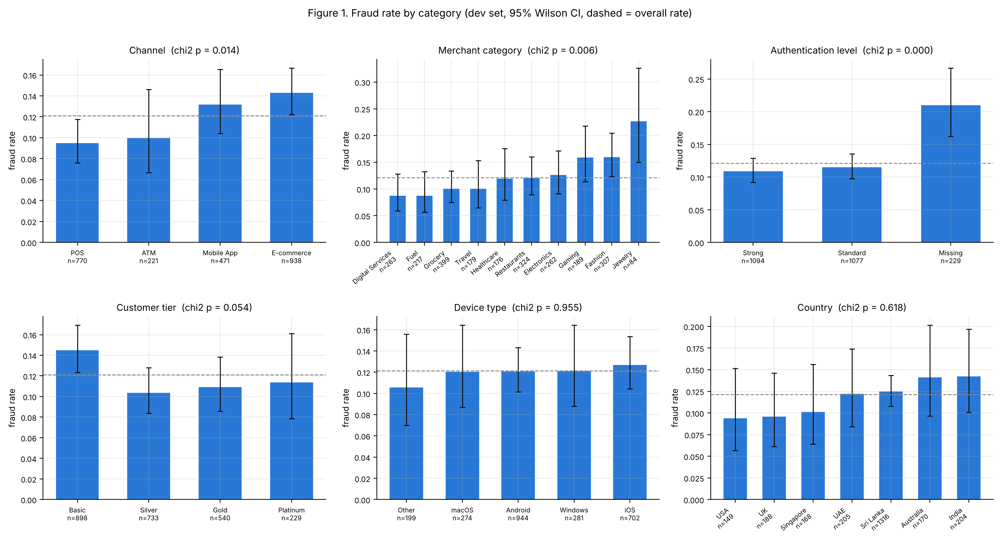

In [21]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
rate_bar(ax[0, 0], eda, "channel", title="Channel")
rate_bar(ax[0, 1], eda, "merchant_category", title="Merchant category", rot=40)
rate_bar(ax[0, 2], eda, "authentication_level", title="Authentication level")
rate_bar(ax[1, 0], eda, "customer_tier", order=["Basic", "Silver", "Gold", "Platinum"], title="Customer tier")
rate_bar(ax[1, 1], eda, "device_type", title="Device type")
rate_bar(ax[1, 2], eda, "country", title="Country", rot=40)
fig.suptitle("Figure 1. Fraud rate by category (dev set, 95% Wilson CI, dashed = overall rate)", y=1.01, fontsize=11)
savefig("B01_category_fraud_rates")

### B2. Fraud rate by time period
`hour` and `day_of_week` are the only time fields (no calendar date). The encoding of `day_of_week` is not documented, so no weekday/weekend claim is made.

,chi2 p
hour (24 levels),0.5242
hour_band (4 levels),0.5779
day_of_week (7 levels),0.3585


,n,frauds,rate,lo,hi,lift
hour_band,,,,,,
00-05,571,72,0.1261,0.1013,0.1558,1.0400
06-11,604,68,0.1126,0.0898,0.1403,0.9285
12-17,606,68,0.1122,0.0895,0.1398,0.9255
18-23,619,83,0.1341,0.1095,0.1632,1.1059


,n,frauds,rate,lo,hi,lift
day_of_week,,,,,,
0,317,30,0.0946,0.0671,0.1319,0.7805
1,389,57,0.1465,0.1148,0.1851,1.2085
2,360,47,0.1306,0.0996,0.1693,1.0767
3,339,37,0.1091,0.0802,0.1468,0.9002
4,353,39,0.1105,0.0819,0.1475,0.9112
5,324,37,0.1142,0.0840,0.1534,0.9418
6,318,44,0.1384,0.1047,0.1807,1.1412


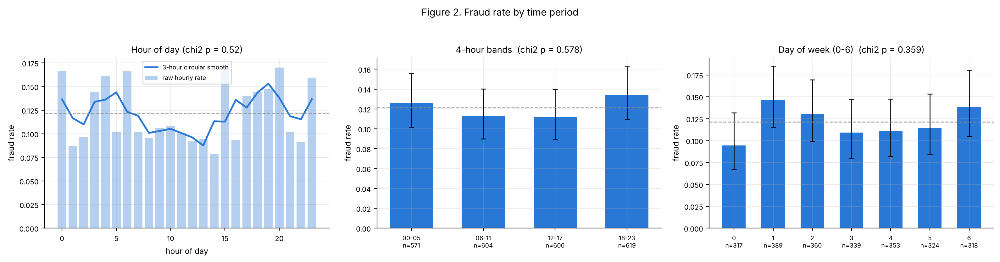

In [22]:
eda["hour_band"] = pd.cut(eda.hour, [-1, 5, 11, 17, 23], labels=["00-05", "06-11", "12-17", "18-23"])
time_p = {"hour (24 levels)": stats.chi2_contingency(pd.crosstab(eda.hour, eda[TARGET]))[1],
          "hour_band (4 levels)": stats.chi2_contingency(pd.crosstab(eda.hour_band, eda[TARGET]))[1],
          "day_of_week (7 levels)": stats.chi2_contingency(pd.crosstab(eda.day_of_week, eda[TARGET]))[1]}
display(pd.Series(time_p, name="chi2 p").round(4).to_frame())
display(rate_table(eda, "hour_band")[0].round(4)); display(rate_table(eda, "day_of_week")[0].round(4))

# hourly rate smoothed with a circular 3-hour window (23:00 sits next to 00:00)
h = eda.groupby("hour")[TARGET].agg(n="size", f="sum").reindex(range(24), fill_value=0)
sm_rate = (sum(np.roll(h.f.values, k) for k in (-1, 0, 1)) / sum(np.roll(h.n.values, k) for k in (-1, 0, 1)))
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].bar(h.index, h.f / h.n, color=BLUE, alpha=.35, label="raw hourly rate"); ax[0].plot(h.index, sm_rate, color=BLUE, lw=2, label="3-hour circular smooth")
ax[0].axhline(BASE, ls="--", color=GREY, lw=1); ax[0].set_xlabel("hour of day"); ax[0].set_ylabel("fraud rate"); ax[0].set_title(f"Hour of day (chi2 p = {time_p['hour (24 levels)']:.2f})"); ax[0].legend(fontsize=7)
rate_bar(ax[1], eda, "hour_band", order=["00-05", "06-11", "12-17", "18-23"], title="4-hour bands")
rate_bar(ax[2], eda, "day_of_week", order=sorted(eda.day_of_week.unique()), title="Day of week (0-6)")
fig.suptitle("Figure 2. Fraud rate by time period", y=1.03, fontsize=11)
savefig("B02_time_patterns")

### B3. Nonlinear effects
For each continuous driver the chart shows fraud rate across quantile bins (finer at the top, where extremes live). Two formal checks sit beside the charts:
- **linear trend p-value**: does a straight-line logit slope exist?
- **nonlinear p-value**: does adding squared and cubic terms improve a logistic fit (likelihood-ratio test, 2 extra parameters)?

In [23]:
def nonlin_screen(d, cols):
    rows = []
    for c in cols:
        s = d[[c, TARGET]].dropna(); x = s[c].astype(float)
        z = np.log1p(x) if (x.min() >= 0 and x.skew() > 2) else x
        z = (z - z.mean()) / z.std()
        X1 = sm.add_constant(pd.DataFrame({"z": z})); X3 = sm.add_constant(pd.DataFrame({"z": z, "z2": z ** 2, "z3": z ** 3}))
        m1 = sm.Logit(s[TARGET], X1).fit(disp=0); m3 = sm.Logit(s[TARGET], X3).fit(disp=0)
        gb = binned_rate(d, c)
        rows.append(dict(variable=c, n=len(s), spearman_rho=stats.spearmanr(x, s[TARGET])[0],
                         odds_ratio_per_sd=np.exp(m1.params["z"]), p_linear=m1.pvalues["z"],
                         p_nonlinear=stats.chi2.sf(2 * (m3.llf - m1.llf), 2),
                         rate_lowest_bin=gb.rate.iloc[0], rate_top5pct_bin=gb.rate.iloc[-1], rate_best_bin=gb.rate.max(), best_bin=str(gb.rate.idxmax())))
    return pd.DataFrame(rows)

CONT = ["transaction_amount", "distance_from_usual_location_km", "transactions_last_1h", "transactions_last_24h",
        "account_age_days", "device_age_days", "email_age_days", "merchant_risk_score", "ip_risk_score", "login_to_transaction_minutes"]
nl_tbl = nonlin_screen(eda, CONT)
display(nl_tbl.round(4))
print("Bonferroni line for 10 variables:", 0.05 / len(CONT))

,variable,n,spearman_rho,odds_ratio_per_sd,p_linear,p_nonlinear,rate_lowest_bin,rate_top5pct_bin,rate_best_bin,best_bin
0,transaction_amount,2360,0.0417,1.1541,0.0219,0.0176,0.1165,0.2458,0.2458,"(354.342, 5538.152]"
1,distance_from_usual_location_km,2344,0.0007,1.0268,0.6755,0.5480,0.1194,0.1695,0.1695,"(83.807, 1173.269]"
2,transactions_last_1h,2400,0.0951,1.3311,0.0000,0.5847,0.0861,0.2391,0.2391,"(5.0, 10.0]"
3,transactions_last_24h,2400,0.0614,1.1971,0.0042,0.1210,0.0878,0.1327,0.1698,"(10.0, 11.0]"
4,account_age_days,2400,-0.0475,0.8638,0.0201,0.8612,0.1396,0.1083,0.1396,"(0.999, 350.8]"
5,device_age_days,2400,-0.0054,0.9825,0.7783,0.1148,0.1042,0.1500,0.1500,"(1419.05, 1499.0]"
6,email_age_days,2400,-0.0007,0.9971,0.9635,0.6854,0.1060,0.1333,0.1333,"(3772.15, 3992.0]"
7,merchant_risk_score,2350,0.0823,1.3088,0.0000,0.5730,0.0955,0.2373,0.2373,"(0.589, 0.818]"
8,ip_risk_score,2368,0.0561,1.1932,0.0033,0.7829,0.1008,0.1513,0.1780,"(0.427, 0.509]"
9,login_to_transaction_minutes,2352,-0.0263,0.9072,0.1257,0.2607,0.1398,0.1017,0.1398,"(0.659, 6.06]"


Bonferroni line for 10 variables: 0.005


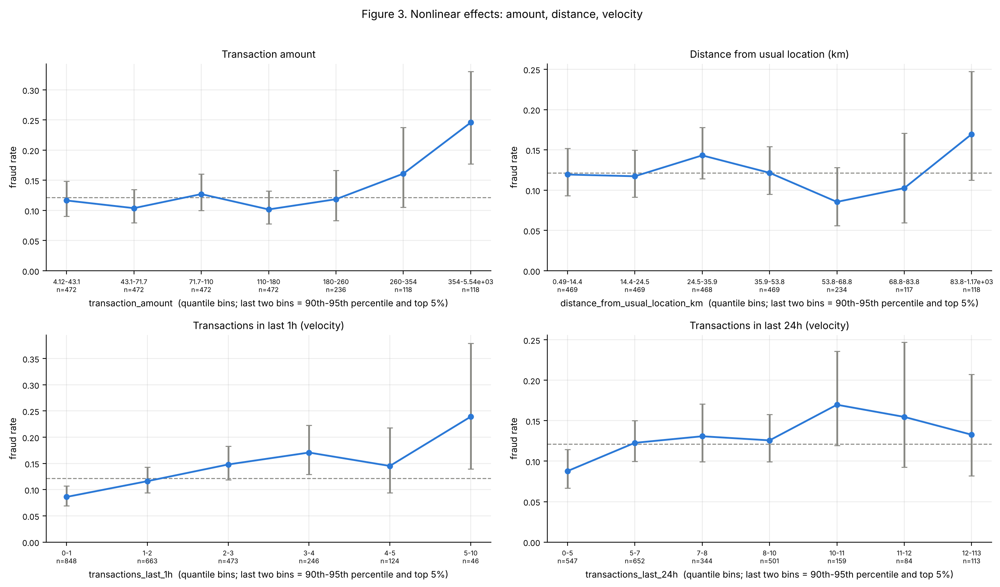

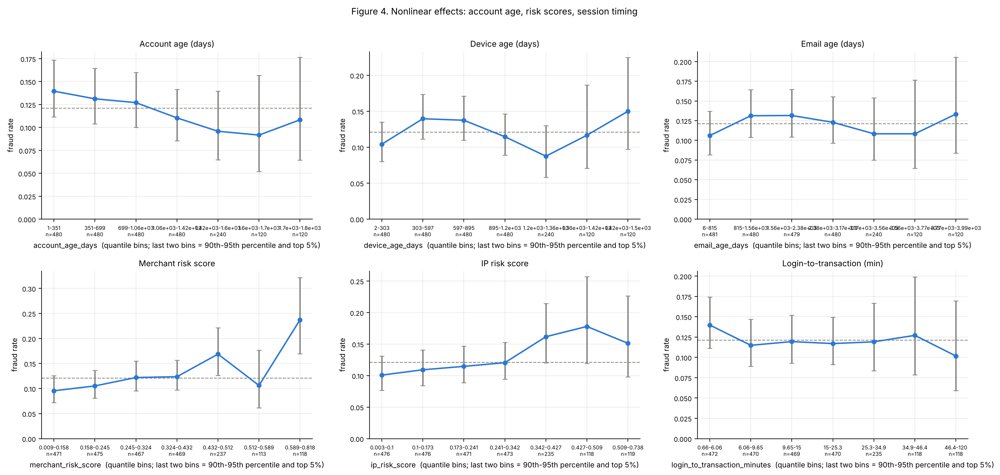

In [24]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
for a, (c, t) in zip(ax.ravel(), [("transaction_amount", "Transaction amount"), ("distance_from_usual_location_km", "Distance from usual location (km)"),
                                  ("transactions_last_1h", "Transactions in last 1h (velocity)"), ("transactions_last_24h", "Transactions in last 24h (velocity)")]):
    BINNED[c] = binned_rate(eda, c); ci_line(a, BINNED[c], t, c)
fig.suptitle("Figure 3. Nonlinear effects: amount, distance, velocity", y=1.01, fontsize=11)
savefig("B03_nonlinear_amount_distance_velocity")

fig, ax = plt.subplots(2, 3, figsize=(17, 8))
for a, (c, t) in zip(ax.ravel(), [("account_age_days", "Account age (days)"), ("device_age_days", "Device age (days)"), ("email_age_days", "Email age (days)"),
                                  ("merchant_risk_score", "Merchant risk score"), ("ip_risk_score", "IP risk score"), ("login_to_transaction_minutes", "Login-to-transaction (min)")]):
    BINNED[c] = binned_rate(eda, c); ci_line(a, BINNED[c], t, c)
fig.suptitle("Figure 4. Nonlinear effects: account age, risk scores, session timing", y=1.01, fontsize=11)
savefig("B04_nonlinear_age_risk_scores")

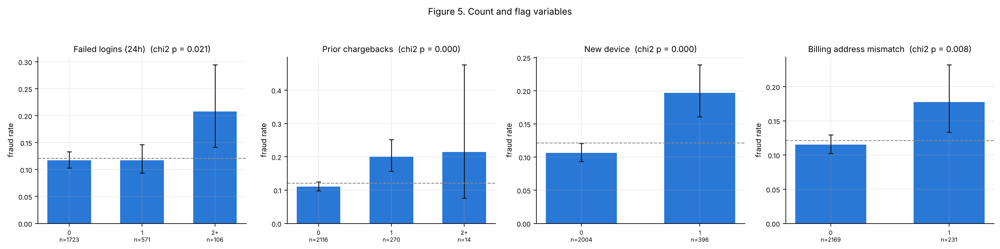

In [25]:
eda["failed_logins_cap"] = eda.failed_logins_24h.clip(upper=2).map({0: "0", 1: "1", 2: "2+"})
eda["chargebacks_cap"] = eda.prior_chargebacks.clip(upper=2).map({0: "0", 1: "1", 2: "2+"})
fig, ax = plt.subplots(1, 4, figsize=(17, 4))
for a, (c, t, o) in zip(ax, [("failed_logins_cap", "Failed logins (24h)", ["0", "1", "2+"]), ("chargebacks_cap", "Prior chargebacks", ["0", "1", "2+"]),
                             ("new_device", "New device", [0, 1]), ("billing_address_mismatch", "Billing address mismatch", [0, 1])]):
    DISC[c] = rate_bar(a, eda, c, order=o, title=t)
fig.suptitle("Figure 5. Count and flag variables", y=1.04, fontsize=11)
savefig("B05_counts_and_flags")

### B4. Interactions
An interaction means the effect of one variable depends on the level of another. Two tools:
1. **Cell charts** with the sample size in every cell (cells with fewer than 30 rows are blanked out, because a rate from 12 rows is not evidence).
2. **Likelihood-ratio test**: does a logistic model with the product term fit better than the model with main effects only? This is the formal test; a pattern in a heatmap without a significant LR test should be treated as noise.

In [26]:
def qbin(s, edges):
    b = pd.qcut(s, edges, duplicates="drop")
    return b.cat.rename_categories([f"{i.left:.3g}-{i.right:.3g}" for i in b.cat.categories])

def two_way(d, a, b):
    s = d[[a, b, TARGET]].dropna()
    r = s.pivot_table(index=a, columns=b, values=TARGET, aggfunc="mean", observed=True)
    n = s.pivot_table(index=a, columns=b, values=TARGET, aggfunc="size", observed=True)
    return r, n

def heat(ax, r, n, title, xlabel, ylabel, min_n=30):
    data = r.where(n >= min_n)
    vmax = max(.30, np.nanmax(data.values))
    im = ax.imshow(data.values.astype(float), cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
    for i in range(r.shape[0]):
        for j in range(r.shape[1]):
            v, k = r.values[i, j], n.values[i, j]
            txt = "n<30" if (np.isnan(v) or k < min_n) else f"{v:.0%}\n(n={int(k)})"
            ax.text(j, i, txt, ha="center", va="center", fontsize=8, color="white" if (not np.isnan(v) and k >= min_n and v > .6 * vmax) else INK)
    ax.set_xticks(range(r.shape[1])); ax.set_xticklabels([str(c) for c in r.columns], fontsize=8)
    ax.set_yticks(range(r.shape[0])); ax.set_yticklabels([str(i) for i in r.index], fontsize=8)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title); ax.grid(False)
    plt.colorbar(im, ax=ax, label="fraud rate", fraction=.046)

CATEG, BINARY = CATS, ["new_device", "billing_address_mismatch"]
def design(s, v):
    if v in CATEG: return pd.get_dummies(s[v], prefix=v, drop_first=True).astype(float)
    x = s[v].astype(float)
    if v not in BINARY:
        if x.min() >= 0 and x.skew() > 2: x = np.log1p(x)
        x = (x - x.mean()) / x.std()
    return x.to_frame(v)

def interaction_lr(d, a, b):
    s = d[[a, b, TARGET]].dropna(); A, B = design(s, a), design(s, b)
    main = pd.concat([A, B], axis=1)
    inter = pd.concat([(A[ca] * B[cb]).rename(f"{ca}*{cb}") for ca in A for cb in B], axis=1)
    y = s[TARGET]
    try:
        m0 = sm.Logit(y, sm.add_constant(main)).fit(disp=0, maxiter=300)
        m1 = sm.Logit(y, sm.add_constant(pd.concat([main, inter], axis=1))).fit(disp=0, maxiter=300)
    except Exception as e:
        return dict(var_a=a, var_b=b, n=len(s), interaction_df=inter.shape[1], note=type(e).__name__)
    lr = 2 * (m1.llf - m0.llf)
    return dict(var_a=a, var_b=b, n=len(s), interaction_df=inter.shape[1], LR_stat=lr, p_value=stats.chi2.sf(lr, inter.shape[1]),
                interaction_odds_ratio=(np.exp(m1.params[inter.columns[0]]) if inter.shape[1] == 1 else np.nan), note="")

PAIRS = [("new_device", "distance_from_usual_location_km"), ("transaction_amount", "merchant_risk_score"), ("authentication_level", "channel"),
         ("ip_risk_score", "failed_logins_24h"), ("new_device", "account_age_days"), ("new_device", "billing_address_mismatch"),
         ("transaction_amount", "account_age_days"), ("transactions_last_1h", "transaction_amount"), ("ip_risk_score", "merchant_risk_score"),
         ("card_presence", "channel"), ("new_device", "ip_risk_score"), ("distance_from_usual_location_km", "ip_risk_score"),
         ("merchant_category", "transaction_amount")]
int_tbl = pd.DataFrame([interaction_lr(eda, a, b) for a, b in PAIRS]).sort_values("p_value")
int_tbl["significant_bonferroni"] = int_tbl.p_value < 0.05 / len(PAIRS)
print(f"{len(PAIRS)} pairs screened; Bonferroni threshold = {0.05/len(PAIRS):.4f}")
display(int_tbl.round(4))

13 pairs screened; Bonferroni threshold = 0.0038


,var_a,var_b,n,interaction_df,LR_stat,p_value,interaction_odds_ratio,note,significant_bonferroni
12,merchant_category,transaction_amount,2360,9,15.2910,0.0832,NaN,,False
11,distance_from_usual_location_km,ip_risk_score,2314,1,2.9498,0.0859,1.1072,,False
7,transactions_last_1h,transaction_amount,2360,1,1.1158,0.2908,0.9359,,False
10,new_device,ip_risk_score,2368,1,0.9013,0.3424,0.8679,,False
6,transaction_amount,account_age_days,2360,1,0.8275,0.3630,1.0611,,False
5,new_device,billing_address_mismatch,2400,1,0.5236,0.4693,1.3720,,False
3,ip_risk_score,failed_logins_24h,2368,1,0.3681,0.5440,0.9678,,False
9,card_presence,channel,2400,3,1.8641,0.6011,NaN,,False
1,transaction_amount,merchant_risk_score,2311,1,0.1913,0.6618,0.9729,,False
0,new_device,distance_from_usual_location_km,2344,1,0.1702,0.6799,1.0631,,False


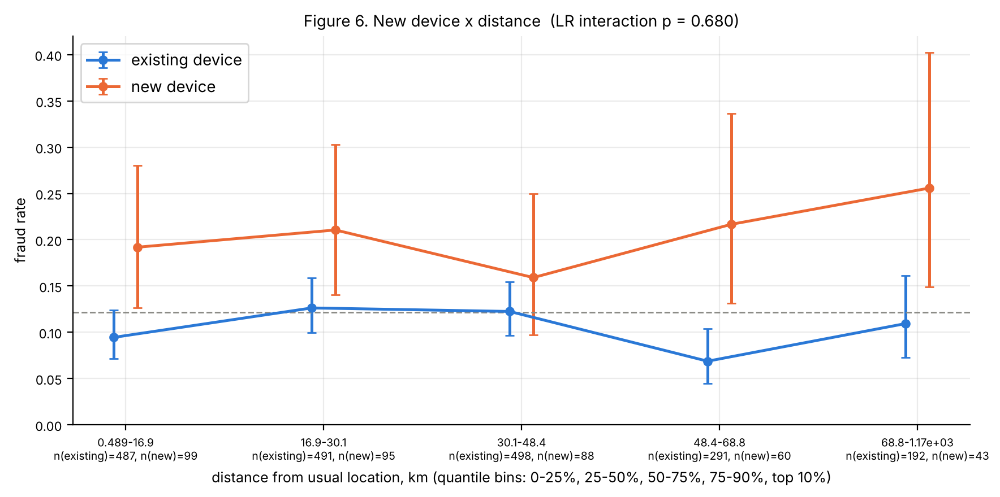

existing device            new device           
                            n   f   rate          n   f   rate
dist_bin                                                      
0.489-16.9                487  46  0.094         99  19  0.192
16.9-30.1                 491  62  0.126         95  20  0.211
30.1-48.4                 498  61  0.122         88  14  0.159
48.4-68.8                 291  20  0.069         60  13  0.217
68.8-1.17e+03             192  21  0.109         43  11  0.256

In [27]:
# Interaction 1 (required): new_device x distance
s = eda[["new_device", "distance_from_usual_location_km", TARGET]].dropna()
s["dist_bin"] = qbin(s.distance_from_usual_location_km, [0, .25, .5, .75, .9, 1])
fig, ax = plt.subplots(1, 1, figsize=(9, 4.5))
tabs = {}
for nd, col, lab in [(0, BLUE, "existing device"), (1, ORANGE, "new device")]:
    g = s[s.new_device == nd].groupby("dist_bin", observed=True)[TARGET].agg(n="size", f="sum"); g["rate"] = g.f / g.n
    ci = [wilson(k, n) for k, n in zip(g.f, g.n)]; g["lo"], g["hi"] = [c[0] for c in ci], [c[1] for c in ci]
    off = -.06 if nd == 0 else .06; x = np.arange(len(g)) + off; tabs[lab] = g
    ax.errorbar(x, g.rate, yerr=[g.rate - g.lo, g.hi - g.rate], fmt="-o", color=col, ms=5, lw=1.8, capsize=3, label=lab)
ax.axhline(BASE, ls="--", color=GREY, lw=1)
ax.set_xticks(range(len(tabs["new device"]))); ax.set_xticklabels([f"{i}\nn(existing)={a}, n(new)={b}" for i, a, b in zip(tabs["new device"].index, tabs["existing device"].n, tabs["new device"].n)], fontsize=7)
ax.set_xlabel("distance from usual location, km (quantile bins: 0-25%, 25-50%, 50-75%, 75-90%, top 10%)"); ax.set_ylabel("fraud rate"); ax.set_ylim(bottom=0); ax.legend()
ax.set_title(f"Figure 6. New device x distance  (LR interaction p = {int_tbl.set_index(['var_a','var_b']).loc[('new_device','distance_from_usual_location_km'),'p_value']:.3f})")
savefig("B06_interaction_newdevice_x_distance")
display(pd.concat({k: v[["n", "f", "rate"]].round(3) for k, v in tabs.items()}, axis=1))

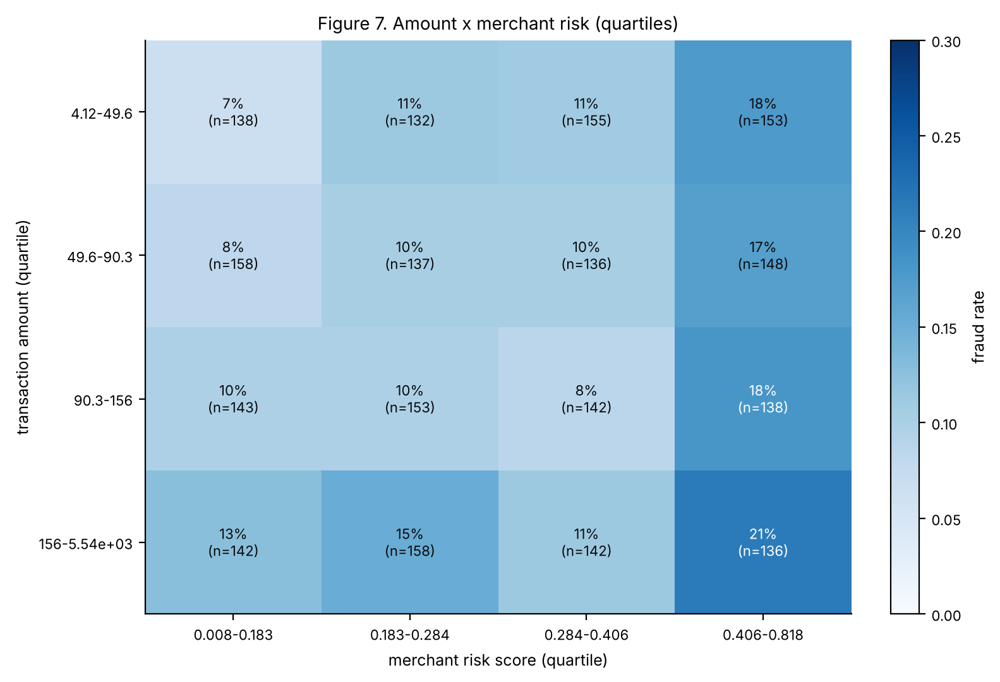

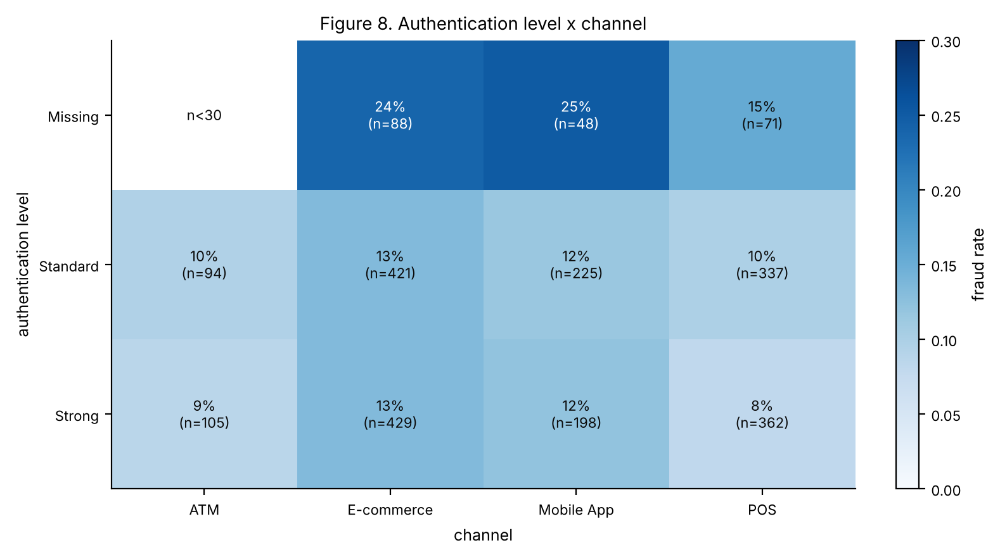

In [28]:
# Interaction 2 (required): amount x merchant risk
s = eda[["transaction_amount", "merchant_risk_score", TARGET]].dropna()
s["amount_q"] = qbin(s.transaction_amount, 4); s["merchant_risk_q"] = qbin(s.merchant_risk_score, 4)
r, n = two_way(s, "amount_q", "merchant_risk_q")
fig, ax = plt.subplots(figsize=(8, 5.5))
heat(ax, r, n, "Figure 7. Amount x merchant risk (quartiles)", "merchant risk score (quartile)", "transaction amount (quartile)")
savefig("B07_interaction_amount_x_merchant_risk")

# Interaction 3 (required): authentication x channel
r, n = two_way(eda, "authentication_level", "channel")
fig, ax = plt.subplots(figsize=(8, 4.5))
heat(ax, r.loc[["Missing", "Standard", "Strong"]], n.loc[["Missing", "Standard", "Strong"]], "Figure 8. Authentication level x channel", "channel", "authentication level")
savefig("B08_interaction_auth_x_channel")

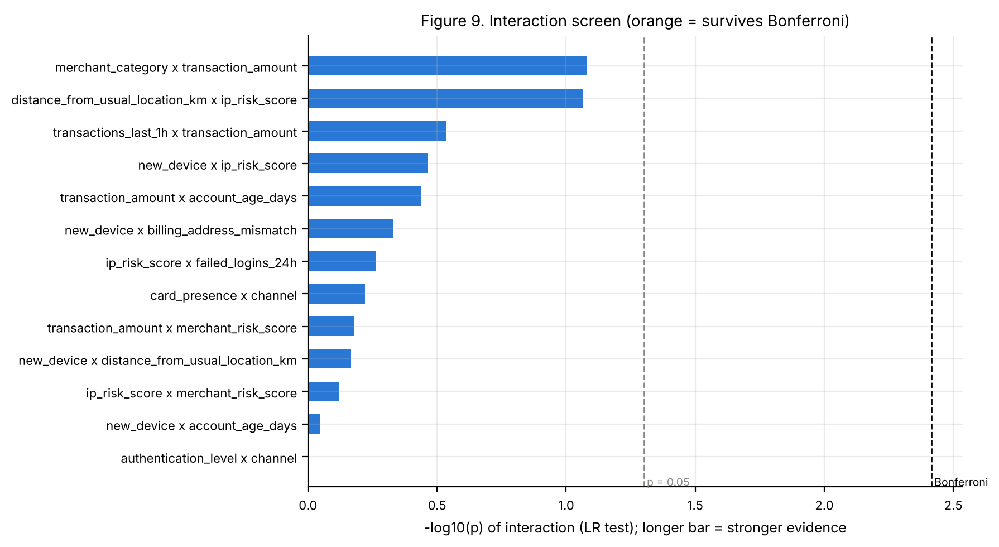

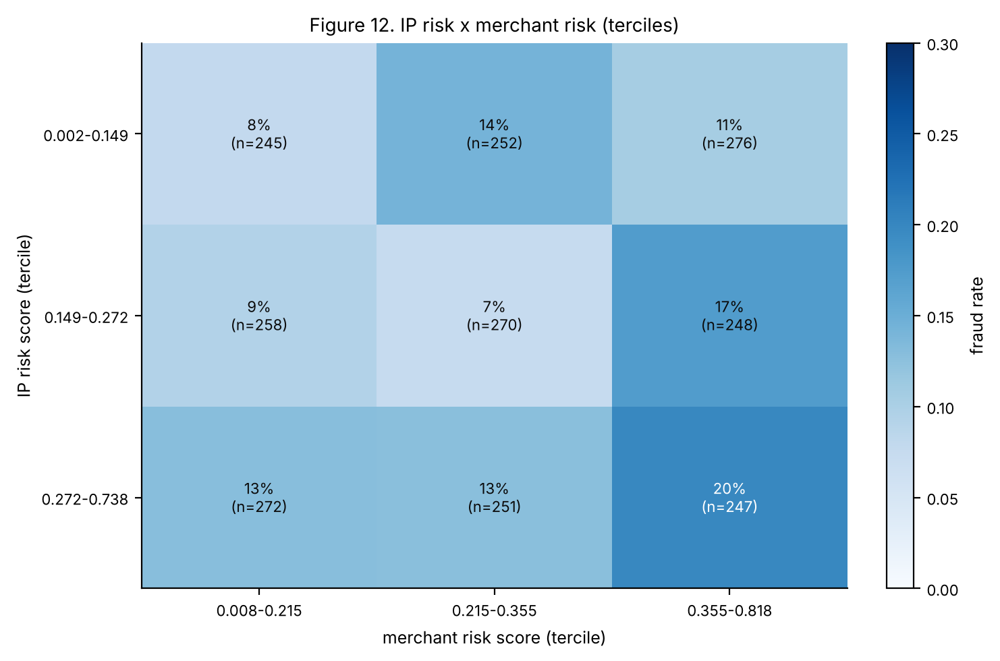

In [29]:
# Figure 9: the interaction screen in one picture
t = int_tbl.dropna(subset=["p_value"]).sort_values("p_value", ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh([f"{a} x {b}" for a, b in zip(t.var_a, t.var_b)], -np.log10(t.p_value), color=[ORANGE if v else BLUE for v in t.significant_bonferroni], height=.6)
ax.axvline(-np.log10(.05), color=GREY, ls="--", lw=1); ax.text(-np.log10(.05), -.9, " p = 0.05", fontsize=7, color=GREY)
ax.axvline(-np.log10(.05 / len(PAIRS)), color=INK, ls="--", lw=1); ax.text(-np.log10(.05 / len(PAIRS)), -.9, " Bonferroni", fontsize=7)
ax.set_xlabel("-log10(p) of interaction (LR test); longer bar = stronger evidence"); ax.set_title("Figure 9. Interaction screen (orange = survives Bonferroni)")
savefig("B09_interaction_screen")

# Figure 12: two risk scores together
s = eda[["ip_risk_score", "merchant_risk_score", TARGET]].dropna()
s["ip_q"] = qbin(s.ip_risk_score, 3); s["mr_q"] = qbin(s.merchant_risk_score, 3)
r, n = two_way(s, "ip_q", "mr_q")
fig, ax = plt.subplots(figsize=(7.5, 5))
heat(ax, r, n, "Figure 12. IP risk x merchant risk (terciles)", "merchant risk score (tercile)", "IP risk score (tercile)")
savefig("B12_interaction_ip_x_merchant_risk")

### B5. Supporting views
Correlation structure (to anticipate redundancy for Logistic Regression), how fraud vs legitimate transactions are distributed, and whether independent warning signs *accumulate*.

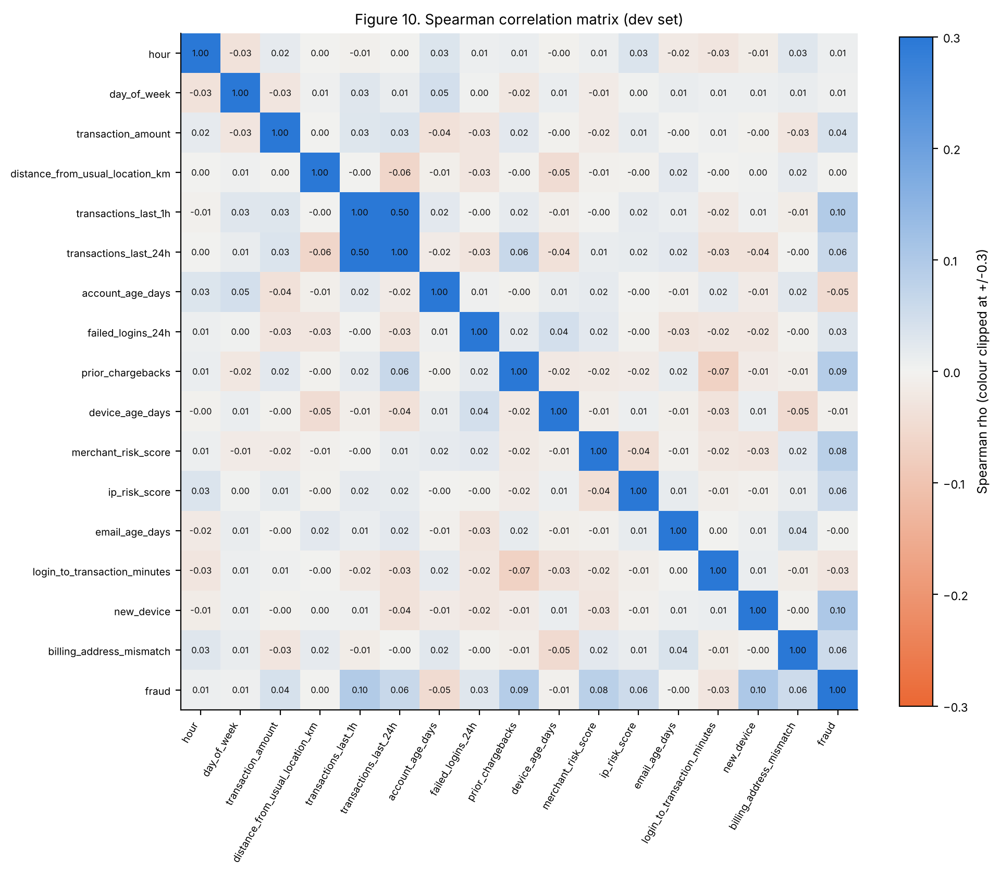

Largest absolute correlation between two predictors: ('transactions_last_1h', 'transactions_last_24h') 0.501
Correlation of each numeric variable with fraud (sorted by |rho|):


,new_device,transactions_last_1h,prior_chargebacks,merchant_risk_score,transactions_last_24h,billing_address_mismatch,ip_risk_score,account_age_days,transaction_amount,login_to_transaction_minutes,failed_logins_24h,hour,day_of_week,device_age_days,email_age_days,distance_from_usual_location_km
rho_with_fraud,0.103,0.095,0.089,0.082,0.061,0.056,0.056,-0.048,0.042,-0.026,0.026,0.007,0.006,-0.005,-0.001,0.001


In [30]:
corr = eda[NUM + [TARGET]].corr(method="spearman")
cmap = LinearSegmentedColormap.from_list("bgo", [ORANGE, "#f2f2f0", BLUE])
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr.values, cmap=cmap, vmin=-.3, vmax=.3)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right", fontsize=7); ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=7)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=6, color=INK)
ax.grid(False); plt.colorbar(im, ax=ax, label="Spearman rho (colour clipped at +/-0.3)", fraction=.04)
ax.set_title("Figure 10. Spearman correlation matrix (dev set)")
savefig("B10_correlation_matrix")
off = corr.where(~np.eye(len(corr), dtype=bool)).abs().drop(index=TARGET, columns=TARGET)
print("Largest absolute correlation between two predictors:", off.stack().idxmax(), round(float(off.stack().max()), 3))
print("Correlation of each numeric variable with fraud (sorted by |rho|):"); display(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_frame("rho_with_fraud").T)

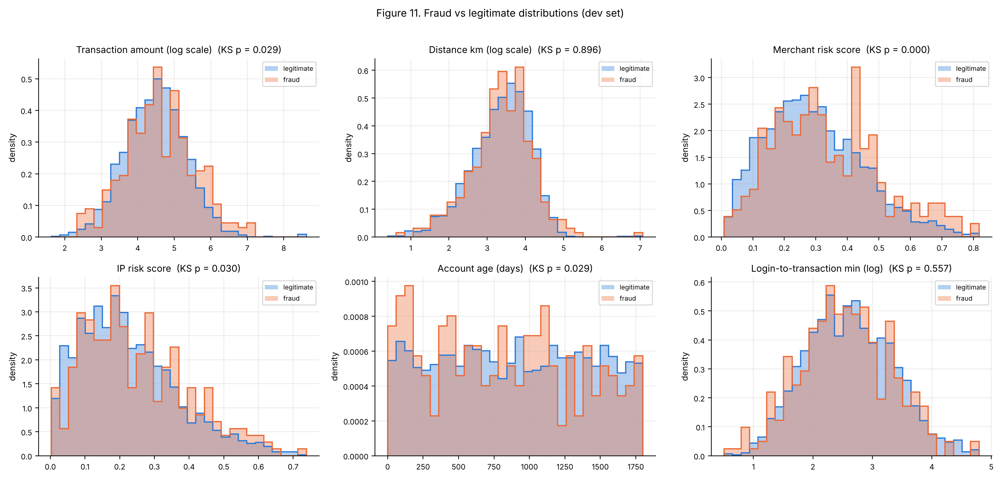

In [31]:
PANELS = [("transaction_amount", True, "Transaction amount (log scale)"), ("distance_from_usual_location_km", True, "Distance km (log scale)"),
          ("merchant_risk_score", False, "Merchant risk score"), ("ip_risk_score", False, "IP risk score"),
          ("account_age_days", False, "Account age (days)"), ("login_to_transaction_minutes", True, "Login-to-transaction min (log)")]
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for a, (c, lg, t) in zip(ax.ravel(), PANELS):
    f = eda.loc[eda[TARGET] == 1, c].dropna(); l = eda.loc[eda[TARGET] == 0, c].dropna()
    f2, l2 = (np.log1p(f), np.log1p(l)) if lg else (f, l)
    bins = np.histogram_bin_edges(pd.concat([f2, l2]), 30)
    a.hist(l2, bins=bins, density=True, histtype="stepfilled", alpha=.35, color=BLUE, label="legitimate")
    a.hist(f2, bins=bins, density=True, histtype="stepfilled", alpha=.35, color=ORANGE, label="fraud")
    a.hist(l2, bins=bins, density=True, histtype="step", color=BLUE, lw=1.3); a.hist(f2, bins=bins, density=True, histtype="step", color=ORANGE, lw=1.3)
    a.set_title(f"{t}  (KS p = {stats.ks_2samp(f2, l2)[1]:.3f})"); a.set_ylabel("density"); a.legend(fontsize=7)
fig.suptitle("Figure 11. Fraud vs legitimate distributions (dev set)", y=1.01, fontsize=11)
savefig("B11_class_conditional_distributions")

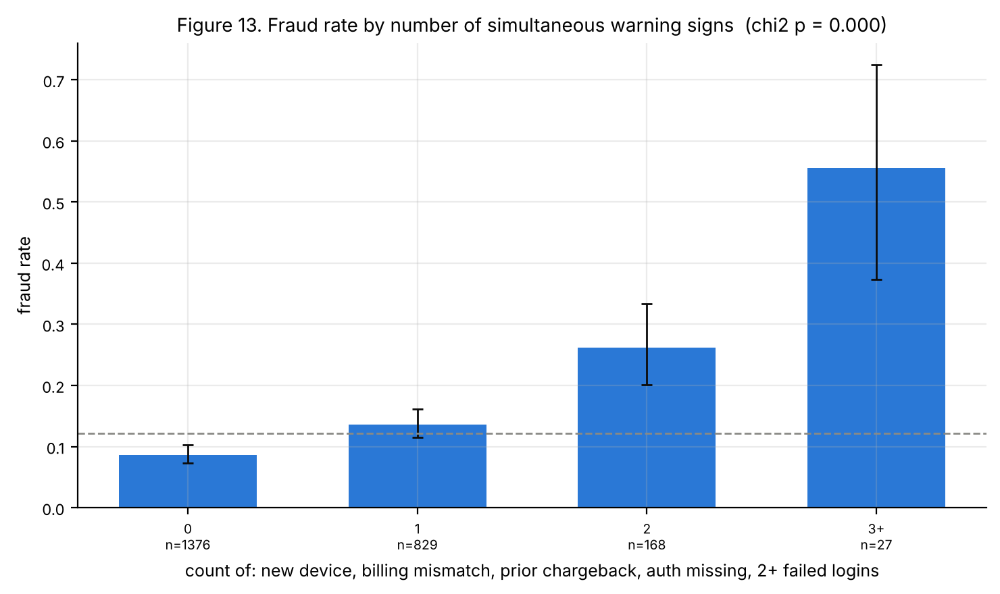

,n,frauds,rate,lo,hi,lift
red_flags,,,,,,
0,1376,119,0.0865,0.0728,0.1025,0.7133
1,829,113,0.1363,0.1146,0.1613,1.1242
2,168,44,0.2619,0.2013,0.3332,2.1600
3+,27,15,0.5556,0.3731,0.7241,4.5819


Trend test (logistic slope on 0-3 count): p = 2.53e-17


In [32]:
# Do independent warning signs accumulate? (indicators chosen after looking at the dev data -> hypothesis for Part C, not an unbiased estimate)
eda["n_red_flags"] = (eda.new_device + eda.billing_address_mismatch + (eda.prior_chargebacks >= 1).astype(int)
                      + (eda.authentication_level == "Missing").astype(int) + (eda.failed_logins_24h >= 2).astype(int))
eda["red_flags"] = eda.n_red_flags.clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})
fig, ax = plt.subplots(figsize=(7.5, 4.5))
DISC["red_flags"] = rate_bar(ax, eda, "red_flags", order=["0", "1", "2", "3+"], title="Figure 13. Fraud rate by number of simultaneous warning signs")
ax.set_xlabel("count of: new device, billing mismatch, prior chargeback, auth missing, 2+ failed logins")
savefig("B13_cumulative_warning_signs")
display(rate_table(eda, "red_flags")[0].round(4))
print("Trend test (logistic slope on 0-3 count): p =", f"{sm.Logit(eda[TARGET], sm.add_constant(eda.n_red_flags.clip(upper=3))).fit(disp=0).pvalues['n_red_flags']:.2e}")

### B6. Which segments are credibly above or below the base rate?
A segment is listed only if its **entire 95% interval** sits above (or below) the overall rate and it has at least 50 rows. Many segments are scanned, so some will pass by luck; treat this list as candidates to carry into modelling, not as findings.

In [33]:
seg = []
for _, r in cat_tbl.iterrows():
    seg.append(dict(source="category", variable=r.variable, segment=str(r.level), n=int(r.n), frauds=int(r.frauds), rate=r.rate, lo=r.lo, hi=r.hi))
for c, g in BINNED.items():
    for iv, r in g.iterrows():
        seg.append(dict(source="numeric bin", variable=c, segment=f"{max(iv.left, eda[c].min()):.3g}-{iv.right:.3g}", n=int(r.n), frauds=int(r.frauds), rate=r.rate, lo=r.lo, hi=r.hi))
for c, g in DISC.items():
    for lvl, r in g.iterrows():
        seg.append(dict(source="flag/count", variable=c, segment=str(lvl), n=int(r.n), frauds=int(r.frauds), rate=r.rate, lo=r.lo, hi=r.hi))
seg = pd.DataFrame(seg); seg["lift_vs_base"] = seg.rate / BASE
print(f"Segments scanned: {len(seg)}. At a 5% error rate, roughly {int(0.05*len(seg))} segments would look 'significant' by chance alone, so treat the lists below as candidates.")
elevated = seg[(seg.lo > BASE) & (seg.n >= 50)].sort_values("lift_vs_base", ascending=False)
lowered = seg[(seg.hi < BASE) & (seg.n >= 50)].sort_values("lift_vs_base")
print("\nCredibly ABOVE base rate:"); display(elevated.round(3))
print("Credibly BELOW base rate:"); display(lowered.round(3))

Segments scanned: 118. At a 5% error rate, roughly 5 segments would look 'significant' by chance alone, so treat the lists below as candidates.

Credibly ABOVE base rate:


,source,variable,segment,n,frauds,rate,lo,hi,lift_vs_base
116,flag/count,red_flags,2,168,44,0.262,0.201,0.333,2.160
41,numeric bin,transaction_amount,354-5.54e+03,118,29,0.246,0.177,0.331,2.027
89,numeric bin,merchant_risk_score,0.589-0.818,118,28,0.237,0.170,0.322,1.957
11,category,merchant_category,Jewelry,84,19,0.226,0.150,0.326,1.865
14,category,authentication_level,Missing,229,48,0.210,0.162,0.267,1.729
106,flag/count,failed_logins_cap,2+,106,22,0.208,0.141,0.294,1.712
108,flag/count,chargebacks_cap,1,270,54,0.200,0.157,0.252,1.649
111,flag/count,new_device,1,396,78,0.197,0.161,0.239,1.624
113,flag/count,billing_address_mismatch,1,231,41,0.177,0.134,0.232,1.464
52,numeric bin,transactions_last_1h,3-4,246,42,0.171,0.129,0.223,1.408


Credibly BELOW base rate:


,source,variable,segment,n,frauds,rate,lo,hi,lift_vs_base
49,numeric bin,transactions_last_1h,0-1,848,73,0.086,0.069,0.107,0.710
114,flag/count,red_flags,0,1376,119,0.086,0.073,0.103,0.713
55,numeric bin,transactions_last_24h,0-5,547,48,0.088,0.067,0.114,0.724
3,category,channel,POS,770,73,0.095,0.076,0.118,0.782
110,flag/count,new_device,0,2004,213,0.106,0.094,0.121,0.877


### B8. Findings (development set; numbers are from the tables and figures above)

**Categories and time (B1, B2)**
- **Authentication level:** a *missing* record has a 21.0% fraud rate (95% CI 16.2% to 26.7%) versus 11.5% for Standard and 10.9% for Strong (p = 0.0001). Strong versus Standard makes no difference, so it is the absent record that carries the signal, not the strength of authentication.
- **Merchant category:** p = 0.006, which just clears the Bonferroni line (0.0071). Jewelry 22.6% (n = 84, CI 15% to 33%), Fashion 16.0% and Gaming 15.9% are highest; Digital Services 8.7% and Fuel 8.8% are lowest.
- **Channel:** E-commerce 14.3% versus POS 9.5% and ATM 10.0% (p = 0.014): moderate evidence, does not pass Bonferroni.
- **Customer tier:** Basic 14.5% versus 10.4% to 11.4% for the other tiers (p = 0.054): borderline.
- **Device type, country, card presence:** no evidence of any difference (p = 0.96, 0.62, 0.11).
- **Time:** nothing. Hour (p = 0.52), 4-hour band (p = 0.58) and day of week (p = 0.36) are all flat. There is no night-time effect in this data.

**Nonlinear effects (B3)**
- **Roughly straight-line drivers:** transactions in the last hour (odds ratio 1.33 per SD, p < 0.0001; 8.6% at 0 to 1 transactions rising to 24% at 5+), merchant risk score (1.31 per SD, p < 0.0001; 9.6% in the lowest bin up to 23.7% in the top bin) and IP risk score (1.19 per SD, p = 0.003). The nonlinearity tests are far from significant (p >= 0.57 for the first two).
- **Amount is a threshold, not a slope:** flat at about 10% to 12% up to roughly 180, then 16% above 260 and 24.6% above 354 (top 5%, CI 17.7% to 33.1%). A straight line understates the tail, so Part C should use log(amount) plus a tail indicator. The cubic test (p = 0.018) does not pass Bonferroni on its own.
- **Distance:** no overall trend (rho = 0.001). Only the top 5% (> 84 km) rises to 17%, and its interval overlaps the overall rate, so it is weak on its own.
- **Account age:** weak negative trend (OR 0.86 per SD, p = 0.02, not Bonferroni). **Device age, email age, login-to-transaction time:** no signal.
- **Flags and counts:** new device 19.7% versus 10.6%; prior chargeback 20.0% versus about 11%; 2+ failed logins 20.8%; billing mismatch 17.7%.
- **Correlation:** the largest correlation between two predictors is 0.50 (printed in Figure 10's cell), so multicollinearity is mild for Logistic Regression.

**Interactions (B4)**
- **None of the 13 screened pairs survives Bonferroni** (smallest p = 0.083, merchant category x amount). Individual interactions are therefore not supported by this data.
- **New device x distance (Figure 6):** a new device is about twice as risky at every distance level and the two lines are roughly parallel (p = 0.68). Two separate effects, not an interaction.
- **Amount x merchant risk (Figure 7):** high merchant risk raises fraud in every amount quartile (17% to 21% in the top risk quartile). The highest cell is top amount x top risk at 21% (n = 136), but the pattern is additive (p = 0.66).
- **Authentication x channel (Figure 8):** a missing authentication record is elevated in every channel; differences between channels are not statistically distinguishable (p = 0.99).
- **Power warning:** with about 290 frauds, moderate interactions could exist and not be detected. Absence of evidence is not evidence of absence. This is re-checked with SHAP interaction values in Part H.
- **Where risk does compound (Figure 13):** with 0, 1, 2 and 3+ simultaneous warning signs the fraud rate is 8.6%, 13.6%, 26.2% and 55.6% (the 3+ group has only 27 rows, CI 37% to 72%). Caution: those five indicators were chosen after looking at this development set, so the size of the effect must be re-validated inside cross-validation before it is believed.

**What this means for Part C (feature engineering)**
1. Log-transform amount and distance and add top-tail indicators; do not rely on a straight line for amount.
2. Keep `authentication_level` Missing as its own level and add the warning-signs count as a candidate feature.
3. Build velocity features (1h count, 1h / 24h ratio) and a combined risk-score feature (merchant + IP).
4. Treat merchant category through grouped or cross-validated encoding (Jewelry, Fashion, Gaming versus the rest), never a full-data target encoding.
5. Expect little from time-of-day, device age, email age and login timing features. Test them, but do not expect them to help.
6. Every selection step in Part C must use cross-validation inside the development set.

### B7. Save Part B outputs

In [34]:
cat_tbl.to_csv(OUT / "B_category_fraud_rates.csv", index=False)
nl_tbl.to_csv(OUT / "B_nonlinearity_screen.csv", index=False)
int_tbl.to_csv(OUT / "B_interaction_screen.csv", index=False)
seg.to_csv(OUT / "B_all_segments.csv", index=False)
pd.concat([elevated.assign(direction="above base"), lowered.assign(direction="below base")]).to_csv(OUT / "B_high_risk_segments.csv", index=False)
figs = sorted(p.name for p in FIG.glob("B*.png"))
print(len(figs), "Part B figures:", figs)

13 Part B figures: ['B01_category_fraud_rates.png', 'B02_time_patterns.png', 'B03_nonlinear_amount_distance_velocity.png', 'B04_nonlinear_age_risk_scores.png', 'B05_counts_and_flags.png', 'B06_interaction_newdevice_x_distance.png', 'B07_interaction_amount_x_merchant_risk.png', 'B08_interaction_auth_x_channel.png', 'B09_interaction_screen.png', 'B10_correlation_matrix.png', 'B11_class_conditional_distributions.png', 'B12_interaction_ip_x_merchant_risk.png', 'B13_cumulative_warning_signs.png']


---
## Part C. Feature Engineering

**Goal:** build defensible derived features, explain each one, state which could be unavailable at scoring time, and test honestly whether they improve models.

**Rules for this part**
1. **No label is used to build a feature.** The transformer (`fraud_features.py`) ignores `y` in `fit`. Any constant it learns (a 95th percentile, a category median) is learned on the training rows only. Inside cross-validation that means the training fold only.
2. **Every feature uses only fields that exist at authorisation time.** Sources are declared per feature and checked by an automated dependency test (C3).
3. **Comparison is paired.** Every configuration uses the *same* 15 folds (5-fold x 3 repeats) on the 2,400-row development set, with fixed, untuned model settings (tuning is Part D). The hold-out set is not evaluated here.
4. **Statistical honesty.** With about 290 frauds, fold-to-fold noise is large. Differences are tested with the Nadeau-Bengio corrected paired t-test, which accounts for overlapping training folds.
5. **The adoption rule is fixed before the results are seen** (C5).

**Known limitation, stated up front:** the dataset has no customer or card identifier and no timestamp. Truly *per-customer* behavioural deviation (this amount versus this customer's own history) and true time-since-last-transaction are impossible. The "behavioural deviation" features here are deviations from the *population* or from the account's own ages, not from a customer's personal history.

### C1. Feature catalogue: what each feature is, why it exists, and when it is available

In [35]:
import sys, json
sys.path.insert(0, str(Path.cwd()))
from fraud_features import FraudFeatureEngineer, build_pipeline, FEATURE_GROUPS, ALL_DERIVED, NUM_BASE, CAT_BASE, derived_columns
from fraud_eval import make_splits, run_cv, corrected_ttest, default_models

X_dev = dev.drop(columns=[ID, TARGET]).reset_index(drop=True)     # DEVELOPMENT SET ONLY
y_dev = dev[TARGET].reset_index(drop=True)
print("development rows:", len(X_dev), "| frauds:", int(y_dev.sum()), "| derived features:", len(ALL_DERIVED), "in", len(FEATURE_GROUPS), "groups")

CATALOGUE = [
 # feature, group, formula, why it should help (evidence from Part B), constants learned on training rows
 ("velocity_ratio_1h_24h", "velocity", "tx_last_1h / (tx_last_24h + 1)", "Share of the day's activity packed into the last hour: a burst signature. 1h count is the strongest numeric driver (B3: 8.6% at 0-1 txns up to 24% at 5+).", ["transactions_last_1h", "transactions_last_24h"], "none"),
 ("velocity_surge", "velocity", "tx_last_1h - tx_last_24h / 24", "Last-hour count minus what a uniform day would give: absolute excess activity.", ["transactions_last_1h", "transactions_last_24h"], "none"),
 ("log_tx_24h", "velocity", "log(1 + tx_last_24h)", "Tames the extreme tail (up to 113; the 6 rows above 30 are all non-fraud) for linear models.", ["transactions_last_24h"], "none"),
 ("log_amount", "amount", "log(1 + amount)", "Amount skew is 15; log scale makes the effect usable by Logistic Regression (B3: amount effect is a tail threshold).", ["transaction_amount"], "none"),
 ("amount_to_category_median", "amount", "amount / median amount of the same merchant category", "Normalises 'big' by what is normal for that merchant type (a 300 grocery basket differs from a 300 jewelry purchase).", ["transaction_amount", "merchant_category"], "10 category medians (global median for unseen category)"),
 ("amount_to_tier_median", "amount", "amount / median amount of the same customer tier", "Normalises amount by customer segment spending level.", ["transaction_amount", "customer_tier"], "4 tier medians (global median for unseen tier)"),
 ("is_amount_tail", "amount", "1 if amount >= training 95th percentile", "B3: top 5% of amounts had 24.6% fraud versus 12.1% overall.", ["transaction_amount"], "amount 95th percentile"),
 ("risk_mean", "risk", "mean(merchant_risk, ip_risk)", "Smoothed combined risk; both scores are individually predictive (B3).", ["merchant_risk_score", "ip_risk_score"], "none"),
 ("risk_max", "risk", "max(merchant_risk, ip_risk)", "'Worst of the two' rule: one bad signal is enough to worry.", ["merchant_risk_score", "ip_risk_score"], "none"),
 ("risk_product", "risk", "merchant_risk x ip_risk", "Rewards both being high together (B4 found the effect additive, so this is a test, not an expectation).", ["merchant_risk_score", "ip_risk_score"], "none"),
 ("high_risk_both", "risk", "1 if merchant_risk >= its training P75 AND ip_risk >= its training P75", "Hard 'both elevated' rule an analyst could read.", ["merchant_risk_score", "ip_risk_score"], "merchant P75, ip P75"),
 ("n_red_flags", "risk", "new_device + billing_mismatch + (prior_chargebacks>=1) + (failed_logins>=2) + auth_missing", "B13: fraud rose from 8.6% to 55.6% as warning signs accumulated. Caution: the five flags were chosen after looking at development data.", ["new_device", "billing_address_mismatch", "prior_chargebacks", "failed_logins_24h", "authentication_level"], "none (cut-offs fixed by rule)"),
 ("is_night", "time", "1 if hour <= 5", "Time-window indicator. B2 found no time effect, so this is expected to be inert and is tested anyway.", ["hour"], "none"),
 ("is_business_hours", "time", "1 if 9 <= hour <= 17", "Time-window indicator for ordinary trading hours. Also expected to be inert.", ["hour"], "none"),
 ("hour_sin", "time", "sin(2 pi hour / 24)", "Cyclic encoding so 23:00 and 00:00 are neighbours.", ["hour"], "none"),
 ("hour_cos", "time", "cos(2 pi hour / 24)", "Second half of the cyclic encoding.", ["hour"], "none"),
 ("log_device_account_gap", "behavior", "log(1+device_age) - log(1+account_age)", "Device much older/newer than the account: a mismatch signal (A6 found 41% of rows have device older than account).", ["device_age_days", "account_age_days"], "none"),
 ("log_email_account_gap", "behavior", "log(1+email_age) - log(1+account_age)", "Brand-new email on an older account (or the reverse) can indicate account takeover.", ["email_age_days", "account_age_days"], "none"),
 ("is_young_account", "behavior", "1 if account_age_days <= 30", "A6: 23% fraud on 39 development rows. Threshold fixed after seeing that table, so treat as a hypothesis.", ["account_age_days"], "none (30-day rule)"),
 ("is_quick_login", "behavior", "1 if login_to_transaction_minutes <= training 10th percentile", "Very fast login-to-purchase can indicate scripted behaviour. B3 showed only a weak effect.", ["login_to_transaction_minutes"], "login 10th percentile"),
 ("log_login_minutes", "behavior", "log(1 + login_to_transaction_minutes)", "Login time is skewed and capped at 120; log scale for linear models.", ["login_to_transaction_minutes"], "none"),
 ("distance_robust_z", "behavior", "(log(1+distance) - training median) / (1.4826 x training MAD)", "Deviation from the usual travel distance in robust standard-deviation units; outlier-resistant.", ["distance_from_usual_location_km"], "median and MAD of log distance"),
 ("is_far_distance", "behavior", "1 if distance >= training 95th percentile", "B3: top 5% distance had 17% fraud (weak, interval overlaps base).", ["distance_from_usual_location_km"], "distance 95th percentile"),
 ("newdev_x_logdist", "interaction", "new_device x log(1+distance)", "New device far from the usual location. B4: parallel effects, so a test of additive vs joint.", ["new_device", "distance_from_usual_location_km"], "none"),
 ("logamt_x_merchrisk", "interaction", "log_amount x merchant_risk", "Big amount at a risky merchant (B4: additive; included as the required interaction test).", ["transaction_amount", "merchant_risk_score"], "none"),
 ("authmiss_x_digital", "interaction", "auth_missing x (channel is E-commerce or Mobile App)", "Missing authentication on card-not-present digital channels.", ["authentication_level", "channel"], "none"),
 ("newdev_x_iprisk", "interaction", "new_device x ip_risk", "New device arriving from a risky IP.", ["new_device", "ip_risk_score"], "none"),
 ("billmis_x_newdev", "interaction", "billing_mismatch x new_device", "Two identity-mismatch flags together.", ["billing_address_mismatch", "new_device"], "none"),
 ("velocity_x_logamt", "interaction", "tx_last_1h x log_amount", "Rapid-fire transactions with large amounts.", ["transactions_last_1h", "transaction_amount"], "none"),
]
cat = pd.DataFrame(CATALOGUE, columns=["feature", "group", "formula", "rationale", "sources", "learned_constants"])
assert list(cat.feature) == ALL_DERIVED and all(cat.group == [g for g, fs in FEATURE_GROUPS.items() for _ in fs]), "catalogue out of sync with code"

# Base fields whose availability carries a CONDITION in the Part A leakage register (A9)
CONDITIONAL_BASE = {"transactions_last_1h": "velocity window must end before the scored transaction",
                    "transactions_last_24h": "velocity window must end before the scored transaction",
                    "prior_chargebacks": "only chargebacks already confirmed before scoring",
                    "merchant_risk_score": "score version frozen at transaction time",
                    "ip_risk_score": "score version frozen at transaction time",
                    "authentication_level": "must be decided before the model scores",
                    "customer_tier": "tier valid at transaction time"}
cat["available_at_prediction"] = ["Yes, conditional" if any(s in CONDITIONAL_BASE for s in src) else "Yes" for src in cat.sources]
cat["inherits_condition_from"] = ["; ".join(f"{s} ({CONDITIONAL_BASE[s]})" for s in src if s in CONDITIONAL_BASE) or "-" for src in cat.sources]
cat["needs_stored_constants"] = (cat.learned_constants != "none") & (~cat.learned_constants.str.startswith("none"))
cat["sources"] = cat.sources.apply(lambda s: ", ".join(s))
pd.set_option("display.max_colwidth", 140)
display(cat[["feature", "group", "formula", "learned_constants", "available_at_prediction"]])
print("Features per group:", cat.group.value_counts().reindex(list(FEATURE_GROUPS)).to_dict())
print("Unavailable at prediction time (given the base fields are available):", int((cat.available_at_prediction == "No").sum()))
print("Available only under a condition inherited from a base field:", int((cat.available_at_prediction == "Yes, conditional").sum()), "of", len(cat))
print("Need stored training constants in production:", int(cat.needs_stored_constants.sum()))

development rows: 2400 | frauds: 291 | derived features: 29 in 6 groups


,feature,group,formula,learned_constants,available_at_prediction
0,velocity_ratio_1h_24h,velocity,tx_last_1h / (tx_last_24h + 1),none,"Yes, conditional"
1,velocity_surge,velocity,tx_last_1h - tx_last_24h / 24,none,"Yes, conditional"
2,log_tx_24h,velocity,log(1 + tx_last_24h),none,"Yes, conditional"
3,log_amount,amount,log(1 + amount),none,Yes
4,amount_to_category_median,amount,amount / median amount of the same merchant category,10 category medians (global median for unseen category),Yes
5,amount_to_tier_median,amount,amount / median amount of the same customer tier,4 tier medians (global median for unseen tier),"Yes, conditional"
6,is_amount_tail,amount,1 if amount >= training 95th percentile,amount 95th percentile,Yes
7,risk_mean,risk,"mean(merchant_risk, ip_risk)",none,"Yes, conditional"
8,risk_max,risk,"max(merchant_risk, ip_risk)",none,"Yes, conditional"
9,risk_product,risk,merchant_risk x ip_risk,none,"Yes, conditional"


Features per group: {'velocity': 3, 'amount': 4, 'risk': 5, 'time': 4, 'behavior': 7, 'interaction': 6}
Unavailable at prediction time (given the base fields are available): 0
Available only under a condition inherited from a base field: 13 of 29
Need stored training constants in production: 7


**How to read the availability column.** None of the 29 features needs information from the future, from the label, or from other customers' transactions, so none is *unavailable* at scoring time **provided its base inputs are**. Where a base input carried a leakage condition in A9 (velocity windows, chargebacks, vendor risk scores, authentication timing, tier timing), the derived feature **inherits that condition**, and the deployment check is the same one. Features that use a learned constant (a percentile or a category median) must ship the constants with the model; they are saved to `outputs/C_learned_constants.json`.

In [36]:
REJECTED = pd.DataFrame([
 ("Target / fraud-rate encoding of merchant_category, country, channel", "Uses the label to build the feature; leaks unless done strictly out-of-fold. Replaced by plain one-hot encoding plus amount-to-category normalisation."),
 ("Amount z-score against the CUSTOMER'S own history", "No customer or card identifier exists, so per-customer history cannot be built."),
 ("Time since the customer's last transaction / spend in the last 7 or 30 days", "No timestamp or customer identifier. Only 1h and 24h counts exist and are already used."),
 ("Percentile rank of amount over the full dataset (train + hold-out)", "Uses hold-out rows to define the scale. Replaced by training-only constants."),
 ("Any feature built from the transaction_id sequence", "ID order carries no information (A8) and would be a leakage risk if the ID ever encodes time."),
 ("Future-looking aggregates (fraud count in the same country/merchant later in the data)", "Label-derived and uses information from after the scored transaction."),
 ("Features from `fraud` of neighbouring rows", "Direct label leakage."),
], columns=["rejected_candidate", "reason"])
display(REJECTED)
cat.to_csv(OUT / "C_feature_catalogue.csv", index=False); REJECTED.to_csv(OUT / "C_rejected_candidates.csv", index=False)

,rejected_candidate,reason
0,"Target / fraud-rate encoding of merchant_category, country, channel",Uses the label to build the feature; leaks unless done strictly out-of-fold. Replaced by plain one-hot encoding plus amount-to-category ...
1,Amount z-score against the CUSTOMER'S own history,"No customer or card identifier exists, so per-customer history cannot be built."
2,Time since the customer's last transaction / spend in the last 7 or 30 days,No timestamp or customer identifier. Only 1h and 24h counts exist and are already used.
3,Percentile rank of amount over the full dataset (train + hold-out),Uses hold-out rows to define the scale. Replaced by training-only constants.
4,Any feature built from the transaction_id sequence,ID order carries no information (A8) and would be a leakage risk if the ID ever encodes time.
5,Future-looking aggregates (fraud count in the same country/merchant later in the data),Label-derived and uses information from after the scored transaction.
6,Features from `fraud` of neighbouring rows,Direct label leakage.


### C2. Build the features and run the safety tests
Three automated checks before any model is fitted:
1. **No bad values:** no infinities, and missing inputs give missing outputs (never silently invented numbers).
2. **Label independence:** fitting with the real labels and with randomly permuted labels must give identical features.
3. **Dependency test:** for every base column, shuffle it and recompute every feature. A feature may change **only** if that column is among its declared sources. This proves the catalogue is true and that no feature secretly uses an undeclared column (including the label).

In [37]:
fe_all = FraudFeatureEngineer(groups=tuple(FEATURE_GROUPS)).fit(X_dev)           # fitted on development rows only
F = fe_all.transform(X_dev)[ALL_DERIVED]

print("1. non-finite values:", int(np.isinf(F.to_numpy(dtype=float)).sum()))
nan_tbl = F.isna().sum()[lambda s: s > 0].rename("NaN rows (inherited from missing inputs)")
display(nan_tbl.to_frame().T)

# 2. label independence
rng = np.random.default_rng(0)
fe_perm = FraudFeatureEngineer(groups=tuple(FEATURE_GROUPS)).fit(X_dev, pd.Series(rng.permutation(y_dev.values)))
same = np.allclose(fe_perm.transform(X_dev)[ALL_DERIVED].to_numpy(float), F.to_numpy(float), equal_nan=True)
print("2. identical features with permuted labels:", same)
assert same

# 3. dependency test
SRC = {r.feature: set(s.strip() for s in r.sources.split(",")) for r in cat.itertuples()}
actual = {f: set() for f in ALL_DERIVED}
for col in NUM_BASE + CAT_BASE:
    Xp = X_dev.copy(); Xp[col] = X_dev[col].sample(frac=1, random_state=1).values
    out = fe_all.transform(Xp)[ALL_DERIVED]
    for f in ALL_DERIVED:
        if not np.allclose(out[f].to_numpy(float), F[f].to_numpy(float), equal_nan=True):
            actual[f].add(col)
mismatch = {f: (sorted(SRC[f]), sorted(actual[f])) for f in ALL_DERIVED if SRC[f] != actual[f]}
print("3. features whose measured dependencies differ from the catalogue:", mismatch or "none")
assert not mismatch
print("   -> all", len(ALL_DERIVED), "features depend on exactly the base columns declared in the catalogue.")

# learned constants stored for deployment
CONST = {k: (v if not isinstance(v, dict) else {str(a): float(b) for a, b in v.items()}) for k, v in
         {"amount_p95": fe_all.amount_p95_, "global_amount_median": fe_all.global_amount_median_, "category_amount_median": fe_all.cat_median_,
          "tier_amount_median": fe_all.tier_median_, "login_p10": fe_all.login_p10_, "merchant_risk_p75": fe_all.merchant_p75_,
          "ip_risk_p75": fe_all.ip_p75_, "log_distance_median": fe_all.dist_log_median_, "log_distance_mad_scaled": fe_all.dist_log_mad_,
          "distance_p95": fe_all.dist_p95_}.items()}
CONST = {k: (float(v) if not isinstance(v, dict) else v) for k, v in CONST.items()}
(OUT / "C_learned_constants.json").write_text(json.dumps(CONST, indent=2))
display(pd.Series({k: v for k, v in CONST.items() if not isinstance(v, dict)}, name="value").round(3).to_frame())

1. non-finite values: 0


,log_amount,amount_to_category_median,amount_to_tier_median,is_amount_tail,risk_mean,risk_max,risk_product,high_risk_both,is_quick_login,log_login_minutes,distance_robust_z,is_far_distance,newdev_x_logdist,logamt_x_merchrisk,newdev_x_iprisk,velocity_x_logamt
NaN rows (inherited from missing inputs),40,40,40,40,1,1,81,81,48,48,56,56,56,89,32,40


2. identical features with permuted labels: True


3. features whose measured dependencies differ from the catalogue: none
   -> all 29 features depend on exactly the base columns declared in the catalogue.


,value
amount_p95,354.342
global_amount_median,90.320
login_p10,4.292
merchant_risk_p75,0.405
ip_risk_p75,0.313
log_distance_median,3.438
log_distance_mad_scaled,0.748
distance_p95,83.807


### C3. Descriptive diagnostics (not used for selection)
Single-feature AUC on the development set, to see which derived features carry any signal at all. This is **descriptive only**: features are not kept or dropped from this table. Selection happens through cross-validated model comparison (C4 to C6). For reference, the strongest *raw* single feature in A9 had AUC 0.58.

,feature,group,single_feature_AUC
11,n_red_flags,risk,0.617
28,velocity_x_logamt,interaction,0.589
7,risk_mean,risk,0.589
8,risk_max,risk,0.588
1,velocity_surge,velocity,0.583
24,logamt_x_merchrisk,interaction,0.581
9,risk_product,risk,0.581
0,velocity_ratio_1h_24h,velocity,0.572
26,newdev_x_iprisk,interaction,0.561
23,newdev_x_logdist,interaction,0.560


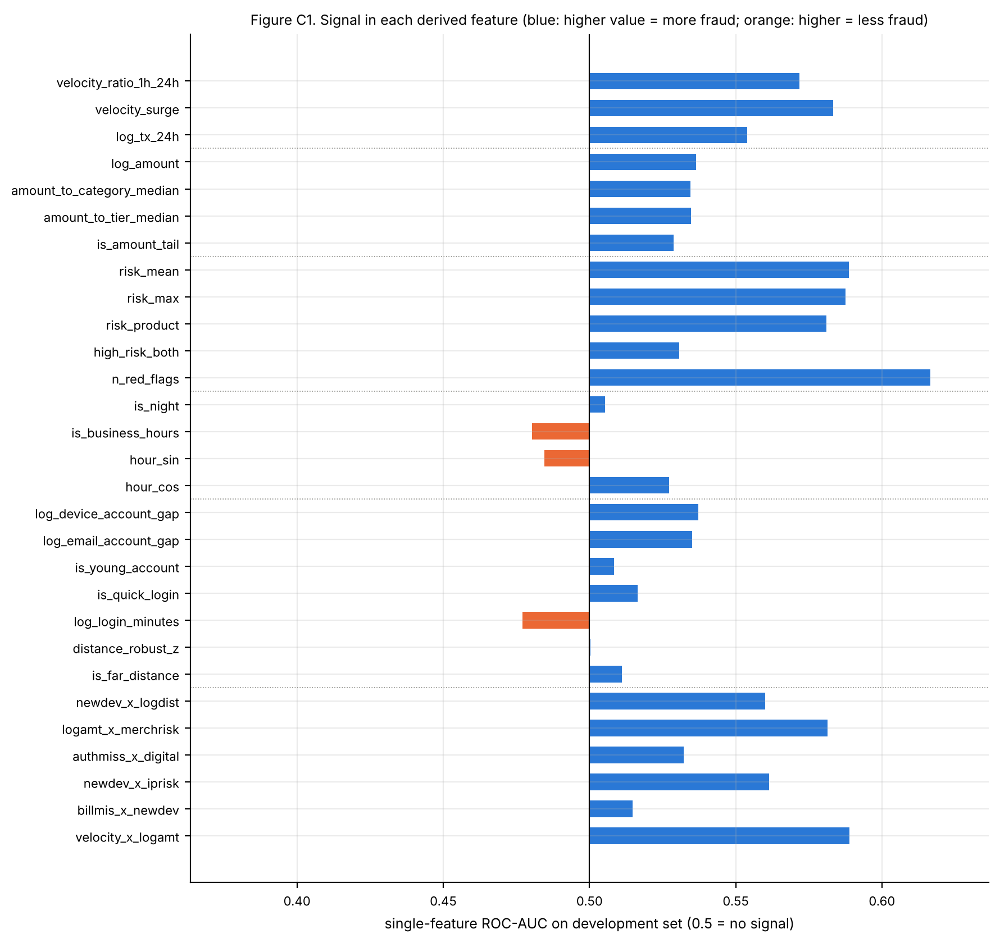

Derived-feature pairs (or derived vs raw) with |Spearman| >= 0.90: 18


,feature_a,feature_b,spearman
6,log_amount,transaction_amount,1.000
3,log_tx_24h,transactions_last_24h,1.000
12,distance_robust_z,distance_from_usual_location_km,1.000
11,log_login_minutes,login_to_transaction_minutes,1.000
8,amount_to_category_median,transaction_amount,0.999
4,log_amount,amount_to_category_median,0.999
9,amount_to_tier_median,transaction_amount,0.997
5,log_amount,amount_to_tier_median,0.997
7,amount_to_category_median,amount_to_tier_median,0.996
14,newdev_x_logdist,new_device,0.995


In [38]:
aucs = {}
for f in ALL_DERIVED:
    x = F[f].fillna(F[f].median()); aucs[f] = roc_auc_score(y_dev, x)
auc_df = pd.DataFrame({"feature": ALL_DERIVED, "group": cat.group.values, "single_feature_AUC": [aucs[f] for f in ALL_DERIVED]})
auc_df["strength"] = (auc_df.single_feature_AUC - .5).abs()
display(auc_df.sort_values("strength", ascending=False).head(12).round(3).drop(columns="strength"))

fig, ax = plt.subplots(figsize=(9, 8.5))
d = auc_df.iloc[::-1].reset_index(drop=True)
ax.barh(d.feature, d.single_feature_AUC - .5, left=.5, color=[BLUE if a >= .5 else ORANGE for a in d.single_feature_AUC], height=.62)
ax.axvline(.5, color=INK, lw=.8)
prev = None
for i, g in enumerate(d.group):
    if g != prev and prev is not None: ax.axhline(i - .5, color=GREY, lw=.6, ls=":")
    prev = g
lim = max(.60, float(auc_df.single_feature_AUC.max()) + .02); ax.set_xlim(1 - lim, lim); ax.set_xlabel("single-feature ROC-AUC on development set (0.5 = no signal)")
ax.set_title("Figure C1. Signal in each derived feature (blue: higher value = more fraud; orange: higher = less fraud)", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "C01_derived_feature_signal.png", dpi=130, bbox_inches="tight"); plt.show()

# redundancy among derived features and with raw numerics
Z = pd.concat([F, X_dev[NUM_BASE]], axis=1).corr(method="spearman")
pairs = [(a, b, Z.loc[a, b]) for i, a in enumerate(Z.columns) for b in Z.columns[i + 1:] if abs(Z.loc[a, b]) >= .90 and not (a in NUM_BASE and b in NUM_BASE)]
print(f"Derived-feature pairs (or derived vs raw) with |Spearman| >= 0.90: {len(pairs)}")
display(pd.DataFrame(pairs, columns=["feature_a", "feature_b", "spearman"]).sort_values("spearman", key=abs, ascending=False).round(3).head(20))

### C4. With versus without engineered features
**Design.** Three model families with fixed, untuned settings (Logistic Regression, Histogram Gradient Boosting, Random Forest), each run on two feature sets:
- **base:** the 16 raw numeric/flag fields (with missing indicators) + 7 one-hot categoricals;
- **engineered:** base + all 29 derived features.

Same 15 folds for every run, so each fold gives a paired difference. The **primary metric is PR-AUC** (average precision) because fraud is only about 12% of rows; a model with no skill scores about 0.12. Secondary: ROC-AUC, recall in the top 10% of scores, Brier score and log loss (lower is better for the last two).

In [39]:
splits = make_splits(y_dev, n_splits=5, n_repeats=3, seed=SEED)                # 15 identical folds for every configuration
N_TRAIN, N_TEST = len(splits[0][0]), len(splits[0][1])
MODELS = default_models(); ALL_G = tuple(FEATURE_GROUPS)
METRICS = ["pr_auc", "roc_auc", "recall_at_10pct", "brier", "log_loss"]; HIGHER = {"pr_auc", "roc_auc", "recall_at_10pct"}
print(f"{len(splits)} folds | train {N_TRAIN} / test {N_TEST} rows per fold | no-skill PR-AUC = base rate = {y_dev.mean():.3f}")

res = []
for mname, (m, sc) in MODELS.items():
    for cname, g in {"base": (), "engineered": ALL_G}.items():
        r = run_cv(build_pipeline(m, g, sc), X_dev, y_dev, splits, f"{mname}|{cname}"); r["model"], r["config"] = mname, cname; res.append(r)
res = pd.concat(res, ignore_index=True)
res.to_csv(OUT / "C_cv_fold_results_base_vs_engineered.csv", index=False)

summ = res.groupby(["model", "config"])[METRICS].agg(["mean", "std"])
summ.columns = [f"{a}_{b}" for a, b in summ.columns]
display(summ.round(4))

15 folds | train 1920 / test 480 rows per fold | no-skill PR-AUC = base rate = 0.121


pr_auc_mean  pr_auc_std  roc_auc_mean  roc_auc_std  recall_at_10pct_mean  recall_at_10pct_std  brier_mean  brier_std  log_loss_mean  log_loss_std
model config                                                                                                                                                       
HGB   base             0.2020      0.0243        0.6407       0.0407                0.1993               0.0380      0.1053     0.0031         0.3625        0.0130
      engineered       0.2426      0.0410        0.6615       0.0325                0.2348               0.0383      0.1029     0.0033         0.3550        0.0119
LR    base             0.2518      0.0425        0.6688       0.0405                0.2245               0.0457      0.1035     0.0057         0.3625        0.0285
      engineered       0.2473      0.0425        0.6682       0.0451                0.2406               0.0444      0.1049     0.0073         0.3694        0.0410
RF    base             0.2259      0.0351        0.6553       0.0449                0.2200               0.0539      0.1029     0.0022         0.3534        0.0089
      engineered       0.2520      0.0414        0.6681       0.0444                0.2522               0.0590      0.1019     0.0031         0.3502        0.0128

In [40]:
rows = []
for mname in MODELS:
    b = res[(res.model == mname) & (res.config == "base")].sort_values("fold"); e = res[(res.model == mname) & (res.config == "engineered")].sort_values("fold")
    for met in METRICS:
        dlt = e[met].to_numpy() - b[met].to_numpy()
        better = (dlt > 0) if met in HIGHER else (dlt < 0)
        rows.append(dict(model=mname, metric=met, base=b[met].mean(), engineered=e[met].mean(), **corrected_ttest(dlt, N_TRAIN, N_TEST), folds_engineered_better=f"{int(better.sum())}/{len(dlt)}"))
paired = pd.DataFrame(rows)
paired["engineered_is"] = np.where(paired.p_value < .05, np.where(((paired.mean_diff > 0) == paired.metric.isin(HIGHER)), "significantly BETTER", "significantly WORSE"), "not distinguishable")
paired.to_csv(OUT / "C_paired_comparison_base_vs_engineered.csv", index=False)
display(paired.round(4))

,model,metric,base,engineered,mean_diff,se,ci_low,ci_high,p_value,folds_engineered_better,engineered_is
0,LR,pr_auc,0.2518,0.2473,-0.0046,0.0109,-0.0280,0.0188,0.6814,6/15,not distinguishable
1,LR,roc_auc,0.6688,0.6682,-0.0005,0.0103,-0.0227,0.0217,0.9603,7/15,not distinguishable
2,LR,recall_at_10pct,0.2245,0.2406,0.0161,0.0209,-0.0286,0.0608,0.4531,7/15,not distinguishable
3,LR,brier,0.1035,0.1049,0.0015,0.0012,-0.0012,0.0041,0.2558,3/15,not distinguishable
4,LR,log_loss,0.3625,0.3694,0.0069,0.0086,-0.0114,0.0253,0.4319,6/15,not distinguishable
5,HGB,pr_auc,0.2020,0.2426,0.0406,0.0160,0.0062,0.0750,0.0241,14/15,significantly BETTER
6,HGB,roc_auc,0.6407,0.6615,0.0208,0.0172,-0.0161,0.0577,0.2464,13/15,not distinguishable
7,HGB,recall_at_10pct,0.1993,0.2348,0.0354,0.0254,-0.0190,0.0899,0.1847,10/15,not distinguishable
8,HGB,brier,0.1053,0.1029,-0.0024,0.0013,-0.0052,0.0004,0.0879,13/15,not distinguishable
9,HGB,log_loss,0.3625,0.3550,-0.0074,0.0053,-0.0189,0.0040,0.1854,13/15,not distinguishable


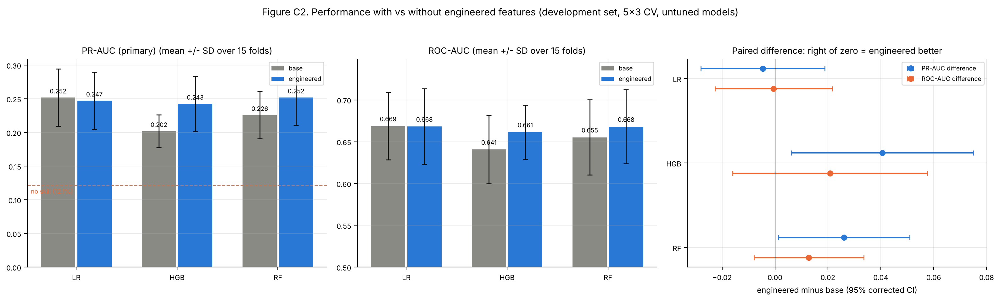

In [41]:
colors = {"base": GREY, "engineered": BLUE}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for a, met, t in [(ax[0], "pr_auc", "PR-AUC (primary)"), (ax[1], "roc_auc", "ROC-AUC")]:
    for j, cn in enumerate(["base", "engineered"]):
        g = res[res.config == cn].groupby("model")[met].agg(["mean", "std"]).reindex(list(MODELS))
        x = np.arange(len(g)) + (j - .5) * .36
        a.bar(x, g["mean"], .34, color=colors[cn], label=cn, yerr=g["std"], ecolor=INK, capsize=3, error_kw={"elinewidth": 1})
        for xi, v in zip(x, g["mean"]): a.text(xi, v + .004, f"{v:.3f}", ha="center", va="bottom", fontsize=7)
    if met == "pr_auc": a.axhline(y_dev.mean(), ls="--", color=ORANGE, lw=1); a.text(-.45, y_dev.mean() - .012, "no skill (12.1%)", color=ORANGE, fontsize=7, ha="left")
    a.set_xticks(range(len(MODELS))); a.set_xticklabels(list(MODELS)); a.set_title(t + " (mean +/- SD over 15 folds)"); a.legend(fontsize=7); a.set_ylim(bottom=.0 if met == "pr_auc" else .5)
pp = paired[paired.metric.isin(["pr_auc", "roc_auc"])]
for k, (met, off, col) in enumerate([("pr_auc", -.12, BLUE), ("roc_auc", .12, ORANGE)]):
    q = pp[pp.metric == met].set_index("model").reindex(list(MODELS)); y = np.arange(len(q)) + off
    ax[2].errorbar(q.mean_diff, y, xerr=[q.mean_diff - q.ci_low, q.ci_high - q.mean_diff], fmt="o", color=col, ms=6, capsize=3, label=("PR-AUC" if met == "pr_auc" else "ROC-AUC") + " difference")
ax[2].axvline(0, color=INK, lw=.8); ax[2].set_yticks(range(len(MODELS))); ax[2].set_yticklabels(list(MODELS)); ax[2].invert_yaxis()
ax[2].set_xlabel("engineered minus base (95% corrected CI)"); ax[2].set_title("Paired difference: right of zero = engineered better"); ax[2].legend(fontsize=7)
fig.suptitle("Figure C2. Performance with vs without engineered features (development set, 5x3 CV, untuned models)", y=1.03, fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "C02_base_vs_engineered.png", dpi=130, bbox_inches="tight"); plt.show()

### C5. Which feature groups earn their place? (ablation)
**Adoption rule, written before the results were computed.** A group is carried forward to Part D only if **both** hold, averaged over the three model families:
- *add-one:* base + that group beats base on PR-AUC (mean difference > 0), **and**
- *drop-one:* all-features minus that group is worse than all-features on PR-AUC (mean difference < 0).

Requiring both guards against a group that helps only because of a lucky pairing. All 29 features remain in the saved processed dataset and the catalogue either way. If no group passes, Part D uses the base features.
**Caveat:** this decision is made on the same development rows as the comparison, so it carries mild optimism. Part D tunes with nested/fresh folds and the hold-out is only used once, at the end.

In [42]:
abl = []
for mname, (m, sc) in MODELS.items():
    for g in FEATURE_GROUPS:
        for kind, groups in [("add_one", (g,)), ("drop_one", tuple(x for x in ALL_G if x != g))]:
            r = run_cv(build_pipeline(m, groups, sc), X_dev, y_dev, splits, "abl"); r["model"], r["group"], r["kind"] = mname, g, kind; abl.append(r)
abl = pd.concat(abl, ignore_index=True)
abl.to_csv(OUT / "C_cv_fold_results_ablation.csv", index=False)

ref = {("base"): res[res.config == "base"].set_index(["model", "fold"]), ("all"): res[res.config == "engineered"].set_index(["model", "fold"])}
rows = []
for (mname, g, kind), grp in abl.groupby(["model", "group", "kind"]):
    r0 = ref["base" if kind == "add_one" else "all"].loc[mname].sort_index()
    for met in ["pr_auc", "roc_auc"]:
        dlt = grp.sort_values("fold")[met].to_numpy() - r0[met].to_numpy()
        rows.append(dict(model=mname, group=g, kind=kind, metric=met, mean_diff=dlt.mean(), **{k: v for k, v in corrected_ttest(dlt, N_TRAIN, N_TEST).items() if k in ("ci_low", "ci_high", "p_value")}))
abl_sum = pd.DataFrame(rows); abl_sum.to_csv(OUT / "C_ablation_summary.csv", index=False)
piv = abl_sum[abl_sum.metric == "pr_auc"].pivot_table(index="group", columns=["kind", "model"], values="mean_diff").reindex(list(FEATURE_GROUPS))
print("Mean change in PR-AUC.  add_one: base + group minus base.   drop_one: all minus group, minus all (negative = removing the group hurts).")
display(piv.round(4))

gs = abl_sum[abl_sum.metric == "pr_auc"].groupby(["group", "kind"]).mean_diff.mean().unstack().reindex(list(FEATURE_GROUPS))
gs["models_where_add_one_helps"] = abl_sum[(abl_sum.metric == "pr_auc") & (abl_sum.kind == "add_one") & (abl_sum.mean_diff > 0)].groupby("group").size().reindex(gs.index).fillna(0).astype(int)
gs["models_where_drop_one_hurts"] = abl_sum[(abl_sum.metric == "pr_auc") & (abl_sum.kind == "drop_one") & (abl_sum.mean_diff < 0)].groupby("group").size().reindex(gs.index).fillna(0).astype(int)
gs["adopt"] = (gs.add_one > 0) & (gs.drop_one < 0)
RECOMMENDED = [g for g in FEATURE_GROUPS if gs.loc[g, "adopt"]]
display(gs.round(4))
print("RECOMMENDED GROUPS FOR PART D:", RECOMMENDED if RECOMMENDED else "none (use base features)")
json.dump({"recommended_groups": RECOMMENDED, "rule": "mean add-one dPR-AUC > 0 AND mean drop-one dPR-AUC < 0, averaged over LR/HGB/RF"}, open(OUT / "C_recommended_feature_set.json", "w"), indent=2)

Mean change in PR-AUC.  add_one: base + group minus base.   drop_one: all minus group, minus all (negative = removing the group hurts).


kind        add_one                 drop_one                
model           HGB      LR      RF      HGB      LR      RF
group                                                       
velocity     0.0110 -0.0033  0.0078  -0.0019  0.0010 -0.0048
amount       0.0045  0.0028 -0.0135   0.0029 -0.0003  0.0078
risk         0.0195  0.0031  0.0313  -0.0180 -0.0015 -0.0324
time         0.0049  0.0006 -0.0002  -0.0021  0.0011 -0.0045
behavior     0.0045 -0.0023 -0.0047  -0.0028  0.0025  0.0010
interaction  0.0121 -0.0016  0.0111  -0.0148  0.0050 -0.0068

kind,add_one,drop_one,models_where_add_one_helps,models_where_drop_one_hurts,adopt
group,,,,,
velocity,0.0052,-0.0019,2,2,True
amount,-0.0021,0.0035,2,1,False
risk,0.0180,-0.0173,3,3,True
time,0.0018,-0.0018,2,2,True
behavior,-0.0009,0.0002,1,1,False
interaction,0.0072,-0.0055,2,2,True


RECOMMENDED GROUPS FOR PART D: ['velocity', 'risk', 'time', 'interaction']


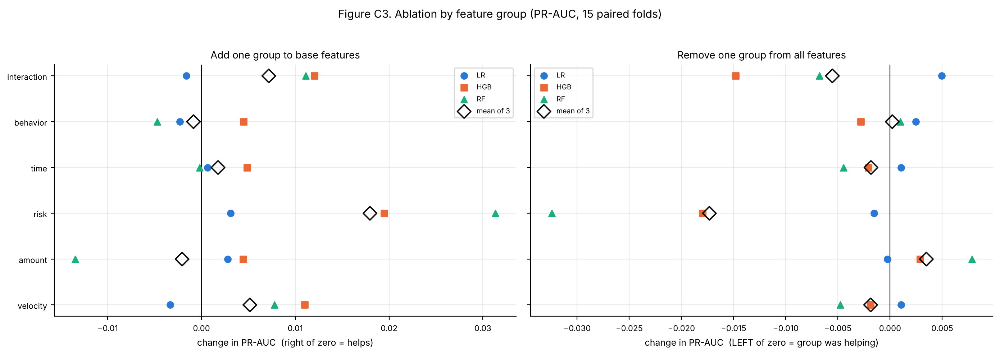

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
MC = {"LR": (BLUE, "o"), "HGB": (ORANGE, "s"), "RF": ("#1baf7a", "^")}
for a, kind, t in [(ax[0], "add_one", "Add one group to base features"), (ax[1], "drop_one", "Remove one group from all features")]:
    for mname, (col, mk) in MC.items():
        q = abl_sum[(abl_sum.metric == "pr_auc") & (abl_sum.kind == kind) & (abl_sum.model == mname)].set_index("group").reindex(list(FEATURE_GROUPS))
        a.scatter(q.mean_diff, np.arange(len(q)), color=col, marker=mk, s=42, label=mname, zorder=3)
    avg = gs[kind]; a.scatter(avg, np.arange(len(avg)), marker="D", s=90, facecolors="none", edgecolors=INK, linewidths=1.4, label="mean of 3", zorder=4)
    a.axvline(0, color=INK, lw=.8); a.set_yticks(range(len(FEATURE_GROUPS))); a.set_yticklabels(list(FEATURE_GROUPS)); a.invert_yaxis()
    a.set_xlabel("change in PR-AUC" + ("  (right of zero = helps)" if kind == "add_one" else "  (LEFT of zero = group was helping)")); a.set_title(t); a.legend(fontsize=7)
fig.suptitle("Figure C3. Ablation by feature group (PR-AUC, 15 paired folds)", y=1.02, fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "C03_group_ablation.png", dpi=130, bbox_inches="tight"); plt.show()

In [44]:
# Sensitivity: is the 'risk' group gain just the hand-designed n_red_flags (whose five flags were picked after viewing development data in B13)?
from fraud_features import SENSITIVITY_GROUPS
srows = []
for mname, (m, sc) in MODELS.items():
    b = ref["base"].loc[mname].sort_index()
    for g, label in [("risk", "risk group (5 features)"), ("risk_without_red_flags", "risk group WITHOUT n_red_flags (4)"), ("red_flags_only", "n_red_flags alone (1)")]:
        r = run_cv(build_pipeline(m, (g,), sc), X_dev, y_dev, splits, "s").sort_values("fold")
        dlt = r.pr_auc.to_numpy() - b.pr_auc.to_numpy()
        srows.append(dict(model=mname, added_to_base=label, mean_dPR_AUC=dlt.mean(), **{k: v for k, v in corrected_ttest(dlt, N_TRAIN, N_TEST).items() if k in ("ci_low", "ci_high", "p_value")}, folds_better=f"{int((dlt > 0).sum())}/15"))
sens = pd.DataFrame(srows); sens.to_csv(OUT / "C_sensitivity_risk_group.csv", index=False)
display(sens.round(4))

,model,added_to_base,mean_dPR_AUC,ci_low,ci_high,p_value,folds_better
0,LR,risk group (5 features),0.0031,-0.0106,0.0168,0.6350,10/15
1,LR,risk group WITHOUT n_red_flags (4),-0.0036,-0.0120,0.0049,0.3837,6/15
2,LR,n_red_flags alone (1),0.0051,-0.0077,0.0180,0.4059,10/15
3,HGB,risk group (5 features),0.0195,-0.0057,0.0446,0.1190,12/15
4,HGB,risk group WITHOUT n_red_flags (4),0.0075,-0.0103,0.0253,0.3825,9/15
5,HGB,n_red_flags alone (1),0.0189,-0.0053,0.0430,0.1167,13/15
6,RF,risk group (5 features),0.0313,-0.0126,0.0752,0.1481,11/15
7,RF,risk group WITHOUT n_red_flags (4),0.0040,-0.0309,0.0390,0.8079,9/15
8,RF,n_red_flags alone (1),0.0254,-0.0059,0.0568,0.1040,13/15


In [45]:
# Fresh-fold confirmation: different fold assignment (seed 2026), base vs recommended vs all. Same data, so this only removes fold-split luck.
splits2 = make_splits(y_dev, 5, 3, seed=2026)
conf_cfg = {"base": (), "recommended": tuple(RECOMMENDED), "all_29": ALL_G} if RECOMMENDED else {"base": (), "all_29": ALL_G}
conf = []
for mname, (m, sc) in MODELS.items():
    for cname, g in conf_cfg.items():
        r = run_cv(build_pipeline(m, g, sc), X_dev, y_dev, splits2, "conf"); r["model"], r["config"] = mname, cname; conf.append(r)
conf = pd.concat(conf, ignore_index=True); conf.to_csv(OUT / "C_cv_fold_results_confirmation_seed2026.csv", index=False)
cs = conf.groupby(["model", "config"])[["pr_auc", "roc_auc", "recall_at_10pct", "brier"]].mean().unstack("config")
display(cs.round(4))

pr_auc                     roc_auc                     recall_at_10pct                       brier                    
config  all_29    base recommended  all_29    base recommended          all_29    base recommended  all_29    base recommended
model                                                                                                                         
HGB     0.2339  0.2131      0.2268  0.6515  0.6448      0.6457          0.2326  0.1972      0.2337  0.1035  0.1047      0.1041
LR      0.2437  0.2477      0.2409  0.6681  0.6710      0.6623          0.2290  0.2269      0.2188  0.1040  0.1027      0.1040
RF      0.2467  0.2196      0.2521  0.6652  0.6561      0.6690          0.2486  0.2063      0.2475  0.1018  0.1029      0.1016

### C6. Findings (development set, untuned models; every number comes from the tables above)

**The features themselves**
- 29 derived features in 6 groups (velocity 3, amount 4, risk 5, time 4, behavioural deviation 7, interaction 6). **None is unavailable at prediction time** provided its base inputs are. 13 of 29 inherit a deployment condition from a base field flagged in A9 (velocity windows, prior chargebacks, vendor risk scores, authentication timing, tier timing). 7 need stored training constants, saved in `outputs/C_learned_constants.json`.
- Safety tests passed: no infinite values, identical features with permuted labels, and a shuffle test proving every feature depends on exactly the columns declared in the catalogue.
- Several features are near-duplicates of their inputs (Spearman >= 0.99): the amount-to-category and amount-to-tier ratios track raw amount almost perfectly, and `newdev_x_logdist` / `newdev_x_iprisk` track `new_device`, because `new_device` is zero for 83% of rows. They add little new information, which matches the ablation below.
- Strongest single features: `n_red_flags` AUC 0.617, `velocity_x_logamt` 0.589, `risk_mean` 0.589, `risk_max` 0.588, `velocity_surge` 0.583. The best raw feature in A9 was 0.58, so the derived features add only a little on their own. `n_red_flags` is the one built from patterns seen in development data, so its 0.617 is optimistic.

**With versus without engineered features (PR-AUC, 15 paired folds, no-skill = 0.121)**

| Model | Base | Engineered | Difference (95% CI) | p (corrected) | Folds better |
|---|---|---|---|---|---|
| Logistic Regression | 0.252 | 0.247 | -0.005 (-0.028 to +0.019) | 0.68 | 6/15 |
| Hist. Gradient Boosting | 0.202 | 0.243 | +0.041 (+0.006 to +0.075) | 0.024 | 14/15 |
| Random Forest | 0.226 | 0.252 | +0.026 (+0.001 to +0.051) | 0.041 | 14/15 |

- ROC-AUC, recall in the top 10%, Brier score and log loss show **no significant difference for any model** (all p >= 0.088).
- **Read this as suggestive, not proven.** Three models were tested on the primary metric, so the Bonferroni line is 0.017 and neither tree result passes it. The direction is consistent (14 of 15 folds for both trees, and the same pattern on a fresh fold assignment: HGB 0.213 to 0.234, RF 0.220 to 0.247, LR 0.248 to 0.244).
- The engineered features lift the two tree models up to the level of plain Logistic Regression on raw features (0.252), **not above it**. The untuned trees were simply weak on raw features.
- **Absolute signal is modest:** PR-AUC about 0.25 against 0.12 for a model with no skill (roughly 2x), and ROC-AUC about 0.67. Fold-to-fold SD of PR-AUC is 0.02 to 0.04, so differences smaller than about 0.03 cannot be told apart from noise. This matters for the cost and threshold work in Parts E and I.

**Which groups earn their place (pre-set rule: mean add-one gain > 0 and mean drop-one change < 0)**

| Group | Mean add-one change | Mean drop-one change | Passes rule |
|---|---|---|---|
| risk | +0.0180 | -0.0173 | yes |
| interaction | +0.0072 | -0.0055 | yes |
| velocity | +0.0052 | -0.0019 | yes |
| time | +0.0018 | -0.0018 | yes (marginal) |
| behavioural deviation | -0.0008 | +0.0002 | no |
| amount | -0.0021 | +0.0035 | no |

- The rule, applied mechanically, selects **velocity, risk, time and interaction**. I did not change the rule after seeing results.
- **Only `risk` has real support** (removing it costs 0.018 for HGB, p = 0.054, and 0.032 for RF, p = 0.021). Outside `risk`, no individual test has p < 0.2, so velocity, interaction and especially time pass by margins no larger than noise. Time passing is close to a coin flip, consistent with B2 finding no time effect.
- **Sensitivity check on `risk`:** its gain comes almost entirely from `n_red_flags`. Adding `n_red_flags` alone gives +0.025 (RF) and +0.019 (HGB); the other four risk features together give +0.004 and +0.008. Because the five flags in `n_red_flags` were chosen after viewing the development data (B13), part of that gain is probably selection optimism. On its own it is not significant (p about 0.10 to 0.12).
- Amount normalisation and behavioural deviation did not help (dropping the amount group slightly improves PR-AUC on average).

**Decision for Part D:** treat the feature set as a tuned choice inside nested cross-validation, comparing **base**, **the rule's four-group set** and **all 29**. `n_red_flags` will also be tested with and without so its effect is measured on folds that did not influence its design.

### C7. Save the processed dataset

In [46]:
# Constants are fitted on DEVELOPMENT rows only, then applied to every row (including hold-out) without refitting.
# Missing inputs stay missing in derived columns; median imputation is done inside the model pipeline, fitted on training folds.
X_all = df.drop(columns=[ID, TARGET])
proc = fe_all.transform(X_all)
proc.insert(0, ID, df[ID].values)
proc["split"] = split.values
proc[TARGET] = df[TARGET].values
proc.to_csv("02_processed_dataset.csv", index=False)
print("02_processed_dataset.csv:", proc.shape, "| raw columns:", len(NUM_BASE) + len(CAT_BASE), "| derived:", len(ALL_DERIVED))
print("rows by split:", proc.split.value_counts().to_dict())
assert proc.shape[0] == 3000 and not proc[ID].duplicated().any()
assert np.isfinite(proc[ALL_DERIVED].to_numpy(float)[~np.isnan(proc[ALL_DERIVED].to_numpy(float))]).all()
print("Part C figures:", sorted(p.name for p in FIG.glob("C*.png")))

02_processed_dataset.csv: (3000, 55) | raw columns: 23 | derived: 29
rows by split: {'development': 2400, 'holdout_test': 600}
Part C figures: ['C01_derived_feature_signal.png', 'C02_base_vs_engineered.png', 'C03_group_ablation.png']


---
## Part D. Baseline & Advanced Models

**Goal:** a transparent Logistic Regression baseline, at least two nonlinear models, proper preprocessing pipelines, reproducible cross-validation, and documented hyper-parameter optimisation.

| Task D requirement | Where |
|---|---|
| Transparent Logistic Regression baseline | D2 (fixed baseline, odds ratios with bootstrap intervals) |
| At least two nonlinear models | Random Forest and Histogram Gradient Boosting (D1, D3) |
| Preprocessing pipelines + reproducible CV | D1: one pipeline per model, 5-fold x 2-repeat nested CV, fixed seeds |
| Hyper-parameter optimisation | D1, D4: `RandomizedSearchCV` inside every outer fold; search spaces documented |

**Design decisions (fixed before any result was looked at)**
1. **Nested cross-validation.** The outer loop (5 folds x 2 repeats = 10 outer folds) measures performance. Inside each outer-training set, a `RandomizedSearchCV` with 5 inner folds chooses the hyper-parameters. The outer test fold never influences any choice, so the reported score is not inflated by tuning.
2. **The feature set is itself tuned inside the search**, as promised in Part C: `base`, the Part C `recommended` four-group set, `recommended_no_red_flags` (the same set without the hand-designed `n_red_flags`) and `all` 29. That tests `n_red_flags` on folds that did not shape its design.
3. **Tuning metric = PR-AUC** (average precision), because fraud is about 12% of rows. Log loss, Brier score, ROC-AUC and recall are reported alongside.
4. **No class weighting or resampling here.** Imbalance handling is compared properly in Part G; keeping it out of D means the models return unweighted probabilities, which suits calibration (Part F) and cost thresholds (Part E).
5. **All models go forward.** Part D ranks models on ranking quality only. The question "does the best-ROC-AUC model also give the best business outcome?" is answered in Part E, so the production candidate is chosen there on expected cost, with a one-standard-error preference for the simpler model on ties.
6. **Only the development set (2,400 rows) is read.** The hold-out set is not loaded.

Heavy computation lives in `fraud_models.py` and `run_nested_cv.py` (about 15 minutes on 2 cores) and is **cached**: the notebook loads the cache when the code hash matches and recomputes otherwise. To force a re-run: `python run_nested_cv.py --force`.

In [47]:
import fraud_models as fm
import joblib
from sklearn.linear_model import LogisticRegression
from fraud_features import FEATURE_SET_COLUMNS, build_search_pipeline

XD, yD, idD = fm.load_dev()                         # development rows only, original ID order
assert len(XD) == 2400 and set(idD) == set(dev[ID]) and int(yD.sum()) == 291
print(f"development rows {len(XD)} | frauds {int(yD.sum())} ({yD.mean():.3%}) | seed {fm.SEED}")
print(f"outer CV: {fm.N_OUTER_SPLITS} folds x {fm.N_OUTER_REPEATS} repeats = {fm.N_OUTER_SPLITS * fm.N_OUTER_REPEATS} outer folds | inner CV: {fm.INNER_FOLDS} folds | tuning metric: average precision")
print("\nFeature sets that the search may choose from (derived-column counts):", {k: len(v) for k, v in FEATURE_SET_COLUMNS.items()})

development rows 2400 | frauds 291 (12.125%) | seed 42
outer CV: 5 folds x 2 repeats = 10 outer folds | inner CV: 5 folds | tuning metric: average precision

Feature sets that the search may choose from (derived-column counts): {'base': 0, 'recommended': 18, 'recommended_no_red_flags': 17, 'all': 29}


### D1. Pipelines and search spaces

In [48]:
print("Every model is one scikit-learn Pipeline, so imputers, scalers, encoders and the feature engineering are re-fitted inside every fold:")
print("  features (29 derived columns, constants learned on the training rows)")
print("   -> select (keeps raw columns + the chosen feature set)")
print("   -> prep (numeric: median impute + missing-indicator [+ standardise for linear models]; derived: median impute [+ standardise]; categoricals: one-hot, unknown levels ignored)")
print("   -> model\n")
specs = fm.model_specs()
space_tbl = pd.DataFrame([dict(model=n, role=s["kind"], tuned_draws=s["n_iter"], search_space=fm.SPACE_DOC.get(n, "fixed: C = 1.0 (L2), base features only" if n == "LR_baseline" else "prior-probability reference (no skill)")) for n, s in specs.items()])
pd.set_option("display.max_colwidth", 260); display(space_tbl)
print("Seeds: outer folds and models = 42; inner folds and random search = 42 + outer-fold id; permutation importance = 42 + outer-fold id.")

Every model is one scikit-learn Pipeline, so imputers, scalers, encoders and the feature engineering are re-fitted inside every fold:
  features (29 derived columns, constants learned on the training rows)
   -> select (keeps raw columns + the chosen feature set)
   -> prep (numeric: median impute + missing-indicator [+ standardise for linear models]; derived: median impute [+ standardise]; categoricals: one-hot, unknown levels ignored)
   -> model



,model,role,tuned_draws,search_space
0,Dummy,reference,0,prior-probability reference (no skill)
1,LR_baseline,baseline,0,"fixed: C = 1.0 (L2), base features only"
2,LR_tuned,tuned,20,prior-probability reference (no skill)
3,RF,tuned,16,"300 trees; max_depth in {3,5,8,12,None}; min_samples_leaf ~ randint(2,25); max_features in {sqrt,0.2,0.4,0.6}; max_samples in {None,0.6,0.8}; feature_set in 4 options; 16 draws"
4,HGB,tuned,24,"learning_rate ~ loguniform(0.01,0.2); max_iter ~ randint(80,400); max_depth in {2,3,4,6,None}; max_leaf_nodes ~ randint(4,32); min_samples_leaf ~ randint(10,80); l2_regularization ~ loguniform(0.01,20); max_features in {0.4,0.7,1.0}; feature_set in 4 optio..."


Seeds: outer folds and models = 42; inner folds and random search = 42 + outer-fold id; permutation importance = 42 + outer-fold id.


### D2. Transparent Logistic Regression baseline
The baseline is deliberately simple and fixed: L2-penalised Logistic Regression, `C = 1`, **raw features only** (no engineered features), numeric inputs standardised. Each odds ratio reads as *"how much the odds of fraud are multiplied for a one-standard-deviation increase"* (for yes/no flags, one SD is about 0.4 to 0.5, so read them as approximate effects). Intervals come from 200 bootstrap refits of the whole pipeline. Categorical levels are one-hot encoded without dropping a reference level, so a level's odds ratio is relative to the penalised average of its own variable, not to a named baseline level. This model is fitted on the development set for **explanation only**; its performance is measured by cross-validation in D3.

In [49]:
def lr_baseline():
    return build_search_pipeline(LogisticRegression(C=1.0, max_iter=3000, random_state=fm.SEED), scale=True).set_params(select__feature_set="base")

base_fit = lr_baseline().fit(XD, yD)
names = base_fit.named_steps["prep"].get_feature_names_out()
coef = pd.Series(base_fit.named_steps["model"].coef_[0], index=names)

def boot_once(b):
    rng = np.random.default_rng(1000 + b); idx = rng.choice(len(XD), len(XD), replace=True)
    m = lr_baseline().fit(XD.iloc[idx], yD.iloc[idx])
    return pd.Series(m.named_steps["model"].coef_[0], index=m.named_steps["prep"].get_feature_names_out()).reindex(names).fillna(0.0)

from joblib import Parallel, delayed
B = pd.concat(Parallel(n_jobs=2)(delayed(boot_once)(b) for b in range(200)), axis=1)
or_tbl = pd.DataFrame({"coefficient": coef, "odds_ratio": np.exp(coef), "or_ci_low": np.exp(B.quantile(.025, axis=1)), "or_ci_high": np.exp(B.quantile(.975, axis=1))})
or_tbl["ci_excludes_1"] = (or_tbl.or_ci_low > 1) | (or_tbl.or_ci_high < 1)
or_tbl["abs_log_or"] = coef.abs(); or_tbl = or_tbl.sort_values("abs_log_or", ascending=False)
or_tbl.drop(columns="abs_log_or").to_csv(OUT / "D_lr_baseline_odds_ratios.csv")
print(f"Intercept {base_fit.named_steps['model'].intercept_[0]:.3f} | {len(coef)} coefficients | {int(or_tbl.ci_excludes_1.sum())} have a bootstrap interval that excludes 1")
display(or_tbl.drop(columns="abs_log_or").head(15).round(3))

Intercept -2.181 | 56 coefficients | 17 have a bootstrap interval that excludes 1


,coefficient,odds_ratio,or_ci_low,or_ci_high,ci_excludes_1
merchant_category_Jewelry,0.633,1.884,1.213,3.109,True
authentication_level_Missing,0.501,1.651,1.312,2.084,True
merchant_category_Fuel,-0.467,0.627,0.399,0.925,True
merchant_category_Digital Services,-0.335,0.715,0.440,1.043,False
merchant_category_Fashion,0.327,1.387,1.032,1.867,True
transactions_last_1h,0.308,1.361,1.206,1.555,True
new_device,0.299,1.348,1.222,1.541,True
merchant_category_Grocery,-0.294,0.745,0.514,1.015,False
channel_E-commerce,0.290,1.336,1.110,1.681,True
merchant_risk_score,0.286,1.332,1.198,1.554,True


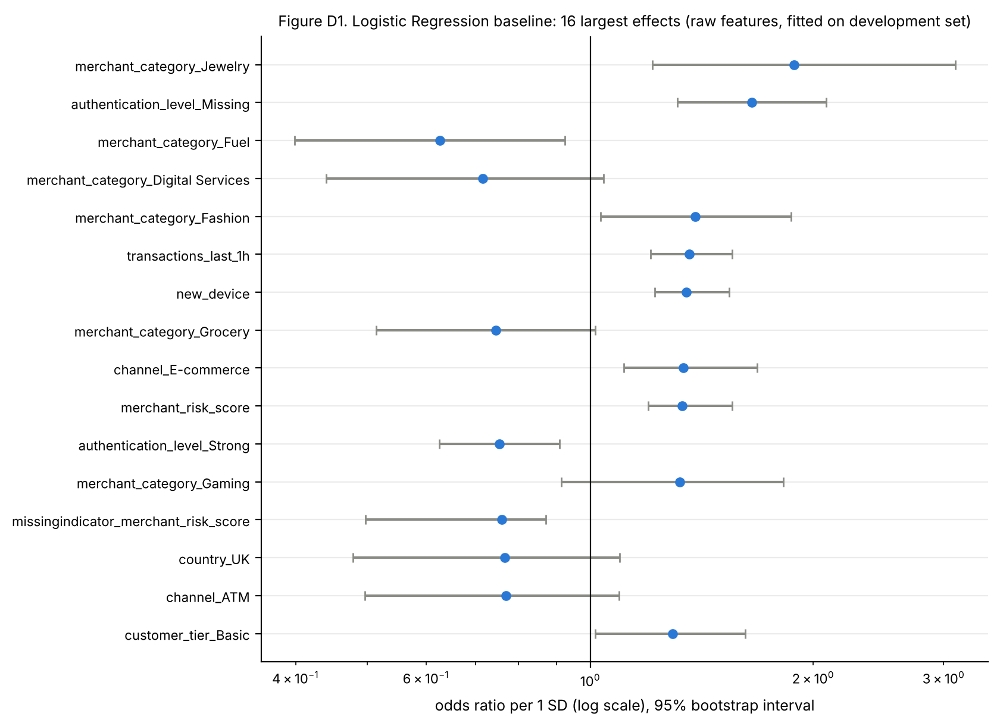

In [50]:
top = or_tbl.head(16).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 6.2))
yy = np.arange(len(top))
ax.errorbar(top.odds_ratio, yy, xerr=[top.odds_ratio - top.or_ci_low, top.or_ci_high - top.odds_ratio], fmt="o", color=BLUE, ecolor=GREY, capsize=3, ms=5)
ax.axvline(1, color=INK, lw=.8); ax.set_xscale("log"); ax.set_yticks(yy); ax.set_yticklabels(top.index, fontsize=8)
ax.set_xlabel("odds ratio per 1 SD (log scale), 95% bootstrap interval"); ax.set_title("Figure D1. Logistic Regression baseline: 16 largest effects (raw features, fitted on development set)", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "D01_lr_baseline_odds_ratios.png", dpi=130, bbox_inches="tight"); plt.show()

### D3. Nested cross-validation results
Models: **Dummy** (prior probability, no skill), **LR_baseline** (fixed), **LR_tuned**, **Random Forest** and **Histogram Gradient Boosting** (both tuned). The 10 outer folds are identical for every model, so every comparison below is **paired**. Differences are tested with the Nadeau-Bengio corrected paired t-test, which accounts for overlapping training sets.

In [51]:
folds, oof, perm = fm.run_nested_cv(XD, yD, idD, OUT)            # cached; recomputes only if the code changed
ORDER = ["Dummy", "LR_baseline", "LR_tuned", "RF", "HGB"]
MET = ["pr_auc", "roc_auc", "recall_at_10pct", "precision_at_10pct", "brier", "log_loss", "f1_at_0p5"]
assert len(folds) == 10 * len(ORDER) and oof.filter(like="p_").notna().all().all()
lb = folds.groupby("model")[MET].agg(["mean", "std"]).reindex(ORDER)
lb.columns = [f"{a}_{b}" for a, b in lb.columns]
lb.to_csv(OUT / "D_leaderboard.csv")
print(f"no-skill PR-AUC = base rate = {yD.mean():.3f} | 'recall_at_10pct' = share of all frauds found in the highest-scored 10% of transactions")
display(lb.round(4))
print("Mean seconds per outer fold (including the search):", folds.groupby("model").seconds.mean().reindex(ORDER).round(1).to_dict())

loaded cached nested-CV results (code hash matches).
no-skill PR-AUC = base rate = 0.121 | 'recall_at_10pct' = share of all frauds found in the highest-scored 10% of transactions


,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,recall_at_10pct_mean,recall_at_10pct_std,precision_at_10pct_mean,precision_at_10pct_std,brier_mean,brier_std,log_loss_mean,log_loss_std,f1_at_0p5_mean,f1_at_0p5_std
model,,,,,,,,,,,,,,
Dummy,0.1212,0.0009,0.5000,0.0000,0.1117,0.0338,0.1354,0.0408,0.1065,0.0007,0.3694,0.0017,0.0000,0.0000
LR_baseline,0.2494,0.0586,0.6689,0.0379,0.2231,0.0589,0.2708,0.0728,0.1028,0.0040,0.3543,0.0145,0.0744,0.0429
LR_tuned,0.2470,0.0542,0.6604,0.0308,0.2404,0.0539,0.2917,0.0666,0.1035,0.0028,0.3563,0.0092,0.0197,0.0228
RF,0.2486,0.0492,0.6650,0.0411,0.2456,0.0463,0.2979,0.0573,0.1020,0.0027,0.3508,0.0099,0.0031,0.0099
HGB,0.2439,0.0532,0.6588,0.0373,0.2232,0.0476,0.2708,0.0589,0.1023,0.0025,0.3520,0.0091,0.0161,0.0404


Mean seconds per outer fold (including the search): {'Dummy': 0.1, 'LR_baseline': 0.1, 'LR_tuned': 14.9, 'RF': 115.4, 'HGB': 49.8}


In [52]:
N_TRAIN, N_TEST = int(folds.n_train.iloc[0]), int(folds.n_test.iloc[0])
def arr(m, met): return folds[folds.model == m].sort_values("fold")[met].to_numpy()
rows = []
for m in ["LR_tuned", "RF", "HGB"]:
    for met in ["pr_auc", "roc_auc", "recall_at_10pct", "brier"]:
        d = arr(m, met) - arr("LR_baseline", met)
        better = (d > 0) if met != "brier" else (d < 0)
        rows.append(dict(model=m, versus="LR_baseline", metric=met, **corrected_ttest(d, N_TRAIN, N_TEST), folds_better=f"{int(better.sum())}/{len(d)}"))
for a, b in [("RF", "HGB"), ("RF", "LR_tuned"), ("HGB", "LR_tuned")]:
    for met in ["pr_auc", "roc_auc"]:
        d = arr(a, met) - arr(b, met)
        rows.append(dict(model=a, versus=b, metric=met, **corrected_ttest(d, N_TRAIN, N_TEST), folds_better=f"{int((d > 0).sum())}/{len(d)}"))
paired_d = pd.DataFrame(rows); paired_d.to_csv(OUT / "D_paired_tests.csv", index=False)
print("Bonferroni line for the 3 tuned-vs-baseline PR-AUC tests: 0.05 / 3 = 0.017")
display(paired_d.round(4))

Bonferroni line for the 3 tuned-vs-baseline PR-AUC tests: 0.05 / 3 = 0.017


,model,versus,metric,mean_diff,se,ci_low,ci_high,p_value,folds_better
0,LR_tuned,LR_baseline,pr_auc,-0.0024,0.0181,-0.0433,0.0385,0.8973,3/10
1,LR_tuned,LR_baseline,roc_auc,-0.0084,0.0149,-0.0420,0.0252,0.5858,5/10
2,LR_tuned,LR_baseline,recall_at_10pct,0.0172,0.0250,-0.0393,0.0738,0.5076,5/10
3,LR_tuned,LR_baseline,brier,0.0007,0.0016,-0.0029,0.0044,0.6622,4/10
4,RF,LR_baseline,pr_auc,-0.0008,0.0222,-0.0510,0.0494,0.9719,4/10
5,RF,LR_baseline,roc_auc,-0.0039,0.0275,-0.0660,0.0582,0.8904,5/10
6,RF,LR_baseline,recall_at_10pct,0.0224,0.0308,-0.0472,0.0921,0.4852,5/10
7,RF,LR_baseline,brier,-0.0008,0.0017,-0.0045,0.0030,0.6534,6/10
8,HGB,LR_baseline,pr_auc,-0.0055,0.0167,-0.0433,0.0323,0.7509,5/10
9,HGB,LR_baseline,roc_auc,-0.0100,0.0224,-0.0607,0.0407,0.6656,5/10


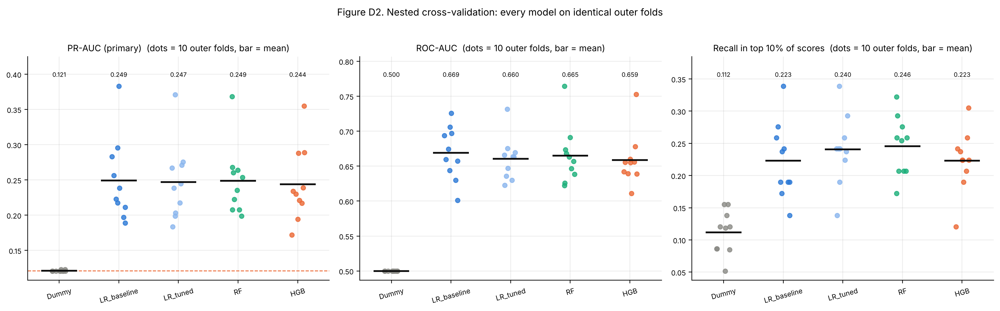

In [53]:
MC = {"Dummy": GREY, "LR_baseline": "#2a78d6", "LR_tuned": "#8ab6ee", "RF": "#1baf7a", "HGB": ORANGE}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for a, met, t in [(ax[0], "pr_auc", "PR-AUC (primary)"), (ax[1], "roc_auc", "ROC-AUC"), (ax[2], "recall_at_10pct", "Recall in top 10% of scores")]:
    _all = np.concatenate([arr(m, met) for m in ORDER]); LO, HI = _all.min(), _all.max(); RNG = HI - LO; a.set_ylim(LO - .05 * RNG, HI + .16 * RNG)
    for i, m in enumerate(ORDER):
        v = arr(m, met); a.scatter(np.full(len(v), i) + np.random.default_rng(i).uniform(-.12, .12, len(v)), v, color=MC[m], s=26, alpha=.8, zorder=3)
        a.hlines(v.mean(), i - .3, i + .3, color=INK, lw=2, zorder=4); a.text(i, HI + .05 * RNG, f"{v.mean():.3f}", ha="center", fontsize=7)
    if met == "pr_auc": a.axhline(yD.mean(), ls="--", color=ORANGE, lw=1)
    a.set_xticks(range(len(ORDER))); a.set_xticklabels(ORDER, fontsize=8, rotation=15); a.set_title(t + "  (dots = 10 outer folds, bar = mean)")
fig.suptitle("Figure D2. Nested cross-validation: every model on identical outer folds", y=1.02, fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "D02_nested_cv_leaderboard.png", dpi=130, bbox_inches="tight"); plt.show()

### D4. What the search chose, and how much tuning helped
A tuned model is only worth its complexity if tuning beats the fixed baseline *on outer folds*. Below: which feature set and hyper-parameters each outer fold selected (stable choices are reassuring; scattered choices mean the data cannot tell the options apart), and the **optimism gap** between the inner-CV score used to pick the winner and the honest outer-fold score.

In [54]:
tuned = ["LR_tuned", "RF", "HGB"]
ft = pd.crosstab(folds[folds.model.isin(tuned)].model, folds[folds.model.isin(tuned)].feature_set).reindex(tuned)
print("Feature set chosen by the inner search, counted over the 10 outer folds:"); display(ft)
gap = folds[folds.model.isin(tuned)].groupby("model").apply(lambda d: pd.Series({"inner_cv_pr_auc (used to pick)": d.inner_best_pr_auc.mean(), "outer_pr_auc (honest)": d.pr_auc.mean()})).reindex(tuned)
gap["optimism_gap"] = gap.iloc[:, 0] - gap.iloc[:, 1]; display(gap.round(4))
bp = folds[folds.model.isin(tuned)].copy(); bp = pd.concat([bp[["model", "fold"]].reset_index(drop=True), pd.DataFrame([json.loads(s) for s in bp.best_params]).reset_index(drop=True)], axis=1)
for m in tuned:
    q = bp[bp.model == m].drop(columns=["model", "fold"]).dropna(axis=1, how="all")
    print(f"\n{m}: hyper-parameters chosen in each outer fold"); display(q.round(4).rename(columns=lambda c: c.replace("model__", "").replace("select__", "")))

Feature set chosen by the inner search, counted over the 10 outer folds:


feature_set,all,recommended,recommended_no_red_flags
model,,,
LR_tuned,2,7,1
RF,6,4,0
HGB,3,5,2


,inner_cv_pr_auc (used to pick),outer_pr_auc (honest),optimism_gap
model,,,
LR_tuned,0.2601,0.2470,0.0131
RF,0.2651,0.2486,0.0165
HGB,0.2475,0.2439,0.0036



LR_tuned: hyper-parameters chosen in each outer fold


,C,penalty,feature_set
0,0.0333,l1,recommended
1,0.0038,l2,recommended
2,0.0931,l1,recommended
3,0.0255,l2,recommended
4,0.1354,l1,all
5,0.0226,l1,all
6,0.0207,l1,recommended
7,0.0320,l1,recommended
8,0.0079,l2,recommended_no_red_flags
9,0.0521,l1,recommended



RF: hyper-parameters chosen in each outer fold


,feature_set,max_depth,max_features,max_samples,min_samples_leaf
10,all,8.0,0.2,NaN,3.0
11,all,3.0,0.4,0.8,9.0
12,all,5.0,0.6,NaN,4.0
13,all,12.0,0.4,NaN,2.0
14,recommended,3.0,0.4,0.6,2.0
15,recommended,5.0,sqrt,NaN,7.0
16,all,3.0,0.6,0.6,6.0
17,recommended,5.0,sqrt,0.8,2.0
18,all,5.0,sqrt,0.8,8.0
19,recommended,8.0,0.4,0.6,3.0



HGB: hyper-parameters chosen in each outer fold


,feature_set,max_depth,max_features,min_samples_leaf,l2_regularization,learning_rate,max_iter,max_leaf_nodes
20,all,2.0,0.4,67.0,0.0359,0.0193,397.0,20.0
21,recommended,2.0,1.0,35.0,0.0289,0.0199,249.0,15.0
22,all,2.0,0.4,37.0,0.0373,0.0557,341.0,13.0
23,recommended_no_red_flags,2.0,0.7,73.0,0.3799,0.0207,157.0,31.0
24,recommended,2.0,0.4,33.0,0.4963,0.0529,172.0,31.0
25,all,2.0,0.7,69.0,0.2045,0.0243,311.0,13.0
26,recommended_no_red_flags,2.0,0.4,10.0,0.1432,0.0427,97.0,4.0
27,recommended,2.0,0.7,74.0,0.0699,0.0635,121.0,10.0
28,recommended,3.0,0.7,61.0,9.6771,0.0583,101.0,28.0
29,recommended,2.0,0.4,32.0,13.9905,0.0132,309.0,28.0


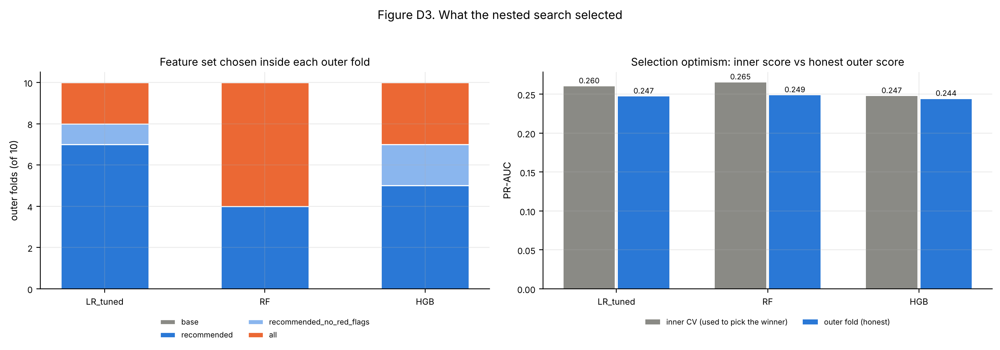

In [55]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
cols = {"base": GREY, "recommended": "#2a78d6", "recommended_no_red_flags": "#8ab6ee", "all": ORANGE}
bottom = np.zeros(len(tuned))
for fs, c in cols.items():
    v = ft.reindex(columns=list(cols), fill_value=0)[fs].to_numpy(); ax[0].bar(tuned, v, bottom=bottom, color=c, label=fs, width=.55, edgecolor="white"); bottom += v
ax[0].set_ylabel("outer folds (of 10)"); ax[0].set_title("Feature set chosen inside each outer fold"); ax[0].legend(fontsize=7, loc="upper center", bbox_to_anchor=(.5, -.1), ncol=2, frameon=False)
x = np.arange(len(tuned)); ax[1].bar(x - .18, gap.iloc[:, 0], .34, color=GREY, label="inner CV (used to pick the winner)"); ax[1].bar(x + .18, gap.iloc[:, 1], .34, color=BLUE, label="outer fold (honest)")
for xi, (a_, b_) in zip(x, zip(gap.iloc[:, 0], gap.iloc[:, 1])): ax[1].text(xi - .18, a_ + .004, f"{a_:.3f}", ha="center", fontsize=7); ax[1].text(xi + .18, b_ + .004, f"{b_:.3f}", ha="center", fontsize=7)
ax[1].set_xticks(x); ax[1].set_xticklabels(tuned); ax[1].set_ylabel("PR-AUC"); ax[1].set_title("Selection optimism: inner score vs honest outer score"); ax[1].legend(fontsize=7, loc="upper center", bbox_to_anchor=(.5, -.1), ncol=2, frameon=False)
fig.suptitle("Figure D3. What the nested search selected", y=1.03, fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "D03_search_choices_and_optimism.png", dpi=130, bbox_inches="tight"); plt.show()

### D5. Final fits and the search landscape
The final models are re-fitted on the **full development set** (same search, 5-fold inner CV) and saved to `outputs/models/`. The scatter shows the inner-CV PR-AUC of every candidate the search tried, grouped by feature set. It is descriptive: candidates differ in other hyper-parameters too, so a feature-set effect here is confounded. The nested results above are the evidence that counts.

loaded cached final models.


,best_params,inner_cv_pr_auc,seconds
Dummy,{},None,0.1
LR_baseline,{},None,0.1
LR_tuned,"{""C"": 0.0333, ""penalty"": ""l1"", ""feature_set"": ""recommended""}",0.26946,12.5
RF,"{""max_depth"": 3, ""max_features"": 0.6, ""max_samples"": 0.6, ""min_samples_leaf"": 19, ""feature_set"": ""recommended""}",0.260364,140.4
HGB,"{""l2_regularization"": 0.0359, ""learning_rate"": 0.0193, ""max_depth"": 2, ""max_features"": 0.4, ""max_iter"": 397, ""max_leaf_nodes"": 20, ""min_samples_leaf"": 67, ""feature_set"": ""all""}",0.244774,50.4


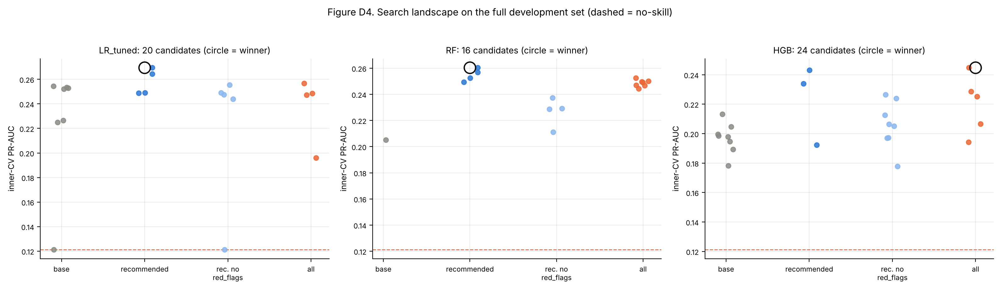

In [56]:
final_info, searches = fm.fit_final_models(XD, yD, OUT)
display(pd.DataFrame({m: {"best_params": json.dumps({k.replace("model__", "").replace("select__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in d["best_params"].items()}), "inner_cv_pr_auc": d["inner_cv_pr_auc"], "seconds": d["seconds"]} for m, d in final_info["models"].items()}).T)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4), sharey=False)
for a, m in zip(ax, tuned):
    s = searches[m].copy(); s["fs"] = s["param_select__feature_set"]
    for i, fs in enumerate(cols):
        v = s[s.fs == fs].mean_test_score.to_numpy(); a.scatter(np.full(len(v), i) + np.random.default_rng(i).uniform(-.1, .1, len(v)), v, color=cols[fs], s=30, alpha=.85, zorder=3)
    b = s.loc[s.mean_test_score.idxmax()]; a.scatter([list(cols).index(b.fs)], [b.mean_test_score], s=170, facecolors="none", edgecolors=INK, linewidths=1.5, zorder=4)
    a.axhline(yD.mean(), ls="--", color=ORANGE, lw=1); a.set_xticks(range(4)); a.set_xticklabels(["base", "recommended", "rec. no\nred_flags", "all"], fontsize=8); a.set_title(f"{m}: {len(s)} candidates (circle = winner)"); a.set_ylabel("inner-CV PR-AUC")
fig.suptitle("Figure D4. Search landscape on the full development set (dashed = no-skill)", y=1.03, fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "D04_search_landscape.png", dpi=130, bbox_inches="tight"); plt.show()

### D6. Are the strongest predictors stable across validation folds?
Permutation importance, measured on the **outer test fold** of every nested fold with that fold's own tuned model: shuffle one raw input column, recompute the features, and record how much PR-AUC drops. Shuffling the raw column also disturbs every derived feature built from it, so this answers "how much does the model rely on this *field*". Stability = agreement between folds (mean pairwise Spearman rank correlation of the importances) and how often a field lands in a fold's top 5. Each test fold has only about 58 frauds, so single-fold importances are noisy; that is exactly why stability is measured.

In [57]:
piv = perm.pivot_table(index="feature", columns=["model", "fold"], values="importance")
stab_rows, top_tbl = [], {}
for m in tuned:
    d = piv[m]; rho = d.corr(method="spearman").to_numpy(); off = rho[np.triu_indices_from(rho, 1)]
    top5 = (d.rank(ascending=False) <= 5).mean(axis=1)
    top_tbl[m] = pd.DataFrame({"mean_importance": d.mean(axis=1), "sd_across_folds": d.std(axis=1), "folds_with_positive_importance": (d > 0).mean(axis=1), "in_top5_share_of_folds": top5}).sort_values("mean_importance", ascending=False)
    stab_rows.append(dict(model=m, mean_pairwise_rank_corr=off.mean(), min_pairwise_rank_corr=off.min(), top3_share_of_total=top_tbl[m].mean_importance.head(3).sum() / top_tbl[m].mean_importance.clip(lower=0).sum()))
stab = pd.DataFrame(stab_rows); display(stab.round(3))
cons = pd.DataFrame({m: top_tbl[m].mean_importance.rank(ascending=False) for m in tuned}); cons["mean_rank"] = cons.mean(axis=1)
cons = cons.join(pd.DataFrame({m: top_tbl[m].mean_importance for m in tuned}), rsuffix="_importance").sort_values("mean_rank")
print("Consensus ranking of raw fields (rank 1 = most important), tuned models:"); display(cons.head(10).round(4))
pd.concat({m: t for m, t in top_tbl.items()}).to_csv(OUT / "D_importance_stability.csv"); cons.to_csv(OUT / "D_importance_consensus.csv")

,model,mean_pairwise_rank_corr,min_pairwise_rank_corr,top3_share_of_total
0,LR_tuned,0.483,-0.109,0.533
1,RF,0.388,-0.094,0.464
2,HGB,0.460,-0.203,0.485


Consensus ranking of raw fields (rank 1 = most important), tuned models:


,LR_tuned,RF,HGB,mean_rank,LR_tuned_importance,RF_importance,HGB_importance
feature,,,,,,,
new_device,1.0,1.0,1.0,1.0000,0.0333,0.0375,0.0358
merchant_risk_score,2.0,2.0,2.0,2.0000,0.0299,0.0296,0.0331
authentication_level,5.0,3.0,5.0,4.3333,0.0222,0.0193,0.0186
prior_chargebacks,3.0,6.0,4.0,4.3333,0.0281,0.0146,0.0221
transactions_last_1h,6.0,4.0,3.0,4.3333,0.0196,0.0179,0.0279
billing_address_mismatch,4.0,7.0,7.0,6.0000,0.0225,0.0142,0.0144
transaction_amount,9.0,5.0,6.0,6.6667,0.0011,0.0166,0.0182
ip_risk_score,8.0,8.0,8.0,8.0000,0.0042,0.0123,0.0135
transactions_last_24h,11.0,13.0,9.0,11.0000,0.0003,0.0021,0.0065


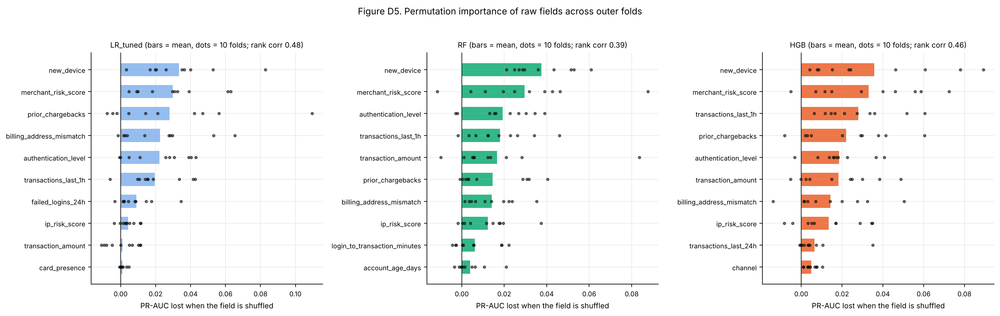

In [58]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5.2))
for a, m in zip(ax, tuned):
    t = top_tbl[m].head(10).iloc[::-1]; yy = np.arange(len(t))
    a.barh(yy, t.mean_importance, color=MC[m], height=.6, alpha=.9)
    for i, f in enumerate(t.index): a.scatter(piv[m].loc[f].to_numpy(), np.full(piv[m].shape[1], i), color=INK, s=9, alpha=.55, zorder=3)
    a.axvline(0, color=INK, lw=.8); a.set_yticks(yy); a.set_yticklabels(t.index, fontsize=8)
    a.set_xlabel("PR-AUC lost when the field is shuffled"); a.set_title(f"{m} (bars = mean, dots = 10 folds; rank corr {stab.set_index('model').loc[m, 'mean_pairwise_rank_corr']:.2f})", fontsize=9)
fig.suptitle("Figure D5. Permutation importance of raw fields across outer folds", y=1.02, fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "D05_importance_stability.png", dpi=130, bbox_inches="tight"); plt.show()

### D7. Findings (development set, nested cross-validation, 10 outer folds; numbers come from the tables above)

**Headline: no model is distinguishable from the simple baseline.** Tuning and nonlinearity added nothing measurable on this data.

| Model | PR-AUC | ROC-AUC | Recall in top 10% | Brier | Log loss |
|---|---|---|---|---|---|
| No-skill (prior) | 0.121 | 0.500 | 0.112 | 0.1065 | 0.3694 |
| LR baseline (fixed, raw features) | 0.249 (SD 0.059) | **0.669** | 0.223 | 0.1028 | 0.3543 |
| LR tuned | 0.247 (0.054) | 0.660 | 0.240 | 0.1035 | 0.3563 |
| Random Forest tuned | **0.249** (0.049) | 0.665 | **0.246** | **0.1020** | **0.3508** |
| Hist. Gradient Boosting tuned | 0.244 (0.053) | 0.659 | 0.223 | 0.1023 | 0.3520 |

- **Every paired difference against the baseline is far from significant** (smallest p = 0.49, over PR-AUC, ROC-AUC, recall and Brier). RF versus HGB on PR-AUC: +0.005, p = 0.80. Per-fold PR-AUC ranges from 0.17 to 0.38, and the 95% intervals on differences are about +/-0.04 to 0.05, so **this experiment cannot detect differences smaller than roughly 0.04 PR-AUC**. Read the ties as "no evidence of a difference", not "proof of equality".
- All models do beat the no-skill reference by about 2x on PR-AUC, so there is real but modest signal.
- **The ranking depends on the metric**: LR baseline has the best ROC-AUC (0.669) while Random Forest has the best recall in the top 10%, Brier score and log loss. Whether any of these gaps matters for money is answered in Part E.
- **The default 0.50 cutoff finds almost no fraud:** F1 at 0.5 is 0.074 (LR baseline), 0.020 (LR tuned), 0.016 (HGB) and 0.003 (RF). With a 12% base rate and modest signal, predicted probabilities rarely reach 0.5. This is the reason Part E optimises thresholds on cost.

**What tuning did**
- **Selection optimism is visible:** the inner-CV score that picked each winner exceeded the honest outer score by 0.013 (LR tuned: 0.260 vs 0.247), 0.016 (RF: 0.265 vs 0.249) and 0.003 (HGB: 0.247 vs 0.244). Without nesting, tuned models would have looked about 0.01 to 0.02 better than they are.
- **Where the data constrain the settings, the winners are simple and heavily regularised:** LR tuned used strong shrinkage in all 10 folds (C between 0.004 and 0.135, L1 in 7 of 10); HGB chose depth-2 trees in 9 of 10 folds with learning rates of 0.013 to 0.064. RF's choices were less consistent (depth 3 to 12, 2 to 9 rows per leaf), another sign the data cannot pin down its settings. Together this points to weak, mostly additive signal, consistent with Part B finding no significant interactions.
- **Feature set:** across the 30 tuned outer-fold choices, `base` was never chosen, `recommended` 16 times, `all` 11 times and `recommended_no_red_flags` 3 times, so 27 of 30 selections kept `n_red_flags`. Yet the honest outer scores of tuned models are no better than the fixed raw-feature baseline. Engineered features and tuning lift the trees up to the baseline's level, not past it (consistent with Part C).

**Which fields drive predictions, and are they stable across folds? (permutation importance on outer test folds)**
- **`new_device` and `merchant_risk_score` rank first and second in all three tuned models.** They are in a fold's top 5 in 70% to 100% of folds (`new_device` 0.8, 1.0 and 0.7 for LR, RF, HGB; `merchant_risk_score` 0.9, 0.7 and 0.9).
- Next, with similar mean rank (about 4.3): `authentication_level`, `prior_chargebacks`, `transactions_last_1h`; then `billing_address_mismatch`, `transaction_amount` and `ip_risk_score`.
- **Stability is only moderate beyond the top two:** mean pairwise rank correlation between folds is 0.48 (LR), 0.39 (RF) and 0.46 (HGB), with some fold pairs negatively correlated (minimum -0.20). Each test fold has only about 58 frauds, so single-fold rankings are noisy; trust the averages.
- The three top-3 fields carry 46% to 53% of total importance.
- The Logistic Regression baseline agrees in direction. Largest odds ratios (bootstrap 95% interval): Jewelry 1.88 (1.21 to 3.11), missing authentication 1.65 (1.31 to 2.08), Fashion 1.39, 1-hour velocity 1.36 per SD (1.21 to 1.56), new device 1.35 (1.22 to 1.54), E-commerce 1.34 (1.11 to 1.68), merchant risk 1.33 per SD (1.20 to 1.55); Fuel is protective at 0.63 (0.40 to 0.93). 17 of 56 coefficients have intervals that exclude 1.
- **This describes what the model relies on, not what causes fraud.** Causal reading is discussed in Part H.

**Carried into Part E**
1. All four real models (LR baseline, LR tuned, RF, HGB) go forward, because they tie on PR-AUC but differ on recall, Brier and log loss, and money may separate them.
2. By the rule fixed at the start (one-standard-error preference for the simpler model), **the Logistic Regression baseline is the default production candidate** unless expected cost shows a clear, robust advantage for a more complex model.
3. Honest out-of-fold predictions for all 2,400 development rows (two repeats, five models) are saved in `outputs/D_oof_predictions.csv` for the cost, calibration and imbalance work. Final models fitted on the full development set are in `outputs/models/`. The hold-out set was not read.

### D8. Outputs of Part D

In [59]:
print("Models saved:", sorted(p.name for p in (OUT / "models").glob("*.joblib")))
print("Out-of-fold predictions (every development row predicted by models that never saw it):", oof.shape, "->", "outputs/D_oof_predictions.csv")
print("Part D figures:", sorted(p.name for p in FIG.glob("D*.png")))
print("Hold-out set read in Part D: no")

Models saved: ['D_Dummy.joblib', 'D_HGB.joblib', 'D_LR_baseline.joblib', 'D_LR_tuned.joblib', 'D_RF.joblib']
Out-of-fold predictions (every development row predicted by models that never saw it): (2400, 12) -> outputs/D_oof_predictions.csv
Part D figures: ['D01_lr_baseline_odds_ratios.png', 'D02_nested_cv_leaderboard.png', 'D03_search_choices_and_optimism.png', 'D04_search_landscape.png', 'D05_importance_stability.png']
Hold-out set read in Part D: no


---
## Part E. Cost-Sensitive Learning

**Goal:** replace "maximise accuracy" with "minimise expected money lost", using an explicit, hypothetical, sensitivity-tested cost framework.

| Task E requirement | Section |
|---|---|
| Hypothetical cost matrix: false positives, false negatives, manual reviews, blocked transactions | E1 |
| Optimise thresholds against expected business cost | E2, E3 |
| Compare default 0.50 with cost-sensitive thresholding | E3 |
| Expected cost under multiple cost assumptions + sensitivity analysis | E4 to E7 |

**Rules and design (fixed before looking at any cost result)**
1. **Only honest scores are used.** Costs are computed on the out-of-fold predictions from Part D's nested cross-validation (every development row scored by a model that never saw it). The hold-out set is not read.
2. **Costs use the real transaction amount and the true label.** A fraud on a 1,000 purchase costs more than a fraud on a 20 purchase.
3. **Three actions, two thresholds.** Approve below `t_review`; send to manual review between `t_review` and `t_block`; block at or above `t_block`. A single threshold with no review band is the special case `t_review = t_block`.
4. **Operational limits are part of the framework.** Reviewers can clear only a fixed share of traffic, and the business will not tolerate unlimited declines of customers. Without those limits the arithmetic says "review almost everything" (shown as scenario S7). Both limits are explicit parameters and are sensitivity-tested (E7).
5. **Thresholds are chosen on training rows and scored on unseen rows** (repeated 5-fold, 10 repeats). A cost reported for rows that picked the threshold would be flattering, so the honest figure is the one to trust; the in-sample figure is shown only to quantify the optimism.
6. **Model choice rule, written now:** the fixed Logistic Regression baseline stays the production candidate unless another model has a lower honest three-way cost in the base scenario, with a paired-bootstrap 95% interval that excludes zero, **and** is cheaper in at least 5 of the 7 scenarios.
7. **All dollar figures are hypothetical** (the dataset's currency is not stated) and the dataset's 12% fraud rate is far above real-world card fraud rates, so absolute amounts are illustrative. Relative comparisons between policies are the point.

### E1. The cost framework

In [60]:
import fraud_costs as fc
SC = fc.SCENARIOS; BASE_SC = SC["S1_base"]; SEED_E = 42
oofE = pd.read_csv(OUT / "D_oof_predictions.csv")
assert len(oofE) == 2400 and set(oofE.transaction_id) == set(dev[ID])
amt_raw = oofE.transaction_id.map(df.set_index(ID).transaction_amount)
print(f"transaction amount is missing for {int(amt_raw.isna().sum())} of {len(oofE)} rows; filled with the development median ({amt_raw.median():.1f}) for cost accounting only (label-free)")
AMT = amt_raw.fillna(amt_raw.median()).to_numpy(); YE = oofE.fraud.to_numpy(); N = len(YE)
MODELS_E = ["LR_baseline", "LR_tuned", "RF", "HGB"]
SCORES = {m: [oofE[f"p_{m}_r0"].to_numpy(), oofE[f"p_{m}_r1"].to_numpy()] for m in MODELS_E}
lbE = pd.read_csv(OUT / "D_leaderboard.csv", index_col=0); ROC = lbE.loc[MODELS_E, "roc_auc_mean"]; PRA = lbE.loc[MODELS_E, "pr_auc_mean"]
print(f"rows {N} | frauds {int(YE.sum())} | mean amount {AMT.mean():.1f} (fraud {AMT[YE==1].mean():.1f}, legitimate {AMT[YE==0].mean():.1f}) | hold-out rows read: none")

PARAM_DOC = pd.DataFrame([
 ("loss_share", BASE_SC.loss_share, "Share of the amount lost when a fraud is approved (false negative)", "Goods shipped or cash out; under card-not-present rules the platform/merchant normally bears the full amount"),
 ("chargeback_fee", BASE_SC.chargeback_fee, "Fixed cost per approved fraud", "Processor dispute fee (typically 10 to 25) plus handling time"),
 ("fp_margin", BASE_SC.fp_margin, "Share of the amount lost as revenue when a legitimate sale is blocked (false positive)", "Net revenue on a declined good sale"),
 ("fp_friction", BASE_SC.fp_friction, "Fixed cost per wrongly blocked customer", "Support contact (about 5) plus roughly a 10% to 15% chance of losing a customer worth about 100"),
 ("review_cost", BASE_SC.review_cost, "Analyst cost per manual review", "About 4 minutes of an analyst at roughly 90 per hour fully loaded"),
 ("review_detect", BASE_SC.review_detect, "Chance a reviewer stops a fraud", "Analysts catch most but not all frauds"),
 ("review_wrong_decline", BASE_SC.review_wrong_decline, "Chance a reviewer wrongly declines a good customer", "Occasional reviewer error"),
 ("review_delay", BASE_SC.review_delay, "Cost of making a good customer wait during review", "Delay, abandonment and support tickets"),
 ("review_capacity", BASE_SC.review_capacity, "Maximum share of ALL transactions the team can review", "Queue the team can clear each day (operational limit)"),
 ("max_block_rate", BASE_SC.max_block_rate, "Maximum share of ALL transactions that may be auto-blocked", "Customer-friction guardrail: no more than about 1 in 10 transactions declined automatically"),
], columns=["parameter", "base_value", "meaning", "why this value (hypothetical)"])
pd.set_option("display.max_colwidth", 120); display(PARAM_DOC)
print("Each action's cost, per transaction:")
print("  approve a fraud  = loss_share x amount + chargeback_fee            approve a legitimate = 0")
print("  block a legit    = fp_margin x amount + fp_friction                block a fraud        = 0 (loss prevented)")
print("  review (any)     = review_cost + [fraud: (1 - review_detect) x fraud loss] + [legit: review_delay + review_wrong_decline x block cost]")

transaction amount is missing for 40 of 2400 rows; filled with the development median (90.3) for cost accounting only (label-free)
rows 2400 | frauds 291 | mean amount 133.6 (fraud 155.5, legitimate 130.6) | hold-out rows read: none


,parameter,base_value,meaning,why this value (hypothetical)
0,loss_share,1.00,Share of the amount lost when a fraud is approved (false negative),Goods shipped or cash out; under card-not-present rules the platform/merchant normally bears the full amount
1,chargeback_fee,15.00,Fixed cost per approved fraud,Processor dispute fee (typically 10 to 25) plus handling time
2,fp_margin,0.05,Share of the amount lost as revenue when a legitimate sale is blocked (false positive),Net revenue on a declined good sale
3,fp_friction,20.00,Fixed cost per wrongly blocked customer,Support contact (about 5) plus roughly a 10% to 15% chance of losing a customer worth about 100
4,review_cost,6.00,Analyst cost per manual review,About 4 minutes of an analyst at roughly 90 per hour fully loaded
5,review_detect,0.85,Chance a reviewer stops a fraud,Analysts catch most but not all frauds
6,review_wrong_decline,0.03,Chance a reviewer wrongly declines a good customer,Occasional reviewer error
7,review_delay,1.50,Cost of making a good customer wait during review,"Delay, abandonment and support tickets"
8,review_capacity,0.10,Maximum share of ALL transactions the team can review,Queue the team can clear each day (operational limit)
9,max_block_rate,0.10,Maximum share of ALL transactions that may be auto-blocked,Customer-friction guardrail: no more than about 1 in 10 transactions declined automatically


Each action's cost, per transaction:
  approve a fraud  = loss_share x amount + chargeback_fee            approve a legitimate = 0
  block a legit    = fp_margin x amount + fp_friction                block a fraud        = 0 (loss prevented)
  review (any)     = review_cost + [fraud: (1 - review_detect) x fraud loss] + [legit: review_delay + review_wrong_decline x block cost]


In [61]:
c_app, c_rev, c_blk = fc.row_costs(AMT, YE, BASE_SC)
mat = pd.DataFrame({f"legitimate ({(YE==0).mean():.0%} of rows)": [c_app[YE == 0].mean(), c_rev[YE == 0].mean(), c_blk[YE == 0].mean()],
                    f"fraud ({(YE==1).mean():.0%} of rows)": [c_app[YE == 1].mean(), c_rev[YE == 1].mean(), c_blk[YE == 1].mean()]}, index=["Approve", "Manual review", "Block"])
print("Base-case cost matrix: AVERAGE cost per transaction (currency units) by action and by what the transaction really is:")
display(mat.round(2))
FN_AVG, FP_AVG = c_app[YE == 1].mean(), c_blk[YE == 0].mean()
print(f"Average false-negative cost {FN_AVG:.1f} vs false-positive cost {FP_AVG:.1f}: ratio {FN_AVG / FP_AVG:.1f} : 1")
print(f"Textbook break-even for a single block threshold, IF probabilities were perfectly calibrated: t* = FP/(FP+FN) = {FP_AVG / (FP_AVG + FN_AVG):.3f}  (base fraud rate {YE.mean():.3f})")
scen_tbl = pd.DataFrame([s.as_dict() for s in SC.values()]).set_index("name"); display(scen_tbl)
print("Approve-everything cost per 1,000 transactions, by scenario:", {k: round(fc.row_costs(AMT, YE, s)[0].sum() / N * 1000) for k, s in SC.items()})

Base-case cost matrix: AVERAGE cost per transaction (currency units) by action and by what the transaction really is:


,legitimate (88% of rows),fraud (12% of rows)
Approve,0.00,170.53
Manual review,8.30,31.58
Block,26.53,0.00


Average false-negative cost 170.5 vs false-positive cost 26.5: ratio 6.4 : 1
Textbook break-even for a single block threshold, IF probabilities were perfectly calibrated: t* = FP/(FP+FN) = 0.135  (base fraud rate 0.121)


,loss_share,chargeback_fee,fp_margin,fp_friction,review_cost,review_detect,review_wrong_decline,review_delay,review_capacity,max_block_rate
name,,,,,,,,,,
S1_base,1.0,15.0,0.05,20.0,6.0,0.85,0.03,1.5,0.1,0.1
S2_fraud_averse,1.0,40.0,0.05,10.0,6.0,0.85,0.03,1.5,0.1,0.1
S3_customer_first,1.0,15.0,0.08,60.0,6.0,0.85,0.03,3.0,0.1,0.1
S4_review_expensive,1.0,15.0,0.05,20.0,15.0,0.85,0.03,1.5,0.1,0.1
S5_review_cheap_big_team,1.0,15.0,0.05,20.0,2.5,0.85,0.03,1.5,0.2,0.1
S6_partial_recovery,0.6,10.0,0.05,20.0,6.0,0.85,0.03,1.5,0.1,0.1
S7_no_operational_limits,1.0,15.0,0.05,20.0,6.0,0.85,0.03,1.5,1.0,1.0


Approve-everything cost per 1,000 transactions, by scenario: {'S1_base': 20677, 'S2_fraud_averse': 23708, 'S3_customer_first': 20677, 'S4_review_expensive': 20677, 'S5_review_cheap_big_team': 20677, 'S6_partial_recovery': 12527, 'S7_no_operational_limits': 20677}


### E2. Policies compared
For every model the same seven policies are scored (cost per 1,000 transactions):
- **approve_all**: no model, nothing blocked.
- **default_0.50**: block when the predicted probability is at least 0.50.
- **accuracy_opt** and **f1_opt**: a single block threshold chosen to maximise accuracy or F1 (the usual "ML" choices).
- **cost_opt_block**: a single block threshold chosen to minimise expected cost (block-rate guardrail applies).
- **cost_opt_review_only**: no auto-block; everything above one threshold goes to manual review (capacity limit applies).
- **cost_opt_three_way**: approve / review / block with two cost-optimised thresholds (both limits apply).

Honest cost = thresholds picked on training folds, applied to unseen folds, averaged over 10 repeats of 5-fold. Intervals are 95% bootstrap intervals over transactions.

In [62]:
POLICIES = ["approve_all", "default_0.50", "accuracy_opt", "f1_opt", "cost_opt_block", "cost_opt_review_only", "cost_opt_three_way"]
def make_chooser(policy, sc):
    return {"accuracy_opt": lambda: fc.chooser_metric("accuracy", YE), "f1_opt": lambda: fc.chooser_metric("f1", YE),
            "cost_opt_block": lambda: fc.chooser_cost("block", sc, AMT, YE), "cost_opt_review_only": lambda: fc.chooser_cost("review_only", sc, AMT, YE),
            "cost_opt_three_way": lambda: fc.chooser_cost("three_way", sc, AMT, YE)}[policy]()

ROW = {}                                                     # (scenario, model, policy) -> per-row honest cost
def run_policy(model, sc, policy):
    S = SCORES[model]; costs = fc.row_costs(AMT, YE, sc)
    if policy == "approve_all": t, rc = (np.inf, np.inf), costs[0]
    elif policy == "default_0.50": t = (0.5, 0.5); rc = fc.fixed_row_costs(S, YE, AMT, sc, .5, .5)
    else:
        ch = make_chooser(policy, sc); t = ch(S, np.arange(N)); rc, _ = fc.honest_row_costs(S, YE, AMT, sc, ch, n_cv_repeats=10, k=5, seed=SEED_E)
    ROW[(sc.name, model, policy)] = rc
    summ = fc.policy_summary(S, YE, AMT, sc, *t)
    return dict(scenario=sc.name, model=model, policy=policy, t_review=t[0], t_block=t[1], cost_insample=summ["cost"], cost_honest=rc.mean() * 1000,
                review_rate=summ["review_rate"], block_rate=summ["block_rate"], fraud_capture=summ["fraud_capture"], block_precision=summ["block_precision"],
                legit_blocked_per_1000=summ["legit_blocked"], frauds_missed_per_1000=summ["frauds_missed"])

def boot_ci(rc, B=2000, seed=0):
    idx = np.random.default_rng(seed).integers(0, len(rc), (B, len(rc))); bs = rc[idx].mean(axis=1) * 1000
    return np.quantile(bs, .025), np.quantile(bs, .975)

base_rows = [run_policy(m, BASE_SC, p) for m in MODELS_E for p in POLICIES]
base_tbl = pd.DataFrame(base_rows)
base_tbl[["ci_low", "ci_high"]] = [boot_ci(ROW[("S1_base", r.model, r.policy)]) for r in base_tbl.itertuples()]
base_tbl["optimism"] = base_tbl.cost_honest - base_tbl.cost_insample
show = ["model", "policy", "t_review", "t_block", "cost_honest", "ci_low", "ci_high", "cost_insample", "review_rate", "block_rate", "fraud_capture", "block_precision"]
pd.set_option("display.width", 250); display(base_tbl[show].round(3))

,model,policy,t_review,t_block,cost_honest,ci_low,ci_high,cost_insample,review_rate,block_rate,fraud_capture,block_precision
0,LR_baseline,approve_all,inf,inf,20676.771,17429.641,24158.582,20676.771,0.0,0.000,0.000,NaN
1,LR_baseline,default_0.50,0.500,0.500,20442.812,17190.174,23959.134,20442.812,0.0,0.011,0.041,0.464
2,LR_baseline,accuracy_opt,0.823,0.823,20662.336,17421.529,24173.891,20682.589,0.0,0.000,0.000,0.000
3,LR_baseline,f1_opt,0.124,0.124,17109.153,14854.260,19570.350,17076.719,0.0,0.353,0.603,0.207
4,LR_baseline,cost_opt_block,0.252,0.252,18979.006,16065.427,22192.455,18745.871,0.0,0.100,0.220,0.267
5,LR_baseline,cost_opt_review_only,0.252,inf,17833.963,14952.970,21013.853,17778.493,0.1,0.000,0.187,NaN
6,LR_baseline,cost_opt_three_way,0.183,0.259,16669.086,14081.733,19624.402,16575.735,0.1,0.093,0.348,0.266
7,LR_tuned,approve_all,inf,inf,20676.771,17429.641,24158.582,20676.771,0.0,0.000,0.000,NaN
8,LR_tuned,default_0.50,0.500,0.500,20590.128,17357.871,24103.959,20590.128,0.0,0.003,0.010,0.393
9,LR_tuned,accuracy_opt,0.677,0.677,20686.025,17438.401,24176.020,20681.786,0.0,0.000,0.000,0.000


In [63]:
# improvement of each cost-sensitive policy over the default 0.50 rule and over approving everything (paired bootstrap over transactions)
imp = []
for m in MODELS_E:
    for p in ["cost_opt_block", "cost_opt_review_only", "cost_opt_three_way"]:
        for ref, lab in [("default_0.50", "default 0.50"), ("approve_all", "approve all")]:
            d, lo, hi, pv = fc.paired_bootstrap(ROW[("S1_base", m, ref)], ROW[("S1_base", m, p)])
            base = ROW[("S1_base", m, ref)].mean() * 1000
            imp.append(dict(model=m, policy=p, versus=lab, saving_per_1000=d, ci_low=lo, ci_high=hi, saving_pct=100 * d / base, p_value=pv))
imp = pd.DataFrame(imp); display(imp[imp.policy == "cost_opt_three_way"].round(3))
print("Share of transactions that reach 0.50 under each model:", {m: round(float(np.mean([(s >= .5).mean() for s in SCORES[m]])), 4) for m in MODELS_E})

,model,policy,versus,saving_per_1000,ci_low,ci_high,saving_pct,p_value
4,LR_baseline,cost_opt_three_way,default 0.50,3773.726,2055.217,5545.337,18.460,0.0
5,LR_baseline,cost_opt_three_way,approve all,4007.684,2266.085,5811.367,19.383,0.0
10,LR_tuned,cost_opt_three_way,default 0.50,3795.957,2183.707,5536.999,18.436,0.0
11,LR_tuned,cost_opt_three_way,approve all,3882.600,2266.030,5648.009,18.778,0.0
16,RF,cost_opt_three_way,default 0.50,6392.650,4062.878,9141.083,30.946,0.0
17,RF,cost_opt_three_way,approve all,6412.284,4091.008,9157.596,31.012,0.0
22,HGB,cost_opt_three_way,default 0.50,4863.240,3063.167,6812.869,23.792,0.0
23,HGB,cost_opt_three_way,approve all,5099.652,3243.905,7114.602,24.664,0.0


Share of transactions that reach 0.50 under each model: {'LR_baseline': 0.0108, 'LR_tuned': 0.0031, 'RF': 0.0013, 'HGB': 0.0017}


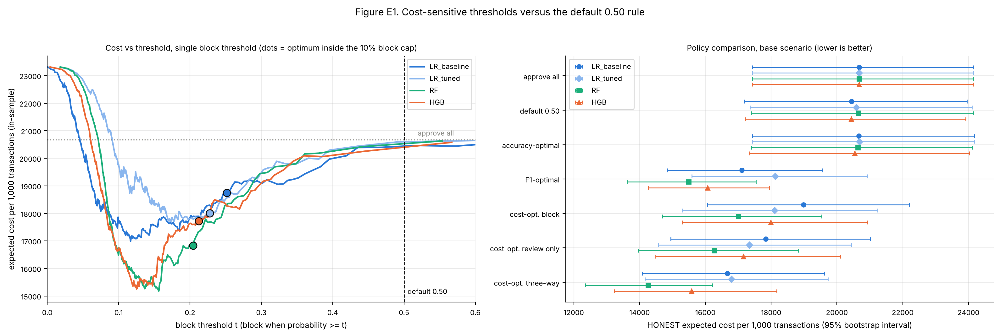

In [64]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5.2))
MCE = {"LR_baseline": "#2a78d6", "LR_tuned": "#8ab6ee", "RF": "#1baf7a", "HGB": ORANGE}; MK = {"LR_baseline": "o", "LR_tuned": "D", "RF": "s", "HGB": "^"}
for m in MODELS_E:
    S = SCORES[m]; g = fc.make_grid(S); costs = fc.row_costs(AMT, YE, BASE_SC); cost, rr, br = fc.surface(S, costs, g); d = np.diag(cost) / N * 1000
    ax[0].plot(g[:-1], d[:-1], color=MCE[m], lw=1.8, label=m)
    t1, t2, c = fc.best_pair((cost, rr, br), g, "block", 1.0, BASE_SC.max_block_rate); ax[0].scatter([t1], [c / N * 1000], color=MCE[m], s=70, zorder=4, edgecolors=INK)
ax[0].axhline(fc.row_costs(AMT, YE, BASE_SC)[0].sum() / N * 1000, color=GREY, ls=":", lw=1.2); ax[0].text(.57, fc.row_costs(AMT, YE, BASE_SC)[0].sum() / N * 1000 + 150, "approve all", ha="right", color=GREY, fontsize=8)
ax[0].axvline(.5, color=INK, ls="--", lw=1); ax[0].text(.505, ax[0].get_ylim()[0] + 300, "default 0.50", fontsize=8)
ax[0].set_xlim(0, .6); ax[0].set_xlabel("block threshold t (block when probability >= t)"); ax[0].set_ylabel("expected cost per 1,000 transactions (in-sample)")
ax[0].set_title("Cost vs threshold, single block threshold (dots = optimum inside the 10% block cap)", fontsize=9); ax[0].legend(fontsize=8)
pol_lab = {"approve_all": "approve all", "default_0.50": "default 0.50", "accuracy_opt": "accuracy-optimal", "f1_opt": "F1-optimal", "cost_opt_block": "cost-opt. block", "cost_opt_review_only": "cost-opt. review only", "cost_opt_three_way": "cost-opt. three-way"}
for j, m in enumerate(MODELS_E):
    q = base_tbl[base_tbl.model == m].set_index("policy").reindex(POLICIES); y = np.arange(len(POLICIES)) + (j - 1.5) * .17
    ax[1].errorbar(q.cost_honest, y, xerr=[q.cost_honest - q.ci_low, q.ci_high - q.cost_honest], fmt=MK[m], color=MCE[m], ms=5, capsize=2, lw=1, label=m)
ax[1].set_yticks(range(len(POLICIES))); ax[1].set_yticklabels([pol_lab[p] for p in POLICIES]); ax[1].invert_yaxis(); ax[1].legend(fontsize=8)
ax[1].set_xlabel("HONEST expected cost per 1,000 transactions (95% bootstrap interval)"); ax[1].set_title("Policy comparison, base scenario (lower is better)", fontsize=9)
fig.suptitle("Figure E1. Cost-sensitive thresholds versus the default 0.50 rule", y=1.02, fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "E01_cost_curves_and_policies.png", dpi=130, bbox_inches="tight"); plt.show()

### E3. Scenarios: does the answer survive different cost assumptions?
Seven scenarios (parameters in E1): the base case; a fraud-averse business (heavy chargeback penalties); a customer-first business (declines are expensive); expensive and cheap review; partial fraud recovery (insurance or dispute wins); and a case with **no operational limits**, which shows what the arithmetic does without them.

In [65]:
scen_rows = []
for sname, sc in SC.items():
    for m in MODELS_E:
        for p in (["approve_all", "default_0.50", "cost_opt_block", "cost_opt_three_way"] if sname != "S1_base" else ["approve_all", "default_0.50", "cost_opt_block", "cost_opt_three_way"]):
            scen_rows.append(run_policy(m, sc, p) if sname != "S1_base" else next(r for r in base_rows if r["model"] == m and r["policy"] == p))
scen = pd.DataFrame(scen_rows)
aa = scen[scen.policy == "approve_all"].set_index(["scenario", "model"]).cost_honest; df05 = scen[scen.policy == "default_0.50"].set_index(["scenario", "model"]).cost_honest
scen["saving_vs_approve_all_pct"] = [100 * (aa[(r.scenario, r.model)] - r.cost_honest) / aa[(r.scenario, r.model)] for r in scen.itertuples()]
scen["saving_vs_default_pct"] = [100 * (df05[(r.scenario, r.model)] - r.cost_honest) / df05[(r.scenario, r.model)] for r in scen.itertuples()]
tw = scen[scen.policy == "cost_opt_three_way"]
print("Honest cost per 1,000 transactions, cost-optimal three-way policy:"); display(tw.pivot(index="scenario", columns="model", values="cost_honest").reindex(list(SC))[MODELS_E].round(0))
print("Saving versus the default 0.50 rule (%):"); display(tw.pivot(index="scenario", columns="model", values="saving_vs_default_pct").reindex(list(SC))[MODELS_E].round(1))
print("Optimal thresholds (t_review / t_block), three-way policy:")
display(tw.assign(th=lambda d: d.t_review.round(3).astype(str) + " / " + d.t_block.round(3).astype(str)).pivot(index="scenario", columns="model", values="th").reindex(list(SC))[MODELS_E])
print("Approve-everything cost:"); display(aa.unstack()[MODELS_E].reindex(list(SC)).round(0).iloc[:, :1].rename(columns={"LR_baseline": "approve_all"}))

Honest cost per 1,000 transactions, cost-optimal three-way policy:


model,LR_baseline,LR_tuned,RF,HGB
scenario,,,,
S1_base,16669.0,16794.0,14264.0,15577.0
S2_fraud_averse,17877.0,18021.0,15427.0,16637.0
S3_customer_first,18213.0,17637.0,16766.0,17404.0
S4_review_expensive,17602.0,17843.0,15151.0,16488.0
S5_review_cheap_big_team,14812.0,15250.0,12337.0,12843.0
S6_partial_recovery,11229.0,10929.0,10047.0,10812.0
S7_no_operational_limits,11378.0,11489.0,10467.0,10894.0


Saving versus the default 0.50 rule (%):


model,LR_baseline,LR_tuned,RF,HGB
scenario,,,,
S1_base,18.5,18.4,30.9,23.8
S2_fraud_averse,23.2,23.5,34.8,29.0
S3_customer_first,12.2,14.7,19.0,15.0
S4_review_expensive,13.9,13.3,26.7,19.3
S5_review_cheap_big_team,27.5,25.9,40.3,37.2
S6_partial_recovery,10.0,12.5,19.8,12.8
S7_no_operational_limits,44.3,44.2,49.3,46.7


Optimal thresholds (t_review / t_block), three-way policy:


model,LR_baseline,LR_tuned,RF,HGB
scenario,,,,
S1_base,0.183 / 0.259,0.183 / 0.228,0.156 / 0.208,0.162 / 0.212
S2_fraud_averse,0.183 / 0.259,0.183 / 0.228,0.154 / 0.204,0.162 / 0.212
S3_customer_first,0.244 / 0.572,0.228 / inf,0.204 / 0.553,0.209 / 0.445
S4_review_expensive,0.185 / 0.259,0.183 / 0.228,0.156 / 0.204,0.162 / 0.212
S5_review_cheap_big_team,0.143 / 0.259,0.169 / 0.278,0.136 / 0.236,0.147 / 0.269
S6_partial_recovery,0.214 / 0.352,0.22 / 0.381,0.156 / 0.208,0.186 / 0.279
S7_no_operational_limits,0.022 / inf,0.061 / inf,0.088 / 0.349,0.087 / 0.445


Approve-everything cost:


model,approve_all
scenario,
S1_base,20677.0
S2_fraud_averse,23708.0
S3_customer_first,20677.0
S4_review_expensive,20677.0
S5_review_cheap_big_team,20677.0
S6_partial_recovery,12527.0
S7_no_operational_limits,20677.0


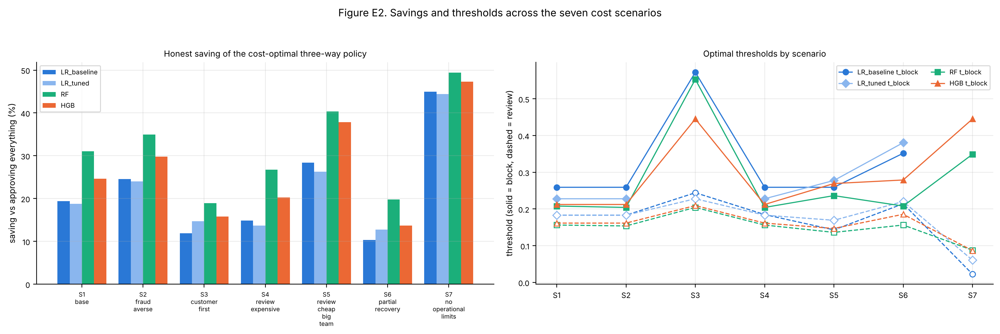

In [66]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
x = np.arange(len(SC)); w = .2
for j, m in enumerate(MODELS_E):
    q = tw[tw.model == m].set_index("scenario").reindex(list(SC)); ax[0].bar(x + (j - 1.5) * w, q.saving_vs_approve_all_pct, w, color=MCE[m], label=m)
ax[0].set_xticks(x); ax[0].set_xticklabels([s.replace("_", "\n") for s in SC], fontsize=6.5); ax[0].set_ylabel("saving vs approving everything (%)")
ax[0].set_title("Honest saving of the cost-optimal three-way policy", fontsize=9); ax[0].legend(fontsize=7)
for m in MODELS_E:
    q = tw[tw.model == m].set_index("scenario").reindex(list(SC)); ax[1].plot(x, q.t_block.replace(np.inf, np.nan), marker=MK[m], color=MCE[m], lw=1.2, label=m + " t_block"); ax[1].plot(x, q.t_review, marker=MK[m], color=MCE[m], lw=1.2, ls="--", mfc="white")
ax[1].set_xticks(x); ax[1].set_xticklabels([s.split("_")[0] for s in SC]); ax[1].set_ylabel("threshold (solid = block, dashed = review)"); ax[1].set_title("Optimal thresholds by scenario", fontsize=9); ax[1].legend(fontsize=7, ncol=2)
fig.suptitle("Figure E2. Savings and thresholds across the seven cost scenarios", y=1.03, fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "E02_scenarios.png", dpi=130, bbox_inches="tight"); plt.show()

### E4. Does the highest-ROC-AUC model also give the best business outcome?
ROC-AUC and PR-AUC rank how well a model *orders* transactions. Cost depends on **which** transactions are caught (high-value ones matter more) and on the thresholds. Below: each model's ranking by ROC-AUC, by PR-AUC and by honest cost, and a paired comparison against the Logistic Regression baseline in every scenario. A negative difference means the model is **cheaper** than the baseline.

In [67]:
rk = pd.DataFrame({"ROC_AUC": ROC, "ROC_rank": ROC.rank(ascending=False).astype(int), "PR_AUC": PRA, "PR_rank": PRA.rank(ascending=False).astype(int)})
b3 = tw[tw.scenario == "S1_base"].set_index("model").cost_honest; bb = scen[(scen.scenario == "S1_base") & (scen.policy == "cost_opt_block")].set_index("model").cost_honest
rk["honest_cost_three_way_base"] = b3; rk["cost_rank_three_way"] = b3.rank().astype(int); rk["honest_cost_block_base"] = bb; rk["cost_rank_block"] = bb.rank().astype(int)
display(rk.loc[MODELS_E].round(4))
cmp_rows = []
for sname in SC:
    ref = ROW[(sname, "LR_baseline", "cost_opt_three_way")]
    for m in ["LR_tuned", "RF", "HGB"]:
        d, lo, hi, pv = fc.paired_bootstrap(ROW[(sname, m, "cost_opt_three_way")], ref)
        cmp_rows.append(dict(scenario=sname, model=m, diff_vs_LR_baseline=d, ci_low=lo, ci_high=hi, p_value=pv, cheaper=d < 0, interval_excludes_zero=(hi < 0) or (lo > 0)))
cmp = pd.DataFrame(cmp_rows); display(cmp.round(3))
# pre-set model-choice rule
CHOSEN, why = "LR_baseline", {}
for m in ["LR_tuned", "RF", "HGB"]:
    c = cmp[cmp.model == m]; base_row = c[c.scenario == "S1_base"].iloc[0]
    why[m] = dict(base_cheaper_and_significant=bool(base_row.cheaper and base_row.ci_high < 0), scenarios_cheaper=int(c.cheaper.sum()))
    why[m]["qualifies"] = why[m]["base_cheaper_and_significant"] and why[m]["scenarios_cheaper"] >= 5
q = [m for m in why if why[m]["qualifies"]]
if q: CHOSEN = min(q, key=lambda m: b3[m])
print("Rule check:", why); print("==> CHOSEN production candidate for the sensitivity analysis:", CHOSEN)

,ROC_AUC,ROC_rank,PR_AUC,PR_rank,honest_cost_three_way_base,cost_rank_three_way,honest_cost_block_base,cost_rank_block
model,,,,,,,,
LR_baseline,0.6689,1,0.2494,1,16669.0864,3,18979.0057,4
LR_tuned,0.6604,3,0.2470,3,16794.1712,4,18102.3666,3
RF,0.6650,2,0.2486,2,14264.4864,1,16999.9086,1
HGB,0.6588,4,0.2439,4,15577.1191,2,17985.4237,2


,scenario,model,diff_vs_LR_baseline,ci_low,ci_high,p_value,cheaper,interval_excludes_zero
0,S1_base,LR_tuned,125.085,-710.921,982.119,0.814,False,False
1,S1_base,RF,-2404.600,-4579.278,-671.008,0.003,True,True
2,S1_base,HGB,-1091.967,-2546.689,276.498,0.121,True,False
3,S2_fraud_averse,LR_tuned,143.329,-837.197,1125.507,0.815,False,False
4,S2_fraud_averse,RF,-2450.904,-4732.238,-610.987,0.005,True,True
5,S2_fraud_averse,HGB,-1240.652,-2838.356,249.508,0.106,True,False
6,S3_customer_first,LR_tuned,-575.154,-1375.683,193.006,0.163,True,False
7,S3_customer_first,RF,-1446.530,-3123.143,-73.413,0.042,True,True
8,S3_customer_first,HGB,-808.810,-1828.824,145.125,0.096,True,False
9,S4_review_expensive,LR_tuned,240.694,-587.423,1114.540,0.615,False,False


Rule check: {'LR_tuned': {'base_cheaper_and_significant': False, 'scenarios_cheaper': 2, 'qualifies': False}, 'RF': {'base_cheaper_and_significant': True, 'scenarios_cheaper': 7, 'qualifies': True}, 'HGB': {'base_cheaper_and_significant': False, 'scenarios_cheaper': 7, 'qualifies': False}}
==> CHOSEN production candidate for the sensitivity analysis: RF


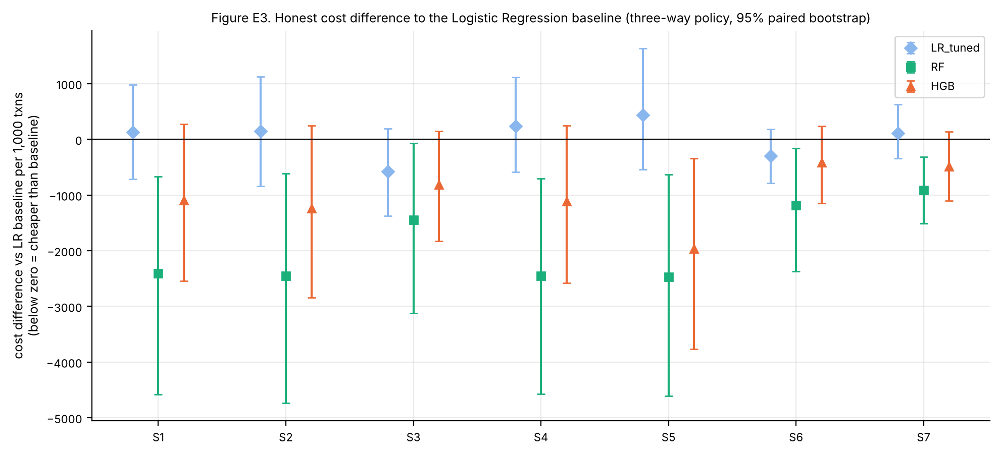

In [68]:
fig, ax = plt.subplots(figsize=(10, 4.6)); x = np.arange(len(SC))
for j, m in enumerate(["LR_tuned", "RF", "HGB"]):
    c = cmp[cmp.model == m].set_index("scenario").reindex(list(SC)); off = (j - 1) * .2
    ax.errorbar(x + off, c.diff_vs_LR_baseline, yerr=[c.diff_vs_LR_baseline - c.ci_low, c.ci_high - c.diff_vs_LR_baseline], fmt=MK[m], color=MCE[m], capsize=3, ms=6, label=m)
ax.axhline(0, color=INK, lw=.8); ax.set_xticks(x); ax.set_xticklabels([s.split("_")[0] for s in SC]); ax.set_ylabel("cost difference vs LR baseline per 1,000 txns\n(below zero = cheaper than baseline)")
ax.set_title("Figure E3. Honest cost difference to the Logistic Regression baseline (three-way policy, 95% paired bootstrap)", fontsize=9); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "E03_model_cost_comparison.png", dpi=130, bbox_inches="tight"); plt.show()

### E5. Threshold sensitivity: how sensitive is the recommended threshold to the assumed costs?
Four views, all for the chosen model:
1. **Cost-ratio sweep** (no operating limits): scale the false-negative cost up and down and see where the best single block threshold goes, against the textbook value `t* = FP / (FP + FN)`, which is only correct if the probabilities are calibrated. A gap between the two lines is a calibration problem (Part F).
2. **Tornado:** change one parameter at a time, re-optimise, and record the new cost and thresholds, and the **regret** of keeping the base thresholds.
3. **Regret matrix:** the base-case thresholds used in every other scenario, versus that scenario's own optimum.
4. **Bootstrap stability:** how much the optimal thresholds move when the data are resampled (sampling noise rather than cost noise).

RF, base scenario, in-sample optimum: t_review = 0.156, t_block = 0.208, cost 14183 per 1,000


,model,fn_multiplier,fn_fp_ratio,optimal_threshold,theory_threshold,cost_per_1000
2,RF,0.25,1.607,0.349,0.384,5127.085
6,RF,0.50,3.214,0.244,0.237,9535.556
10,RF,1.00,6.428,0.156,0.135,15183.028
14,RF,2.00,12.856,0.088,0.072,19918.265
18,RF,4.00,25.712,0.057,0.037,23167.643
22,RF,8.00,51.424,0.033,0.019,23266.614
26,RF,16.00,102.847,0.018,0.010,23312.768
30,RF,32.00,205.694,0.018,0.005,23312.768


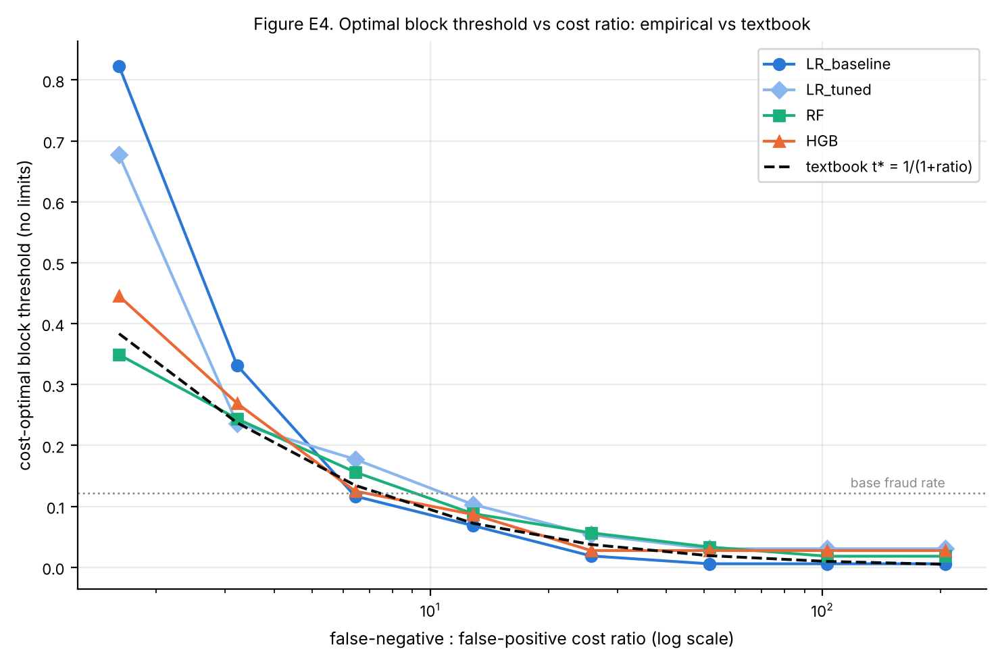

In [69]:
def opt_for(model, sc, kind="three_way", capped=True):
    S = SCORES[model]; g = fc.make_grid(S); costs = fc.row_costs(AMT, YE, sc); surf = fc.surface(S, costs, g)
    t1, t2, c = fc.best_pair(surf, g, kind, sc.review_capacity if capped else 1.0, sc.max_block_rate if capped else 1.0); return t1, t2, c / N * 1000
def cost_at(model, sc, t1, t2): return fc.fixed_row_costs(SCORES[model], YE, AMT, sc, t1, t2).mean() * 1000

T1, T2, C_BASE = opt_for(CHOSEN, BASE_SC); print(f"{CHOSEN}, base scenario, in-sample optimum: t_review = {T1:.3f}, t_block = {T2:.3f}, cost {C_BASE:.0f} per 1,000")

# (1) cost-ratio sweep, no review, no limits -> single block threshold
sweep = []
for f in [0.25, 0.5, 1, 2, 4, 8, 16, 32]:
    scf = BASE_SC.with_(name=f"ratio_x{f}", loss_share=BASE_SC.loss_share * f, chargeback_fee=BASE_SC.chargeback_fee * f)
    c = fc.row_costs(AMT, YE, scf); ratio = c[0][YE == 1].mean() / c[2][YE == 0].mean()
    for m in MODELS_E:
        t1, t2, cc = opt_for(m, scf, "block", capped=False); sweep.append(dict(model=m, fn_multiplier=f, fn_fp_ratio=ratio, optimal_threshold=t1, theory_threshold=1 / (1 + ratio), cost_per_1000=cc))
sweep = pd.DataFrame(sweep); display(sweep[sweep.model == CHOSEN].round(3))
fig, ax = plt.subplots(figsize=(7.5, 5))
for m in MODELS_E:
    q = sweep[sweep.model == m]; ax.plot(q.fn_fp_ratio, q.optimal_threshold, marker=MK[m], color=MCE[m], label=m)
q = sweep[sweep.model == CHOSEN]; ax.plot(q.fn_fp_ratio, q.theory_threshold, color=INK, ls="--", lw=1.5, label="textbook t* = 1/(1+ratio)")
ax.axhline(YE.mean(), color=GREY, ls=":", lw=1); ax.text(q.fn_fp_ratio.max(), YE.mean() + .01, "base fraud rate", ha="right", fontsize=7, color=GREY)
ax.set_xscale("log"); ax.set_xlabel("false-negative : false-positive cost ratio (log scale)"); ax.set_ylabel("cost-optimal block threshold (no limits)"); ax.legend(fontsize=8)
ax.set_title("Figure E4. Optimal block threshold vs cost ratio: empirical vs textbook", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "E04_threshold_vs_cost_ratio.png", dpi=130, bbox_inches="tight"); plt.show()

In [70]:
# (2) tornado: one parameter at a time
RANGES = {"loss_share": (.5, 1.0), "chargeback_fee": (5, 60), "fp_margin": (0, .10), "fp_friction": (5, 60), "review_cost": (2, 15),
          "review_detect": (.6, .95), "review_wrong_decline": (0, .10), "review_delay": (0, 5), "review_capacity": (.05, .20), "max_block_rate": (.02, .20)}
torn = []
for par, (lo, hi) in RANGES.items():
    for tag, val in [("low", lo), ("high", hi)]:
        sc2 = BASE_SC.with_(name=f"{par}_{tag}", **{par: val}); t1, t2, c = opt_for(CHOSEN, sc2); kept = cost_at(CHOSEN, sc2, T1, T2)
        torn.append(dict(parameter=par, end=tag, value=val, t_review=t1, t_block=t2, cost_reoptimised=c, cost_with_base_thresholds=kept, regret=kept - c, approve_all=fc.row_costs(AMT, YE, sc2)[0].sum() / N * 1000))
torn = pd.DataFrame(torn); torn["cost_change_vs_base"] = torn.cost_reoptimised - C_BASE
tp = torn.pivot(index="parameter", columns="end", values=["value", "cost_reoptimised", "t_review", "t_block", "regret"]); tp.columns = [f"{a}_{b}" for a, b in tp.columns]
tp["swing"] = (tp.cost_reoptimised_high - tp.cost_reoptimised_low).abs(); display(tp.sort_values("swing", ascending=False).round(3))

,value_high,value_low,cost_reoptimised_high,cost_reoptimised_low,t_review_high,t_review_low,t_block_high,t_block_low,regret_high,regret_low,swing
parameter,,,,,,,,,,,
loss_share,1.00,0.50,14182.695,9051.332,0.156,0.183,0.208,0.282,-0.000,90.498,5131.363
chargeback_fee,60.00,5.00,17650.976,13411.966,0.156,0.156,0.208,0.208,-0.000,-0.000,4239.010
fp_friction,60.00,5.00,16297.168,13122.694,0.204,0.156,0.553,0.204,607.277,39.345,3174.474
review_capacity,0.20,0.05,12950.516,15577.452,0.136,0.178,0.236,0.208,1232.179,-1394.758,2626.936
max_block_rate,0.20,0.02,14141.546,15963.983,0.131,0.195,0.156,0.349,41.149,-1781.288,1822.437
fp_margin,0.10,0.00,15045.753,13307.096,0.156,0.156,0.208,0.204,-0.000,12.541,1738.657
review_detect,0.95,0.60,13741.930,15208.242,0.156,0.156,0.208,0.204,-0.000,76.364,1466.312
review_cost,15.00,2.00,15062.163,13782.695,0.156,0.156,0.204,0.208,20.532,-0.000,1279.468
review_delay,5.00,0.00,14464.882,14061.757,0.156,0.156,0.208,0.208,-0.000,-0.000,403.125


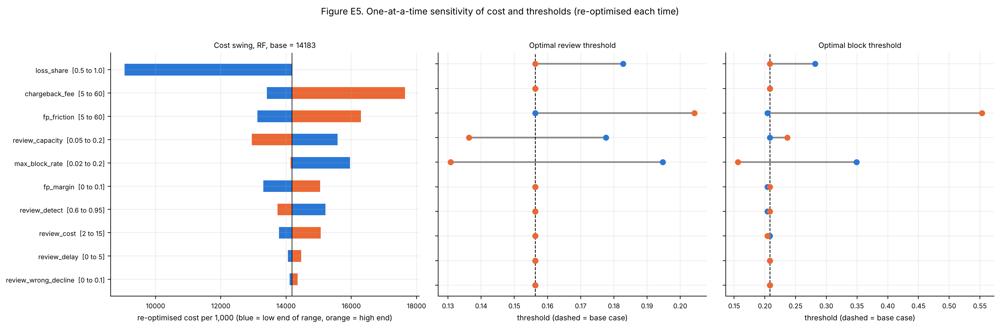

In [71]:
order = tp.sort_values("swing").index.tolist()
fig, ax = plt.subplots(1, 3, figsize=(17, 5.4), gridspec_kw={"width_ratios": [1.15, 1, 1]})
for i, par in enumerate(order):
    lo, hi = tp.loc[par, "cost_reoptimised_low"], tp.loc[par, "cost_reoptimised_high"]
    ax[0].barh(i, hi - C_BASE, left=C_BASE, color=ORANGE, height=.5); ax[0].barh(i, lo - C_BASE, left=C_BASE, color=BLUE, height=.5)
ax[0].axvline(C_BASE, color=INK, lw=.8); ax[0].set_yticks(range(len(order))); ax[0].set_yticklabels([f"{p}  [{RANGES[p][0]} to {RANGES[p][1]}]" for p in order], fontsize=8)
ax[0].set_xlabel("re-optimised cost per 1,000 (blue = low end of range, orange = high end)"); ax[0].set_title(f"Cost swing, {CHOSEN}, base = {C_BASE:.0f}", fontsize=9)
for a, col, t in [(ax[1], "t_review", "Optimal review threshold"), (ax[2], "t_block", "Optimal block threshold")]:
    for i, par in enumerate(order):
        a.plot([tp.loc[par, f"{col}_low"], tp.loc[par, f"{col}_high"]], [i, i], color=GREY, lw=2); a.scatter([tp.loc[par, f"{col}_low"]], [i], color=BLUE, s=40, zorder=3); a.scatter([tp.loc[par, f"{col}_high"]], [i], color=ORANGE, s=40, zorder=3)
    a.axvline(T1 if col == "t_review" else T2, color=INK, ls="--", lw=1); a.set_yticks(range(len(order))); a.set_yticklabels([]); a.set_xlabel("threshold (dashed = base case)"); a.set_title(t, fontsize=9)
fig.suptitle("Figure E5. One-at-a-time sensitivity of cost and thresholds (re-optimised each time)", y=1.02, fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "E05_tornado.png", dpi=130, bbox_inches="tight"); plt.show()

,scenario,own_optimum,base_thresholds_cost,regret,regret_pct,default_050_cost,approve_all_cost,base_thresholds_beats_default,own_t_review,own_t_block
14,S1_base,14182.695,14182.695,-0.000,-0.000,20657.136,20676.771,True,0.156,0.208
15,S2_fraud_averse,15403.235,15429.080,25.845,0.168,23672.761,23708.021,True,0.154,0.204
16,S3_customer_first,16419.775,17543.217,1123.442,6.842,20703.013,20676.771,True,0.204,0.553
17,S4_review_expensive,15062.163,15082.695,20.532,0.136,20657.136,20676.771,True,0.156,0.204
18,S5_review_cheap_big_team,12250.516,13832.695,1582.179,12.915,20657.136,20676.771,True,0.136,0.236
19,S6_partial_recovery,9764.638,9764.638,-0.000,-0.000,12526.464,12527.312,True,0.156,0.208
20,S7_no_operational_limits,10255.847,14182.695,3926.847,38.289,20657.136,20676.771,True,0.088,0.349


Regret of carrying the base-case thresholds into other scenarios (% above that scenario's own optimum), all models:


model,LR_baseline,LR_tuned,RF,HGB
scenario,,,,
S1_base,-0.00,-0.00,-0.00,-0.00
S2_fraud_averse,-0.00,0.00,0.17,-0.00
S3_customer_first,11.91,15.31,6.84,10.61
S4_review_expensive,0.11,-0.00,0.14,-0.00
S5_review_cheap_big_team,11.04,8.45,12.92,19.46
S6_partial_recovery,2.48,4.26,-0.00,0.71
S7_no_operational_limits,51.15,52.22,38.29,46.53


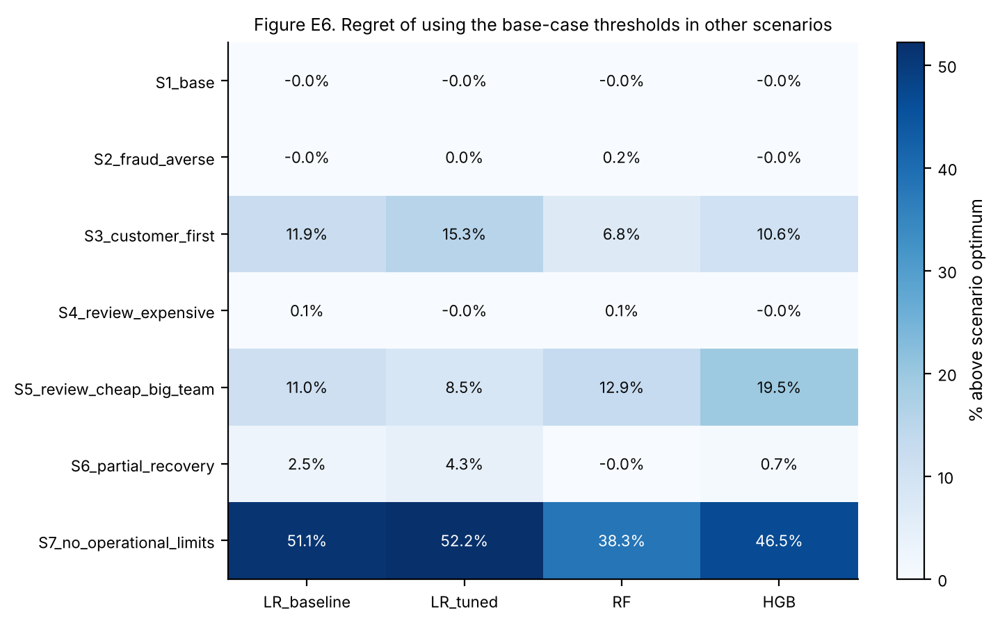

In [72]:
# (3) regret matrix: base-case thresholds applied in every scenario vs that scenario's own optimum, for every model
reg = []
for m in MODELS_E:
    a1, a2, _ = opt_for(m, BASE_SC)
    for sname, sc in SC.items():
        t1, t2, c = opt_for(m, sc); kept = cost_at(m, sc, a1, a2); d05 = cost_at(m, sc, .5, .5); aall = fc.row_costs(AMT, YE, sc)[0].sum() / N * 1000
        reg.append(dict(model=m, scenario=sname, own_optimum=c, base_thresholds_cost=kept, regret=kept - c, regret_pct=100 * (kept - c) / c, default_050_cost=d05, approve_all_cost=aall,
                        base_thresholds_beats_default=kept < d05, own_t_review=t1, own_t_block=t2))
reg = pd.DataFrame(reg); display(reg[reg.model == CHOSEN].drop(columns="model").round(3))
print("Regret of carrying the base-case thresholds into other scenarios (% above that scenario's own optimum), all models:"); display(reg.pivot(index="scenario", columns="model", values="regret_pct").reindex(list(SC))[MODELS_E].round(2))
fig, ax = plt.subplots(figsize=(7.5, 4.6)); pv = reg.pivot(index="scenario", columns="model", values="regret_pct").reindex(list(SC))[MODELS_E]
im = ax.imshow(pv.values, cmap="Blues", vmin=0, aspect="auto")
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]): ax.text(j, i, f"{pv.values[i, j]:.1f}%", ha="center", va="center", fontsize=8, color="white" if pv.values[i, j] > .6 * np.nanmax(pv.values) else INK)
ax.set_xticks(range(pv.shape[1])); ax.set_xticklabels(pv.columns); ax.set_yticks(range(pv.shape[0])); ax.set_yticklabels(pv.index, fontsize=8); ax.grid(False); plt.colorbar(im, ax=ax, label="% above scenario optimum")
ax.set_title("Figure E6. Regret of using the base-case thresholds in other scenarios", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "E06_threshold_regret.png", dpi=130, bbox_inches="tight"); plt.show()

      t_review  t_block       cost
mean     0.158    0.209  14196.177
std      0.004    0.009   1038.224
5%       0.153    0.203  12624.508
50%      0.157    0.208  14171.626
95%      0.161    0.215  15966.835


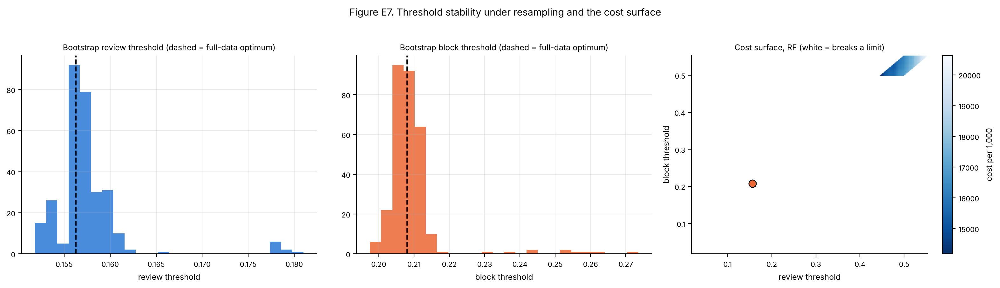

In [73]:
# (4) bootstrap stability of the optimal thresholds (resample transactions; both prediction repeats follow the same rows)
rng = np.random.default_rng(SEED_E); bt = []
cA, cR, cB = fc.row_costs(AMT, YE, BASE_SC); S = SCORES[CHOSEN]
for b in range(300):
    idx = rng.integers(0, N, N); Sb = [s[idx] for s in S]; g = fc.make_grid(Sb); surf = fc.surface(Sb, (cA[idx], cR[idx], cB[idx]), g)
    t1, t2, c = fc.best_pair(surf, g, "three_way", BASE_SC.review_capacity, BASE_SC.max_block_rate); bt.append((t1, t2, c / N * 1000))
bt = pd.DataFrame(bt, columns=["t_review", "t_block", "cost"]); bt["t_block"] = bt.t_block.replace(np.inf, np.nan)
print(bt.describe(percentiles=[.05, .5, .95]).round(3).loc[["mean", "std", "5%", "50%", "95%"]])
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for a, col, c, t in [(ax[0], "t_review", BLUE, "review threshold"), (ax[1], "t_block", ORANGE, "block threshold")]:
    a.hist(bt[col].dropna(), bins=24, color=c, alpha=.85); a.axvline(T1 if col == "t_review" else T2, color=INK, ls="--"); a.set_title(f"Bootstrap {t} (dashed = full-data optimum)", fontsize=9); a.set_xlabel(t)
S0 = SCORES[CHOSEN]; g = fc.make_grid(S0); surf = fc.surface(S0, fc.row_costs(AMT, YE, BASE_SC), g)
cost, rr, br = surf; cost = np.where((rr > BASE_SC.review_capacity + 1e-9) | (br[None, :] > BASE_SC.max_block_rate + 1e-9), np.inf, cost) / N * 1000
Z = np.where(np.isfinite(cost), cost, np.nan); lo_ix = slice(0, len(g) - 1)
im = ax[2].imshow(Z[lo_ix, lo_ix].T, origin="lower", cmap="Blues_r", aspect="auto", extent=[g[0], g[-2], g[0], g[-2]]); ax[2].scatter([T1], [T2 if np.isfinite(T2) else g[-2]], color=ORANGE, s=70, edgecolors=INK, zorder=3)
ax[2].set_xlabel("review threshold"); ax[2].set_ylabel("block threshold"); ax[2].set_title(f"Cost surface, {CHOSEN} (white = breaks a limit)", fontsize=9); ax[2].grid(False); plt.colorbar(im, ax=ax[2], label="cost per 1,000")
fig.suptitle("Figure E7. Threshold stability under resampling and the cost surface", y=1.02, fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "E07_threshold_bootstrap_and_surface.png", dpi=130, bbox_inches="tight"); plt.show()

### E6. What do the operational limits cost, and what happens to review workload when recall rises?
The review team size and the block guardrail are business choices. This grid shows the optimal cost for each combination (base cost parameters, chosen model). The second table is the workload question: what share of transactions must be sent for a human look to catch a given share of the frauds, using the model's ranking alone.

max_block_rate,0.02,0.05,0.10,0.20,1.00
review_capacity,,,,,
0.000,19692.0,18357.0,16833.0,15183.0,15183.0
0.025,18415.0,17482.0,16415.0,15079.0,14941.0
0.050,17374.0,16420.0,15577.0,14696.0,14571.0
0.100,15964.0,15122.0,14183.0,14142.0,14142.0
0.150,14806.0,13727.0,13668.0,13440.0,13440.0
0.200,13492.0,13231.0,12951.0,12951.0,12951.0
0.300,12375.0,12239.0,12239.0,12239.0,12239.0
0.500,10968.0,10763.0,10763.0,10763.0,10763.0
1.000,10256.0,10256.0,10256.0,10256.0,10256.0


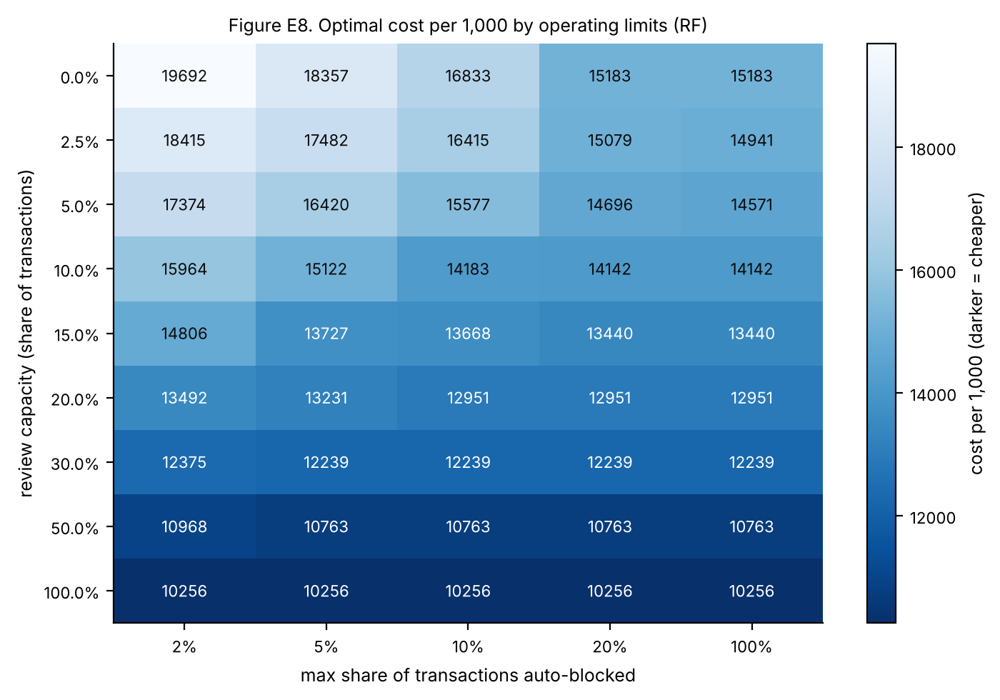

In [74]:
caps_r = [0, .025, .05, .10, .15, .20, .30, .50, 1.0]; caps_b = [.02, .05, .10, .20, 1.0]
grid_rows = []
for cr in caps_r:
    for cb in caps_b:
        sc2 = BASE_SC.with_(name="cap", review_capacity=cr, max_block_rate=cb); t1, t2, c = opt_for(CHOSEN, sc2)
        s = fc.policy_summary(SCORES[CHOSEN], YE, AMT, sc2, t1, t2); grid_rows.append(dict(review_capacity=cr, max_block_rate=cb, cost_per_1000=c, t_review=t1, t_block=t2, review_rate=s["review_rate"], block_rate=s["block_rate"], fraud_capture=s["fraud_capture"]))
cg = pd.DataFrame(grid_rows); pc = cg.pivot(index="review_capacity", columns="max_block_rate", values="cost_per_1000"); display(pc.round(0))
fig, ax = plt.subplots(figsize=(7.2, 5)); im = ax.imshow(pc.values, cmap="Blues_r", aspect="auto")
for i in range(pc.shape[0]):
    for j in range(pc.shape[1]): ax.text(j, i, f"{pc.values[i, j]:.0f}", ha="center", va="center", fontsize=8, color="white" if pc.values[i, j] < np.nanmin(pc.values) + .4 * (np.nanmax(pc.values) - np.nanmin(pc.values)) else INK)
ax.set_xticks(range(pc.shape[1])); ax.set_xticklabels([f"{c:.0%}" for c in pc.columns]); ax.set_yticks(range(pc.shape[0])); ax.set_yticklabels([f"{r:.1%}" for r in pc.index]); ax.grid(False)
ax.set_xlabel("max share of transactions auto-blocked"); ax.set_ylabel("review capacity (share of transactions)"); ax.set_title(f"Figure E8. Optimal cost per 1,000 by operating limits ({CHOSEN})", fontsize=9); plt.colorbar(im, ax=ax, label="cost per 1,000 (darker = cheaper)")
plt.tight_layout(); plt.savefig(FIG / "E08_operating_limits_grid.png", dpi=130, bbox_inches="tight"); plt.show()

,model,target_recall,flagged_share,flagged_per_1000,precision,extra_flagged_per_fraud_found,review_cost_per_1000_at_base
10,RF,0.2,0.075,75.000,0.328,3.093,450.0
11,RF,0.4,0.205,204.583,0.237,4.218,1227.5
12,RF,0.6,0.414,413.750,0.176,5.687,2482.5
13,RF,0.8,0.615,614.583,0.158,6.336,3687.5
14,RF,0.9,0.778,777.500,0.140,7.125,4665.0


Share of transactions that must be flagged to reach a target recall (rows = target recall):


model,LR_baseline,LR_tuned,RF,HGB
target_recall,,,,
0.2,0.091,0.086,0.075,0.084
0.4,0.222,0.234,0.205,0.220
0.6,0.354,0.432,0.414,0.403
0.8,0.622,0.621,0.615,0.640
0.9,0.805,0.811,0.778,0.788


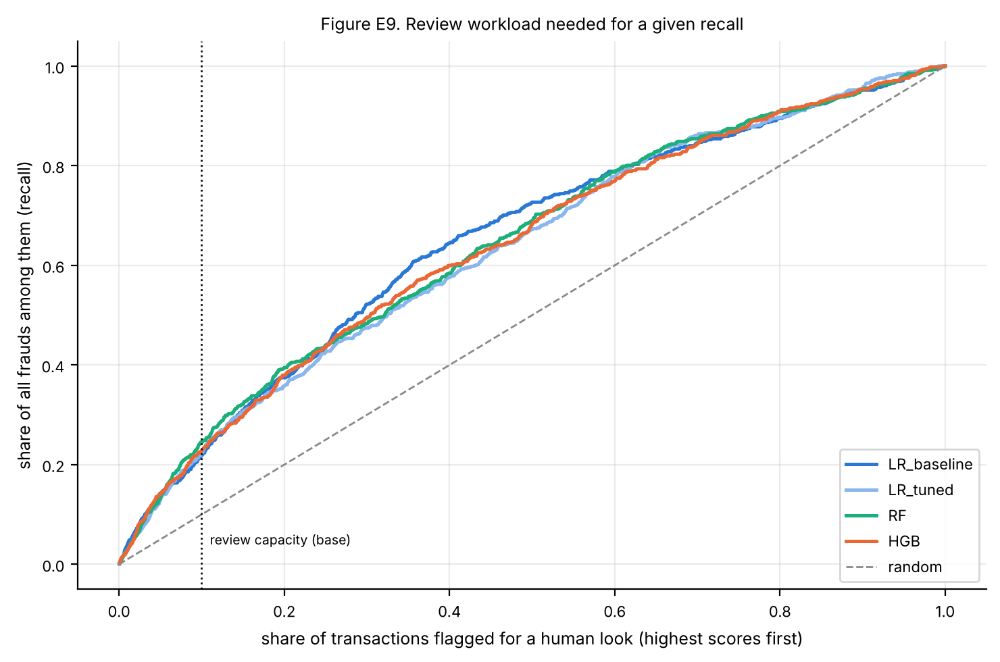

In [75]:
def recall_curve(model):
    rec, prec = [], []
    for s in SCORES[model]:
        o = np.argsort(-s, kind="stable"); cf = np.cumsum(YE[o]); k = np.arange(1, N + 1); rec.append(cf / YE.sum()); prec.append(cf / k)
    return np.mean(rec, axis=0), np.mean(prec, axis=0)
wl = []
for m in MODELS_E:
    rec, prec = recall_curve(m)
    for tr in [.2, .4, .6, .8, .9]:
        k = int(np.argmax(rec >= tr)) + 1; wl.append(dict(model=m, target_recall=tr, flagged_share=k / N, flagged_per_1000=k / N * 1000, precision=prec[k - 1], extra_flagged_per_fraud_found=k / (tr * YE.sum()), review_cost_per_1000_at_base=BASE_SC.review_cost * k / N * 1000))
wl = pd.DataFrame(wl); display(wl[wl.model.isin([CHOSEN, "RF"])].round(3))
print("Share of transactions that must be flagged to reach a target recall (rows = target recall):"); display(wl.pivot(index="target_recall", columns="model", values="flagged_share")[MODELS_E].round(3))
fig, ax = plt.subplots(figsize=(7.5, 5)); xs = np.arange(1, N + 1) / N
for m in MODELS_E: rec, _ = recall_curve(m); ax.plot(xs, rec, color=MCE[m], lw=1.8, label=m)
ax.plot([0, 1], [0, 1], color=GREY, ls="--", lw=1, label="random"); ax.axvline(BASE_SC.review_capacity, color=INK, ls=":", lw=1); ax.text(BASE_SC.review_capacity + .01, .04, "review capacity (base)", fontsize=7)
ax.set_xlabel("share of transactions flagged for a human look (highest scores first)"); ax.set_ylabel("share of all frauds among them (recall)"); ax.legend(fontsize=8)
ax.set_title("Figure E9. Review workload needed for a given recall", fontsize=9); plt.tight_layout(); plt.savefig(FIG / "E09_workload_vs_recall.png", dpi=130, bbox_inches="tight"); plt.show()

### E7. Findings

**1. The default 0.50 rule is almost the same as approving everything.** Only 0.1% to 1.1% of transactions reach a probability of 0.50 (RF 0.13%, LR baseline 1.1%), so the rule blocks only 1 to 11 transactions per 1,000 and catches under 5% of frauds. Its cost per 1,000 transactions (base scenario, about 20,440 to 20,660) is within about 1% of approving everything (20,677). Accuracy-optimal thresholds do the same, because with 12% fraud the most "accurate" action is to predict "legitimate" almost always.

**2. Cost-based thresholds help a lot.** In the base scenario S1, the cost-optimal three-way policy (approve / review / block) cuts honest expected cost versus the default 0.50 rule by 18% (LR baseline), 18% (LR tuned), 24% (HGB) and 31% (RF). RF falls from 20,657 to 14,264 per 1,000 and captures 36% of frauds, against about 0.2% at 0.50. Across all seven scenarios the saving for RF is 19% to 49%. "Honest" means thresholds were chosen on training folds and scored on unseen rows; for RF the in-sample optimum (14,183) and honest cost (14,264) differ by only 0.6%, so the saving is not an artefact of tuning on the scored rows. Absolute cost intervals are wide (about +/- 2,000 per 1,000) because a few large frauds dominate; the model comparisons below use paired differences, which are tighter.

**3. The best ROC-AUC model is not the cheapest.** LR baseline has the highest ROC-AUC (Part D) but RF is cheaper in all 7 scenarios, with a paired bootstrap interval that excludes zero in each one (base: about 2,400 per 1,000 cheaper). A likely reason (consistent with Part D, where RF had the best recall in the top 10%): RF ranks the very top of the list best, and cost-sensitive policy only uses the top 10% to 20% of scores, where ROC-AUC (averaged over all thresholds) says little. HGB is cheaper than the baseline in all seven scenarios by point estimate, but its interval excludes zero only in S5. LR tuned is not reliably different from the baseline anywhere. **RF is therefore the production candidate carried into Parts F to K**, which replaces the Part D default (LR baseline). Because the Part D differences in PR-AUC were not significant, this choice rests on the cost evidence alone and is flagged as such.

**4. Would a weaker model ever be preferable?** Not on cost here: RF is cheapest in every scenario. The ranking of the other three does change with the cost structure (LR tuned is slightly cheaper than the baseline in S3 and S6 but dearer in S1, S2, S4, S5 and S7), but those differences are inside the noise. The gaps between models shrink when false positives are expensive (S3, S6), so if the extra complexity or weaker transparency became a concern, the case for the simple baseline would be strongest under those assumptions.

**5. Thresholds are not equally sensitive to every assumption.** One-at-a-time re-optimisation (Figure E5) shows that the optimal thresholds barely move when review cost (2 to 15), review delay or wrong-decline rate change; they move a lot with the false-positive friction cost (RF block threshold 0.21 up to 0.55), the loss share, and above all the operating limits (review capacity and block-rate cap). Carrying the base thresholds into other scenarios costs little in S2, S4 and S6 (0% to 0.2% for RF) and more in S3 (7%), S5 (13%) and S7 (38%) (Figure E6). Bootstrap resampling of the base-case optimum gives thresholds that are tight (review 0.157 +/- 0.004, block 0.208 +/- 0.009), so the problem is mainly the cost and capacity assumptions, not sampling noise.

**6. Operating limits drive cost more than the cost figures do.** For RF, raising review capacity from 10% to 20% of traffic lowers cost from 14,183 to 12,951 per 1,000 at the same block cap, and removing all limits (S7) reaches about 10,260. With zero review capacity and a 10% block cap the cost is 16,833. The hand-off value of extra analysts is therefore quantifiable (Figure E8).

**7. Review workload versus recall.** The ranking is weak, so recall is expensive. For RF, flagging the top 7.5% of transactions finds 20% of frauds, 20% flagged finds 40%, 41% flagged finds 60%, 62% finds 80% and 78% finds 90% (Figure E9). The current 10% review capacity can reach only about a quarter of the frauds by review alone, which is why a block tier for the very top scores adds value.

**Caveats.** All money figures are hypothetical, so absolute costs are illustrative and the structure of the conclusions (ordering of policies, sensitivity of thresholds) matters more than the amounts. The textbook threshold FP/(FP+FN) = 0.135 only applies to calibrated probabilities; the model scores are not calibrated yet, so Part F revisits thresholds after calibration. Fraud prevalence (12%) is much higher than in real card portfolios, and 40 missing amounts were filled with the development median for cost accounting only. The hold-out set was not read in Part E.

### E8. Save the threshold and cost analysis (`05_threshold_cost_analysis.csv`)

In [76]:
COLS = ["analysis", "scenario", "model", "policy", "parameter", "value", "t_review", "t_block", "cost_per_1000_honest", "ci_low", "ci_high", "cost_per_1000_insample",
        "saving_vs_approve_all_pct", "saving_vs_default_pct", "review_rate", "block_rate", "fraud_capture", "block_precision", "regret", "note"]
parts = []
def add(analysis, d, **kw):
    d = d.copy(); d["analysis"] = analysis
    for k, v in kw.items(): d[k] = v
    parts.append(d)
sc_full = scen.merge(base_tbl[["scenario", "model", "policy", "ci_low", "ci_high"]], on=["scenario", "model", "policy"], how="left").rename(columns={"cost_honest": "cost_per_1000_honest", "cost_insample": "cost_per_1000_insample"})
add("policy_by_scenario", sc_full, note="honest cost = thresholds chosen on training folds, scored on unseen folds; ci only for base scenario")
add("ratio_sweep", sweep.rename(columns={"fn_multiplier": "value", "cost_per_1000": "cost_per_1000_insample", "optimal_threshold": "t_block"}), parameter="fn_cost_multiplier", policy="cost_opt_block_no_limits", scenario="ratio_sweep", note="theory_threshold and fn_fp_ratio in the notebook table")
add("tornado", torn.rename(columns={"cost_reoptimised": "cost_per_1000_insample", "end": "note", "cost_with_base_thresholds": "cost_base_thresholds"}), model=CHOSEN, policy="cost_opt_three_way", scenario="S1_base")
add("regret", reg.rename(columns={"own_optimum": "cost_per_1000_insample", "regret_pct": "value", "own_t_review": "t_review", "own_t_block": "t_block"}), policy="base_thresholds_in_scenario", parameter="regret_pct", note="value = % above the scenario's own optimum")
add("operating_limits", cg.rename(columns={"cost_per_1000": "cost_per_1000_insample", "review_capacity": "value", "max_block_rate": "regret"}), model=CHOSEN, policy="cost_opt_three_way", scenario="S1_base", parameter="review_capacity (value) x max_block_rate (regret column)")
add("recall_workload", wl.rename(columns={"target_recall": "value", "flagged_share": "review_rate", "precision": "block_precision"}), policy="flag_top_scores", parameter="target_recall")
out05 = pd.concat(parts, ignore_index=True)
for c in COLS:
    if c not in out05: out05[c] = np.nan
out05 = out05[COLS + [c for c in out05.columns if c not in COLS]]; out05.to_csv("05_threshold_cost_analysis.csv", index=False)
print("05_threshold_cost_analysis.csv:", out05.shape, "| analyses:", out05.analysis.value_counts().to_dict())
json.dump({"chosen_model": CHOSEN, "base_scenario": BASE_SC.as_dict(), "t_review": float(T1), "t_block": (None if not np.isfinite(T2) else float(T2)), "in_sample_cost_per_1000": float(C_BASE)}, open(OUT / "E_chosen_policy.json", "w"), indent=2)
print("Part E figures:", sorted(p.name for p in FIG.glob("E*.png")), "| hold-out rows read: none")

05_threshold_cost_analysis.csv: (257, 34) | analyses: {'policy_by_scenario': 112, 'operating_limits': 45, 'ratio_sweep': 32, 'regret': 28, 'tornado': 20, 'recall_workload': 20}
Part E figures: ['E01_cost_curves_and_policies.png', 'E02_scenarios.png', 'E03_model_cost_comparison.png', 'E04_threshold_vs_cost_ratio.png', 'E05_tornado.png', 'E06_threshold_regret.png', 'E07_threshold_bootstrap_and_surface.png', 'E08_operating_limits_grid.png', 'E09_workload_vs_recall.png'] | hold-out rows read: none


---
## Part F. Probability Calibration

**Goal:** check whether a predicted "0.20" really means "about 1 in 5 of these transactions is fraud", repair it if not, and show why that matters for Approve / Review / Block decisions.

| Task F requirement | Section |
|---|---|
| Calibration curves and Brier score | F2 |
| Compare at least two calibration approaches (Platt scaling and isotonic regression) where technically appropriate | F3, F4 |
| Why calibrated probabilities matter for operational fraud decisions | F5, F6, F7 |

**Rules and design (fixed before any calibrated number was computed)**
1. **Calibrators are fitted on out-of-fold (OOF) scores only**, i.e. scores from Part D's nested cross-validation, where every development row was scored by a model that never saw it. Fitting a calibrator on a model's own training predictions would be meaningless (a tree ensemble is over-confident on rows it has memorised).
2. **Calibration quality is measured by cross-fitting**: a calibrator is fitted on 80% of the rows' OOF scores and applied to the other 20%, repeated 10 times with different splits (and for both of Part D's prediction repeats). No calibrated probability is ever scored on rows that trained its calibrator. The hold-out set is not read.
3. **Metrics**: Brier score (mean squared error of the probability; lower is better), log loss, expected calibration error (ECE, 10 equal-frequency bins), and the calibration intercept and slope (perfect = 0 and 1; slope above 1 = under-confident, below 1 = over-confident). Equal-frequency bins are used because only 12% of rows are frauds, so equal-width bins would be almost empty.
4. **Two calibrators**: *Platt scaling* (a 2-parameter logistic curve on the logit of the score; smooth, monotone) and *isotonic regression* (any non-decreasing step function; flexible but data hungry). Both are monotone, so neither can reorder transactions much; Platt cannot change the ranking at all.
5. **Choice rule, written now:** Platt is the default calibration layer because it has two parameters (safe with 291 frauds) and cannot change the ranking. Isotonic replaces it only if its cross-fitted Brier score **and** log loss are lower than Platt's with a paired-bootstrap 95% interval that excludes zero for the chosen production model (Random Forest, from Part E).
6. **Discrimination is not calibration.** A model can rank perfectly and still give silly probabilities, or give honest probabilities and rank badly. Both are checked, separately.

### F1. Setup: out-of-fold scores of the four candidate models

In [77]:
import fraud_calibration as fcal
import fraud_costs as fc
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy import stats
SEED_F = 42
oofF = pd.read_csv(OUT / "D_oof_predictions.csv"); assert len(oofF) == 2400 and set(oofF.transaction_id) == set(dev[ID])
YF = oofF.fraud.to_numpy(); NF = len(YF); BASE_RATE = YF.mean()
MODELS_F = ["LR_baseline", "LR_tuned", "RF", "HGB"]
SF = {m: [oofF[f"p_{m}_r0"].to_numpy(), oofF[f"p_{m}_r1"].to_numpy()] for m in MODELS_F}     # two prediction repeats per model
meta = oofF[["transaction_id"]].merge(df, on=ID, how="left")
amtF = meta.transaction_amount.fillna(meta.transaction_amount.median()).to_numpy()
NO_SKILL_BRIER = BASE_RATE * (1 - BASE_RATE)
print(f"{NF} development rows, {int(YF.sum())} frauds (base rate {BASE_RATE:.3f}); hold-out rows read: none")
print(f"Brier score of a model that always predicts the base rate (no skill): {NO_SKILL_BRIER:.4f}")
print("Mean predicted probability vs base rate:", {m: round(float(np.mean(SF[m])), 3) for m in MODELS_F})

2400 development rows, 291 frauds (base rate 0.121); hold-out rows read: none
Brier score of a model that always predicts the base rate (no skill): 0.1065
Mean predicted probability vs base rate: {'LR_baseline': 0.122, 'LR_tuned': 0.144, 'RF': 0.12, 'HGB': 0.12}


### F2. Are the raw probabilities calibrated?
First look at the scores exactly as the models produced them (out-of-fold, so honest). The table gives each metric with a 95% bootstrap interval (rows resampled). The **Brier skill score** is the share of the no-skill Brier score the model removes (0 = no better than guessing the base rate).

In [78]:
def raw_metrics_boot(m, B=400, seed=0):
    rng = np.random.default_rng(seed); n = NF
    def met(idx):
        r = [fcal.metric_row(YF[idx], s[idx]) for s in SF[m]]; return pd.DataFrame(r).mean()
    point = met(np.arange(n)); bs = pd.DataFrame([met(rng.integers(0, n, n)) for _ in range(B)])
    return point, bs.quantile(.025), bs.quantile(.975)
def hl_pvalue(y, p, g=10):
    t = fcal.reliability_table(y, p, g); E = t.n * t.mean_predicted; V = t.n * t.mean_predicted * (1 - t.mean_predicted)
    chi2 = float(np.sum((t.n * t.observed_rate - E) ** 2 / V)); return float(1 - stats.chi2.cdf(chi2, g - 2))
rows, RAWM = [], {}
for m in MODELS_F:
    pt, lo, hi = raw_metrics_boot(m); RAWM[m] = (pt, lo, hi)
    rows.append(dict(model=m, brier=f"{pt.brier:.4f} [{lo.brier:.4f}, {hi.brier:.4f}]", brier_skill_score=round(1 - pt.brier / NO_SKILL_BRIER, 4),
                     log_loss=f"{pt.log_loss:.4f}", ECE=f"{pt.ece:.4f}",
                     cal_intercept=f"{pt.cal_intercept:+.2f} [{lo.cal_intercept:+.2f}, {hi.cal_intercept:+.2f}]",
                     cal_slope=f"{pt.cal_slope:.2f} [{lo.cal_slope:.2f}, {hi.cal_slope:.2f}]",
                     HL_p_value=round(float(np.mean([hl_pvalue(YF, s) for s in SF[m]])), 3)))
RAW_TABLE = pd.DataFrame(rows).set_index("model"); display(RAW_TABLE)
rng_f = np.random.default_rng(SEED_F); floor = {m: float(np.mean([fcal.ece((rng_f.random(NF) < SF[m][0]).astype(int), SF[m][0]) for _ in range(300)])) for m in MODELS_F}
print("ECE noise floor (expected ECE if each model's probabilities were EXACTLY right, simulated 300 times with 2,400 rows):", {m: round(v, 4) for m, v in floor.items()})
print("ECE has a positive bias with few frauds, so it is only meaningful relative to that floor; no bootstrap interval is shown for it.")
print("Calibration slope < 1: the model is OVER-confident (probabilities too spread out); slope > 1: UNDER-confident (too close to the base rate).")
print("HL_p_value is a Hosmer-Lemeshow style test (small p = calibration problem); with 291 frauds it has limited power, so intervals above are the main evidence.")

,brier,brier_skill_score,log_loss,ECE,cal_intercept,cal_slope,HL_p_value
model,,,,,,,
LR_baseline,"0.1028 [0.0936, 0.1117]",0.0351,0.3543,0.0278,"-0.61 [-0.93, -0.27]","0.66 [0.53, 0.81]",0.000
LR_tuned,"0.1035 [0.0953, 0.1120]",0.0283,0.3563,0.0268,"-0.17 [-0.57, +0.28]","1.02 [0.81, 1.26]",0.008
RF,"0.1020 [0.0931, 0.1110]",0.0424,0.3508,0.0156,"+0.10 [-0.34, +0.57]","1.05 [0.83, 1.28]",0.352
HGB,"0.1023 [0.0931, 0.1112]",0.0402,0.3520,0.0144,"-0.19 [-0.61, +0.24]","0.89 [0.69, 1.12]",0.338


ECE noise floor (expected ECE if each model's probabilities were EXACTLY right, simulated 300 times with 2,400 rows): {'LR_baseline': 0.0154, 'LR_tuned': 0.017, 'RF': 0.0159, 'HGB': 0.016}
ECE has a positive bias with few frauds, so it is only meaningful relative to that floor; no bootstrap interval is shown for it.
Calibration slope < 1: the model is OVER-confident (probabilities too spread out); slope > 1: UNDER-confident (too close to the base rate).
HL_p_value is a Hosmer-Lemeshow style test (small p = calibration problem); with 291 frauds it has limited power, so intervals above are the main evidence.


In [79]:
dec = pd.DataFrame({m: fcal.brier_decomposition(YF, SF[m][0]) for m in MODELS_F}).T; dec["brier"] = dec.reliability - dec.resolution + dec.uncertainty
print("Murphy decomposition of the Brier score (repeat 0): Brier = reliability (calibration error, lower is better) - resolution (separation, higher is better) + uncertainty (fixed by the base rate)")
display(dec.round(5))

Murphy decomposition of the Brier score (repeat 0): Brier = reliability (calibration error, lower is better) - resolution (separation, higher is better) + uncertainty (fixed by the base rate)


,reliability,resolution,uncertainty,brier
LR_baseline,0.00153,0.00451,0.10655,0.10357
LR_tuned,0.00121,0.00369,0.10655,0.10407
RF,0.00030,0.00478,0.10655,0.10207
HGB,0.00031,0.00389,0.10655,0.10298


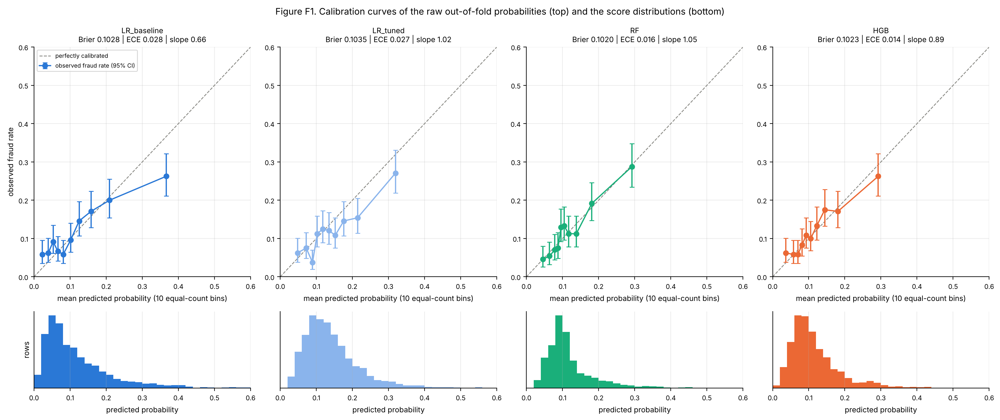

In [80]:
fig, ax = plt.subplots(2, 4, figsize=(17, 7.2), gridspec_kw=dict(height_ratios=[3, 1]))
COL = {"LR_baseline": BLUE, "LR_tuned": "#8ab4ec", "RF": "#1aaf7a", "HGB": ORANGE}
for j, m in enumerate(MODELS_F):
    t = fcal.reliability_table(YF, SF[m][0], 10); a = ax[0, j]
    a.plot([0, .6], [0, .6], color=GREY, lw=1, ls="--", label="perfectly calibrated")
    a.errorbar(t.mean_predicted, t.observed_rate, yerr=[t.observed_rate - t.ci_low, t.ci_high - t.observed_rate], fmt="o-", color=COL[m], ms=6, lw=1.5, capsize=3, label="observed fraud rate (95% CI)")
    pt = RAWM[m][0]; a.set_title(f"{m}\nBrier {pt.brier:.4f} | ECE {pt.ece:.3f} | slope {pt.cal_slope:.2f}", fontsize=9)
    a.set_xlim(0, .6); a.set_ylim(0, .6); a.set_xlabel("mean predicted probability (10 equal-count bins)")
    if j == 0: a.set_ylabel("observed fraud rate"); a.legend(fontsize=7, loc="upper left")
    ax[1, j].hist(SF[m][0], bins=np.linspace(0, .6, 31), color=COL[m]); ax[1, j].set_xlim(0, .6); ax[1, j].set_xlabel("predicted probability"); ax[1, j].set_yticks([])
    if j == 0: ax[1, j].set_ylabel("rows")
fig.suptitle("Figure F1. Calibration curves of the raw out-of-fold probabilities (top) and the score distributions (bottom)", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "F01_raw_calibration_curves.png", dpi=130, bbox_inches="tight"); plt.show()

### F3. Two calibration methods, evaluated by cross-fitting
For every model and every method the same 20 cross-fitted probability vectors are scored (10 CV repeats x 2 prediction repeats). "Raw" is the uncalibrated OOF score. Differences are paired by transaction (bootstrap over rows).

In [81]:
METHODS = ["raw", "platt", "isotonic"]
CF = {m: {"raw": SF[m], "platt": fcal.crossfit(SF[m], YF, "platt", seed=SEED_F), "isotonic": fcal.crossfit(SF[m], YF, "isotonic", seed=SEED_F)} for m in MODELS_F}
rows = []
for m in MODELS_F:
    for meth in METHODS:
        vec = CF[m][meth]; r = fcal.mean_metrics(YF, vec)
        r.update(roc_auc=np.mean([roc_auc_score(YF, v) for v in vec]), pr_auc=np.mean([average_precision_score(YF, v) for v in vec]),
                 distinct_values=float(np.mean([len(np.unique(np.round(v, 6))) for v in vec])))
        rows.append(dict(model=m, method=meth, **r))
CFT = pd.DataFrame(rows); display(CFT.round(4).set_index(["model", "method"]))
print("Platt is monotone, so its ROC-AUC / PR-AUC should equal the raw ones except for the tiny effect of fitting on different folds; isotonic collapses scores into plateaus ('distinct_values').")

brier  log_loss     ece  cal_intercept  cal_slope  roc_auc  pr_auc  distinct_values
model       method                                                                                        
LR_baseline raw       0.1028    0.3543  0.0278        -0.6126     0.6639   0.6696  0.2314          2390.00
            platt     0.1019    0.3503  0.0187        -0.0326     0.9827   0.6685  0.2284          2384.55
            isotonic  0.1024    0.3532  0.0171        -0.3933     0.7884   0.6597  0.2131            82.40
LR_tuned    raw       0.1035    0.3563  0.0268        -0.1681     1.0205   0.6507  0.2131          2385.50
            platt     0.1031    0.3541  0.0137        -0.0444     0.9771   0.6491  0.2113          2381.15
            isotonic  0.1037    0.3589  0.0164        -0.5426     0.7120   0.6384  0.1963            87.55
RF          raw       0.1020    0.3508  0.0156         0.1039     1.0495   0.6611  0.2296          2383.00
            platt     0.1021    0.3513  0.0167        -0.0424     0.9779   0.6596  0.2258          2381.25
            isotonic  0.1027    0.3569  0.0190        -0.4897     0.7390   0.6456  0.2081            80.80
HGB         raw       0.1023    0.3520  0.0144        -0.1910     0.8899   0.6564  0.2264          2379.00
            platt     0.1024    0.3522  0.0135        -0.0361     0.9810   0.6551  0.2222          2382.10
            isotonic  0.1026    0.3561  0.0169        -0.4720     0.7487   0.6405  0.2123            76.40

Platt is monotone, so its ROC-AUC / PR-AUC should equal the raw ones except for the tiny effect of fitting on different folds; isotonic collapses scores into plateaus ('distinct_values').


In [82]:
rows = []
for m in MODELS_F:
    for a, b in [("platt", "raw"), ("isotonic", "raw"), ("isotonic", "platt")]:
        for loss in ["brier", "log_loss"]:
            d, lo, hi = fcal.paired_boot_diff(YF, CF[m][a], CF[m][b], loss=loss, B=2000, seed=SEED_F)
            rows.append(dict(model=m, comparison=f"{a} minus {b}", metric=loss, difference=d, ci_low=lo, ci_high=hi, significant=(lo > 0) or (hi < 0), better=("first" if d < 0 else "second")))
PD = pd.DataFrame(rows)
print("Paired differences in loss (negative = the first method is better). 'significant' = 95% interval excludes zero.")
display(PD.assign(difference=PD.difference.round(5), ci_low=PD.ci_low.round(5), ci_high=PD.ci_high.round(5)).set_index(["model", "comparison", "metric"]))
rf_iso = PD[(PD.model == "RF") & (PD.comparison == "isotonic minus platt")]
ISO_WINS = bool(((rf_iso.ci_high < 0)).all())
print(f"Choice rule: isotonic replaces Platt for the Random Forest only if it is significantly better on BOTH Brier and log loss. Isotonic wins: {ISO_WINS}  ==> calibration layer for the production model: {'isotonic' if ISO_WINS else 'Platt'}")
CHOSEN_CAL = "isotonic" if ISO_WINS else "platt"


Paired differences in loss (negative = the first method is better). 'significant' = 95% interval excludes zero.


difference   ci_low  ci_high  significant  better
model       comparison           metric                                                     
LR_baseline platt minus raw      brier       -0.00091 -0.00215  0.00036        False   first
                                 log_loss    -0.00406 -0.00813  0.00006        False   first
            isotonic minus raw   brier       -0.00035 -0.00136  0.00071        False   first
                                 log_loss    -0.00109 -0.00477  0.00248        False   first
            isotonic minus platt brier        0.00056 -0.00005  0.00121        False  second
                                 log_loss     0.00297  0.00007  0.00635         True  second
LR_tuned    platt minus raw      brier       -0.00047 -0.00123  0.00022        False   first
                                 log_loss    -0.00220 -0.00499  0.00042        False   first
            isotonic minus raw   brier        0.00016 -0.00057  0.00086        False  second
                                 log_loss     0.00259 -0.00158  0.00723        False  second
            isotonic minus platt brier        0.00063  0.00020  0.00105         True  second
                                 log_loss     0.00479  0.00189  0.00824         True  second
RF          platt minus raw      brier        0.00012 -0.00002  0.00025        False  second
                                 log_loss     0.00047  0.00008  0.00088         True  second
            isotonic minus raw   brier        0.00067  0.00002  0.00134         True  second
                                 log_loss     0.00607  0.00234  0.01053         True  second
            isotonic minus platt brier        0.00056 -0.00001  0.00116        False  second
                                 log_loss     0.00559  0.00200  0.00981         True  second
HGB         platt minus raw      brier        0.00011 -0.00015  0.00038        False  second
                                 log_loss     0.00022 -0.00071  0.00111        False  second
            isotonic minus raw   brier        0.00032 -0.00019  0.00085        False  second
                                 log_loss     0.00405  0.00138  0.00717         True  second
            isotonic minus platt brier        0.00021 -0.00042  0.00086        False  second
                                 log_loss     0.00383  0.00096  0.00725         True  second

Choice rule: isotonic replaces Platt for the Random Forest only if it is significantly better on BOTH Brier and log loss. Isotonic wins: False  ==> calibration layer for the production model: Platt


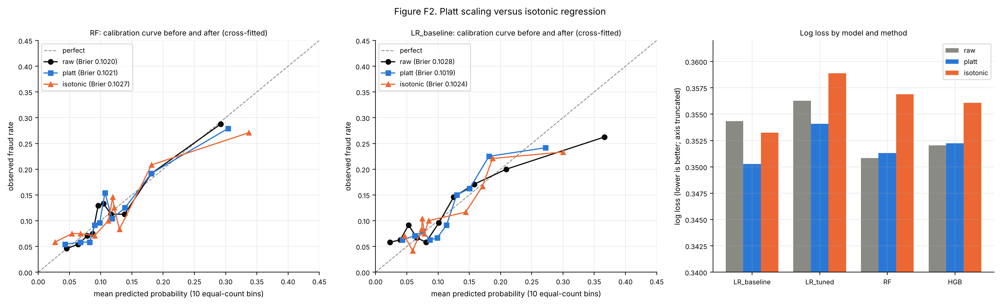

In [83]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5.2))
for a, m in zip(ax[:2], ["RF", "LR_baseline"]):
    a.plot([0, .45], [0, .45], color=GREY, ls="--", lw=1, label="perfect")
    for meth, c, mk in [("raw", INK, "o"), ("platt", BLUE, "s"), ("isotonic", ORANGE, "^")]:
        v = CF[m][meth][0] if meth != "raw" else SF[m][0]; t = fcal.reliability_table(YF, v, 10)
        a.plot(t.mean_predicted, t.observed_rate, marker=mk, color=c, lw=1.4, ms=6, label=f"{meth} (Brier {np.mean([fcal.brier(YF, x) for x in (CF[m][meth] if meth != 'raw' else SF[m])]):.4f})")
    a.set_xlim(0, .45); a.set_ylim(0, .45); a.set_xlabel("mean predicted probability (10 equal-count bins)"); a.set_ylabel("observed fraud rate"); a.set_title(f"{m}: calibration curve before and after (cross-fitted)", fontsize=9); a.legend(fontsize=8)
w = .26; x = np.arange(len(MODELS_F))
for k, (meth, c) in enumerate([("raw", GREY), ("platt", BLUE), ("isotonic", ORANGE)]):
    ax[2].bar(x + (k - 1) * w, [CFT[(CFT.model == m) & (CFT.method == meth)].log_loss.iloc[0] for m in MODELS_F], w, color=c, label=meth)
ax[2].set_xticks(x); ax[2].set_xticklabels(MODELS_F, fontsize=8); ax[2].set_ylim(.340, .362); ax[2].set_ylabel("log loss (lower is better; axis truncated)"); ax[2].set_title("Log loss by model and method", fontsize=9); ax[2].legend(fontsize=8)
fig.suptitle("Figure F2. Platt scaling versus isotonic regression", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "F02_platt_vs_isotonic.png", dpi=130, bbox_inches="tight"); plt.show()

### F4. Is isotonic technically appropriate here? How much data does each calibrator need?
Isotonic regression has one free value per plateau and no shape assumption, so with only 291 frauds it can over-fit its calibration data and look worse on new rows. This experiment fits each calibrator on a growing share of the rows and scores it on 20% of rows it never saw (200 random splits, Random Forest and Logistic Regression baseline scores).

In [84]:
def learning_curve(m, fracs=(.1, .2, .35, .5, .75, 1.0), reps=200, seed=0):
    rng = np.random.default_rng(seed); s = SF[m][0]; out = []
    from sklearn.model_selection import StratifiedShuffleSplit
    for r, (pool, te) in enumerate(StratifiedShuffleSplit(reps, test_size=.2, random_state=seed).split(s, YF)):
        for f in fracs:
            tr = rng.choice(pool, int(len(pool) * f), replace=False)
            if YF[tr].sum() < 5: continue
            raw_ll = fcal.log_loss(YF[te], s[te])
            for meth in ["platt", "isotonic"]:
                p = fcal.CALIBRATORS[meth]().fit(s[tr], YF[tr]).predict(s[te]); out.append(dict(model=m, frac=f, n_train=len(tr), frauds_train=int(YF[tr].sum()), method=meth, d_logloss=fcal.log_loss(YF[te], p) - raw_ll, d_brier=fcal.brier(YF[te], p) - fcal.brier(YF[te], s[te])))
    return pd.DataFrame(out)
LC = pd.concat([learning_curve(m) for m in ["RF", "LR_baseline"]])
lcs = LC.groupby(["model", "method", "n_train"]).agg(frauds=("frauds_train", "mean"), d_logloss=("d_logloss", "mean"), d_brier=("d_brier", "mean")).reset_index()
display(lcs.pivot_table(index=["model", "n_train"], columns="method", values="d_logloss").round(5))
print("d_logloss = held-out log loss after calibration MINUS before (negative = calibration helped).")

method               isotonic    platt
model       n_train                   
LR_baseline 192       0.03256 -0.00019
            384       0.01665 -0.00264
            672       0.00710 -0.00441
            960       0.00163 -0.00479
            1440     -0.00076 -0.00508
            1920     -0.00252 -0.00529
RF          192       0.03602  0.00495
            384       0.02115  0.00264
            672       0.01267  0.00126
            960       0.00771  0.00094
            1440      0.00584  0.00068
            1920      0.00413  0.00044

d_logloss = held-out log loss after calibration MINUS before (negative = calibration helped).


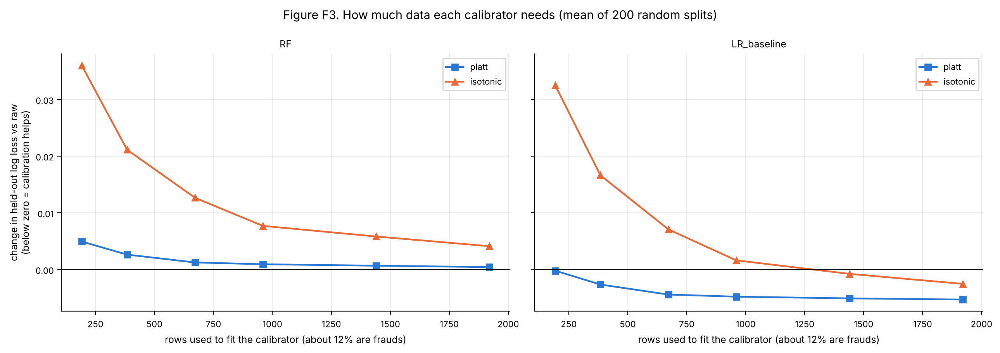

In [85]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for a, m in zip(ax, ["RF", "LR_baseline"]):
    for meth, c, mk in [("platt", BLUE, "s"), ("isotonic", ORANGE, "^")]:
        d = lcs[(lcs.model == m) & (lcs.method == meth)]; a.plot(d.n_train, d.d_logloss, marker=mk, color=c, lw=1.6, label=meth)
    a.axhline(0, color=INK, lw=.8); a.set_xlabel("rows used to fit the calibrator (about 12% are frauds)"); a.set_title(f"{m}", fontsize=9); a.legend(fontsize=8)
ax[0].set_ylabel("change in held-out log loss vs raw\n(below zero = calibration helps)")
fig.suptitle("Figure F3. How much data each calibrator needs (mean of 200 random splits)", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "F03_calibrator_learning_curve.png", dpi=130, bbox_inches="tight"); plt.show()

### F5. Why calibrated probabilities matter: the numbers an operations team actually uses
A risk score used only to rank transactions needs no calibration. But the moment someone says "this queue will contain about 24 frauds", "we expect to lose about 9,000 in the approved group" or "block above a 35% chance", the number must be a **probability**. This section uses the Part E policy for the Random Forest (base scenario: review above `t_review`, block above `t_block`, thresholds chosen in Part E on the raw scores) and compares what the raw and the calibrated probabilities *predict* for each action group with what *happened*.

In [86]:
import json
EPOL = json.load(open(OUT / "E_chosen_policy.json")); T1, T2 = EPOL["t_review"], EPOL["t_block"]
print(f"Part E thresholds on the raw RF score: review at {T1:.3f}, block at {T2:.3f}")
rep = len(CF["RF"]["platt"]) // 2
rows = []
for r in range(2):
    s = SF["RF"][r]; act = fc.apply_thresholds(s, T1, T2)
    pc = CF["RF"]["platt"][r * rep]; pi = CF["RF"]["isotonic"][r * rep]
    for a, name in [(0, "Approve"), (1, "Manual review"), (2, "Block")]:
        mk = act == a
        rows.append(dict(repeat=r, action=name, n=int(mk.sum()), actual_frauds=int(YF[mk].sum()), actual_rate=YF[mk].mean(),
                         raw_mean_p=s[mk].mean(), platt_mean_p=pc[mk].mean(), isotonic_mean_p=pi[mk].mean(),
                         actual_fraud_amount=float((amtF * YF)[mk].sum()), raw_expected_amount=float((amtF * s)[mk].sum()), platt_expected_amount=float((amtF * pc)[mk].sum())))
BAND = pd.DataFrame(rows).groupby("action").mean(numeric_only=True).loc[["Approve", "Manual review", "Block"]].drop(columns="repeat")
display(BAND.round(3))
for c in ["raw", "platt"]:
    err = (BAND[f"{c}_mean_p"] - BAND.actual_rate).abs().mean()
    print(f"{c}: mean absolute gap between predicted and actual fraud rate across the three groups = {err:.3f}")
tot = BAND[["actual_frauds"]].sum().iloc[0]
print(f"Expected frauds in the whole sample: actual {tot:.0f}; sum of raw probabilities {np.mean([SF['RF'][r].sum() for r in range(2)]):.0f}; sum of Platt probabilities {np.mean([CF['RF']['platt'][r * rep].sum() for r in range(2)]):.0f}")

Part E thresholds on the raw RF score: review at 0.156, block at 0.208


,n,actual_frauds,actual_rate,raw_mean_p,platt_mean_p,isotonic_mean_p,actual_fraud_amount,raw_expected_amount,platt_expected_amount
action,,,,,,,,,
Approve,1936.0,178.0,0.092,0.095,0.094,0.091,22714.025,21903.376,21888.496
Manual review,240.0,46.5,0.195,0.179,0.185,0.189,9880.850,9065.302,9305.320
Block,224.0,66.5,0.300,0.276,0.295,0.328,12664.375,14412.267,15242.098


raw: mean absolute gap between predicted and actual fraud rate across the three groups = 0.014
platt: mean absolute gap between predicted and actual fraud rate across the three groups = 0.006
Expected frauds in the whole sample: actual 291; sum of raw probabilities 289; sum of Platt probabilities 293


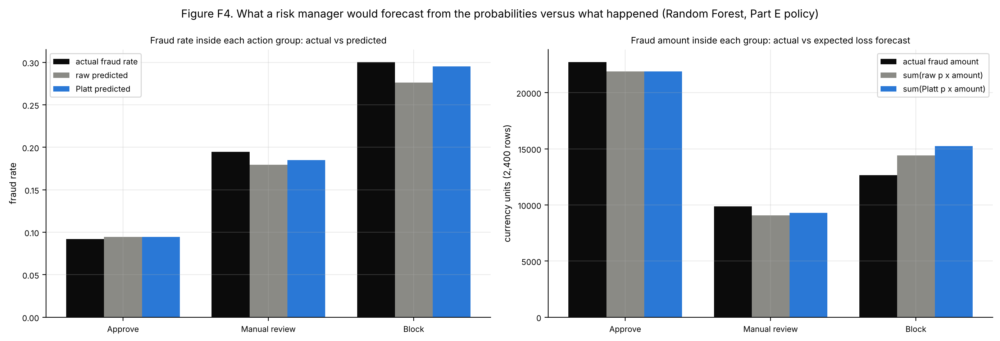

In [87]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8)); g = ["Approve", "Manual review", "Block"]; x = np.arange(3); w = .26
ax[0].bar(x - w, BAND.actual_rate, w, color=INK, label="actual fraud rate"); ax[0].bar(x, BAND.raw_mean_p, w, color=GREY, label="raw predicted"); ax[0].bar(x + w, BAND.platt_mean_p, w, color=BLUE, label="Platt predicted")
ax[0].set_xticks(x); ax[0].set_xticklabels(g); ax[0].set_ylabel("fraud rate"); ax[0].set_title("Fraud rate inside each action group: actual vs predicted", fontsize=9); ax[0].legend(fontsize=8)
ax[1].bar(x - w, BAND.actual_fraud_amount, w, color=INK, label="actual fraud amount"); ax[1].bar(x, BAND.raw_expected_amount, w, color=GREY, label="sum(raw p x amount)"); ax[1].bar(x + w, BAND.platt_expected_amount, w, color=BLUE, label="sum(Platt p x amount)")
ax[1].set_xticks(x); ax[1].set_xticklabels(g); ax[1].set_ylabel("currency units (2,400 rows)"); ax[1].set_title("Fraud amount inside each group: actual vs expected loss forecast", fontsize=9); ax[1].legend(fontsize=8)
fig.suptitle("Figure F4. What a risk manager would forecast from the probabilities versus what happened (Random Forest, Part E policy)", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "F04_operational_forecasts.png", dpi=130, bbox_inches="tight"); plt.show()

### F6. Calibrated probabilities turn costs into decisions
With a true probability `p`, the cheapest action for every transaction follows from the Part E cost matrix and the transaction's own amount: compute the expected cost of Approve, Review and Block and take the smallest. No threshold search, no labels needed at decision time. Two practical points:
* **Unconstrained break-even probabilities** (average error costs): review above `p1`, block above `p2` (table below). They only mean something if `p` is a real probability.
* **Operating limits without labels**: add a *shadow price* to each review and each block and raise it until the review share fits the team capacity and the block share fits the guardrail. This uses only the probabilities, amounts and cost table, so it can be re-tuned every day on the live score distribution.

Compared for the Random Forest (already close to calibrated) and the Logistic Regression baseline (clearly over-confident in F2): **searched thresholds** (Part E honest cost), the **expected-cost rule on raw scores** (treated as if they were probabilities), and the **same rule on cross-fitted Platt / isotonic probabilities**. The honest question is whether calibration makes the probability-based rule work.

In [88]:
cost_tab = pd.read_csv("05_threshold_cost_analysis.csv"); cost_tab = cost_tab[(cost_tab.analysis == "policy_by_scenario") & (cost_tab.policy == "cost_opt_three_way")]
def rule_cost(p_vec, sc):
    costs = np.column_stack(fc.row_costs(amtF, YF, sc)); act, lam, mu = fcal.capped_bayes_actions(p_vec, amtF, sc)
    return costs[np.arange(NF), act], act
rows, ROWC, SROW = [], {}, {}
for m in ["RF", "LR_baseline"]:
    for name, sc in fc.SCENARIOS.items():
        searched = float(cost_tab[(cost_tab.model == m) & (cost_tab.scenario == name)].cost_per_1000_honest.iloc[0])
        r_raw = [rule_cost(s, sc) for s in SF[m]]; r_pl = [rule_cost(v, sc) for v in CF[m]["platt"]]; r_is = [rule_cost(v, sc) for v in CF[m]["isotonic"]]
        ROWC[(m, name)] = (np.mean([c for c, _ in r_raw], axis=0), np.mean([c for c, _ in r_pl], axis=0))
        srow, _ = fc.honest_row_costs(SF[m], YF, amtF, sc, fc.chooser_cost("three_way", sc, amtF, YF), n_cv_repeats=5); SROW[(m, name)] = srow
        rows.append(dict(model=m, scenario=name, searched_thresholds=searched, rule_on_raw=ROWC[(m, name)][0].mean() * 1000, rule_on_platt=ROWC[(m, name)][1].mean() * 1000, rule_on_isotonic=np.mean([c for c, _ in r_is], axis=0).mean() * 1000,
                         review_rate_platt=np.mean([(a == 1).mean() for _, a in r_pl]), block_rate_platt=np.mean([(a == 2).mean() for _, a in r_pl]), review_rate_raw=np.mean([(a == 1).mean() for _, a in r_raw])))
UC = pd.DataFrame(rows).set_index(["model", "scenario"]); display(UC.round(3))
UC["platt_vs_raw_pct"] = 100 * (UC.rule_on_platt / UC.rule_on_raw - 1); UC["platt_rule_vs_searched_pct"] = 100 * (UC.rule_on_platt / UC.searched_thresholds - 1)
print("Percent difference in cost per 1,000 (negative = the Platt-probability rule is cheaper):"); display(UC[["platt_vs_raw_pct", "platt_rule_vs_searched_pct"]].round(1))
print("Paired bootstrap (rows), Platt rule minus raw rule, cost per 1,000 [95% CI]  (negative = calibration helps):")
for m in ["LR_baseline", "RF"]:
    print(m, {n.split("_")[0]: "%+.0f [%+.0f, %+.0f]" % tuple(list(fc.paired_bootstrap(ROWC[(m, n)][1], ROWC[(m, n)][0], n_boot=1000, seed=SEED_F))[:3]) for n in fc.SCENARIOS})
print("Paired bootstrap (rows), Platt-probability rule minus searched thresholds, cost per 1,000 [95% CI]  (negative = the probability rule is cheaper):")
SRCI = {}
for m in ["RF", "LR_baseline"]:
    SRCI[m] = {n: fc.paired_bootstrap(ROWC[(m, n)][1], SROW[(m, n)], n_boot=1000, seed=SEED_F)[:3] for n in fc.SCENARIOS}
    print(m, {n.split("_")[0]: "%+.0f [%+.0f, %+.0f]" % v for n, v in SRCI[m].items()})
th_rows = []
for name, sc in fc.SCENARIOS.items():
    u = sc.with_(review_capacity=1.0, max_block_rate=1.0)
    t = fcal.theory_thresholds(u, u.loss_share * amtF[YF == 1].mean() + u.chargeback_fee, u.fp_margin * amtF[YF == 0].mean() + u.fp_friction)
    th_rows.append(dict(scenario=name, breakeven_review_p=t[0], breakeven_block_p=t[1]))
TH = pd.DataFrame(th_rows).set_index("scenario"); print("Unconstrained break-even probabilities (average error costs):"); display(TH.round(3))
act0, lam0, mu0 = fcal.capped_bayes_actions(CF["RF"]["platt"][0], amtF, fc.BASE)
print(f"Base scenario: shadow price per review {lam0:.2f}, per block {mu0:.2f}; resulting review share {(act0 == 1).mean():.3f}, block share {(act0 == 2).mean():.3f}")

searched_thresholds  rule_on_raw  rule_on_platt  rule_on_isotonic  review_rate_platt  block_rate_platt  review_rate_raw
model       scenario                                                                                                                                         
RF          S1_base                             14264.486    11919.653      11962.038         11860.895              0.100             0.100            0.100
            S2_fraud_averse                     15426.510    13096.463      13141.550         13089.450              0.102             0.100            0.103
            S3_customer_first                   16766.097    12917.381      13126.311         13425.026              0.100             0.007            0.100
            S4_review_expensive                 15151.259    12819.653      12866.350         12765.770              0.100             0.100            0.100
            S5_review_cheap_big_team            12337.333    10245.876      10217.792         10321.610              0.200             0.067            0.200
            S6_partial_recovery                 10046.507     7861.150       7939.245          8040.399              0.100             0.036            0.100
            S7_no_operational_limits            10466.646     9795.503       9889.197          9886.054              0.544             0.012            0.548
LR_baseline S1_base                             16669.086    12522.990      12439.514         12243.913              0.101             0.100            0.101
            S2_fraud_averse                     17877.414    13912.626      13644.334         13309.903              0.104             0.100            0.106
            S3_customer_first                   18212.627    14174.721      13790.499         14279.863              0.100             0.003            0.100
            S4_review_expensive                 17601.858    13434.240      13345.514         13183.100              0.101             0.100            0.101
            S5_review_cheap_big_team            14811.691    10828.888      10595.887         10627.621              0.200             0.070            0.200
            S6_partial_recovery                 11228.569     8864.181       8204.043          8714.724              0.100             0.026            0.100
            S7_no_operational_limits            11378.290    10259.879       9851.946          9812.669              0.562             0.006            0.476

Percent difference in cost per 1,000 (negative = the Platt-probability rule is cheaper):


platt_vs_raw_pct  platt_rule_vs_searched_pct
model       scenario                                                              
RF          S1_base                                0.4                       -16.1
            S2_fraud_averse                        0.3                       -14.8
            S3_customer_first                      1.6                       -21.7
            S4_review_expensive                    0.4                       -15.1
            S5_review_cheap_big_team              -0.3                       -17.2
            S6_partial_recovery                    1.0                       -21.0
            S7_no_operational_limits               1.0                        -5.5
LR_baseline S1_base                               -0.7                       -25.4
            S2_fraud_averse                       -1.9                       -23.7
            S3_customer_first                     -2.7                       -24.3
            S4_review_expensive                   -0.7                       -24.2
            S5_review_cheap_big_team              -2.2                       -28.5
            S6_partial_recovery                   -7.4                       -26.9
            S7_no_operational_limits              -4.0                       -13.4

Paired bootstrap (rows), Platt rule minus raw rule, cost per 1,000 [95% CI]  (negative = calibration helps):
LR_baseline {'S1': '-83 [-552, +359]', 'S2': '-268 [-775, +206]', 'S3': '-384 [-999, +113]', 'S4': '-89 [-567, +355]', 'S5': '-233 [-679, +213]', 'S6': '-660 [-1103, -281]', 'S7': '-408 [-915, +30]'}


RF {'S1': '+42 [-76, +189]', 'S2': '+45 [-88, +207]', 'S3': '+209 [+41, +388]', 'S4': '+47 [-70, +187]', 'S5': '-28 [-184, +119]', 'S6': '+78 [-14, +173]', 'S7': '+94 [-7, +196]'}
Paired bootstrap (rows), Platt-probability rule minus searched thresholds, cost per 1,000 [95% CI]  (negative = the probability rule is cheaper):
RF {'S1': '-2353 [-3580, -1167]', 'S2': '-2297 [-3574, -1068]', 'S3': '-3705 [-5644, -2154]', 'S4': '-2241 [-3432, -1083]', 'S5': '-2111 [-3214, -1075]', 'S6': '-2096 [-2958, -1316]', 'S7': '-529 [-1039, +16]'}


LR_baseline {'S1': '-4441 [-6813, -2414]', 'S2': '-4233 [-6683, -2095]', 'S3': '-4481 [-6731, -2362]', 'S4': '-4422 [-6731, -2408]', 'S5': '-4350 [-6548, -2393]', 'S6': '-3024 [-4471, -1762]', 'S7': '-1679 [-2254, -1088]'}
Unconstrained break-even probabilities (average error costs):


,breakeven_review_p,breakeven_block_p
scenario,,
S1_base,0.056,0.366
S2_fraud_averse,0.048,0.195
S3_customer_first,0.074,0.653
S4_review_expensive,0.117,0.185
S5_review_cheap_big_team,0.033,0.436
S6_partial_recovery,0.092,0.459
S7_no_operational_limits,0.056,0.366


Base scenario: shadow price per review 13.46, per block 2.39; resulting review share 0.100, block share 0.100


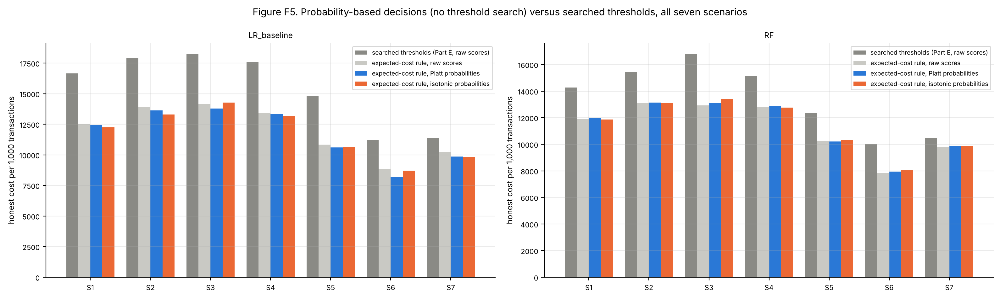

In [89]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8)); lab = [s.split("_")[0] for s in fc.SCENARIOS]; x = np.arange(len(lab)); w = .2
for a, m in zip(ax, ["LR_baseline", "RF"]):
    d = UC.loc[m]
    for k, (c, col, nm) in enumerate([("searched_thresholds", GREY, "searched thresholds (Part E, raw scores)"), ("rule_on_raw", "#c9c9c4", "expected-cost rule, raw scores"), ("rule_on_platt", BLUE, "expected-cost rule, Platt probabilities"), ("rule_on_isotonic", ORANGE, "expected-cost rule, isotonic probabilities")]):
        a.bar(x + (k - 1.5) * w, d[c], w, color=col, label=nm)
    a.set_xticks(x); a.set_xticklabels(lab); a.set_ylabel("honest cost per 1,000 transactions"); a.set_title(m, fontsize=9); a.legend(fontsize=7)
fig.suptitle("Figure F5. Probability-based decisions (no threshold search) versus searched thresholds, all seven scenarios", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "F05_probability_decisions.png", dpi=130, bbox_inches="tight"); plt.show()

### F7. Is calibration uniform across customer segments?
Overall calibration can hide segments where the probabilities are systematically too high or low (and therefore where customers are over-blocked or fraud is under-reviewed). The cross-fitted Platt probabilities of the Random Forest are compared with observed fraud rates by transaction-amount tercile, by channel and by new-device flag (average of the 20 cross-fitted vectors per row).

In [90]:
PF = np.mean(CF["RF"]["platt"], axis=0); seg = meta.copy(); seg["p"] = PF; seg["y"] = YF
seg["amount_tercile"] = pd.qcut(amtF, 3, labels=["low", "mid", "high"])
rows = []
for col in ["amount_tercile", "channel", "new_device", "authentication_level"]:
    for lev, g in seg.groupby(col, observed=True, dropna=False):
        n = len(g); k = int(g.y.sum()); ph = k / n; z = 1.96; centre = (ph + z**2 / (2 * n)) / (1 + z**2 / n); half = z * np.sqrt(ph * (1 - ph) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
        rows.append(dict(segment=col, level=str(lev), n=n, frauds=k, mean_predicted=g.p.mean(), observed=ph, ci_low=centre - half, ci_high=centre + half, gap=g.p.mean() - ph, inside_ci=bool(centre - half <= g.p.mean() <= centre + half)))
SEG = pd.DataFrame(rows); display(SEG.round(3).set_index(["segment", "level"]))
print(f"{int((~SEG.inside_ci).sum())} of {len(SEG)} segment levels have a mean predicted probability outside the 95% interval of the observed rate (about 1 in 20 is expected by chance alone).")

n  frauds  mean_predicted  observed  ci_low  ci_high    gap  inside_ci
segment              level                                                                                
amount_tercile       low          800      91           0.112     0.114   0.094    0.138 -0.002       True
                     mid          800      84           0.116     0.105   0.086    0.128  0.011       True
                     high         800     116           0.136     0.145   0.122    0.171 -0.009       True
channel              ATM          221      22           0.125     0.100   0.067    0.146  0.025       True
                     E-commerce   938     134           0.121     0.143   0.122    0.167 -0.022      False
                     Mobile App   471      62           0.125     0.132   0.104    0.165 -0.007       True
                     POS          770      73           0.119     0.095   0.076    0.118  0.024      False
new_device           0           2004     213           0.111     0.106   0.094    0.121  0.005       True
                     1            396      78           0.173     0.197   0.161    0.239 -0.024       True
authentication_level Standard    1077     124           0.116     0.115   0.097    0.136  0.001       True
                     Strong      1094     119           0.117     0.109   0.092    0.129  0.008       True
                     nan          229      48           0.167     0.210   0.162    0.267 -0.042       True

2 of 12 segment levels have a mean predicted probability outside the 95% interval of the observed rate (about 1 in 20 is expected by chance alone).


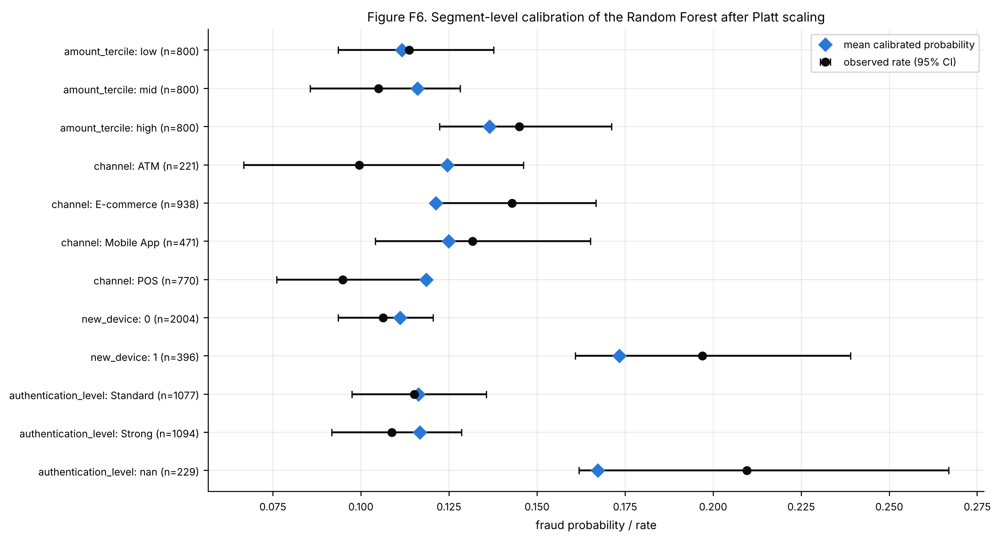

In [91]:
fig, ax = plt.subplots(figsize=(11, 6)); S2 = SEG.reset_index(drop=True); y = np.arange(len(S2))[::-1]
ax.errorbar(S2.observed, y, xerr=[S2.observed - S2.ci_low, S2.ci_high - S2.observed], fmt="o", color=INK, capsize=3, label="observed rate (95% CI)")
ax.plot(S2.mean_predicted, y, "D", color=BLUE, ms=7, label="mean calibrated probability"); ax.set_yticks(y); ax.set_yticklabels([f"{a}: {b} (n={n})" for a, b, n in zip(S2.segment, S2.level, S2.n)], fontsize=8)
ax.set_xlabel("fraud probability / rate"); ax.legend(fontsize=8); ax.set_title("Figure F6. Segment-level calibration of the Random Forest after Platt scaling", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "F06_segment_calibration.png", dpi=130, bbox_inches="tight"); plt.show()

### F8. The calibrated production model (`04_calibrated_model.joblib`) and the uncalibrated pipeline (`03_fraud_model_pipeline.joblib`)
The final Random Forest (Part D, refitted on all 2,400 development rows) is wrapped with a calibrator fitted on **all development OOF scores of the Random Forest** (both prediction repeats stacked, 4,800 pairs). Using OOF scores is essential: the final model's own predictions on its training rows are over-confident and would give a useless calibrator. The Part E thresholds, chosen on raw scores, are translated to the calibrated scale through the same monotone map, so every decision stays exactly the same.

In [92]:
import joblib
fm_ = __import__("fraud_models")
Xd, yd, idd = fm_.load_dev(); assert (idd.values == oofF.transaction_id.values).all() and (yd.values == YF).all()
base_pipe = joblib.load(OUT / "models" / "D_RF.joblib")
stack_s = np.concatenate(SF["RF"]); stack_y = np.concatenate([YF, YF])
CAL = fcal.CALIBRATORS[CHOSEN_CAL]().fit(stack_s, stack_y)
final_model = fcal.CalibratedFraudModel(base_pipe, CAL, meta=dict(calibration=CHOSEN_CAL, fitted_on="development OOF scores of the Random Forest (2 repeats stacked)", seed=SEED_F,
                                                                    thresholds_raw={"t_review": T1, "t_block": T2}))
T1c, T2c = float(CAL.predict(np.array([T1]))[0]), float(CAL.predict(np.array([T2]))[0])
final_model.meta["thresholds_calibrated"] = {"t_review": T1c, "t_block": T2c}
if CHOSEN_CAL == "platt": final_model.meta["platt"] = {"intercept": CAL.a_, "slope": CAL.b_}
joblib.dump(base_pipe, Path(".") / "03_fraud_model_pipeline.joblib"); joblib.dump(final_model, Path(".") / "04_calibrated_model.joblib")
chk = joblib.load(Path(".") / "04_calibrated_model.joblib"); p_new = chk.predict_proba(Xd.head(200))[:, 1]
assert np.allclose(p_new, final_model.predict_proba(Xd.head(200))[:, 1]) and np.allclose(chk.raw_score(Xd.head(200)), base_pipe.predict_proba(Xd.head(200))[:, 1])
print(f"calibrator: {CHOSEN_CAL}", ({k: round(v, 4) for k, v in final_model.meta.get('platt', {}).items()} or ""))
print(f"Part E thresholds translated to calibrated probabilities: review at {T1c:.3f}, block at {T2c:.3f}  (raw {T1:.3f} / {T2:.3f})")
print("saved 03_fraud_model_pipeline.joblib (uncalibrated Random Forest pipeline) and 04_calibrated_model.joblib; reload check passed.")
print("Reminder: the model was refitted on all development rows, so its probabilities for those same rows are NOT honest; honest calibration evidence is the cross-fitted OOF analysis above. The hold-out check is reserved for the final evaluation.")
json.dump(dict(calibrator=CHOSEN_CAL, platt=final_model.meta.get("platt"), thresholds_raw=dict(t_review=T1, t_block=T2), thresholds_calibrated=dict(t_review=T1c, t_block=T2c), seed=SEED_F), open(OUT / "F_calibration_choice.json", "w"), indent=2)

calibrator: platt {'intercept': 0.068, 'slope': 1.0309}
Part E thresholds translated to calibrated probabilities: review at 0.158, block at 0.212  (raw 0.156 / 0.208)
saved 03_fraud_model_pipeline.joblib (uncalibrated Random Forest pipeline) and 04_calibrated_model.joblib; reload check passed.
Reminder: the model was refitted on all development rows, so its probabilities for those same rows are NOT honest; honest calibration evidence is the cross-fitted OOF analysis above. The hold-out check is reserved for the final evaluation.


### F9. Findings

**1. Are the raw probabilities calibrated? It depends on the model.** The Logistic Regression baseline is clearly **over-confident**: calibration slope 0.66 (95% interval 0.53 to 0.81), intercept -0.61, ECE 0.028 against a noise floor of about 0.015, Hosmer-Lemeshow style p < 0.001. The Random Forest (slope 1.05, interval 0.83 to 1.28; ECE 0.016, equal to the noise floor; p = 0.35) and HGB (slope 0.89; ECE 0.014; p = 0.34) are consistent with calibrated. LR tuned is in between (slope 1.02 but ECE 0.027, p = 0.008). The Random Forest also has the best Brier score (0.1020 against 0.1065 for no skill, a 4.2% skill score). Differences in Brier score between models are tiny because calibration error is a small part of it: the Murphy "reliability" term is 0.0003 for RF and 0.0015 for the LR baseline, while the "resolution" term (separation of frauds from non-frauds) is similar for both (0.0048 and 0.0045).

**2. Platt scaling versus isotonic regression.** Platt scaling repairs the over-confident LR baseline (Brier 0.1028 to 0.1019, log loss 0.3543 to 0.3503, ECE 0.028 to 0.019, slope 0.98), although the paired intervals only just include zero (Brier -0.0009 [-0.0022, +0.0004]; log loss -0.0041 [-0.0081, +0.0001]). For the already well-calibrated Random Forest, Platt scaling adds nothing: Brier +0.0001 (not significant) and log loss +0.0005 (a tiny but just-significant loss from fitting two noisy parameters). **Isotonic regression is worse than Platt on log loss for all four models** (paired intervals exclude zero), and worse than the raw Random Forest on Brier (+0.0007) and log loss (+0.0061). It collapses about 2,380 distinct scores into about 80 plateaus, lowers the ROC-AUC (RF 0.661 to 0.646) and is over-confident on new rows (cross-fitted slope 0.71 to 0.79). Figure F3 shows why: isotonic needs about 1,300 to 1,400 rows to match the raw LR baseline and never beats the raw Random Forest at any size tested, whereas Platt helps the LR baseline from about 400 rows. With 291 frauds, isotonic is **not technically appropriate** here. By the rule written in advance, Platt is the calibration layer.

**3. Honest statement about the production model.** The Random Forest did not need calibration. It is shipped with a Platt layer (intercept 0.068, slope 1.031, almost the identity) as a documented, ranking-preserving safeguard whose measured cost is 0.0005 log loss; it is not presented as an improvement. The Part E thresholds map to 0.158 (review) and 0.212 (block) on the calibrated scale, so every Part E decision is unchanged.

**4. Why calibration matters operationally (Random Forest, Part E policy).** The probabilities predict what each action group will contain: in the Approve / Review / Block groups the actual fraud rates are 9.2%, 19.5% and 30.0%, against calibrated predictions of 9.4%, 18.5% and 29.5% (raw: 9.5%, 17.9%, 27.6%). The mean gap across groups falls from 0.014 (raw) to 0.006 (Platt), and the expected number of frauds in the whole sample is 293 against 291 actual. This is what lets a manager say "the review queue will contain about 1 fraud in 5". One limit: probabilities that are right do not guarantee that the amount forecast is right. Expected loss (sum of probability x amount) is about 4% low in the approved group, 6% low in the review group and **20% too high in the block group** (15,242 forecast against 12,664 actual), where there are only about 66 frauds, so this is noisy but worth monitoring.

**5. Calibrated probabilities allow decisions to be made directly from the cost table.** An amount-aware rule (take the action with the lowest expected cost for each transaction, with shadow prices that fit the review and block limits and use no labels) beats the thresholds searched in Part E in every scenario. For the Random Forest the honest saving in the base scenario is 2,353 per 1,000 transactions (about 16%; 95% interval 1,167 to 3,580), significant in S1 to S6 and borderline in S7 (-529 [-1,039, +16]). For the LR baseline the saving is larger (4,441 in S1) because Part E's thresholds were hurt by its poor ranking at the top. Calibration itself explains only a small part of this: for the Random Forest, Platt probabilities cost about the same as raw scores (S1 difference +42 [-76, +189]; only in S3 are raw scores slightly cheaper, +209 [+41, +388], about 1.6%); for the LR baseline, Platt probabilities are cheaper than raw ones in all seven scenarios (by 83 to 660 per 1,000) but the interval excludes zero only in S6. So most of the gain comes from using the amount and the cost table, which only makes sense if the score is a probability; calibration is what makes that safe. This also shows that **Part E's amount-blind thresholds leave money on the table**, so Part I will compare both policies (simple thresholds versus the probability-based rule) before a production policy is recommended. The Random Forest remains the cheapest model under the probability rule in the scenarios compared (e.g. S1: 11,962 against 12,439 for the LR baseline), but that comparison was not separately tested.

**6. Segments.** Calibration is acceptable across amount terciles, device flag and authentication level. Two of twelve segment levels fall outside their 95% interval (about 0.6 expected by chance): E-commerce is under-predicted (0.121 predicted against 0.143 observed) and POS over-predicted (0.119 against 0.095). This is weak evidence of a channel effect the Random Forest underuses, and it is flagged for monitoring and for Part J.

**Caveats.** All calibration estimates rest on 291 frauds, so intervals are wide and small differences (RF raw against Platt) cannot be resolved. The final model is trained on all development rows while the calibrator was fitted on OOF scores from models trained on 80% of them, so its scores can be slightly more spread out; the hold-out set is reserved for one final check. The calibration is only as stable as the 12% fraud rate: a change in prevalence shifts the intercept, so recalibration should be part of monitoring (Part K). All costs remain hypothetical.

In [93]:
RAW_TABLE.to_csv(OUT / "F_raw_calibration_metrics.csv"); CFT.to_csv(OUT / "F_crossfit_metrics.csv", index=False); PD.to_csv(OUT / "F_paired_differences.csv", index=False)
BAND.to_csv(OUT / "F_action_band_forecast.csv"); UC.to_csv(OUT / "F_probability_rule_vs_search.csv"); TH.to_csv(OUT / "F_breakeven_probabilities.csv"); SEG.to_csv(OUT / "F_segment_calibration.csv", index=False); lcs.to_csv(OUT / "F_calibrator_learning_curve.csv", index=False)
print("Part F tables saved; figures:", sorted(p.name for p in FIG.glob("F*.png")), "| hold-out rows read: none")

Part F tables saved; figures: ['F01_raw_calibration_curves.png', 'F02_platt_vs_isotonic.png', 'F03_calibrator_learning_curve.png', 'F04_operational_forecasts.png', 'F05_probability_decisions.png', 'F06_segment_calibration.png'] | hold-out rows read: none


---
## Part G. Imbalanced Learning

**Goal:** measure how imbalanced the problem is, compare ways of handling it (class weighting and controlled resampling) fairly, make sure resampling can never leak into validation or test rows, and judge every approach on the metrics that matter for fraud (PR-AUC, recall, precision, F1, business cost) and not on ROC-AUC alone.

| Task G requirement | Section |
|---|---|
| Quantify the class imbalance | G1 |
| Compare at least two approaches (class weighting, controlled resampling) | G3, G4, G7 |
| Resampling only inside the training pipeline | G2 (built-in test) and G8 (what happens if it is done wrongly) |
| PR-AUC, recall, precision, F1 and business cost beside ROC-AUC | G3, G5, G6 |

**Design (fixed before any result was computed)**
1. **Arms:** `none` (plain model); `class_weight` (errors on frauds count about 7x more, `class_weight="balanced"`); and three resampling methods that each re-balance to a target minority:majority ratio *r*: `rus` (random undersampling), `ros` (random oversampling by duplicating frauds) and `smote` (synthetic frauds interpolated between neighbours). Main setting *r* = 0.5; a sweep over *r* = 0.25, 0.5, 1.0 shows how sensitive the result is. The natural ratio is about 0.14.
2. **Two models, hyper-parameters fixed:** the Logistic Regression baseline (Part D) and the Random Forest chosen in Part E, with the Part D final settings. Only the imbalance treatment changes between arms. Those settings were tuned in Part D on the whole development set, so absolute Random Forest scores here are slightly optimistic against Part D's nested estimate; the optimism is the same in every arm, so *comparisons* stay fair.
3. **Resampling lives inside the pipeline:** `features -> selector -> impute/encode/scale -> sampler -> model` (imbalanced-learn `Pipeline`). The sampler acts only during `fit`, never in `predict`, and in cross-validation it only ever sees the training folds. SMOTE needs numeric input, so it runs after encoding; synthetic points between one-hot columns can be fractional, which is a known limitation noted in G9.
4. **Evaluation:** the same 5-fold x 2-repeat outer folds as Part D, always on **natural-prevalence** test folds (never resampled). Primary metrics: PR-AUC, recall and precision in the top 10% of scores (the review capacity), recall / precision / F1 at the default 0.50 cut-off, and business cost (Part E framework, honest thresholds). ROC-AUC, Brier score and log loss are reported as secondary.
5. **Why rank metrics alone are not enough:** class weights and resampling change the *probability scale* (they make the model think fraud is common). Rank metrics (PR-AUC, ROC-AUC, top-10% recall) ignore this; the 0.50-cut-off metrics, Brier score, calibration and probability-based decisions do not. Part F showed calibrated probabilities are used operationally, so this is evaluated too (G6).
6. **Adoption rule, written now:** an imbalance treatment replaces the plain model only if (a) its PR-AUC is higher than `none` with a Nadeau-Bengio corrected 95% interval that excludes zero (Holm-adjusted across arms), **or** (b) its honest business cost in the base scenario is lower with a paired-bootstrap 95% interval that excludes zero; and it is not significantly worse on the other. Otherwise the plain model, with the cost-based thresholds of Part E and the Platt layer of Part F, stays. The hold-out set is not read.

### G1. How imbalanced is the problem?

In [94]:
import fraud_models as fm_g, fraud_eval as fe_g, fraud_imbalance as fi
from sklearn.base import clone
from scipy import stats
import fraud_calibration as fcal, fraud_costs as fc
SEED_G = 42
Xg, yg, idg = fm_g.load_dev(); NG = len(yg); POS = int(yg.sum()); NEG = NG - POS
splits_g = fe_g.make_splits(yg, 5, 2)
meta_g = pd.DataFrame({ID: idg.values}).merge(df, on=ID, how="left"); amt_g = meta_g.transaction_amount.fillna(meta_g.transaction_amount.median()).to_numpy()
rate = POS / NG; z = 1.96; ctr = (rate + z**2 / (2 * NG)) / (1 + z**2 / NG); half = z * np.sqrt(rate * (1 - rate) / NG + z**2 / (4 * NG**2)) / (1 + z**2 / NG)
fold_pos = [int(yg.iloc[te].sum()) for _, te in splits_g]; fold_n = [len(te) for _, te in splits_g]
probe = fi.build_arm("LR", "none").fit(Xg, yg); n_feat = probe[:-1].transform(Xg.head(5)).shape[1]
IMB = pd.Series({
    "development rows": NG, "frauds (minority)": POS, "legitimate (majority)": NEG,
    "fraud rate": round(rate, 4), "fraud rate 95% CI": f"[{ctr - half:.3f}, {ctr + half:.3f}]",
    "imbalance ratio (majority : minority)": f"{NEG / POS:.2f} : 1", "natural minority:majority ratio": round(POS / NEG, 3),
    "accuracy of 'always legitimate'": round(NEG / NG, 4), "PR-AUC of a no-skill model": round(rate, 4), "recall / F1 of 'always legitimate'": "0 / 0",
    "frauds per outer test fold (min-max)": f"{min(fold_pos)}-{max(fold_pos)}", "frauds per outer training fold": f"{POS - max(fold_pos)}-{POS - min(fold_pos)}",
    "model inputs after encoding (LR baseline)": n_feat, "frauds per model input (events per variable)": round(POS / n_feat, 1)})
display(IMB.to_frame("value"))
print("Reading: about 1 in 8 transactions is fraud. That is MODERATE imbalance (severe problems start below about 1 in 100), so heavy re-balancing is unlikely to be needed;")
print("the real constraints are the SMALL NUMBER of frauds (291) and the weak signal, which limit what any technique can learn.")

,value
development rows,2400
frauds (minority),291
legitimate (majority),2109
fraud rate,0.1212
fraud rate 95% CI,"[0.109, 0.135]"
imbalance ratio (majority : minority),7.25 : 1
natural minority:majority ratio,0.138
accuracy of 'always legitimate',0.8788
PR-AUC of a no-skill model,0.1212
recall / F1 of 'always legitimate',0 / 0


Reading: about 1 in 8 transactions is fraud. That is MODERATE imbalance (severe problems start below about 1 in 100), so heavy re-balancing is unlikely to be needed;
the real constraints are the SMALL NUMBER of frauds (291) and the weak signal, which limit what any technique can learn.


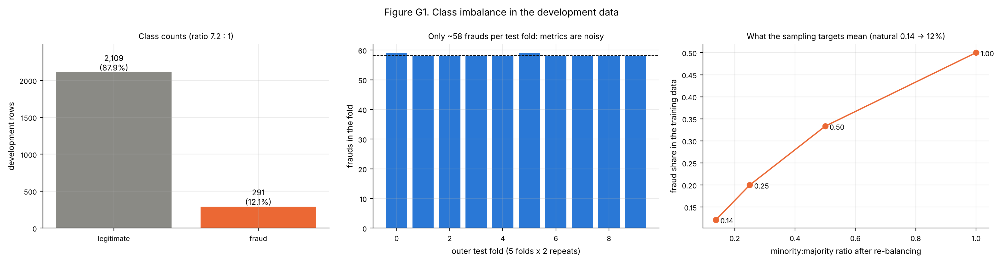

In [95]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].bar(["legitimate", "fraud"], [NEG, POS], color=[GREY, ORANGE]); [ax[0].text(i, v + 25, f"{v:,}\n({v / NG:.1%})", ha="center", fontsize=9) for i, v in enumerate([NEG, POS])]; ax[0].set_ylim(0, NEG * 1.18); ax[0].set_ylabel("development rows"); ax[0].set_title("Class counts (ratio %.1f : 1)" % (NEG / POS), fontsize=9)
ax[1].bar(np.arange(10), fold_pos, color=BLUE); ax[1].axhline(np.mean(fold_pos), color=INK, lw=.8, ls="--"); ax[1].set_xlabel("outer test fold (5 folds x 2 repeats)"); ax[1].set_ylabel("frauds in the fold"); ax[1].set_title("Only ~58 frauds per test fold: metrics are noisy", fontsize=9)
rs = np.array([0.138, .25, .5, 1.0]); ax[2].plot(rs, rs / (1 + rs), "o-", color=ORANGE); ax[2].set_xlabel("minority:majority ratio after re-balancing"); ax[2].set_ylabel("fraud share in the training data"); ax[2].set_title("What the sampling targets mean (natural 0.14 -> 12%)", fontsize=9)
[ax[2].annotate(f"{r:.2f}", (r, r / (1 + r)), textcoords="offset points", xytext=(5, -4), fontsize=8) for r in rs]
fig.suptitle("Figure G1. Class imbalance in the development data", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "G01_class_imbalance.png", dpi=130, bbox_inches="tight"); plt.show()

### G2. Integrity test: the sampler only ever sees training rows
For each of the first five outer folds, the sampler is replaced by a recording wrapper around random undersampling. The test checks that (1) it is called exactly once while fitting, (2) it receives exactly the training rows and the training frauds of that fold (none from the test fold, since the counts match the training fold exactly), and (3) it is **not** called when the pipeline predicts the test fold.

In [96]:
IT = fi.integrity_test(Xg, yg, splits_g); display(IT)
assert IT.ok.all(), "sampler leaked outside the training fold"
print("PASS: in all 5 folds the sampler was called once, on exactly the training rows, and never during prediction. Test folds keep their natural class mix.")

,fold,train_rows,test_rows,sampler_calls_during_fit,rows_seen_by_sampler,frauds_seen_by_sampler,frauds_in_train_fold,sampler_calls_during_predict,ok
0,0,1920,480,1,1920,232,232,0,True
1,1,1920,480,1,1920,233,233,0,True
2,2,1920,480,1,1920,233,233,0,True
3,3,1920,480,1,1920,233,233,0,True
4,4,1920,480,1,1920,233,233,0,True


PASS: in all 5 folds the sampler was called once, on exactly the training rows, and never during prediction. Test folds keep their natural class mix.


### G3. Experiment: all arms, two models, repeated cross-validation
Every arm is fitted on the same 10 outer training folds and scored on the same natural-prevalence test folds. Means over the 10 folds are shown (standard deviations in the saved CSV). `recall@10%` and `precision@10%` refer to the 10% highest-scoring transactions of each test fold (the Part E review capacity). Metrics `@0.50` use the default cut-off.

In [97]:
SAMPLERS = ["rus", "ros", "smote"]; MAIN = ["none", "class_weight", "rus_0.5", "ros_0.5", "smote_0.5"]
SWEEP = [f"{s}_{r}" for s in SAMPLERS for r in (0.25, 1.0)]; ARMS = MAIN + SWEEP; MODELS_G = ["LR", "RF"]
RES = {}
for m in MODELS_G:
    for a in ARMS: RES[(m, a)] = fi.run_arm(m, a, Xg, yg, splits_g)
ALLF = pd.concat([RES[k][0] for k in RES]); COLS = ["pr_auc", "recall_top10", "precision_top10", "precision_at_05", "recall_at_05", "f1_at_05", "flagged_at_05", "roc_auc", "brier", "log_loss", "mean_p"]
SUM = ALLF.groupby(["model", "arm"], sort=False)[COLS].mean(); SD = ALLF.groupby(["model", "arm"], sort=False)[COLS].std()
print("Natural prevalence of fraud = 0.121. Mean over 10 outer test folds.")
display(SUM.loc[(slice(None), MAIN), :].round(3))

Natural prevalence of fraud = 0.121. Mean over 10 outer test folds.


pr_auc  recall_top10  precision_top10  precision_at_05  recall_at_05  f1_at_05  flagged_at_05  roc_auc  brier  log_loss  mean_p
model arm                                                                                                                                          
LR    none           0.249         0.223            0.271            0.529         0.041     0.074          0.011    0.669  0.103     0.354   0.122
      class_weight   0.241         0.223            0.271            0.201         0.596     0.300          0.362    0.669  0.218     0.634   0.434
      rus_0.5        0.237         0.215            0.260            0.236         0.321     0.271          0.168    0.670  0.153     0.485   0.311
      ros_0.5        0.232         0.209            0.254            0.232         0.259     0.244          0.139    0.655  0.148     0.468   0.300
      smote_0.5      0.240         0.216            0.262            0.243         0.297     0.267          0.150    0.653  0.148     0.466   0.296
RF    none           0.259         0.237            0.288            0.000         0.000     0.000          0.000    0.665  0.102     0.351   0.121
      class_weight   0.261         0.244            0.296            0.182         0.507     0.267          0.339    0.654  0.217     0.626   0.456
      rus_0.5        0.243         0.216            0.262            0.337         0.134     0.186          0.051    0.661  0.143     0.465   0.320
      ros_0.5        0.240         0.222            0.269            0.409         0.113     0.173          0.037    0.647  0.139     0.455   0.308
      smote_0.5      0.236         0.232            0.281            0.233         0.007     0.013          0.003    0.649  0.116     0.396   0.232

In [98]:
print("Sampling-ratio sweep (same metrics):"); display(SUM.loc[(slice(None), [a for a in ARMS if a not in MAIN] + ["none"]), :].round(3).sort_index())

Sampling-ratio sweep (same metrics):


pr_auc  recall_top10  precision_top10  precision_at_05  recall_at_05  f1_at_05  flagged_at_05  roc_auc  brier  log_loss  mean_p
model arm                                                                                                                                        
LR    none         0.249         0.223            0.271            0.529         0.041     0.074          0.011    0.669  0.103     0.354   0.122
      ros_0.25     0.242         0.211            0.256            0.345         0.106     0.161          0.039    0.664  0.112     0.377   0.189
      ros_1.0      0.235         0.230            0.279            0.196         0.586     0.293          0.364    0.664  0.220     0.638   0.434
      rus_0.25     0.245         0.218            0.265            0.368         0.134     0.194          0.046    0.670  0.113     0.381   0.194
      rus_1.0      0.221         0.223            0.271            0.184         0.601     0.282          0.397    0.661  0.237     0.694   0.453
      smote_0.25   0.249         0.213            0.258            0.353         0.124     0.182          0.043    0.659  0.112     0.379   0.190
      smote_1.0    0.239         0.218            0.265            0.190         0.562     0.284          0.359    0.652  0.221     0.638   0.425
RF    none         0.259         0.237            0.288            0.000         0.000     0.000          0.000    0.665  0.102     0.351   0.121
      ros_0.25     0.251         0.230            0.279            0.225         0.005     0.010          0.001    0.664  0.107     0.370   0.191
      ros_1.0      0.254         0.230            0.279            0.178         0.496     0.261          0.341    0.649  0.217     0.625   0.455
      rus_0.25     0.246         0.234            0.283            0.150         0.003     0.007          0.001    0.666  0.108     0.372   0.196
      rus_1.0      0.232         0.204            0.248            0.174         0.582     0.268          0.410    0.647  0.233     0.658   0.478
      smote_0.25   0.255         0.247            0.300            0.000         0.000     0.000          0.000    0.662  0.104     0.360   0.170
      smote_1.0    0.218         0.220            0.267            0.257         0.246     0.249          0.119    0.639  0.149     0.473   0.319

### G4. Are the differences real? Paired comparison against the plain model
Per-fold differences in PR-AUC (arm minus `none`, paired on identical folds) with the Nadeau-Bengio corrected resampled t-test (it widens the interval to account for overlapping training sets). p-values are Holm-adjusted across the four main arms of each model.

In [99]:
rows = []
for m in MODELS_G:
    base = RES[(m, "none")][0].set_index("fold")
    for a in ARMS[1:]:
        f = RES[(m, a)][0].set_index("fold")
        for metric in ["pr_auc", "roc_auc", "recall_top10"]:
            t = fe_g.corrected_ttest((f[metric] - base[metric]).values, n_train=1920, n_test=480); rows.append(dict(model=m, arm=a, metric=metric, **t))
PT = pd.DataFrame(rows)
for (m, metric), g in PT[PT.arm.isin(MAIN)].groupby(["model", "metric"]):
    p = g.p_value.values; order = np.argsort(p); adj = np.empty(len(p)); run = 0
    for rank, i in enumerate(order): run = max(run, (len(p) - rank) * p[i]); adj[i] = min(run, 1.0)
    PT.loc[g.index, "p_holm"] = adj
PT["significant"] = (PT.ci_low > 0) | (PT.ci_high < 0)
display(PT[PT.metric == "pr_auc"].round(4).set_index(["model", "arm"])[["mean_diff", "ci_low", "ci_high", "p_value", "p_holm", "significant"]])
print("PR-AUC: SD of the fold scores is about", round(float(ALLF[ALLF.arm == 'none'].groupby('model').pr_auc.std().mean()), 3), "so only differences of several hundredths could be detected with ~58 frauds per fold.")

mean_diff  ci_low  ci_high  p_value  p_holm  significant
model arm                                                                   
LR    class_weight    -0.0081 -0.0250   0.0088   0.3073  0.6146        False
      rus_0.5         -0.0128 -0.0284   0.0028   0.0959  0.3836        False
      ros_0.5         -0.0170 -0.0385   0.0044   0.1058  0.3836        False
      smote_0.5       -0.0090 -0.0303   0.0123   0.3645  0.6146        False
      rus_0.25        -0.0047 -0.0163   0.0069   0.3830     NaN        False
      rus_1.0         -0.0288 -0.0603   0.0027   0.0688     NaN        False
      ros_0.25        -0.0073 -0.0212   0.0066   0.2649     NaN        False
      ros_1.0         -0.0139 -0.0310   0.0031   0.0981     NaN        False
      smote_0.25      -0.0004 -0.0110   0.0101   0.9268     NaN        False
      smote_1.0       -0.0103 -0.0323   0.0118   0.3200     NaN        False
RF    class_weight     0.0018 -0.0274   0.0310   0.8911  0.8911        False
      rus_0.5         -0.0158 -0.0597   0.0281   0.4375  0.8750        False
      ros_0.5         -0.0188 -0.0553   0.0176   0.2724  0.8172        False
      smote_0.5       -0.0232 -0.0551   0.0086   0.1333  0.5333        False
      rus_0.25        -0.0125 -0.0493   0.0243   0.4621     NaN        False
      rus_1.0         -0.0270 -0.0901   0.0361   0.3586     NaN        False
      ros_0.25        -0.0081 -0.0310   0.0149   0.4476     NaN        False
      ros_1.0         -0.0049 -0.0427   0.0329   0.7748     NaN        False
      smote_0.25      -0.0043 -0.0440   0.0354   0.8125     NaN        False
      smote_1.0       -0.0406 -0.0955   0.0144   0.1290     NaN        False

PR-AUC: SD of the fold scores is about 0.056 so only differences of several hundredths could be detected with ~58 frauds per fold.


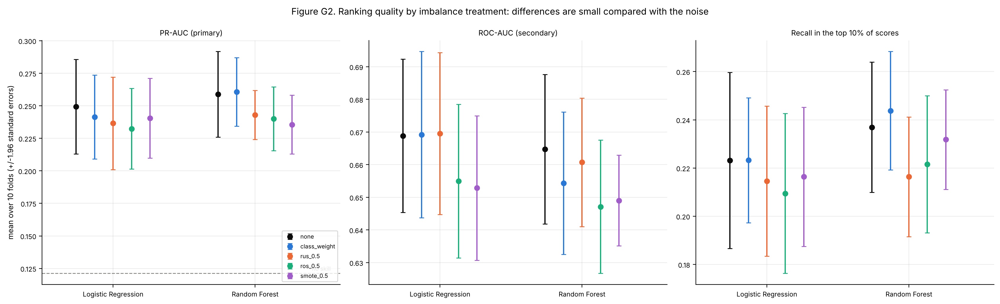

In [100]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5.2)); ARMC = {"none": INK, "class_weight": BLUE, "rus_0.5": ORANGE, "ros_0.5": "#1aaf7a", "smote_0.5": "#a05cc8"}
for a_, metric, ttl in zip(ax, ["pr_auc", "roc_auc", "recall_top10"], ["PR-AUC (primary)", "ROC-AUC (secondary)", "Recall in the top 10% of scores"]):
    for j, m in enumerate(MODELS_G):
        for k, arm in enumerate(MAIN):
            v = RES[(m, arm)][0][metric]; mu, se = v.mean(), v.std(ddof=1) / np.sqrt(len(v)); a_.errorbar(j + (k - 2) * .13, mu, yerr=1.96 * se, fmt="o", color=ARMC[arm], capsize=3, ms=6, label=arm if j == 0 else None)
    if metric == "pr_auc": a_.axhline(rate, color=GREY, ls="--", lw=1); a_.text(1.4, rate + .002, "no skill", fontsize=7, color=GREY)
    a_.set_xticks([0, 1]); a_.set_xticklabels(["Logistic Regression", "Random Forest"]); a_.set_xlim(-.5, 1.6); a_.set_title(ttl, fontsize=9)
ax[0].legend(fontsize=7, loc="lower right"); ax[0].set_ylabel("mean over 10 folds (+/-1.96 standard errors)")
fig.suptitle("Figure G2. Ranking quality by imbalance treatment: differences are small compared with the noise", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "G02_ranking_metrics.png", dpi=130, bbox_inches="tight"); plt.show()

### G5. Precision-recall curves and the default 0.50 cut-off
PR curves use all out-of-fold scores of CV repeat 0. The second figure shows what the default 0.50 cut-off does: it behaves very differently per arm, because class weights and resampling shift the probability scale (the mean predicted fraud probability moves from 0.12 up to 0.3 to 0.5).

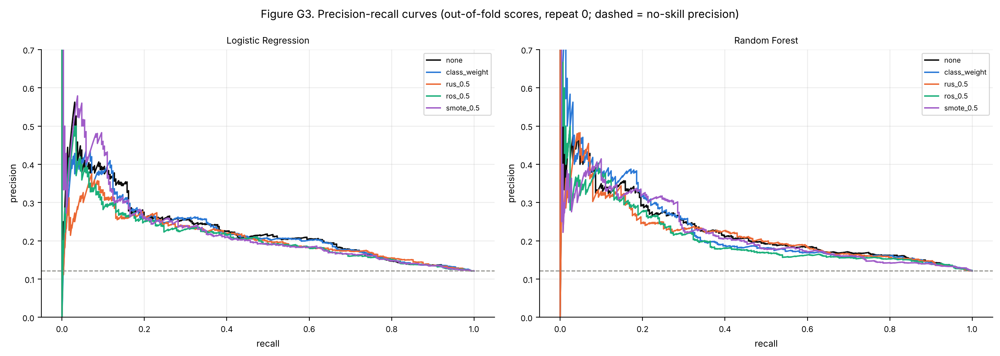

In [101]:
from sklearn.metrics import precision_recall_curve
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a_, m in zip(ax, MODELS_G):
    for arm in MAIN:
        pr, rc, _ = precision_recall_curve(yg, RES[(m, arm)][1][0]); a_.plot(rc, pr, color=ARMC[arm], lw=1.4, label=arm)
    a_.axhline(rate, color=GREY, ls="--", lw=1); a_.set_xlabel("recall"); a_.set_ylabel("precision"); a_.set_ylim(0, .7); a_.set_title({"LR": "Logistic Regression", "RF": "Random Forest"}[m], fontsize=9); a_.legend(fontsize=7)
fig.suptitle("Figure G3. Precision-recall curves (out-of-fold scores, repeat 0; dashed = no-skill precision)", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "G03_pr_curves.png", dpi=130, bbox_inches="tight"); plt.show()

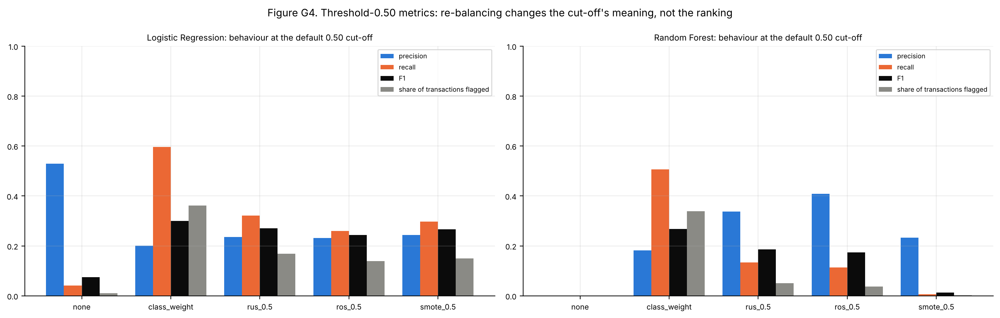

Note: a higher F1 at 0.50 is mostly the model flagging far more transactions; the same ranking with a better-chosen cut-off (Part E) can do the same. F1 at 0.50 is therefore not used to choose an arm.


In [102]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8)); w = .2
for a_, m in zip(ax, MODELS_G):
    x = np.arange(len(MAIN)); d = SUM.loc[m].loc[MAIN]
    for k, (c, col, nm) in enumerate([("precision_at_05", BLUE, "precision"), ("recall_at_05", ORANGE, "recall"), ("f1_at_05", INK, "F1"), ("flagged_at_05", GREY, "share of transactions flagged")]): a_.bar(x + (k - 1.5) * w, d[c], w, color=col, label=nm)
    a_.set_xticks(x); a_.set_xticklabels(MAIN, fontsize=8); a_.set_ylim(0, 1); a_.set_title({"LR": "Logistic Regression", "RF": "Random Forest"}[m] + ": behaviour at the default 0.50 cut-off", fontsize=9); a_.legend(fontsize=7)
fig.suptitle("Figure G4. Threshold-0.50 metrics: re-balancing changes the cut-off's meaning, not the ranking", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "G04_threshold_05_metrics.png", dpi=130, bbox_inches="tight"); plt.show()
print("Note: a higher F1 at 0.50 is mostly the model flagging far more transactions; the same ranking with a better-chosen cut-off (Part E) can do the same. F1 at 0.50 is therefore not used to choose an arm.")

### G6. Business cost (Part E framework) and probability quality
Cost per 1,000 transactions with **honest** cost-optimal thresholds (thresholds chosen on training rows, applied to unseen rows, 5 repeats of 5-fold), for three scenarios: S1 base, S3 customer-first and S5 cheap-review / bigger team. Because these thresholds are searched on the scores, they are insensitive to the scale shift of class weights and resampling. Differences against `none` are paired bootstrap (rows). The second table shows what happens when the probability-based rule of Part F is fed the arms' *raw* scores versus Platt-calibrated scores.

In [103]:
CSCN = ["S1_base", "S3_customer_first", "S5_review_cheap_big_team"]; rows, ROWS = [], {}
for m in MODELS_G:
    for a in ARMS:
        for s in (CSCN if a in MAIN else CSCN[:1]):
            sc = fc.SCENARIOS[s]; r, ch = fc.honest_row_costs(RES[(m, a)][1], yg.values, amt_g, sc, fc.chooser_cost("three_way", sc, amt_g, yg.values), n_cv_repeats=5); ROWS[(m, a, s)] = r
            rows.append(dict(model=m, arm=a, scenario=s, cost_per_1000=r.mean() * 1000, t_review=ch.t_review.mean(), t_block=ch.t_block.replace(np.inf, np.nan).mean()))
CT = pd.DataFrame(rows)
for i, r_ in CT.iterrows():
    if r_.arm != "none": d, lo, hi, p = fc.paired_bootstrap(ROWS[(r_.model, r_.arm, r_.scenario)], ROWS[(r_.model, "none", r_.scenario)], n_boot=1000, seed=SEED_G); CT.loc[i, ["diff_vs_none", "ci_low", "ci_high"]] = [d, lo, hi]
CT["significant"] = (CT.ci_low > 0) | (CT.ci_high < 0)
print("Honest cost per 1,000 transactions; diff_vs_none = arm minus plain model (negative = cheaper), 95% paired-bootstrap interval")
display(CT[CT.arm.isin(MAIN)].round(1).set_index(["model", "scenario", "arm"]))

Honest cost per 1,000 transactions; diff_vs_none = arm minus plain model (negative = cheaper), 95% paired-bootstrap interval


cost_per_1000  t_review  t_block  diff_vs_none  ci_low  ci_high  significant
model scenario                 arm                                                                                       
LR    S1_base                  none                16880.7       0.2      0.3           NaN     NaN      NaN        False
      S3_customer_first        none                18271.1       0.2      0.5           NaN     NaN      NaN        False
      S5_review_cheap_big_team none                14946.1       0.1      0.3           NaN     NaN      NaN        False
      S1_base                  class_weight        16199.1       0.6      0.7        -681.6 -1485.4     31.3        False
      S3_customer_first        class_weight        17965.1       0.7      0.8        -306.0  -756.5    138.1        False
      S5_review_cheap_big_team class_weight        14308.6       0.6      0.7        -637.5 -1502.1     84.1        False
      S1_base                  rus_0.5             15189.0       0.5      0.6       -1691.7 -3088.2   -499.0         True
      S3_customer_first        rus_0.5             16926.4       0.6      NaN       -1344.7 -2580.5   -318.3         True
      S5_review_cheap_big_team rus_0.5             13253.8       0.4      0.7       -1692.3 -2919.7   -641.8         True
      S1_base                  ros_0.5             17011.5       0.4      0.6         130.8  -364.9    594.0        False
      S3_customer_first        ros_0.5             18186.7       0.6      0.8         -84.4  -483.8    351.3        False
      S5_review_cheap_big_team ros_0.5             15135.5       0.4      0.6         189.5  -407.8    693.0        False
      S1_base                  smote_0.5           17475.3       0.5      0.6         594.6    39.5   1186.0         True
      S3_customer_first        smote_0.5           18375.1       0.6      0.9         104.0  -331.0    522.1        False
      S5_review_cheap_big_team smote_0.5           15468.4       0.4      0.6         522.3  -136.7   1157.5        False
RF    S1_base                  none                15071.6       0.2      0.2           NaN     NaN      NaN        False
      S3_customer_first        none                17846.9       0.2      0.3           NaN     NaN      NaN        False
      S5_review_cheap_big_team none                12301.2       0.1      0.2           NaN     NaN      NaN        False
      S1_base                  class_weight        16523.9       0.6      0.6        1452.3    79.1   3151.0         True
      S3_customer_first        class_weight        17693.4       0.6      0.7        -153.5  -655.3    448.8        False
      S5_review_cheap_big_team class_weight        13873.2       0.5      0.6        1572.0   487.1   2920.6         True
      S1_base                  rus_0.5             15796.2       0.4      0.5         724.6  -246.1   1886.5        False
      S3_customer_first        rus_0.5             17588.3       0.5      0.5        -258.6  -930.0    451.7        False
      S5_review_cheap_big_team rus_0.5             13567.5       0.4      0.5        1266.3   329.1   2349.1         True
      S1_base                  ros_0.5             15637.1       0.4      0.4         565.4  -236.4   1497.6        False
      S3_customer_first        ros_0.5             17554.0       0.4      0.5        -293.0  -899.9    314.9        False
      S5_review_cheap_big_team ros_0.5             13950.6       0.4      0.5        1649.4   789.2   2702.5         True
      S1_base                  smote_0.5           17770.9       0.3      0.4        2699.3   963.8   4708.6         True
      S3_customer_first        smote_0.5           18077.0       0.4      0.5         230.1  -848.1   1357.2        False
      S5_review_cheap_big_team smote_0.5           15744.3       0.3      0.4        3443.1  1429.0   5680.8         True

In [104]:
def rule_cost(p_vec, sc):
    costs = np.column_stack(fc.row_costs(amt_g, yg.values, sc)); act, lam, mu = fcal.capped_bayes_actions(p_vec, amt_g, sc); return costs[np.arange(NG), act]
rows, sc1 = [], fc.SCENARIOS["S1_base"]
for m in MODELS_G:
    for a in MAIN:
        oof = RES[(m, a)][1]; pl = fcal.crossfit(oof, yg.values, "platt", n_repeats=3, seed=SEED_G)
        met = pd.DataFrame([fcal.metric_row(yg.values, s) for s in oof]).mean(); ref = pd.DataFrame([fcal.metric_row(yg.values, s) for s in pl]).mean()
        rows.append(dict(model=m, arm=a, mean_p_raw=float(np.mean(oof)), cal_slope_raw=met.cal_slope, ece_raw=met.ece, brier_raw=met.brier, brier_platt=ref.brier, ece_platt=ref.ece,
                         rule_cost_raw=np.mean([rule_cost(s, sc1) for s in oof], axis=0).mean() * 1000, rule_cost_platt=np.mean([rule_cost(v, sc1) for v in pl], axis=0).mean() * 1000))
CAL = pd.DataFrame(rows).set_index(["model", "arm"]); print("Calibration of the raw scores of each arm, and the Part F probability rule (S1) on raw vs Platt-calibrated scores:"); display(CAL.round(3))

Calibration of the raw scores of each arm, and the Part F probability rule (S1) on raw vs Platt-calibrated scores:


mean_p_raw  cal_slope_raw  ece_raw  brier_raw  brier_platt  ece_platt  rule_cost_raw  rule_cost_platt
model arm                                                                                                                
LR    none               0.122          0.664    0.028      0.103        0.102      0.019      12522.990        12426.379
      class_weight       0.434          0.574    0.312      0.218        0.103      0.018      11794.915        12725.472
      rus_0.5            0.311          0.509    0.189      0.153        0.104      0.015      12207.620        12404.496
      ros_0.5            0.300          0.550    0.180      0.148        0.103      0.016      12657.180        12577.064
      smote_0.5          0.296          0.528    0.177      0.148        0.103      0.017      12805.967        12751.170
RF    none               0.121          1.212    0.017      0.102        0.102      0.015      12031.682        12103.657
      class_weight       0.456          1.242    0.335      0.217        0.102      0.020      11975.249        12446.493
      rus_0.5            0.320          1.295    0.199      0.143        0.103      0.016      11999.134        12444.733
      ros_0.5            0.308          1.191    0.187      0.139        0.103      0.016      12179.363        12363.392
      smote_0.5          0.232          1.004    0.111      0.116        0.103      0.019      12031.265        12419.731

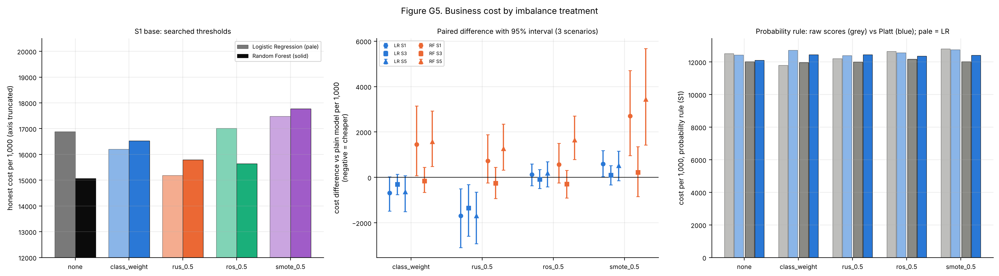

In [105]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for j, m in enumerate(MODELS_G):
    d = CT[(CT.model == m) & CT.arm.isin(MAIN) & (CT.scenario == "S1_base")].set_index("arm").loc[MAIN]
    ax[0].bar(np.arange(5) + (j - .5) * .38, d.cost_per_1000, .38, color=[ARMC[a] for a in MAIN], alpha=1 if j else .55, edgecolor=INK, lw=.5, label={"LR": "Logistic Regression (pale)", "RF": "Random Forest (solid)"}[m])
ax[0].set_xticks(range(5)); ax[0].set_xticklabels(MAIN, fontsize=8); ax[0].set_ylim(12000, 20500); ax[0].set_ylabel("honest cost per 1,000 (axis truncated)"); ax[0].set_title("S1 base: searched thresholds", fontsize=9); ax[0].legend(fontsize=7)
for j, m in enumerate(MODELS_G):
    d = CT[(CT.model == m) & CT.arm.isin(MAIN[1:])].copy(); d["x"] = d.arm.map({a: i for i, a in enumerate(MAIN[1:])}) + (j - .5) * .38 + d.scenario.map({s: (k - 1) * .11 for k, s in enumerate(CSCN)})
    for s, mk in zip(CSCN, ["o", "s", "^"]): e = d[d.scenario == s]; ax[1].errorbar(e.x, e.diff_vs_none, yerr=[e.diff_vs_none - e.ci_low, e.ci_high - e.diff_vs_none], fmt=mk, color=[BLUE, ORANGE][j], ms=5, capsize=2, label=f"{m} {s.split('_')[0]}")
ax[1].axhline(0, color=INK, lw=.8); ax[1].set_xticks(range(4)); ax[1].set_xticklabels(MAIN[1:], fontsize=8); ax[1].set_ylabel("cost difference vs plain model per 1,000\n(negative = cheaper)"); ax[1].set_title("Paired difference with 95% interval (3 scenarios)", fontsize=9); ax[1].legend(fontsize=6, ncol=2)
x = np.arange(5)
for j, m in enumerate(MODELS_G): d = CAL.loc[m].loc[MAIN]; ax[2].bar(x + (j - .5) * .38 - .09, d.rule_cost_raw, .17, color=GREY, edgecolor=INK, lw=.5, alpha=.55 if j == 0 else 1); ax[2].bar(x + (j - .5) * .38 + .09, d.rule_cost_platt, .17, color=BLUE, edgecolor=INK, lw=.5, alpha=.55 if j == 0 else 1)
ax[2].set_xticks(x); ax[2].set_xticklabels(MAIN, fontsize=8); ax[2].set_ylabel("cost per 1,000, probability rule (S1)"); ax[2].set_title("Probability rule: raw scores (grey) vs Platt (blue); pale = LR", fontsize=9)
fig.suptitle("Figure G5. Business cost by imbalance treatment", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "G05_business_cost.png", dpi=130, bbox_inches="tight"); plt.show()

### G7. Controlled resampling: how much re-balancing, if any?
Sweep of the target ratio *r* (natural 0.14, then 0.25, 0.5, 1.0) for each sampler: PR-AUC and S1 cost. If re-balancing helped, the curves would rise (PR-AUC) or fall (cost) away from the natural-ratio line.

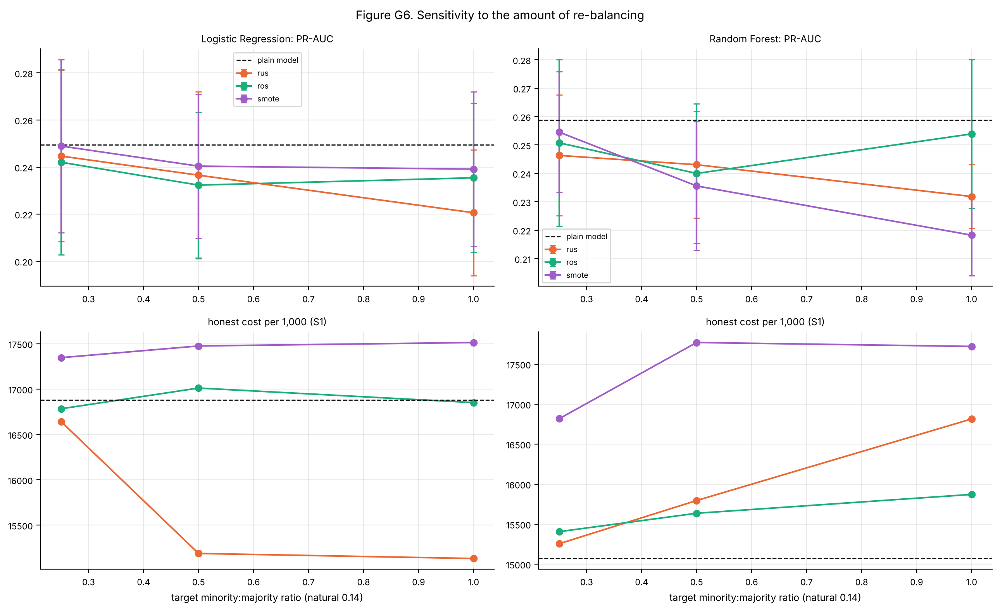

In [106]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8)); SC_ = {"rus": ORANGE, "ros": "#1aaf7a", "smote": "#a05cc8"}
for j, m in enumerate(MODELS_G):
    base_pr = RES[(m, "none")][0].pr_auc; base_c = CT[(CT.model == m) & (CT.arm == "none") & (CT.scenario == "S1_base")].cost_per_1000.iloc[0]
    for s in SAMPLERS:
        rs_ = [0.25, 0.5, 1.0]; pr = [RES[(m, f"{s}_{r}")][0].pr_auc for r in rs_]; cs = [CT[(CT.model == m) & (CT.arm == f"{s}_{r}") & (CT.scenario == "S1_base")].cost_per_1000.iloc[0] for r in rs_]
        ax[0, j].errorbar(rs_, [p.mean() for p in pr], yerr=[1.96 * p.std(ddof=1) / np.sqrt(10) for p in pr], marker="o", color=SC_[s], capsize=3, label=s); ax[1, j].plot(rs_, cs, "o-", color=SC_[s], label=s)
    ax[0, j].axhline(base_pr.mean(), color=INK, lw=1, ls="--", label="plain model"); ax[1, j].axhline(base_c, color=INK, lw=1, ls="--", label="plain model")
    ax[0, j].set_title({"LR": "Logistic Regression", "RF": "Random Forest"}[m] + ": PR-AUC", fontsize=9); ax[1, j].set_title("honest cost per 1,000 (S1)", fontsize=9); ax[1, j].set_xlabel("target minority:majority ratio (natural 0.14)"); ax[0, j].legend(fontsize=7)
fig.suptitle("Figure G6. Sensitivity to the amount of re-balancing", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "G06_ratio_sweep.png", dpi=130, bbox_inches="tight"); plt.show()

### G8. What happens if resampling is done the wrong way?
The classic mistake is to oversample the whole dataset first and cross-validate afterwards: copies of the same fraud then sit in both training and test folds. Here this is measured. Both protocols use random oversampling to *r* = 0.5, the same folds count and the same 300-tree models, and both are scored only on the **original** test rows (the appended copies are dropped), so the numbers are directly comparable. Two forests are shown: the shallow Part D forest, and an unrestricted forest that can memorise.

In [107]:
rows = []
for m in ["RF", "RF_deep"]:
    wrong = fi.leaky_oversampling_cv(m, Xg, yg, ratio=0.5); right = fi.honest_cv(m, "ros_0.5", Xg, yg, splits_g)
    for d in (wrong, right): rows.append(dict(model=m, protocol=d.protocol.iloc[0], pr_auc=d.pr_auc.mean(), recall_top10=d.recall_top10.mean(), roc_auc=d.roc_auc.mean()))
LEAK = pd.DataFrame(rows).set_index(["model", "protocol"]); display(LEAK.round(3))
for m in ["RF", "RF_deep"]:
    w, r_ = LEAK.loc[(m, "WRONG: oversample first, then split"), "pr_auc"], LEAK.loc[(m, "RIGHT: split first, oversample inside training folds"), "pr_auc"]
    print(f"{m}: PR-AUC {w:.3f} with the wrong protocol vs {r_:.3f} with the right one (inflation {w - r_:+.3f}; no-skill is {rate:.3f})")

pr_auc  recall_top10  roc_auc
model   protocol                                                                           
RF      WRONG: oversample first, then split                    0.318         0.283    0.714
        RIGHT: split first, oversample inside training folds   0.240         0.222    0.647
RF_deep WRONG: oversample first, then split                    0.922         0.813    0.960
        RIGHT: split first, oversample inside training folds   0.200         0.182    0.639

RF: PR-AUC 0.318 with the wrong protocol vs 0.240 with the right one (inflation +0.078; no-skill is 0.121)
RF_deep: PR-AUC 0.922 with the wrong protocol vs 0.200 with the right one (inflation +0.722; no-skill is 0.121)


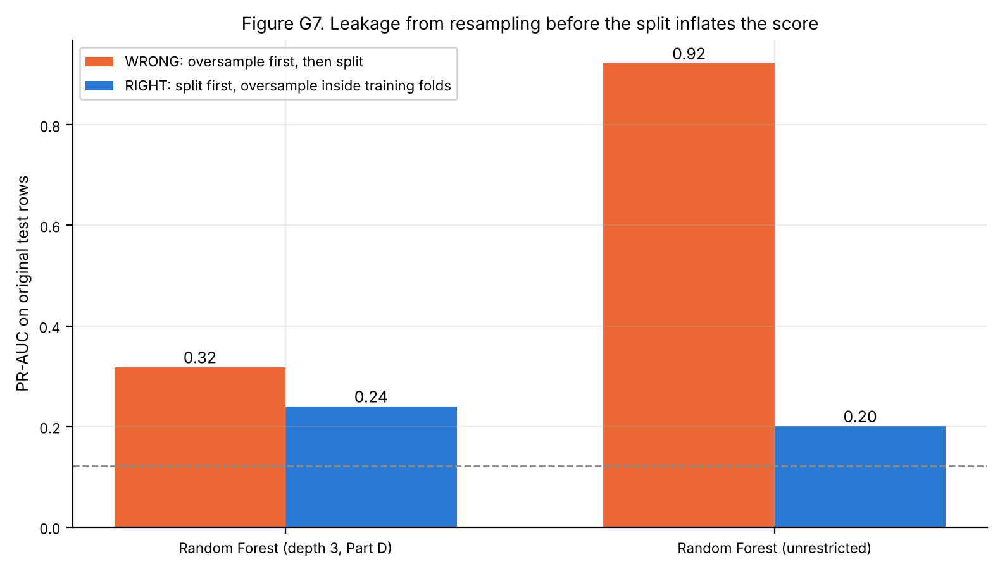

In [108]:
fig, ax = plt.subplots(figsize=(8, 4.6)); x = np.arange(2); w = .35
for k, (proto, col) in enumerate([("WRONG: oversample first, then split", ORANGE), ("RIGHT: split first, oversample inside training folds", BLUE)]):
    v = [LEAK.loc[(m, proto), "pr_auc"] for m in ["RF", "RF_deep"]]; ax.bar(x + (k - .5) * w, v, w, color=col, label=proto); [ax.text(xi + (k - .5) * w, vi + .008, f"{vi:.2f}", ha="center", fontsize=9) for xi, vi in zip(x, v)]
ax.axhline(rate, color=GREY, ls="--", lw=1); ax.set_xticks(x); ax.set_xticklabels(["Random Forest (depth 3, Part D)", "Random Forest (unrestricted)"]); ax.set_ylabel("PR-AUC on original test rows"); ax.legend(fontsize=8)
ax.set_title("Figure G7. Leakage from resampling before the split inflates the score", fontsize=10); plt.tight_layout(); plt.savefig(FIG / "G07_leakage_demo.png", dpi=130, bbox_inches="tight"); plt.show()

### G9. Decision by the pre-set rule
For each arm of each model: is PR-AUC significantly better than `none` (Holm-adjusted, corrected interval), or is S1 cost significantly lower (paired bootstrap), and is it not significantly worse on the other?

In [109]:
rows = []
for m in MODELS_G:
    for a in MAIN[1:]:
        pr = PT[(PT.model == m) & (PT.arm == a) & (PT.metric == "pr_auc")].iloc[0]; c = CT[(CT.model == m) & (CT.arm == a) & (CT.scenario == "S1_base")].iloc[0]
        pr_better = bool(pr.ci_low > 0 and pr.p_holm < 0.05); pr_worse = bool(pr.ci_high < 0); c_better = bool(c.ci_high < 0); c_worse = bool(c.ci_low > 0)
        rows.append(dict(model=m, arm=a, pr_auc_diff=pr.mean_diff, pr_ci=f"[{pr.ci_low:+.3f}, {pr.ci_high:+.3f}]", cost_diff=c.diff_vs_none, cost_ci=f"[{c.ci_low:+.0f}, {c.ci_high:+.0f}]",
                         adopt=bool((pr_better or c_better) and not pr_worse and not c_worse), significantly_worse=bool(pr_worse or c_worse)))
DEC = pd.DataFrame(rows).set_index(["model", "arm"]); display(DEC.round(4))
ADOPT_RF = bool(DEC.loc["RF"].adopt.any()); ADOPT_LR = DEC.loc["LR"].index[DEC.loc["LR"].adopt].tolist()
print("Arms adopted by the rule for the Logistic Regression:", ADOPT_LR or "none"); print("Arms adopted by the rule for the Random Forest (the production candidate):", "see table" if ADOPT_RF else "none")
lr_rus = CT[(CT.model == "LR") & (CT.arm == "rus_0.5") & (CT.scenario == "S1_base")].cost_per_1000.iloc[0]; rf_none = CT[(CT.model == "RF") & (CT.arm == "none") & (CT.scenario == "S1_base")].cost_per_1000.iloc[0]
print(f"S1 cost: plain Random Forest {rf_none:,.0f} vs best Logistic Regression arm (rus_0.5) {lr_rus:,.0f} per 1,000: the adopted LR arm does not beat the production candidate.")
print("==> production model keeps:", "see adopted arm above" if ADOPT_RF else "NO resampling and NO class weights: plain Random Forest + Part E cost-based thresholds + Part F Platt calibration")


pr_auc_diff             pr_ci  cost_diff        cost_ci  adopt  significantly_worse
model arm                                                                                              
LR    class_weight      -0.0081  [-0.025, +0.009]  -681.6303   [-1485, +31]  False                False
      rus_0.5           -0.0128  [-0.028, +0.003] -1691.6846  [-3088, -499]   True                False
      ros_0.5           -0.0170  [-0.039, +0.004]   130.8142   [-365, +594]  False                False
      smote_0.5         -0.0090  [-0.030, +0.012]   594.6442   [+39, +1186]  False                 True
RF    class_weight       0.0018  [-0.027, +0.031]  1452.2921   [+79, +3151]  False                 True
      rus_0.5           -0.0158  [-0.060, +0.028]   724.6056  [-246, +1886]  False                False
      ros_0.5           -0.0188  [-0.055, +0.018]   565.4145  [-236, +1498]  False                False
      smote_0.5         -0.0232  [-0.055, +0.009]  2699.3016  [+964, +4709]  False                 True

Arms adopted by the rule for the Logistic Regression: ['rus_0.5']
Arms adopted by the rule for the Random Forest (the production candidate): none
S1 cost: plain Random Forest 15,072 vs best Logistic Regression arm (rus_0.5) 15,189 per 1,000: the adopted LR arm does not beat the production candidate.
==> production model keeps: NO resampling and NO class weights: plain Random Forest + Part E cost-based thresholds + Part F Platt calibration


### G10. Findings

**1. The imbalance is moderate; the small number of frauds is the bigger constraint.** The 2,400 development rows hold 291 frauds (12.1%, 95% interval 10.9% to 13.5%), an imbalance ratio of 7.25 to 1. A model that always says "legitimate" is 87.9% accurate with zero recall and F1, and a no-skill model scores a PR-AUC of 0.121. Severe-imbalance problems start below about 1 fraud in 100, so heavy re-balancing is not obviously needed. What limits learning is that each test fold has only 58 to 59 frauds, and the Logistic Regression has 56 inputs for 291 frauds (5.2 frauds per input). The fold-to-fold standard deviation of PR-AUC is about 0.056, so only differences of several hundredths could be detected.

**2. No imbalance treatment improved the ranking.** Against the plain model, PR-AUC changed by -0.008 (class weights), -0.013 (undersampling), -0.017 (oversampling) and -0.009 (SMOTE) for the Logistic Regression, and by +0.002, -0.016, -0.019 and -0.023 for the Random Forest. No corrected interval excludes zero (the smallest Holm-adjusted p-value is 0.38). ROC-AUC is unchanged for the Logistic Regression with class weights and undersampling (0.669 and 0.670 against 0.669), a little lower for the Random Forest (0.654 and 0.661 against 0.665), and lower with oversampling and SMOTE (about 0.65 for both models). Recall in the top 10% of scores is 0.22 (LR) and 0.24 (RF) for the plain models and never meaningfully higher with any treatment. Class weighting leaves the ranking essentially unchanged because it only rescales the loss. The ratio sweep (r = 0.25, 0.5, 1.0) shows the same: more re-balancing never raises PR-AUC and the heaviest settings lower it (Figure G6). With this few frauds, a gain smaller than roughly 0.03 PR-AUC could not be detected either way, so the honest statement is "no evidence of a benefit", not "proof of no benefit".

**3. Metrics at the default 0.50 cut-off look better, but only because the cut-off moves.** With class weights the Logistic Regression's recall at 0.50 rises from 0.04 to 0.60 and F1 from 0.07 to 0.30, but precision falls from 0.53 to 0.20 and it flags 36% of all transactions (against 1%). The Random Forest goes from flagging nothing (F1 0) to flagging 34% (F1 0.27). The ranking is the same; the cut-off simply moved into a useful region. That is exactly what the Part E cost-based thresholds do on the plain model, so F1 at 0.50 is not used to choose an arm.

**4. Business cost: for the production model nothing beats the plain Random Forest.** At honest cost-optimal thresholds the plain Random Forest costs 15,072 per 1,000 transactions in the base scenario. Every treatment is dearer: class weights +1,452 [+79, +3,151], undersampling +725 [-246, +1,886], oversampling +565 [-236, +1,498], SMOTE +2,699 [+964, +4,709]; in the cheap-review scenario S5 all four are significantly dearer (+1,266 to +3,443), and in S3 there is no difference. In the ratio sweep the Random Forest cost rises with the amount of re-balancing for every sampler. For the Logistic Regression, undersampling to r = 0.5 is cheaper in all three scenarios (base -1,692 [-3,088, -499]; S3 -1,345; S5 -1,692), so **the pre-set rule adopts it for the Logistic Regression**. I do not treat this as a finding to act on: the Logistic Regression is not the production model; its adopted arm (15,189) is still no cheaper than the plain Random Forest (15,072); it is one significant result among eight model-arm combinations, so chance cannot be excluded; its PR-AUC is not higher (-0.013); and I have not established why it lowers cost. For the Random Forest the rule adopts nothing.

**5. Re-balancing ruins the raw probabilities, which Part F needs.** The mean predicted fraud probability rises from 0.12 (the true rate) to 0.43 to 0.46 with class weights and 0.23 to 0.32 with resampling. The expected calibration error rises from about 0.02 to 0.11 to 0.34 and the Brier score from 0.10 to 0.12 to 0.22. Platt scaling repairs this completely (ECE 0.015 to 0.020, Brier 0.102 to 0.104), which returns the model to exactly the plain model's quality, with nothing gained from the re-balancing. Anything that treats the score as a probability (the Part F break-even rule, expected-loss forecasts) must therefore recalibrate after class weights or resampling. In the probability-rule cost (S1) the arms differ by a few hundred per 1,000 with no consistent pattern; one point estimate (LR with class weights on raw scores, 11,795) is lower than all Platt versions, which I read as an accidental side-effect of inflating the probabilities relative to the amounts (it changes which transactions the rule favours), not as evidence for class weighting. It was not tested and will be looked at again in Part I.

**6. Resampling inside the pipeline is enforced and tested; doing it wrongly is very costly.** The built-in test (G2) shows that in every fold the sampler is called once, on exactly the training rows and training frauds, and never during prediction. Oversampling the whole dataset before cross-validation inflates the Random Forest's PR-AUC from 0.240 to 0.318, and an unrestricted forest from 0.200 to 0.922 (ROC-AUC 0.96 against 0.64), because copies of the same fraud sit on both sides of the split.

**7. Decision.** The production Random Forest keeps **no class weights and no resampling**. Imbalance is handled by (i) stratified folds, (ii) PR-AUC, top-10% recall and business cost as the primary metrics, (iii) the cost-based, amount-aware decisions of Parts E and F, and (iv) Platt calibration. Re-balancing remains available as a documented option and would be re-tested if the fraud rate fell substantially.

**Caveats.** Model settings were fixed from Part D (tuned on the whole development set), so absolute Random Forest scores are a little optimistic (PR-AUC 0.259 against 0.249 in the nested estimate), identically in every arm; settings such as tree depth were not re-tuned for each treatment, which could favour re-balancing slightly. SMOTE interpolates between one-hot columns, which can produce fractional categories. The wide intervals (291 frauds) cannot rule out small benefits. All costs are hypothetical. The hold-out set was not read.

In [110]:
IMB.to_frame("value").to_csv(OUT / "G_imbalance_quantification.csv"); SUM.to_csv(OUT / "G_arm_metrics_mean.csv"); SD.to_csv(OUT / "G_arm_metrics_sd.csv"); ALLF.to_csv(OUT / "G_fold_metrics.csv", index=False)
PT.to_csv(OUT / "G_paired_tests_pr_auc.csv", index=False); CT.to_csv(OUT / "G_cost_by_arm.csv", index=False); CAL.to_csv(OUT / "G_calibration_by_arm.csv"); LEAK.to_csv(OUT / "G_leakage_demo.csv"); DEC.to_csv(OUT / "G_decision.csv"); IT.to_csv(OUT / "G_integrity_test.csv", index=False)
print("Part G tables saved; figures:", sorted(p.name for p in FIG.glob("G*.png")), "| hold-out rows read: none")

Part G tables saved; figures: ['G01_class_imbalance.png', 'G02_ranking_metrics.png', 'G03_pr_curves.png', 'G04_threshold_05_metrics.png', 'G05_business_cost.png', 'G06_ratio_sweep.png', 'G07_leakage_demo.png'] | hold-out rows read: none


---
## Part H. Explainable AI

**Goal:** explain what the production model (the Random Forest of Parts D to G, with the Part F Platt layer) bases its fraud scores on, globally and transaction by transaction; find explanations that are unstable or counterintuitive; and keep prediction clearly separate from causation.

| Task H requirement | Section |
|---|---|
| SHAP or a comparable framework | H1 (SHAP TreeExplainer); permutation importance (Part D) and partial dependence as independent cross-checks in H2 and H4 |
| Global feature importance | H2 |
| Dependence and interaction analysis | H3, H4 |
| At least five transaction-level explanations | H5 (seven cases) and the reason-code export in H9 |
| Unstable or counterintuitive explanations | H6, H7 |
| Prediction versus causal inference | H8 |

**How to read SHAP here.** SHAP splits one prediction into additive contributions: *model probability = base rate + sum of contributions*, checked numerically for every row. A contribution of +4 pts means "this input moved the model's fraud probability up by 4 percentage points relative to a typical transaction". It describes the **model**, not the world.

**Design (fixed before looking at any explanation)**
1. **Model explained:** the Part D final Random Forest (fitted on all 2,400 development rows). SHAP is computed on the development rows only; the hold-out set is not read. The Platt layer of Part F is almost the identity (slope 1.03), so explanations are given in the model's own probability scale and described as the calibrated probability.
2. **Three levels, same maths.** The model sees 74 encoded inputs. Contributions are added up inside groups, which does not change SHAP's additivity: **units** (41: a one-hot block becomes its field, a missing-value flag joins its field, an engineered feature keeps its own name), **families** (9 business themes, table in H1), and **source fields** (23 raw fields; an engineered feature's contribution is split equally between the raw fields it is built from, a documented simplification that makes SHAP comparable with Part D's raw-field permutation importance).
3. **Why levels matter:** the same information enters the model several times (for example `new_device` also sits inside `n_red_flags`, `newdev_x_iprisk`, `newdev_x_logdist` and `billmis_x_newdev`), and SHAP shares the credit between such copies. Single-input rankings can therefore understate a driver; family and source-field views are the safer reading.
4. **Expected directions are written down now (table in H7)** from Parts B to D and domain reasoning, before the explanations are inspected, so "counterintuitive" has a fixed meaning.
5. **Stability is measured, not assumed:** 30 bootstrap refits of the whole pipeline (features, encoding, forest) re-explain the same rows; global rankings and each individual explanation are compared across refits. A noise yardstick comes from 20 refits on label-shuffled data ("null importances").
6. **Cross-checks that use other frameworks:** Part D permutation importance, partial dependence (PDP) and the Logistic Regression odds ratios.

### H1. Computing SHAP for the production model

In [111]:
import joblib, json
import fraud_features as ff, fraud_models as fm_h, fraud_explain as fx, fraud_calibration as fcal_h, fraud_costs as fc_h
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score
from sklearn.inspection import partial_dependence
from scipy.stats import spearmanr
SEED_H = 42
Xh, yh, idh = fm_h.load_dev(); NH = len(yh); yv = yh.values
pipe_h = joblib.load(OUT / "models" / "D_RF.joblib"); EXPL = fx.FraudExplainer(pipe_h); SH = EXPL.explain(Xh)
CALJ = json.load(open(OUT / "F_calibration_choice.json")); T1c, T2c = CALJ["thresholds_calibrated"]["t_review"], CALJ["thresholds_calibrated"]["t_block"]
def platt(p): return fcal_h.sigmoid(CALJ["platt"]["intercept"] + CALJ["platt"]["slope"] * fcal_h.logit(p))
oofH = pd.read_csv(OUT / "D_oof_predictions.csv"); assert (oofH.transaction_id.values == idh.values).all()
meta_h = pd.DataFrame({ID: idh.values}).merge(df, on=ID, how="left"); amt_h = meta_h.transaction_amount.fillna(meta_h.transaction_amount.median()).to_numpy()
print(f"Explained model: Random Forest, {len(EXPL.enc_names)} encoded inputs -> {len(EXPL.units)} units -> {len(fx.FAMILIES)} families")
print(f"Base value (average model probability) = {SH.base:.4f}; additivity check passed for all {NH} rows (base + sum of contributions = model probability)")
FAM_TABLE = pd.DataFrame([(f, u) for f, us in fx.FAMILIES.items() for u in us], columns=["family", "unit"]); assert set(FAM_TABLE.unit) == set(EXPL.units)
display(FAM_TABLE.groupby("family").unit.apply(lambda s: ", ".join(s)).to_frame("units in the family"))
# independent check of the explainer: interventional SHAP (breaks feature correlations) on a subset vs the default path-dependent SHAP
sub = Xh.sample(400, random_state=SEED_H); bg = EXPL.encode(Xh.sample(200, random_state=1))[1]
alt = EXPL.explain(sub, background=bg); ref = SH.phi.loc[sub.index]
rho_alt = float(np.mean([spearmanr(alt.phi[u], ref[u])[0] for u in EXPL.units if ref[u].std() > 1e-9 and alt.phi[u].std() > 1e-9]))
rank_alt = spearmanr(alt.phi.abs().mean(), ref.abs().mean())[0]
print(f"Two SHAP variants (path-dependent vs interventional with a 200-row background) agree: mean per-unit correlation {rho_alt:.2f}; rank correlation of global importance {rank_alt:.2f}")

Explained model: Random Forest, 74 encoded inputs -> 41 units -> 9 families
Base value (average model probability) = 0.1215; additivity check passed for all 2400 rows (base + sum of contributions = model probability)


,units in the family
family,
Account and customer profile,"account_age_days, email_age_days, login_to_transaction_minutes, customer_tier"
Amount,transaction_amount
Chargeback history and red flags,"prior_chargebacks, failed_logins_24h, n_red_flags"
Device and authentication,"new_device, device_age_days, device_type, authentication_level, authmiss_x_digital, newdev_x_logdist, billmis_x_newd..."
Location,"distance_from_usual_location_km, country"
Merchant and IP risk scores,"merchant_risk_score, ip_risk_score, risk_mean, risk_max, risk_product, high_risk_both, logamt_x_merchrisk, newdev_x_..."
Merchant and channel context,"merchant_category, channel, card_presence"
Time of day,"hour, day_of_week, is_night, is_business_hours, hour_sin, hour_cos"
Transaction velocity,"transactions_last_1h, transactions_last_24h, velocity_ratio_1h_24h, velocity_surge, log_tx_24h, velocity_x_logamt"


Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


Two SHAP variants (path-dependent vs interventional with a 200-row background) agree: mean per-unit correlation 0.98; rank correlation of global importance 0.99


### H2. Global feature importance
Mean absolute SHAP value (probability points) is the average size of a feature's push on a transaction's score, in either direction. Three views of the same numbers, then a comparison with two independent methods.

In [112]:
SRC = {"velocity_ratio_1h_24h": ["transactions_last_1h", "transactions_last_24h"], "velocity_surge": ["transactions_last_1h", "transactions_last_24h"], "log_tx_24h": ["transactions_last_24h"],
       "risk_mean": ["merchant_risk_score", "ip_risk_score"], "risk_max": ["merchant_risk_score", "ip_risk_score"], "risk_product": ["merchant_risk_score", "ip_risk_score"], "high_risk_both": ["merchant_risk_score", "ip_risk_score"],
       "n_red_flags": ["new_device", "billing_address_mismatch", "prior_chargebacks", "failed_logins_24h", "authentication_level"],
       "is_night": ["hour"], "is_business_hours": ["hour"], "hour_sin": ["hour"], "hour_cos": ["hour"], "newdev_x_logdist": ["new_device", "distance_from_usual_location_km"],
       "logamt_x_merchrisk": ["transaction_amount", "merchant_risk_score"], "authmiss_x_digital": ["authentication_level", "channel"], "newdev_x_iprisk": ["new_device", "ip_risk_score"],
       "billmis_x_newdev": ["billing_address_mismatch", "new_device"], "velocity_x_logamt": ["transactions_last_1h", "transaction_amount"]}
SOURCES = [u for u in EXPL.units if u not in SRC]; assert len(SOURCES) == 23
S_MAT = np.zeros((len(EXPL.units), len(SOURCES)))
for i, u in enumerate(EXPL.units):
    for s in SRC.get(u, [u]): S_MAT[i, SOURCES.index(s)] = 1.0 / len(SRC.get(u, [u]))
def to_family(phi): return pd.DataFrame({f: phi[[u for u in us]].sum(axis=1) for f, us in fx.FAMILIES.items()})
def to_source(phi): return pd.DataFrame(phi[EXPL.units].values @ S_MAT, index=phi.index, columns=SOURCES)
IMP_U = SH.phi.abs().mean().sort_values(ascending=False) * 100; IMP_F = to_family(SH.phi).abs().mean().sort_values(ascending=False) * 100; IMP_S = to_source(SH.phi).abs().mean().sort_values(ascending=False) * 100
perm = pd.read_csv(OUT / "D_importance_consensus.csv").set_index("feature").RF_importance
cmp = pd.DataFrame({"SHAP_source_pts": IMP_S, "SHAP_rank": IMP_S.rank(ascending=False)}).join(perm.rename("permutation_importance").to_frame()); cmp["permutation_rank"] = cmp.permutation_importance.rank(ascending=False)
rho_perm = spearmanr(cmp.SHAP_rank, cmp.permutation_rank)[0]
print("Top 12 units (mean |SHAP|, probability points):"); display(IMP_U.head(12).round(3).to_frame("mean_abs_shap_pts"))
print("Families:"); display(IMP_F.round(3).to_frame("mean_abs_shap_pts"))
print("Source fields vs Part D permutation importance (Random Forest, outer folds):"); display(cmp.sort_values("SHAP_rank").head(12).round(3))
print(f"Rank correlation SHAP (source fields) vs permutation importance, all 23 fields: Spearman {rho_perm:.2f}")
top5_s, top5_p = set(cmp.nsmallest(5, "SHAP_rank").index), set(cmp.nsmallest(5, "permutation_rank").index); print("Top 5 by SHAP:", sorted(top5_s), "| Top 5 by permutation:", sorted(top5_p), "| overlap:", len(top5_s & top5_p))

Top 12 units (mean |SHAP|, probability points):


,mean_abs_shap_pts
n_red_flags,1.633
risk_mean,0.910
velocity_x_logamt,0.901
transaction_amount,0.735
newdev_x_iprisk,0.472
logamt_x_merchrisk,0.457
merchant_risk_score,0.434
velocity_surge,0.394
risk_product,0.357
newdev_x_logdist,0.337


Families:


,mean_abs_shap_pts
Merchant and IP risk scores,2.335
Chargeback history and red flags,1.701
Transaction velocity,1.442
Amount,0.735
Device and authentication,0.453
Account and customer profile,0.255
Merchant and channel context,0.111
Location,0.087
Time of day,0.059


Source fields vs Part D permutation importance (Random Forest, outer folds):


,SHAP_source_pts,SHAP_rank,permutation_importance,permutation_rank
merchant_risk_score,1.247,1.0,0.030,2.0
transaction_amount,1.027,2.0,0.017,5.0
ip_risk_score,0.910,3.0,0.012,8.0
transactions_last_1h,0.717,4.0,0.018,4.0
new_device,0.679,5.0,0.038,1.0
prior_chargebacks,0.447,6.0,0.015,6.0
authentication_level,0.404,7.0,0.019,3.0
billing_address_mismatch,0.338,8.0,0.014,7.0
failed_logins_24h,0.335,9.0,0.004,11.0
transactions_last_24h,0.305,10.0,0.002,13.0


Rank correlation SHAP (source fields) vs permutation importance, all 23 fields: Spearman 0.84
Top 5 by SHAP: ['ip_risk_score', 'merchant_risk_score', 'new_device', 'transaction_amount', 'transactions_last_1h'] | Top 5 by permutation: ['authentication_level', 'merchant_risk_score', 'new_device', 'transaction_amount', 'transactions_last_1h'] | overlap: 4


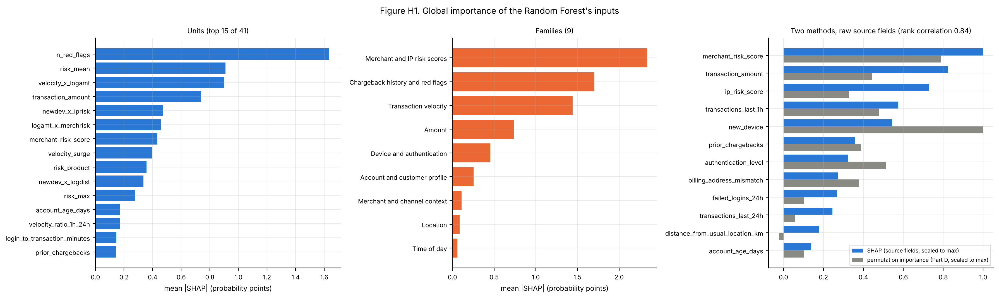

In [113]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.4), gridspec_kw=dict(width_ratios=[1.2, 1, 1.1]))
d = IMP_U.head(15)[::-1]; ax[0].barh(d.index, d.values, color=BLUE); ax[0].set_xlabel("mean |SHAP| (probability points)"); ax[0].set_title("Units (top 15 of 41)", fontsize=9)
d = IMP_F[::-1]; ax[1].barh(d.index, d.values, color=ORANGE); ax[1].set_xlabel("mean |SHAP| (probability points)"); ax[1].set_title("Families (9)", fontsize=9)
c2 = cmp.sort_values("SHAP_rank").head(12)[::-1]; yy = np.arange(len(c2)); ax[2].barh(yy + .2, c2.SHAP_source_pts / c2.SHAP_source_pts.max(), .4, color=BLUE, label="SHAP (source fields, scaled to max)"); ax[2].barh(yy - .2, c2.permutation_importance.fillna(0) / cmp.permutation_importance.max(), .4, color=GREY, label="permutation importance (Part D, scaled to max)")
ax[2].set_yticks(yy); ax[2].set_yticklabels(c2.index, fontsize=8); ax[2].legend(fontsize=7, loc="lower right"); ax[2].set_title(f"Two methods, raw source fields (rank correlation {rho_perm:.2f})", fontsize=9)
fig.suptitle("Figure H1. Global importance of the Random Forest's inputs", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "H01_global_importance.png", dpi=130, bbox_inches="tight"); plt.show()

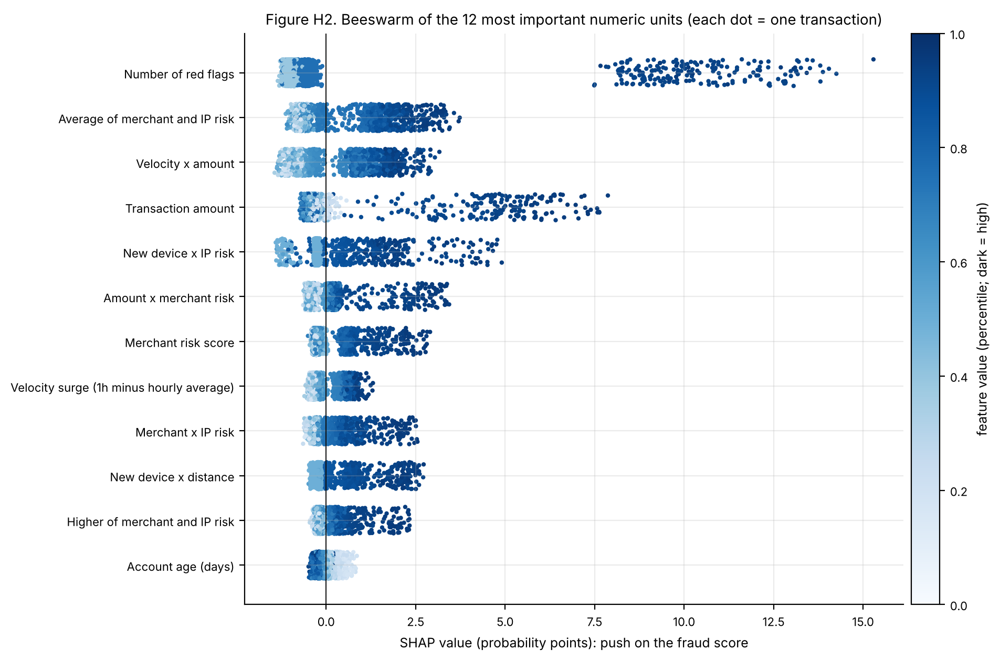

In [114]:
NUMU = [u for u in IMP_U.index if not isinstance(SH.values[u].iloc[0], str) and u not in ("device_type",)]
top12 = [u for u in NUMU if SH.values[u].dtype != object][:12]; rng_b = np.random.default_rng(SEED_H)
fig, ax = plt.subplots(figsize=(10, 6.4))
for k, u in enumerate(top12[::-1]):
    v = pd.to_numeric(SH.values[u], errors="coerce"); rk = v.rank(pct=True).fillna(.5).values; ax.scatter(SH.phi[u].values * 100, k + rng_b.uniform(-.3, .3, NH), c=rk, cmap="Blues", vmin=-.2, vmax=1.05, s=9, edgecolors="none")
ax.set_yticks(range(len(top12))); ax.set_yticklabels([fx.LABELS.get(u, u) for u in top12[::-1]], fontsize=8); ax.axvline(0, color=INK, lw=.7); ax.set_xlabel("SHAP value (probability points): push on the fraud score")
sm = plt.cm.ScalarMappable(cmap="Blues", norm=plt.Normalize(0, 1)); cb = plt.colorbar(sm, ax=ax, pad=.01); cb.set_label("feature value (percentile; dark = high)")
ax.set_title("Figure H2. Beeswarm of the 12 most important numeric units (each dot = one transaction)", fontsize=10); plt.tight_layout(); plt.savefig(FIG / "H02_beeswarm.png", dpi=130, bbox_inches="tight"); plt.show()

### H3. Interaction analysis
SHAP interaction values split each prediction into main effects and pairwise effects (they add up exactly). Below: how much of the total SHAP magnitude comes from pairs rather than single inputs, and which pairs are strongest. Part B found **no statistically significant interactions** in the data, so a large interaction here would need an explanation.

Share of total SHAP magnitude carried by single-input (main) effects: 64.6%; by pairwise interactions: 35.4%


,unit_a,unit_b,mean_abs_interaction_pts,share_source_field,shared
0,n_red_flags,newdev_x_iprisk,0.334,True,new_device
1,account_age_days,n_red_flags,0.091,False,
2,velocity_ratio_1h_24h,n_red_flags,0.078,False,
3,risk_mean,velocity_x_logamt,0.078,False,
4,n_red_flags,velocity_x_logamt,0.073,False,
5,risk_mean,n_red_flags,0.070,False,
6,prior_chargebacks,risk_mean,0.067,False,
7,ip_risk_score,n_red_flags,0.066,False,
8,risk_product,n_red_flags,0.062,False,
9,transaction_amount,n_red_flags,0.061,False,


Of the 20 strongest pairs, 2 combine two inputs that contain the SAME raw field (e.g. new_device appears in n_red_flags and in newdev_x_iprisk).
Interaction strength between inputs that share NO raw field (strongest 6):


,unit_a,unit_b,mean_abs_interaction_pts,share_source_field,shared
1,account_age_days,n_red_flags,0.091,False,
2,velocity_ratio_1h_24h,n_red_flags,0.078,False,
3,risk_mean,velocity_x_logamt,0.078,False,
4,n_red_flags,velocity_x_logamt,0.073,False,
5,risk_mean,n_red_flags,0.070,False,
6,prior_chargebacks,risk_mean,0.067,False,


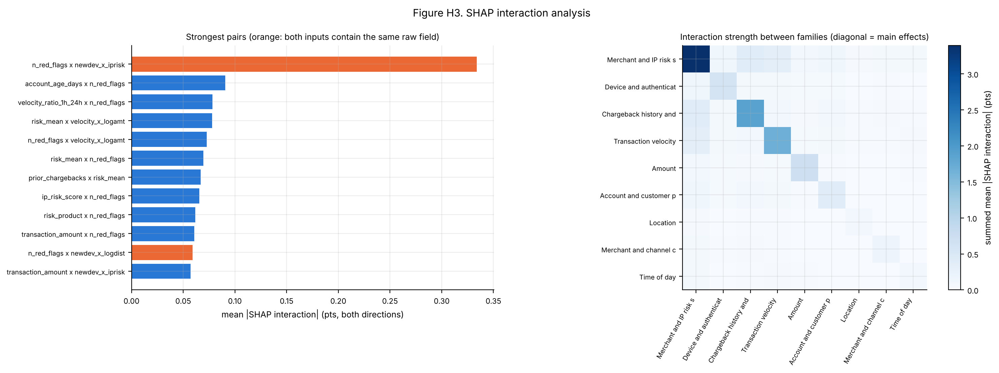

In [115]:
A_I, FULL_I = EXPL.interaction_units(SH.Z); U_ = EXPL.units; off = A_I.copy(); np.fill_diagonal(off, 0)
main_share = float(np.diag(A_I).sum() / (np.diag(A_I).sum() + off.sum()))
src_sets = {u: set(SRC.get(u, [u])) for u in U_}
iu = np.triu_indices(len(U_), 1); rows = [dict(unit_a=U_[i], unit_b=U_[j], mean_abs_interaction_pts=off[i, j] * 2 * 100, share_source_field=bool(src_sets[U_[i]] & src_sets[U_[j]]), shared=", ".join(sorted(src_sets[U_[i]] & src_sets[U_[j]]))) for i, j in zip(*iu)]
INT = pd.DataFrame(rows).sort_values("mean_abs_interaction_pts", ascending=False).reset_index(drop=True)
print(f"Share of total SHAP magnitude carried by single-input (main) effects: {main_share:.1%}; by pairwise interactions: {1 - main_share:.1%}")
display(INT.head(12).round(3))
top_int = INT.head(20); print(f"Of the 20 strongest pairs, {int(top_int.share_source_field.sum())} combine two inputs that contain the SAME raw field (e.g. new_device appears in n_red_flags and in newdev_x_iprisk).")
print("Interaction strength between inputs that share NO raw field (strongest 6):"); display(INT[~INT.share_source_field].head(6).round(3))
fam_of = [fx.FAMILY_OF[u] for u in U_]; fam_names = list(fx.FAMILIES); IF = np.zeros((9, 9))
for i in range(len(U_)):
    for j in range(len(U_)): IF[fam_names.index(fam_of[i]), fam_names.index(fam_of[j])] += A_I[i, j] * (1 if i == j else 1) * 100
fig, ax = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw=dict(width_ratios=[1, 1.2]))
d = INT.head(12)[::-1]; ax[0].barh([f"{a} x {b}" for a, b in zip(d.unit_a, d.unit_b)], d.mean_abs_interaction_pts, color=[ORANGE if s else BLUE for s in d.share_source_field]); ax[0].set_xlabel("mean |SHAP interaction| (pts, both directions)"); ax[0].tick_params(axis="y", labelsize=7)
ax[0].set_title("Strongest pairs (orange: both inputs contain the same raw field)", fontsize=9)
im = ax[1].imshow(IF, cmap="Blues"); ax[1].set_xticks(range(9)); ax[1].set_xticklabels([f[:22] for f in fam_names], rotation=60, ha="right", fontsize=7); ax[1].set_yticks(range(9)); ax[1].set_yticklabels([f[:22] for f in fam_names], fontsize=7); plt.colorbar(im, ax=ax[1], fraction=.04, label="summed mean |SHAP interaction| (pts)")
ax[1].set_title("Interaction strength between families (diagonal = main effects)", fontsize=9)
fig.suptitle("Figure H3. SHAP interaction analysis", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "H03_interactions.png", dpi=130, bbox_inches="tight"); plt.show()

### H4. Dependence analysis: how does the score move with a feature?
Each dot is a transaction: x = the feature's value, y = its SHAP contribution; colour = the value of the input it interacts with most (from H3); the line is the median in 10 equal-count bins. As an independent check, **partial dependence** (PDP, model-agnostic: change one raw field for every transaction, recompute all engineered features, average the model's probability) is compared with SHAP for every raw numeric field.

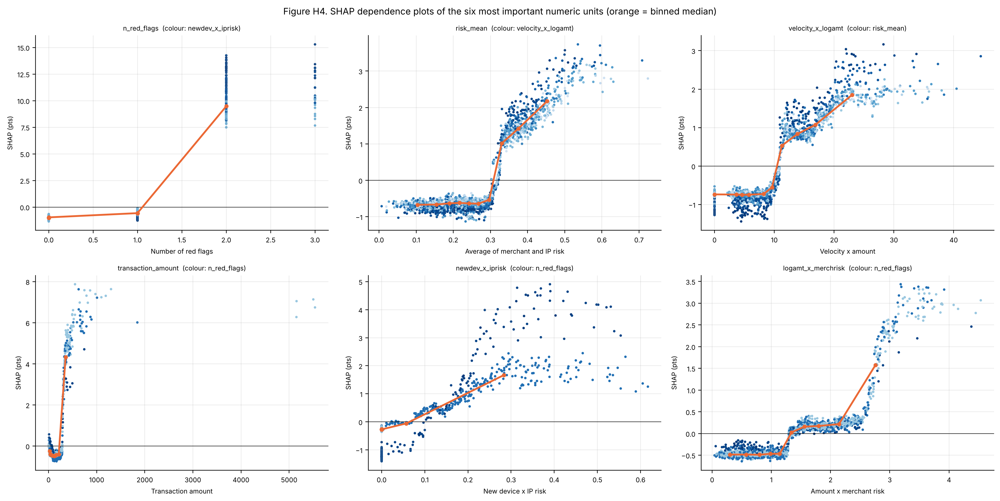

In [116]:
dep_units = [u for u in IMP_U.index if u in NUMU and u in top12][:6]
fig, ax = plt.subplots(2, 3, figsize=(17, 8.6)); ax = ax.ravel()
for a, u in zip(ax, dep_units):
    v = pd.to_numeric(SH.values[u], errors="coerce"); partner = max([w for w in U_ if w != u and w in NUMU], key=lambda w: off[U_.index(u), U_.index(w)]); pv = pd.to_numeric(SH.values[partner], errors="coerce").rank(pct=True).fillna(.5)
    sc_ = a.scatter(v, SH.phi[u] * 100, c=pv, cmap="Blues", vmin=-.2, vmax=1.05, s=9, edgecolors="none"); a.axhline(0, color=INK, lw=.6)
    b_ = pd.qcut(v.rank(method="first"), 10, labels=False); med = pd.DataFrame({"x": v, "y": SH.phi[u] * 100, "b": b_}).groupby("b").median(); a.plot(med.x, med.y, color=ORANGE, lw=2.2, marker="o", ms=4)
    a.set_xlabel(fx.LABELS.get(u, u), fontsize=8); a.set_ylabel("SHAP (pts)", fontsize=8); a.set_title(f"{u}  (colour: {partner})", fontsize=8)
fig.suptitle("Figure H4. SHAP dependence plots of the six most important numeric units (orange = binned median)", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "H04_dependence.png", dpi=130, bbox_inches="tight"); plt.show()

,pdp_range_pts,pdp_direction,shap_direction,agree_sign
field,,,,
merchant_risk_score,10.319,1.000,0.794,True
transaction_amount,7.329,0.995,0.359,True
new_device,6.222,1.000,0.624,True
ip_risk_score,5.356,1.000,0.576,True
prior_chargebacks,4.030,1.000,0.518,True
transactions_last_1h,4.011,0.964,0.876,True
failed_logins_24h,3.733,1.000,0.182,True
billing_address_mismatch,3.603,1.000,0.464,True
login_to_transaction_minutes,1.464,-0.738,-0.667,True


Rank correlation, PDP effect range vs SHAP source importance: 0.93; direction agrees in 13 of 14 fields where both show a clear direction


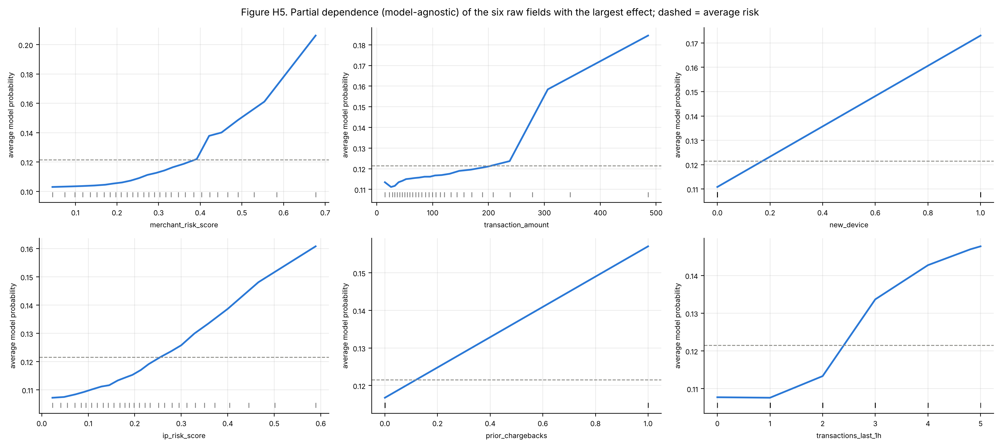

In [117]:
RAWNUM = [c for c in ff.NUM_BASE if c not in ("new_device", "billing_address_mismatch", "hour", "day_of_week")] + ["new_device", "billing_address_mismatch"]; PDP = {}
for c in RAWNUM:
    xs = pd.to_numeric(Xh[c], errors="coerce"); grid = np.unique(np.nanpercentile(xs, np.linspace(2, 98, 20))); avg = []
    for gv in grid: Xg = Xh.copy(); Xg[c] = gv; avg.append(pipe_h.predict_proba(Xg)[:, 1].mean())
    PDP[c] = (grid, np.asarray(avg))
SRC_PHI = to_source(SH.phi); rows = []
for c in RAWNUM:
    g, p = PDP[c]; d_pdp = spearmanr(g, p)[0] if len(g) > 2 else np.sign(p[-1] - p[0]); d_shap = spearmanr(pd.to_numeric(Xh[c], errors="coerce"), SRC_PHI[c], nan_policy="omit")[0]
    rows.append(dict(field=c, pdp_range_pts=(p.max() - p.min()) * 100, pdp_direction=d_pdp, shap_direction=d_shap, agree_sign=bool(np.sign(d_pdp) == np.sign(d_shap)) if abs(d_pdp) > .15 and abs(d_shap) > .15 else np.nan))
PDPT = pd.DataFrame(rows).set_index("field").sort_values("pdp_range_pts", ascending=False); display(PDPT.round(3))
rho_pdp = spearmanr(PDPT.pdp_range_pts, IMP_S.reindex(PDPT.index))[0]; print(f"Rank correlation, PDP effect range vs SHAP source importance: {rho_pdp:.2f}; direction agrees in {int((PDPT.agree_sign == True).sum())} of {int(PDPT.agree_sign.notna().sum())} fields where both show a clear direction")
fig, ax = plt.subplots(2, 3, figsize=(16, 7.2)); ax = ax.ravel()
for a, c in zip(ax, PDPT.index[:6]):
    g, p = PDP[c]; a.plot(g, p, color=BLUE, lw=2); a.axhline(SH.base, color=GREY, ls="--", lw=1); a.set_xlabel(c, fontsize=8); a.set_ylabel("average model probability", fontsize=8); rug = np.nanpercentile(pd.to_numeric(Xh[c]), np.linspace(2, 98, 30)); a.plot(rug, np.full_like(rug, a.get_ylim()[0]), "|", color=INK, alpha=.5)
fig.suptitle("Figure H5. Partial dependence (model-agnostic) of the six raw fields with the largest effect; dashed = average risk", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "H05_partial_dependence.png", dpi=130, bbox_inches="tight"); plt.show()

### H5. Transaction-level explanations (seven cases)
Cases are chosen by **rule**, not cherry-picked, using the explained model's own Platt-calibrated probability against the Part E thresholds (review from 0.158, block from 0.212). These scores are in-sample (the model has seen the rows), so the decisions shown are for illustration of the explanations; honest out-of-fold probabilities are listed beside them and differ because the out-of-fold models were re-tuned inside each fold. The rules: the highest-scoring blocked fraud; the blocked legitimate customer with the largest amount; a reviewed fraud and a reviewed legitimate customer near the middle of the review band; the approved fraud with the largest amount (a miss); the transaction closest to the block threshold; and an approved legitimate transaction on a new device (a red flag that did not raise the score). Why in-sample: an explanation must be of the model that produced the score, and mixing in out-of-fold scores of different models would explain a number the explained model never gave.

In [118]:
poof_o = platt(oofH.p_RF_r0.clip(1e-3, 1 - 1e-3).values); pfin = platt(SH.prob); poof = pfin; act = np.where(poof >= T2c, 2, np.where(poof >= T1c, 1, 0)); ACT = {0: "Approve", 1: "Review", 2: "Block"}
dfc = pd.DataFrame({"i": np.arange(NH), "fraud": yv, "p_oof": poof, "action": act, "amount": amt_h, "new_device": Xh.new_device.values})
def pick(mask, key, asc=False): d = dfc[mask].sort_values(key, ascending=asc); return int(d.i.iloc[0])
mid = (T1c + T2c) / 2
cases = {"1 Blocked fraud (highest score)": pick((dfc.action == 2) & (dfc.fraud == 1), "p_oof"),
         "2 Blocked legitimate customer (largest amount)": pick((dfc.action == 2) & (dfc.fraud == 0), "amount"),
         "3 Reviewed fraud (mid review band)": pick((dfc.action == 1) & (dfc.fraud == 1), "p_oof", True) if False else int(dfc[(dfc.action == 1) & (dfc.fraud == 1)].assign(d=lambda t: (t.p_oof - (T1c + T2c) / 2).abs()).sort_values("d").i.iloc[0]),
         "4 Reviewed legitimate (mid review band)": int(dfc[(dfc.action == 1) & (dfc.fraud == 0)].assign(d=lambda t: (t.p_oof - (T1c + T2c) / 2).abs()).sort_values("d").i.iloc[0]),
         "5 Missed fraud (approved, largest amount)": pick((dfc.action == 0) & (dfc.fraud == 1), "amount"),
         "6 Closest to the block threshold": int(dfc.assign(d=(dfc.p_oof - T2c).abs()).sort_values("d").i.iloc[0]),
         "7 Approved legitimate on a new device": pick((dfc.action == 0) & (dfc.fraud == 0) & (dfc.new_device == 1), "p_oof", True)}
assert len(set(cases.values())) == 7
rows = []
for name, i in cases.items():
    up, dn = fx.reason_text(SH.phi.iloc[i], SH.values.iloc[i], k=3)
    rows.append({"case": name, "transaction_id": idh.iloc[i], "outcome": "fraud" if yv[i] else "legitimate", "amount": round(amt_h[i], 2), "p_model_calibrated": round(float(pfin[i]), 3), "p_oof_calibrated": round(poof_o[i], 3), "decision": ACT[act[i]], "raises the score": up, "lowers the score": dn})
CASES = pd.DataFrame(rows); pd.set_option("display.max_colwidth", 200); display(CASES.set_index("case").T)

case,1 Blocked fraud (highest score),2 Blocked legitimate customer (largest amount),3 Reviewed fraud (mid review band),4 Reviewed legitimate (mid review band),"5 Missed fraud (approved, largest amount)",6 Closest to the block threshold,7 Approved legitimate on a new device
transaction_id,TXN5000260,TXN5001753,TXN5000818,TXN5001337,TXN5001639,TXN5000897,TXN5001272
outcome,fraud,legitimate,fraud,legitimate,fraud,legitimate,legitimate
amount,102.98,891.84,376.17,104.87,492.14,336.45,63.87
p_model_calibrated,0.438,0.239,0.185,0.186,0.15,0.212,0.079
p_oof_calibrated,0.386,0.329,0.187,0.258,0.103,0.176,0.088
decision,Block,Block,Review,Review,Approve,Review,Approve
raises the score,Number of red flags = 2 (+11.4 pts); Average of merchant and IP risk = 0.49 (+3.0 pts); Velocity x amount = 23.22 (+2.5 pts),Transaction amount = 891.84 (+6.2 pts); Amount x merchant risk = 3.06 (+2.4 pts); Velocity x amount = 20.38 (+1.7 pts),Transaction amount = 376.17 (+5.4 pts); Velocity x amount = 11.87 (+1.0 pts); New device x IP risk = 0.11 (+0.4 pts),Average of merchant and IP risk = 0.41 (+1.6 pts); Velocity x amount = 18.65 (+1.6 pts); New device x IP risk = 0.6 (+1.4 pts),Transaction amount = 492.14 (+6.4 pts),Transaction amount = 336.45 (+3.3 pts); Average of merchant and IP risk = 0.36 (+1.5 pts); Velocity x amount = 17.46 (+1.4 pts),none above 0.3 pts
lowers the score,none above 0.3 pts,"Average of merchant and IP risk = 0.3 (-0.5 pts); Number of red flags = 1 (-0.5 pts); Account age (days) = 1,745 (-0.4 pts)",Number of red flags = 1 (-0.4 pts); Average of merchant and IP risk = 0.19 (-0.4 pts),Number of red flags = 1 (-1.0 pts); Transaction amount = 104.87 (-0.6 pts); Merchant risk score = 0.22 (-0.4 pts),Number of red flags = 0 (-0.8 pts); Velocity x amount = 6.2 (-0.8 pts); Average of merchant and IP risk = 0.2 (-0.4 pts),Number of red flags = 0 (-1.0 pts),Velocity x amount = 4.17 (-0.7 pts); Average of merchant and IP risk = 0.2 (-0.6 pts); Number of red flags = 1 (-0.5 pts)


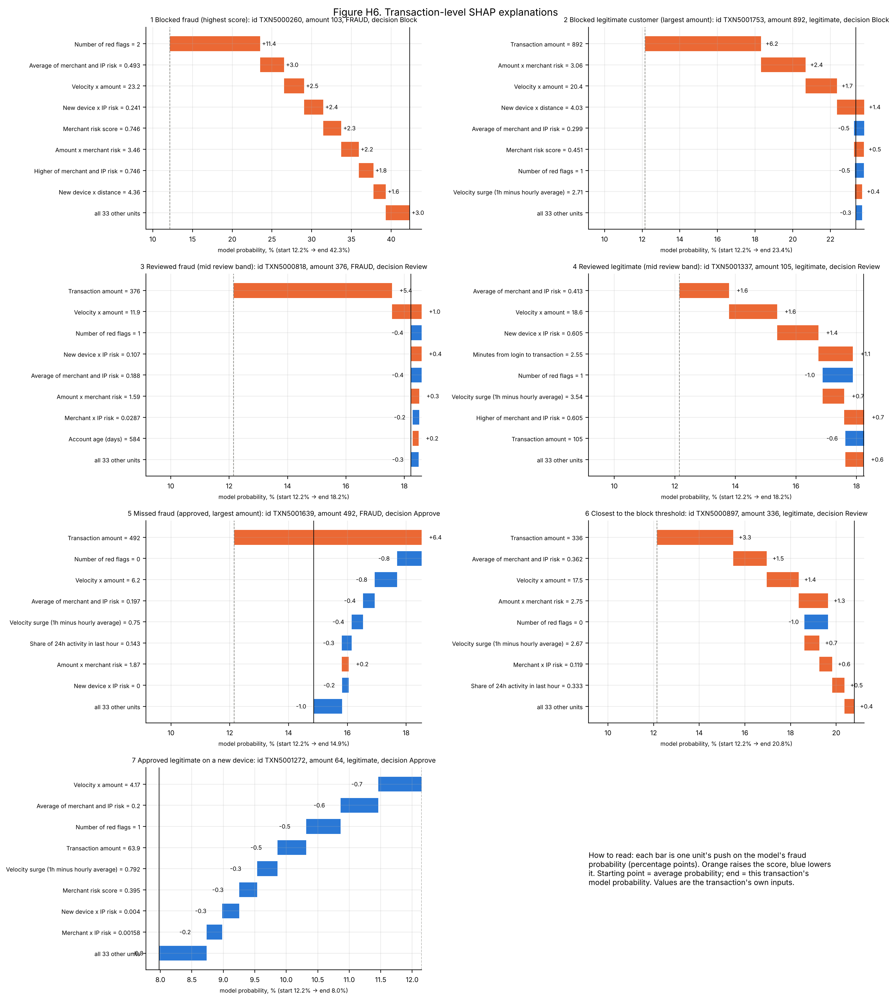

In [119]:
def waterfall(a, i, title, k=8):
    phi = SH.phi.iloc[i] * 100; vals = SH.values.iloc[i]; order = phi.abs().sort_values(ascending=False).index[:k]; rest = phi.drop(order).sum()
    labels, deltas = [], []
    for u in order:
        v = vals[u]; txt = f"{fx.LABELS.get(u, u)} = {v}" if isinstance(v, str) else (f"{fx.LABELS.get(u, u)} missing" if pd.isna(v) else f"{fx.LABELS.get(u, u)} = {v:,.3g}")
        labels.append(txt); deltas.append(phi[u])
    labels.append(f"all {len(phi) - k} other units"); deltas.append(rest); start = SH.base * 100; cum = start; ys = np.arange(len(deltas))[::-1]
    for y_, d_ in zip(ys, deltas): a.barh(y_, d_, left=cum, color=ORANGE if d_ > 0 else BLUE, height=.7); a.text(cum + d_ + (.25 if d_ > 0 else -.25), y_, f"{d_:+.1f}", va="center", ha="left" if d_ > 0 else "right", fontsize=7); cum += d_
    a.axvline(start, color=GREY, ls="--", lw=.8); a.axvline(cum, color=INK, lw=.8); a.set_yticks(ys); a.set_yticklabels(labels, fontsize=7); a.set_title(title, fontsize=8)
    lo, hi = a.get_xlim(); a.set_xlim(min(lo, start - 3), hi); a.set_xlabel(f"model probability, % (start {start:.1f}% -> end {cum:.1f}%)", fontsize=7)
fig, ax = plt.subplots(4, 2, figsize=(15, 17)); ax = ax.ravel()
for a, (name, i) in zip(ax, cases.items()): waterfall(a, i, f"{name}: id {idh.iloc[i]}, amount {amt_h[i]:,.0f}, {'FRAUD' if yv[i] else 'legitimate'}, decision {ACT[act[i]]}")
ax[7].axis("off"); ax[7].text(0, .5, "How to read: each bar is one unit's push on the model's fraud\nprobability (percentage points). Orange raises the score, blue lowers\nit. Starting point = average probability; end = this transaction's\nmodel probability. Values are the transaction's own inputs.", fontsize=9, va="center")
fig.suptitle("Figure H6. Transaction-level SHAP explanations", fontsize=12); plt.tight_layout(); plt.savefig(FIG / "H06_transaction_explanations.png", dpi=120, bbox_inches="tight"); plt.show()

### H6. How stable are the explanations?
The whole pipeline (feature engineering, encoding, forest) is refitted on 30 bootstrap resamples of the development rows with the same settings, and the **same 2,400 transactions** are re-explained each time. If an explanation is a property of the data, it should survive; if it is a property of one particular fit, it will wobble. Global rankings, then each transaction's top reasons.

In [120]:
import time; t0 = time.time()
BOOT_PHI, BOOT_P = fx.bootstrap_explanations(clone(pipe_h), Xh, yh, Xh, B=30, seed=SEED_H); print(f"30 bootstrap refits done in {time.time() - t0:.0f}s; array {BOOT_PHI.shape} (refits x transactions x units)")
imp_b = np.abs(BOOT_PHI).mean(1) * 100                                               # (B, units)
rank_b = pd.DataFrame(imp_b, columns=U_).rank(axis=1, ascending=False)
STAB = pd.DataFrame({"importance_pts": IMP_U, "boot_mean": pd.Series(imp_b.mean(0), index=U_), "boot_p05": pd.Series(np.percentile(imp_b, 5, axis=0), index=U_), "boot_p95": pd.Series(np.percentile(imp_b, 95, axis=0), index=U_),
                     "mean_rank": rank_b.mean(), "rank_sd": rank_b.std(), "in_top5_share": (rank_b <= 5).mean(), "in_top10_share": (rank_b <= 10).mean()}).sort_values("importance_pts", ascending=False)
display(STAB.head(15).round(3))
pair_rho = [spearmanr(imp_b[a], imp_b[b])[0] for a in range(30) for b in range(a + 1, 30)]; print(f"Unit-level ranking agreement between two refits: mean Spearman {np.mean(pair_rho):.2f} (range {np.min(pair_rho):.2f} to {np.max(pair_rho):.2f})")
fam_b = np.stack([to_family(pd.DataFrame(BOOT_PHI[b], columns=U_)).abs().mean().values for b in range(30)]) * 100; fam_rank = pd.DataFrame(fam_b, columns=list(fx.FAMILIES)).rank(axis=1, ascending=False)
src_b = np.stack([(np.abs(BOOT_PHI[b]) @ S_MAT).mean(0) for b in range(30)]) * 100
FAMSTAB = pd.DataFrame({"importance_pts": IMP_F, "boot_p05": pd.Series(np.percentile(fam_b, 5, axis=0), index=list(fx.FAMILIES)), "boot_p95": pd.Series(np.percentile(fam_b, 95, axis=0), index=list(fx.FAMILIES)), "mean_rank": fam_rank.mean(), "rank_sd": fam_rank.std()}).sort_values("importance_pts", ascending=False); display(FAMSTAB.round(3))
fam_pair = [spearmanr(fam_b[a], fam_b[b])[0] for a in range(30) for b in range(a + 1, 30)]; src_pair = [spearmanr(src_b[a], src_b[b])[0] for a in range(30) for b in range(a + 1, 30)]
print(f"Ranking agreement between two refits: families {np.mean(fam_pair):.2f}, source fields {np.mean(src_pair):.2f}, units {np.mean(pair_rho):.2f}")
print(f"Spread of the model's probability for the same transaction across refits: median SD {np.median(BOOT_P.std(0)) * 100:.2f} pts (average probability {BOOT_P.mean() * 100:.1f}%)")

30 bootstrap refits done in 35s; array (30, 2400, 41) (refits x transactions x units)


,importance_pts,boot_mean,boot_p05,boot_p95,mean_rank,rank_sd,in_top5_share,in_top10_share
n_red_flags,1.633,1.388,0.596,2.215,1.933,1.311,0.967,1.000
risk_mean,0.910,0.697,0.318,1.579,5.333,2.952,0.567,0.900
velocity_x_logamt,0.901,0.891,0.281,1.789,4.433,3.636,0.700,0.933
transaction_amount,0.735,0.728,0.281,1.368,5.433,3.702,0.600,0.933
newdev_x_iprisk,0.472,0.464,0.178,0.761,7.600,3.793,0.333,0.833
logamt_x_merchrisk,0.457,0.485,0.120,0.977,8.267,4.920,0.300,0.767
merchant_risk_score,0.434,0.473,0.131,0.995,8.833,5.173,0.400,0.600
velocity_surge,0.394,0.318,0.096,0.614,11.100,5.054,0.067,0.500
risk_product,0.357,0.448,0.162,0.822,8.233,4.014,0.333,0.700
newdev_x_logdist,0.337,0.516,0.132,0.957,8.600,6.038,0.400,0.700


Unit-level ranking agreement between two refits: mean Spearman 0.76 (range 0.55 to 0.92)


,importance_pts,boot_p05,boot_p95,mean_rank,rank_sd
Merchant and IP risk scores,2.335,1.482,3.332,1.433,0.774
Chargeback history and red flags,1.701,0.716,2.242,2.433,0.971
Transaction velocity,1.442,0.518,2.229,2.933,1.337
Amount,0.735,0.281,1.368,4.600,1.380
Device and authentication,0.453,0.350,1.183,4.533,1.306
Account and customer profile,0.255,0.237,1.251,5.600,1.248
Merchant and channel context,0.111,0.056,0.352,7.933,1.048
Location,0.087,0.056,0.265,8.267,0.944
Time of day,0.059,0.081,0.409,7.267,1.081


Ranking agreement between two refits: families 0.81, source fields 0.85, units 0.76
Spread of the model's probability for the same transaction across refits: median SD 1.90 pts (average probability 12.1%)


In [121]:
ref_phi = SH.phi.values; top1_ref = ref_phi.argmax(1); top1_agree = np.mean([BOOT_PHI[b].argmax(1) == top1_ref for b in range(30)], axis=0)
def top3(m): return np.argsort(-m, axis=1)[:, :3]
t3_ref = top3(ref_phi); jac = np.mean([[len(set(t3_ref[i]) & set(top3(BOOT_PHI[b])[i])) / len(set(t3_ref[i]) | set(top3(BOOT_PHI[b])[i])) for i in range(NH)] for b in range(30)], axis=0)
hi_risk = act >= 1; TX = pd.DataFrame({"decision": [ACT[a] for a in act], "top_reason_agreement": top1_agree, "top3_jaccard": jac, "p_model": pfin, "sd_p_boot_pts": BOOT_P.std(0) * 100})
g = TX[hi_risk]; print(f"Review/Block transactions: {hi_risk.sum()}. Share of refits that give the SAME top risk-raising reason: median {g.top_reason_agreement.median():.2f}; transactions where it is below 50%: {(g.top_reason_agreement < .5).mean():.1%}")
print(f"Overlap of the top-3 reasons (Jaccard): median {g.top3_jaccard.median():.2f}; below 0.5 for {(g.top3_jaccard < .5).mean():.1%} of Review/Block transactions")
case_rows = []
for name, i in cases.items():
    phi_i = SH.phi.iloc[i]; top5 = phi_i.abs().sort_values(ascending=False).index[:5]
    for u in top5:
        bi = BOOT_PHI[:, i, U_.index(u)] * 100; case_rows.append(dict(case=name[:2].strip(), unit=u, shap_pts=phi_i[u] * 100, boot_median=np.median(bi), boot_p10=np.percentile(bi, 10), boot_p90=np.percentile(bi, 90), sign_agreement=float((np.sign(bi) == np.sign(phi_i[u])).mean())))
CASESTAB = pd.DataFrame(case_rows); CASESTAB["unstable"] = (CASESTAB.sign_agreement < .8) | (CASESTAB.boot_p10 * CASESTAB.boot_p90 < 0); display(CASESTAB.round(2))
print(f"{int(CASESTAB.unstable.sum())} of {len(CASESTAB)} top-5 contributions in the seven cases change sign (or straddle zero) in at least 20% of refits")

Review/Block transactions: 457. Share of refits that give the SAME top risk-raising reason: median 0.77; transactions where it is below 50%: 31.5%
Overlap of the top-3 reasons (Jaccard): median 0.58; below 0.5 for 26.9% of Review/Block transactions


,case,unit,shap_pts,boot_median,boot_p10,boot_p90,sign_agreement,unstable
0,1,n_red_flags,11.36,8.82,4.60,15.07,1.00,False
1,1,risk_mean,3.01,1.84,1.20,4.07,1.00,False
2,1,velocity_x_logamt,2.53,2.17,0.78,4.18,1.00,False
3,1,newdev_x_iprisk,2.42,1.67,0.82,3.29,1.00,False
4,1,merchant_risk_score,2.27,1.94,0.69,4.63,1.00,False
5,2,transaction_amount,6.16,5.53,2.46,9.82,1.00,False
6,2,logamt_x_merchrisk,2.37,2.04,0.55,4.67,1.00,False
7,2,velocity_x_logamt,1.67,1.04,0.44,3.24,0.97,False
8,2,newdev_x_logdist,1.45,1.97,0.52,5.08,1.00,False
9,2,risk_mean,-0.53,-0.34,-0.81,-0.08,0.97,False


4 of 35 top-5 contributions in the seven cases change sign (or straddle zero) in at least 20% of refits


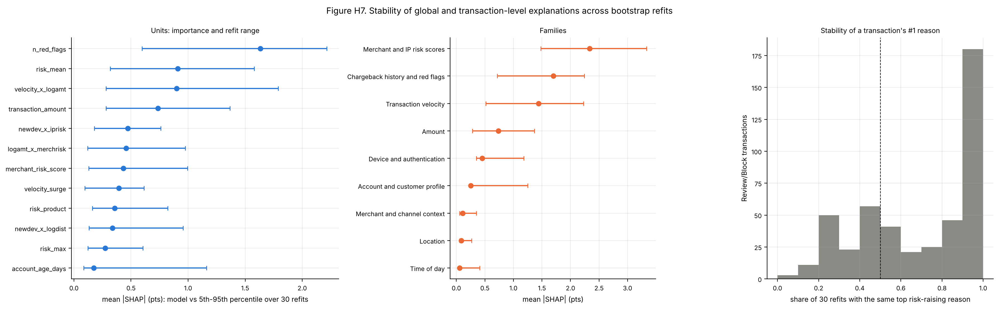

In [122]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.6), gridspec_kw=dict(width_ratios=[1.3, 1, 1.1]))
d = STAB.head(12)[::-1]; yy = np.arange(len(d)); ax[0].errorbar(d.importance_pts, yy, xerr=[(d.importance_pts - d.boot_p05).clip(lower=0), (d.boot_p95 - d.importance_pts).clip(lower=0)], fmt="o", color=BLUE, capsize=3); ax[0].set_yticks(yy); ax[0].set_yticklabels(d.index, fontsize=8); ax[0].set_xlabel("mean |SHAP| (pts): model vs 5th-95th percentile over 30 refits"); ax[0].set_title("Units: importance and refit range", fontsize=9)
d = FAMSTAB[::-1]; yy = np.arange(len(d)); ax[1].errorbar(d.importance_pts, yy, xerr=[(d.importance_pts - d.boot_p05).clip(lower=0), (d.boot_p95 - d.importance_pts).clip(lower=0)], fmt="o", color=ORANGE, capsize=3); ax[1].set_yticks(yy); ax[1].set_yticklabels(d.index, fontsize=8); ax[1].set_title("Families", fontsize=9); ax[1].set_xlabel("mean |SHAP| (pts)")
ax[2].hist(g.top_reason_agreement, bins=np.linspace(0, 1, 11), color=GREY); ax[2].axvline(.5, color=INK, ls="--", lw=.8); ax[2].set_xlabel("share of 30 refits with the same top risk-raising reason"); ax[2].set_ylabel("Review/Block transactions"); ax[2].set_title("Stability of a transaction's #1 reason", fontsize=9)
fig.suptitle("Figure H7. Stability of global and transaction-level explanations across bootstrap refits", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "H07_stability.png", dpi=130, bbox_inches="tight"); plt.show()

### H7. Counterintuitive or unreliable explanations: an audit against pre-set expectations
Expected directions were fixed in advance from Part B (category and nonlinear analysis), Part D (Logistic Regression odds ratios) and fraud-domain reasoning; "0" means Part B found no evidence of any effect. For each unit: the observed direction (Spearman correlation between the feature's value and its SHAP value; for categories, between each category's observed fraud rate and its mean SHAP), the importance, a **null yardstick** (the 95th percentile of the unit's importance when the forest is refitted on label-shuffled data, 20 times), and the refit stability from H6.

In [123]:
EXPECT = {"new_device": (+1, "Part D top-2 field; B: red flag"), "billing_address_mismatch": (+1, "red flag (n_red_flags)"), "prior_chargebacks": (+1, "red flag; LR odds ratio > 1"), "failed_logins_24h": (+1, "red flag"),
          "merchant_risk_score": (+1, "B: odds ratio 1.31 per SD"), "ip_risk_score": (+1, "B: odds ratio 1.19 per SD"), "transactions_last_1h": (+1, "B: odds ratio 1.33 per SD"), "transactions_last_24h": (+1, "velocity"),
          "distance_from_usual_location_km": (+1, "domain"), "transaction_amount": ("tail", "B: flat to ~180, rising above ~260"), "account_age_days": (-1, "domain: newer accounts riskier"), "device_age_days": (-1, "domain"),
          "email_age_days": (-1, "domain"), "login_to_transaction_minutes": (-1, "domain: very quick logins riskier (not tested in B)"), "n_red_flags": (+1, "count of red flags"), "risk_mean": (+1, "built from risk scores"),
          "risk_max": (+1, "built from risk scores"), "risk_product": (+1, "built from risk scores"), "high_risk_both": (+1, "built from risk scores"), "velocity_ratio_1h_24h": (+1, "velocity"), "velocity_surge": (+1, "velocity"),
          "log_tx_24h": (+1, "velocity"), "velocity_x_logamt": (+1, "velocity x amount"), "logamt_x_merchrisk": (+1, "amount x risk"), "newdev_x_iprisk": (+1, "new device x risk"), "newdev_x_logdist": (+1, "new device x distance"),
          "billmis_x_newdev": (+1, "red flags"), "authmiss_x_digital": (+1, "B: missing authentication"),
          "hour": (0, "B: time is flat"), "day_of_week": (0, "B: time is flat"), "is_night": (0, "B: no night effect"), "is_business_hours": (0, "B: time is flat"), "hour_sin": (0, "B: time is flat"), "hour_cos": (0, "B: time is flat"),
          "device_type": (0, "B: p = 0.96"), "country": (0, "B: p = 0.62"), "card_presence": (0, "B: p = 0.11"), "channel": ("cat", "B: E-commerce 14.3% vs POS 9.5%"), "merchant_category": ("cat", "B: Jewelry/Fashion/Gaming high; Digital/Fuel low"),
          "authentication_level": ("cat", "B: Missing 21% vs 11%"), "customer_tier": ("cat", "B: Basic 14.5% vs ~11%")}
assert set(EXPECT) == set(U_), set(U_) ^ set(EXPECT)
rng_n = np.random.default_rng(SEED_H); Zv = SH.Z.values; rf_params = pipe_h["model"].get_params(); null_imp = []
for k in range(20):
    rf_n = clone(pipe_h["model"]).set_params(random_state=SEED_H + k).fit(Zv, rng_n.permutation(yv)); sv = fx.shap.TreeExplainer(rf_n).shap_values(Zv, check_additivity=False)[:, :, 1]; null_imp.append(np.abs(sv @ EXPL.M).mean(0) * 100)
NULL = pd.DataFrame(null_imp, columns=U_); null95 = NULL.quantile(.95)
rows = []
for u in U_:
    exp, why = EXPECT[u]; v = SH.values[u]
    if exp == "cat" or exp == 0 and isinstance(v.iloc[0], str):
        cat = pd.DataFrame({"c": v.astype(str).values, "y": yv, "phi": SH.phi[u].values}).groupby("c").agg(n=("y", "size"), rate=("y", "mean"), phi=("phi", "mean")); cat = cat[cat.n >= 50]
        obs = spearmanr(cat.rate, cat.phi)[0] if len(cat) > 3 else np.nan; kind = "category rate vs SHAP"
    else:
        x = pd.to_numeric(v, errors="coerce")
        if exp == "tail": hi = x >= x.quantile(.95); obs = float(SH.phi[u][hi].mean() - SH.phi[u][~hi].mean()) * 100; kind = "tail minus rest (pts)"
        else: obs = spearmanr(x, SH.phi[u], nan_policy="omit")[0]; kind = "Spearman(value, SHAP)"
    rows.append(dict(unit=u, family=fx.FAMILY_OF[u], expected=exp, basis=why, observed_kind=kind, observed=obs, importance_pts=IMP_U[u], null95_pts=null95[u], above_noise=bool(IMP_U[u] > null95[u]), top10_share=STAB.in_top10_share[u], rank_sd=STAB.rank_sd[u]))
AUD = pd.DataFrame(rows).set_index("unit").sort_values("importance_pts", ascending=False)
def verdict(r):
    f = []
    if r.expected in (1, -1) and not pd.isna(r.observed) and np.sign(r.observed) != r.expected and abs(r.observed) > .1: f.append("direction contradicts expectation")
    if r.expected == "tail" and r.observed <= 0: f.append("no tail effect")
    if r.expected == 0 and r.above_noise: f.append("importance above noise although none expected")
    if r.above_noise and r.top10_share < .7 and r.importance_pts > .1: f.append("ranking unstable across refits")
    if not r.above_noise and r.importance_pts > .1: f.append("importance within noise")
    return "; ".join(f)
AUD["flag"] = AUD.apply(verdict, axis=1); display(AUD[["family", "expected", "observed_kind", "observed", "importance_pts", "null95_pts", "above_noise", "top10_share", "flag"]].round(3))
print(f"{int(AUD.above_noise.sum())} of {len(AUD)} units are above the label-shuffle noise level; flagged units: {int((AUD.flag != '').sum())}")

,family,expected,observed_kind,observed,importance_pts,null95_pts,above_noise,top10_share,flag
unit,,,,,,,,,
n_red_flags,Chargeback history and red flags,1,"Spearman(value, SHAP)",0.771,1.633,0.067,True,1.000,
risk_mean,Merchant and IP risk scores,1,"Spearman(value, SHAP)",0.768,0.910,0.320,True,0.900,
velocity_x_logamt,Transaction velocity,1,"Spearman(value, SHAP)",0.849,0.901,0.414,True,0.933,
transaction_amount,Amount,tail,tail minus rest (pts),5.757,0.735,0.410,True,0.933,
newdev_x_iprisk,Merchant and IP risk scores,1,"Spearman(value, SHAP)",0.575,0.472,0.159,True,0.833,
logamt_x_merchrisk,Merchant and IP risk scores,1,"Spearman(value, SHAP)",0.857,0.457,0.324,True,0.767,
merchant_risk_score,Merchant and IP risk scores,1,"Spearman(value, SHAP)",0.690,0.434,0.378,True,0.600,ranking unstable across refits
velocity_surge,Transaction velocity,1,"Spearman(value, SHAP)",0.903,0.394,0.299,True,0.500,ranking unstable across refits
risk_product,Merchant and IP risk scores,1,"Spearman(value, SHAP)",0.802,0.357,0.462,False,0.700,importance within noise


14 of 41 units are above the label-shuffle noise level; flagged units: 10


Categories whose observed fraud rate (vs the 12.1% average, in points) and mean SHAP point in opposite directions (rate gap > 2 pts, n >= 100):


,c,field,n,observed_rate,mean_shap_pts,rate_vs_avg,conflict
4,Gaming,merchant_category,189,0.159,-0.033,3.748,True
6,USA,country,149,0.094,0.057,-2.729,True


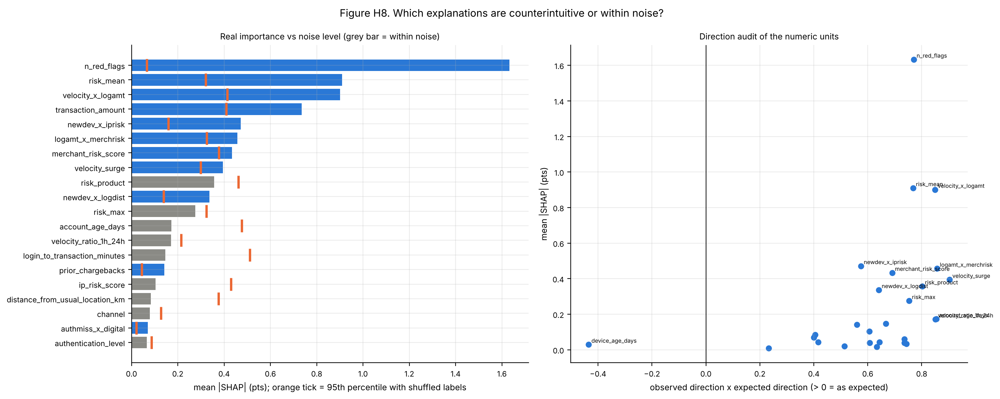

In [124]:
cat_detail = []
for u in ["merchant_category", "country", "channel", "customer_tier", "authentication_level"]:
    c = pd.DataFrame({"c": SH.values[u].astype(str).values, "y": yv, "phi": SH.phi[u].values * 100}).groupby("c").agg(n=("y", "size"), observed_rate=("y", "mean"), mean_shap_pts=("phi", "mean")); c.insert(0, "field", u); cat_detail.append(c.reset_index())
CAT = pd.concat(cat_detail); CAT["rate_vs_avg"] = (CAT.observed_rate - yv.mean()) * 100; CAT["conflict"] = (np.sign(CAT.rate_vs_avg) != np.sign(CAT.mean_shap_pts)) & (CAT.rate_vs_avg.abs() > 2) & (CAT.mean_shap_pts.abs() > .02) & (CAT.n >= 100)
print("Categories whose observed fraud rate (vs the 12.1% average, in points) and mean SHAP point in opposite directions (rate gap > 2 pts, n >= 100):"); display(CAT[CAT.conflict].round(3))
fig, ax = plt.subplots(1, 2, figsize=(15, 6)); d = AUD.head(20)[::-1]; yy = np.arange(len(d)); ax[0].barh(yy, d.importance_pts, color=[BLUE if a else GREY for a in d.above_noise]); ax[0].plot(d.null95_pts, yy, "|", color=ORANGE, ms=14, mew=2.5)
ax[0].set_yticks(yy); ax[0].set_yticklabels(d.index, fontsize=8); ax[0].set_xlabel("mean |SHAP| (pts); orange tick = 95th percentile with shuffled labels"); ax[0].set_title("Real importance vs noise level (grey bar = within noise)", fontsize=9)
nn = AUD[AUD.expected.isin([1, -1])].dropna(subset=["observed"]); ax[1].scatter(nn.expected * nn.observed, nn.importance_pts, color=BLUE, s=30); [ax[1].annotate(u, (r.expected * r.observed, r.importance_pts), fontsize=6, xytext=(3, 2), textcoords="offset points") for u, r in nn.iterrows() if r.importance_pts > .15 or r.expected * r.observed < 0]
ax[1].axvline(0, color=INK, lw=.8); ax[1].set_xlabel("observed direction x expected direction (> 0 = as expected)"); ax[1].set_ylabel("mean |SHAP| (pts)"); ax[1].set_title("Direction audit of the numeric units", fontsize=9)
fig.suptitle("Figure H8. Which explanations are counterintuitive or within noise?", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "H08_explanation_audit.png", dpi=130, bbox_inches="tight"); plt.show()

In [125]:
# Credit splitting demo: remove the raw merchant-risk columns and refit. Predictions barely change; the credit moves to the derived copies of the same information.
drop = [c for c in EXPL.enc_names if c in ("merchant_risk_score", "missingindicator_merchant_risk_score")]; keep = [i for i, c in enumerate(EXPL.enc_names) if c not in drop]
rf0 = clone(pipe_h["model"]); rf1 = clone(pipe_h["model"]); cv_ = StratifiedKFold(5, shuffle=True, random_state=SEED_H); pr = {}
for nm, Zm, rf_ in [("with merchant_risk_score", Zv, rf0), ("without merchant_risk_score", Zv[:, keep], rf1)]:
    oof_ = np.zeros(NH)
    for tr, te in cv_.split(Zm, yv): oof_[te] = clone(rf_).fit(Zm[tr], yv[tr]).predict_proba(Zm[te])[:, 1]
    pr[nm] = average_precision_score(yv, oof_)
rf1.fit(Zv[:, keep], yv); sv1 = fx.shap.TreeExplainer(rf1).shap_values(Zv[:, keep], check_additivity=False)[:, :, 1]; M1 = EXPL.M[keep]; phi1 = pd.DataFrame(sv1 @ M1, columns=U_)
CS = pd.DataFrame({"with": SH.phi.abs().mean() * 100, "without": phi1.abs().mean() * 100}).loc[["merchant_risk_score", "risk_mean", "risk_max", "risk_product", "logamt_x_merchrisk"]]; CS["change"] = CS["without"] - CS["with"]; display(CS.round(3))
fam_with, fam_without = IMP_F["Merchant and IP risk scores"], (to_family(phi1).abs().mean() * 100)["Merchant and IP risk scores"]
print(f"Whole 'Merchant and IP risk scores' family: {fam_with:.2f} pts with the raw column, {fam_without:.2f} pts without it. Cross-validated PR-AUC: {pr['with merchant_risk_score']:.3f} with, {pr['without merchant_risk_score']:.3f} without.")
print("==> Unit-level credit depends on which copies of the information the model is given; the family total is far steadier. Single-feature SHAP values are not 'the effect of' that feature.")

,with,without,change
merchant_risk_score,0.434,0.000,-0.434
risk_mean,0.910,0.964,0.053
risk_max,0.275,0.340,0.065
risk_product,0.357,0.441,0.083
logamt_x_merchrisk,0.457,0.512,0.055


Whole 'Merchant and IP risk scores' family: 2.34 pts with the raw column, 2.30 pts without it. Cross-validated PR-AUC: 0.229 with, 0.231 without.
==> Unit-level credit depends on which copies of the information the model is given; the family total is far steadier. Single-feature SHAP values are not 'the effect of' that feature.


### H8. Prediction is not causation
Everything above is a statement about how the **model** turns inputs into a score. It is not a statement about what **causes** fraud. Reasons:
* **Association, not intervention.** The model learned that transactions with some pattern tend to be fraud in this historical data. Changing a field in a what-if analysis changes the model's output; it says nothing about what would happen to real fraud if a customer's circumstances changed.
* **Confounding and proxies.** An input can matter because it stands in for something unmeasured (e.g. a risk score that was itself produced by a fraud vendor looking at similar signals) or because it is tied to other fields.
* **Attribution depends on the model.** The credit-splitting test in H7 shows the same information can be credited to different inputs depending on which copies are present. A causal effect would not behave like that.
* **Selection and feedback.** Labels come from past decisions (what was investigated, charged back and reported), so the model also learns the old process, and acting on its scores will change the data it sees.

| Statement | Allowed (predictive) | Not allowed (causal) |
|---|---|---|
| New device | "Transactions on a new device are scored higher, and among similar transactions this field still shifts the score" | "A new device causes fraud" or "forcing customers to re-use devices would cut fraud" |
| Merchant risk score | "The model relies heavily on it" | "Reducing merchant risk would reduce fraud" (it is a rating, not a lever) |
| SHAP contribution | "In this model, this input accounts for +4 pts of this transaction's score" | "This input is 4 points of the reason this customer committed fraud" |
| Missing authentication | "Records with no authentication level had a higher fraud rate (21% vs 11%) and are scored higher" | "Adding authentication would lower fraud by half" (missingness may reflect a process or channel) |
| Reason codes to customers or regulators | "Factors that most increased the model's score" | Accusations or findings of intent |

In [126]:
crude = []
for nm, mask in [("new_device = 1", Xh.new_device == 1), ("authentication Missing", Xh.authentication_level.isna() | (Xh.authentication_level == "Missing")), ("billing_address_mismatch = 1", Xh.billing_address_mismatch == 1), ("prior_chargebacks >= 1", Xh.prior_chargebacks >= 1)]:
    r1, r0 = yv[mask.values].mean(), yv[~mask.values].mean(); crude.append(dict(group=nm, n=int(mask.sum()), fraud_rate=r1, fraud_rate_otherwise=r0, crude_risk_ratio=r1 / r0))
CR = pd.DataFrame(crude).set_index("group"); orr = pd.read_csv(OUT / "D_lr_baseline_odds_ratios.csv", index_col=0)
CR["LR_adjusted_odds_ratio"] = [orr.odds_ratio.get("new_device", np.nan), orr.odds_ratio.get("authentication_level_Missing", np.nan), orr.odds_ratio.get("billing_address_mismatch", np.nan), orr.odds_ratio.get("prior_chargebacks", np.nan)]
CR["LR_or_ci"] = [f"[{orr.or_ci_low.get(k, np.nan):.2f}, {orr.or_ci_high.get(k, np.nan):.2f}]" for k in ["new_device", "authentication_level_Missing", "billing_address_mismatch", "prior_chargebacks"]]; display(CR.round(3))
Xw = Xh.copy(); Xw["new_device"] = 0; flag = (Xh.new_device == 1).values; d_nd = pipe_h.predict_proba(Xw)[flag, 1] - pipe_h.predict_proba(Xh)[flag, 1]
Xw2 = Xh.copy(); Xw2["merchant_risk_score"] = Xh.merchant_risk_score.median(); hi_m = (Xh.merchant_risk_score >= Xh.merchant_risk_score.quantile(.75)).values; d_mr = pipe_h.predict_proba(Xw2)[hi_m, 1] - pipe_h.predict_proba(Xh)[hi_m, 1]
print(f"WHAT-IF (a model computation, not a causal effect): setting new_device to 0 for the {flag.sum()} new-device transactions changes the model's average probability by {d_nd.mean() * 100:+.1f} pts; setting merchant_risk_score to its median for the top-quartile transactions changes it by {d_mr.mean() * 100:+.1f} pts.")
print("These are exactly the numbers a naive reader would call 'the effect'. They describe the fitted function only: the data contain no experiment, so no intervention effect can be identified from them.")

,n,fraud_rate,fraud_rate_otherwise,crude_risk_ratio,LR_adjusted_odds_ratio,LR_or_ci
group,,,,,,
new_device = 1,396,0.197,0.106,1.853,1.348,"[1.22, 1.54]"
authentication Missing,229,0.210,0.112,1.873,1.651,"[1.31, 2.08]"
billing_address_mismatch = 1,231,0.177,0.115,1.540,1.170,"[1.06, 1.32]"
prior_chargebacks >= 1,284,0.201,0.111,1.815,1.280,"[1.13, 1.45]"


WHAT-IF (a model computation, not a causal effect): setting new_device to 0 for the 396 new-device transactions changes the model's average probability by -6.2 pts; setting merchant_risk_score to its median for the top-quartile transactions changes it by -4.5 pts.
These are exactly the numbers a naive reader would call 'the effect'. They describe the fitted function only: the data contain no experiment, so no intervention effect can be identified from them.


### H9. Reason-code export for every Review and Block decision
The decision engine needs an explanation for every high-risk transaction. For each development transaction that the explained model's Platt-calibrated score (in-sample) sends to Review or Block, the file lists the calibrated probability (model and out-of-fold), the action, the top three risk-raising and risk-lowering reasons in plain English with their size in percentage points, the leading business family, and how stable the #1 reason is across the 30 refits (reasons with less than 50% agreement are marked `fragile` and should be shown to analysts with a caution).

In [127]:
fam_phi = to_family(SH.phi); rc = []
for i in np.where(act >= 1)[0]:
    up, dn = fx.reason_text(SH.phi.iloc[i], SH.values.iloc[i], k=3)
    rc.append(dict(transaction_id=idh.iloc[i], decision=ACT[act[i]], amount=round(amt_h[i], 2), calibrated_probability_model=round(float(pfin[i]), 4), calibrated_probability_oof=round(poof_o[i], 4),
                   top_family=fam_phi.iloc[i].idxmax(), reasons_raising_score=up, reasons_lowering_score=dn, top_reason_agreement_across_refits=round(float(top1_agree[i]), 2), explanation_status="fragile" if top1_agree[i] < .5 else "stable", actual_fraud=int(yv[i])))
RC = pd.DataFrame(rc); RC.to_csv(OUT / "H_reason_codes_review_block.csv", index=False)
print(f"{len(RC)} Review/Block transactions exported; explanation status: {RC.explanation_status.value_counts().to_dict()}"); display(RC.head(5).T)

457 Review/Block transactions exported; explanation status: {'stable': 313, 'fragile': 144}


,0,1,2,3,4
transaction_id,TXN5000001,TXN5000004,TXN5000005,TXN5000015,TXN5000018
decision,Block,Review,Review,Block,Block
amount,35.01,77.02,187.65,90.32,153.88
calibrated_probability_model,0.2241,0.1818,0.1608,0.2659,0.309
calibrated_probability_oof,0.1887,0.1489,0.1602,0.2604,0.3306
top_family,Merchant and IP risk scores,Merchant and IP risk scores,Merchant and IP risk scores,Chargeback history and red flags,Chargeback history and red flags
reasons_raising_score,Velocity x amount = 21.5 (+2.7 pts); Merchant risk score = 0.62 (+2.3 pts); Average of merchant and IP risk = 0.36 (+2.0 pts),Average of merchant and IP risk = 0.49 (+2.7 pts); Merchant x IP risk = 0.23 (+2.1 pts); Velocity x amount = 17.43 (+1.6 pts),Amount x merchant risk = 3.08 (+2.5 pts); Average of merchant and IP risk = 0.46 (+2.1 pts); Merchant risk score = 0.59 (+1.2 pts),Number of red flags = 2 (+9.4 pts); Average of merchant and IP risk = 0.48 (+2.6 pts); Merchant x IP risk = 0.21 (+1.4 pts),Number of red flags = 2 (+12.1 pts); New device x IP risk = 0.26 (+3.5 pts); New device x distance = 4.17 (+2.1 pts)
reasons_lowering_score,Transaction amount = 35.01 (-0.4 pts); Number of red flags = 1 (-0.3 pts); Merchant x IP risk = 0.07 (-0.3 pts),Number of red flags = 0 (-1.2 pts); Transaction amount = 77.02 (-0.5 pts); Merchant risk score = 0.38 (-0.3 pts),Velocity x amount = 5.24 (-1.1 pts); Number of red flags = 0 (-1.1 pts); Velocity surge (1h minus hourly average) = 0.58 (-0.4 pts),Velocity x amount missing (-1.3 pts); New device x IP risk = 0 (-1.1 pts); Amount x merchant risk missing (-0.4 pts),Velocity x amount = 5.04 (-0.9 pts); Velocity surge (1h minus hourly average) = 0.75 (-0.5 pts); Transaction amount = 153.88 (-0.4 pts)
top_reason_agreement_across_refits,0.33,0.43,0.57,0.87,0.8
explanation_status,fragile,fragile,stable,stable,stable


### H10. Findings

**Scope.** SHAP (TreeExplainer) on the production Random Forest, development rows only (2,400), hold-out untouched. Additivity holds for every row; an interventional-SHAP variant agrees with the default (rank correlation of global importance 0.99).

**Global importance**
1. **Business families:** Merchant and IP risk scores 2.3 pts (mean |SHAP|), Chargeback history and red flags 1.7, Transaction velocity 1.4, Amount 0.7, Device and authentication 0.5; account profile, merchant/channel context, location and time of day are each at or below 0.26 pts. Time of day is the smallest family (0.06 pts), consistent with Part B's flat time pattern.
2. **Single units understate shared information.** `n_red_flags` (1.6 pts) is the top unit, but `new_device` itself is tiny (0.04 pts) because its information also sits inside `n_red_flags`, `newdev_x_iprisk`, `newdev_x_logdist` and `billmis_x_newdev`. At raw-field level (derived features split equally between their source fields) the top five are merchant risk score (1.25), transaction amount (1.03), IP risk score (0.91), transactions in the last hour (0.72) and new device (0.68).
3. **Agreement with Part D's permutation importance:** rank correlation 0.84 over 23 fields; 4 of the top 5 fields are shared (SHAP puts IP risk score where permutation puts authentication level). Partial dependence agrees with SHAP on direction in 13 of 14 fields and on size ordering (rank correlation 0.93). Three independent views therefore tell the same story: merchant/IP risk, new-device-type red flags, velocity and amount drive the score.

**Dependence and interaction**
4. The model's response is **step-shaped**, as expected from shallow trees: a jump of about +10 pts when two or more red flags are present (one flag is about the same as none), a jump near an average merchant/IP risk of 0.30 and near velocity x amount of 10, and a sharp rise in the transaction amount between roughly 250 and 500 followed by a plateau of about +6 to +8 pts. Part B's amount finding (flat to about 180, rising above about 260) is reproduced.
5. **Interactions are modest and mostly a redundancy artefact.** Single-input effects carry 64.6% of total SHAP magnitude and pairs 35.4%. The strongest pair, `n_red_flags` x `newdev_x_iprisk` (0.33 pts, about four times the next), combines two inputs that both contain `new_device`; excluding pairs that share a raw field the strongest is only 0.09 pts. This fits Part B's finding of no significant interactions, and I do not claim a real interaction effect.

**Transaction-level explanations (seven rule-selected cases, figure H6 and the case table):** a blocked fraud driven by two red flags (+11.4 pts) plus risk and velocity; a blocked legitimate customer driven almost entirely by a very large amount (892, +6.2 pts) and amount-linked features, i.e. the model blocks a large genuine purchase because large amounts look like fraud; a reviewed fraud and a reviewed legitimate customer that look alike (amount in the first, risk and velocity in the second), showing why review is needed; a missed fraud of 492 where the large amount (+6.4 pts) is outweighed by no red flags, low velocity and low risk, so the explanation says the transaction looked ordinary apart from its size; and a new-device legitimate transaction held at 8.0% by low risk and low velocity. Every Review or Block decision has a plain-English reason code in `H_reason_codes_review_block.csv` (457 rows).

**Unstable or counterintuitive explanations**
6. **Unit rankings are only moderately stable:** two bootstrap refits agree on the unit ranking with Spearman 0.76, source fields 0.85 and families 0.81. `n_red_flags` is top-10 in 100% of refits; most other units move by several ranks (e.g. `merchant_risk_score` top-10 in 60%, `velocity_surge` 50%).
7. **Individual reasons are fragile for a third of flagged transactions:** for 31.5% of the 457 Review/Block transactions the same top reason appears in fewer than half of the refits; the median overlap of the top-3 reasons is 0.58. The model's own probability for a transaction varies by about 1.9 pts across refits. In the seven cases 4 of 35 top contributions straddle zero, all small (below 0.6 pts in absolute size).
8. **Credit splitting:** removing the raw `merchant_risk_score` column leaves the whole risk family unchanged (2.34 to 2.30 pts) and the cross-validated PR-AUC unchanged (0.229 vs 0.231), while the credit moves to its derived copies. A unit's SHAP value is therefore not "the effect of that feature". Family totals should be used for management reporting, unit values only inside a single transaction's explanation.
9. **Importance within noise:** only 14 of 41 units exceed the 95th percentile of importance under label-shuffled refits; `ip_risk_score` at unit level (0.10 pts) and `account_age_days` (0.17) are within noise even though raw-field totals look meaningful. All time-of-day units, country, device type and card presence are within noise or negligible, matching Part B.
10. **Counterintuitive category credits:** Gaming has an above-average fraud rate (15.9%) but a slightly negative mean SHAP (-0.03 pts), and USA has a below-average rate (9.4%) but a slightly positive one (+0.06 pts); both are tiny because the effect is carried by correlated risk features, and neither should be used as a reason code. `device_age_days` slopes opposite to expectation but is within noise. The very large effect of transaction amount on legitimate large purchases (case 2) is expected from the data yet commercially undesirable.

**Prediction is not causation.** Crude risk ratios (new device 1.85, missing authentication 1.87, prior chargeback 1.82) shrink to adjusted odds ratios of 1.35, 1.65 and 1.28 in the Logistic Regression, so confounding between fields is visible. A what-if computation that sets `new_device` to 0 lowers the model's average score for new-device transactions by 6.2 pts; that measures the fitted function, not what would happen to fraud if devices changed. Nothing in the data is experimental, selection by past decisions shapes the labels, and attribution changes with the feature set (item 8), so SHAP is used here only to describe and audit the model, to give analysts reasons, and to check for errors; it is not evidence about causes. Statement table in H8.

**Consequences for the decision engine:** show reason codes at family level plus the top units; mark the 31.5% fragile explanations; do not use time-of-day, country or card presence as stated reasons; treat the amount threshold effect as a business-rule candidate (large genuine purchases will be reviewed); re-run this stability analysis after every refit.

In [128]:
SH.phi.round(5).assign(transaction_id=idh.values).to_csv(OUT / "H_shap_units_dev.csv", index=False)
IMP_U.to_frame("mean_abs_shap_pts").to_csv(OUT / "H_importance_units.csv"); IMP_F.to_frame("mean_abs_shap_pts").to_csv(OUT / "H_importance_families.csv"); cmp.to_csv(OUT / "H_importance_vs_permutation.csv")
INT.to_csv(OUT / "H_interactions_pairs.csv", index=False); PDPT.to_csv(OUT / "H_shap_vs_pdp_direction.csv"); CASES.to_csv(OUT / "H_case_explanations.csv", index=False); CASESTAB.to_csv(OUT / "H_case_stability.csv", index=False)
STAB.to_csv(OUT / "H_stability_units.csv"); FAMSTAB.to_csv(OUT / "H_stability_families.csv"); AUD.to_csv(OUT / "H_expectation_audit.csv"); CAT.to_csv(OUT / "H_category_shap_vs_rate.csv", index=False); CR.to_csv(OUT / "H_association_vs_adjusted.csv"); CS.to_csv(OUT / "H_credit_splitting_demo.csv")
print("Part H tables saved; figures:", sorted(p.name for p in FIG.glob("H*.png")), "| hold-out rows read: none")

Part H tables saved; figures: ['H01_global_importance.png', 'H02_beeswarm.png', 'H03_interactions.png', 'H04_dependence.png', 'H05_partial_dependence.png', 'H06_transaction_explanations.png', 'H07_stability.png', 'H08_explanation_audit.png'] | hold-out rows read: none


---
## Part I. Fraud Operations Simulation

**Goal:** turn the calibrated fraud probability into three operational decisions, set the thresholds from the business cost framework, and estimate what the decision engine would do in a month of traffic: how many transactions fall into each decision, how much fraud is stopped, how many genuine customers are inconvenienced, how large the review team must be, and what it is worth in money. The proposed policy is compared with simpler policies.

| Task I requirement | Section |
|---|---|
| Three decisions: Approve, Manual Review, Block | I1 |
| Thresholds from the selected cost framework | I2, I5 |
| Volumes, fraud capture, false-positive burden, review workload, financial impact | I3, I4, I6 |
| Compare with at least one simpler policy | I2 to I4 (six comparison policies), I7, I8 |

**Design (fixed before looking at results)**
1. **Honest scoring.** Every decision uses an out-of-fold probability (Part D predictions, Platt-calibrated by cross-fitting as in Part F): the transaction was never seen by the model or the calibrator that scores it. Thresholds searched by cost are chosen on training folds and applied to unseen folds. The hold-out set is not used; it stays reserved for the final check.
2. **Cost framework:** the Part E base scenario S1 (loss = full amount plus 15 chargeback fee; blocked customer costs 5% of the amount plus 20 friction; a review costs 6 and catches 85% of frauds; wrongly declined review 3%; review delay 1.5), with the operating limits of at most 10% of transactions reviewed and at most 10% blocked. Scenarios S1 to S7 are re-run in I7.
3. **Scale:** a hypothetical 100,000 transactions per month, drawn with the same mix as the development data (so 12.1% fraud, far higher than a real card portfolio; Part J discusses what changes at lower prevalence). Staffing: 8 minutes per review at 45 per hour (= the 6.0 review cost), 6.5 productive hours per day, 22 working days.
4. **Simpler comparison policies**, defined before scoring: approve everything; the default 0.50 cut-off; a legacy-style business rule (block at 2 or more red flags, review amounts of 300 or more, no model); a model with a single block threshold and no review; a model that only sends the top scores to review; and the Part E fixed two-threshold policy. The **proposed policy** is the amount-aware expected-cost rule of Part F, which was cheaper than searched thresholds in every scenario, and it is judged here against all six.
5. **Capture** counts a fraud as stopped if it is blocked, or if it is reviewed and the analyst detects it (85%). Reviewed frauds that the analyst misses are counted as leaking.

### I1. Setup, assumptions and the three decisions

In [129]:
import joblib, json
import fraud_costs as fc_i, fraud_calibration as fcal_i, fraud_ops as fo, fraud_models as fm_i
SEED_I = 42
Xi, yi, idi = fm_i.load_dev(); YI = yi.to_numpy(); NI = len(YI)
oofI = pd.read_csv(OUT / "D_oof_predictions.csv"); assert (oofI.transaction_id.values == idi.values).all()
SI = [oofI.p_RF_r0.to_numpy(), oofI.p_RF_r1.to_numpy()]                       # two prediction repeats of the Random Forest (Part D, out-of-fold)
CFI = fcal_i.crossfit(SI, YI, "platt", seed=SEED_I)                           # 20 cross-fitted calibrated probability vectors (2 repeats x 10 calibration splits)
P2 = [CFI[0], CFI[10]]                                                        # one per prediction repeat, used by the threshold searches
meta_i = pd.DataFrame({ID: idi.values}).merge(df, on=ID, how="left"); AMT = meta_i.transaction_amount.fillna(meta_i.transaction_amount.median()).to_numpy()
pipe_i = joblib.load(OUT / "models" / "D_RF.joblib"); NRF = pipe_i["features"].transform(Xi)["n_red_flags"].to_numpy()
SC = fc_i.SCENARIOS["S1_base"]; OPS = fo.OPS
ASSUME = pd.DataFrame({"assumption": ["Monthly transactions", "Working days per month", "Minutes per manual review", "Analyst cost per hour", "Productive hours per analyst-day", "Reviews one analyst handles per month",
                                      "Max share of transactions reviewed", "Max share auto-blocked", "Analyst detects a fraud in review", "Fraud rate in the development data"],
                       "value": [f"{OPS['monthly_transactions']:,}", OPS["working_days"], OPS["minutes_per_review"], OPS["analyst_cost_per_hour"], OPS["productive_hours_per_day"], f"{fo.reviews_per_analyst_month():,.0f}",
                                 f"{SC.review_capacity:.0%}", f"{SC.max_block_rate:.0%}", f"{SC.review_detect:.0%}", f"{YI.mean():.1%}"]}).set_index("assumption"); display(ASSUME)
display(pd.DataFrame([SC.as_dict()]).T.rename(columns={0: "S1 base cost scenario (Part E)"}))
DEC = pd.DataFrame({"decision": ["Approve", "Manual review", "Block"], "what happens": ["Transaction goes through", "Held for an analyst, who approves or declines it (detects 85% of frauds, wrongly declines 3% of genuine ones, costs 6 plus 1.5 delay for genuine customers)", "Declined automatically; a genuine customer loses the sale (5% of the amount) and 20 friction cost"],
                    "when it is the cheapest choice": ["Low fraud probability", "Middle probabilities, where a human check costs less than either error", "High probability, where the expected fraud loss exceeds the cost of a wrong decline"]}).set_index("decision"); display(DEC)
print(f"{NI} development rows, {int(YI.sum())} frauds; scale factor to one month = {OPS['monthly_transactions'] / NI:.1f}; hold-out rows read: none")

,value
assumption,
Monthly transactions,"100,000"
Working days per month,22
Minutes per manual review,8.0
Analyst cost per hour,45.0
Productive hours per analyst-day,6.5
Reviews one analyst handles per month,"1,072"
Max share of transactions reviewed,10%
Max share auto-blocked,10%
Analyst detects a fraud in review,85%


,S1 base cost scenario (Part E)
name,S1_base
loss_share,1.0
chargeback_fee,15.0
fp_margin,0.05
fp_friction,20.0
review_cost,6.0
review_detect,0.85
review_wrong_decline,0.03
review_delay,1.5
review_capacity,0.1


,what happens,when it is the cheapest choice
decision,,
Approve,Transaction goes through,Low fraud probability
Manual review,"Held for an analyst, who approves or declines it (detects 85% of frauds, wrongly declines 3% of genuine ones, costs 6 plus 1.5 delay for genuine customers)","Middle probabilities, where a human check costs less than either error"
Block,Declined automatically; a genuine customer loses the sale (5% of the amount) and 20 friction cost,"High probability, where the expected fraud loss exceeds the cost of a wrong decline"


2400 development rows, 291 frauds; scale factor to one month = 41.7; hold-out rows read: none


### I2. The policies
Each policy maps a transaction to Approve, Manual review or Block. Fixed-threshold policies choose their thresholds by minimising expected cost on **training folds only**; the proposed policy needs no threshold search (it compares the expected cost of the three actions for each transaction and uses label-free shadow prices to respect the 10% review and block limits).

In [130]:
POL, CH = {}, {}
POL["P0 Approve everything"] = fo.static_actions(np.zeros(NI, int), 2)
POL["P1 Default 0.50 cut-off"] = np.array([np.where(p >= .5, fo.BLOCK, fo.APPROVE) for p in P2])
POL["P2 Business rules (no model)"] = fo.static_actions(np.where(NRF >= 2, fo.BLOCK, np.where(AMT >= 300, fo.REVIEW, fo.APPROVE)), 2)
for key, kind in [("P3 Model, block threshold only", "block"), ("P4 Model, review threshold only", "review_only"), ("P5 Model, fixed two thresholds (Part E)", "three_way")]:
    POL[key], CH[key] = fo.honest_actions(P2, YI, AMT, SC, fc_i.chooser_cost(kind, SC, AMT, YI), n_cv_repeats=5, seed=SEED_I)
POL["P6 Proposed: amount-aware rule"], LAM, MU = fo.amount_aware_actions(CFI, AMT, SC)
THR = pd.DataFrame({k: v.mean() for k, v in CH.items()}).T.round(3); THR.index.name = "policy"; print("Average thresholds chosen on training folds (calibrated probability):"); display(THR)
print(f"Proposed rule: shadow price per review {LAM:.2f}, per block {MU:.2f} (cost units added so that at most {SC.review_capacity:.0%} are reviewed and {SC.max_block_rate:.0%} blocked; no labels involved)")
RULES = pd.DataFrame({"policy": list(POL), "definition": ["No fraud control", "Block if calibrated probability >= 0.50, otherwise approve", "Block if 2 or more red flags (new device, billing mismatch, prior chargeback, 2 or more failed logins, missing authentication); review if amount >= 300; otherwise approve. Fixed from the patterns of Parts B and H on the development data, not searched against cost, so it is a favourable benchmark",
                      "Block at one probability threshold chosen by cost; no review", "Review everything above one threshold chosen by cost (up to the review limit); no automatic block", "Review from t1, block from t2, both chosen by cost (the Part E policy)", "For every transaction pick the cheapest expected action given its probability AND amount, with shadow prices for the review and block limits"]}).set_index("policy"); pd.set_option("display.max_colwidth", 220); display(RULES)

Average thresholds chosen on training folds (calibrated probability):


,t_review,t_block
policy,,
"P3 Model, block threshold only",0.211,0.211
"P4 Model, review threshold only",0.210,inf
"P5 Model, fixed two thresholds (Part E)",0.158,0.211


Proposed rule: shadow price per review 13.15, per block 1.88 (cost units added so that at most 10% are reviewed and 10% blocked; no labels involved)


,definition
policy,
P0 Approve everything,No fraud control
P1 Default 0.50 cut-off,"Block if calibrated probability >= 0.50, otherwise approve"
P2 Business rules (no model),"Block if 2 or more red flags (new device, billing mismatch, prior chargeback, 2 or more failed logins, missing authentication); review if amount >= 300; otherwise approve. Fixed from the patterns of Parts B and H on ..."
"P3 Model, block threshold only",Block at one probability threshold chosen by cost; no review
"P4 Model, review threshold only",Review everything above one threshold chosen by cost (up to the review limit); no automatic block
"P5 Model, fixed two thresholds (Part E)","Review from t1, block from t2, both chosen by cost (the Part E policy)"
P6 Proposed: amount-aware rule,"For every transaction pick the cheapest expected action given its probability AND amount, with shadow prices for the review and block limits"


### I3. What each policy does in a month of 100,000 transactions
Volumes, fraud stopped, customer burden and workload. All numbers are averages over the repeated honest evaluations. **False-positive burden** = genuine customers blocked, and genuine customers held for review.

In [131]:
T = fo.policy_table(POL, YI, AMT, SC); T.index.name = "policy"
VOL = T[["approve", "review", "block", "review_share", "block_share"]].copy(); VOL.columns = ["approved", "manual reviews", "blocked", "review share", "block share"]
CAP = T[["frauds_in_approve", "frauds_in_review", "frauds_in_block", "frauds_stopped", "frauds_leaking", "fraud_capture", "fraud_value_stopped", "fraud_value_leaking"]].copy(); CAP.columns = ["frauds approved", "frauds in review", "frauds blocked", "frauds stopped", "frauds leaking", "capture rate", "fraud value stopped", "fraud value leaking"]
FPB = T[["legit_blocked", "legit_blocked_share", "legit_reviewed", "legit_wrongly_declined_after_review", "legit_touched_share", "block_precision", "review_precision", "flagged_per_fraud_stopped"]].copy(); FPB.columns = ["genuine blocked", "share of genuine blocked", "genuine in review", "genuine wrongly declined after review", "share of genuine touched", "block precision", "review precision", "flagged per fraud stopped"]
WRK = T[["review", "reviews_per_working_day", "analysts_needed_fte"]].copy(); WRK.columns = ["reviews per month", "reviews per working day", "analysts needed (FTE)"]
MON = T[["cost_total", "cost_fraud_loss", "cost_review_labour", "cost_review_friction", "cost_block_friction"]].copy(); MON.columns = ["total cost", "fraud losses", "analyst labour", "review friction", "blocked-customer cost"]; MON["saving vs approve everything"] = MON["total cost"].iloc[0] - MON["total cost"]
print("Volumes per month:"); display(VOL.round(3)); print("Fraud capture:"); display(CAP.round(3)); print("False-positive burden:"); display(FPB.round(3)); print("Review workload:"); display(WRK.round(1)); print("Expected monthly money (hypothetical currency units):"); display(MON.round(0))

Volumes per month:


,approved,manual reviews,blocked,review share,block share
policy,,,,,
P0 Approve everything,100000.000,0.000,0.000,0.000,0.000
P1 Default 0.50 cut-off,99687.500,0.000,312.500,0.000,0.003
P2 Business rules (no model),85041.667,6833.333,8125.000,0.068,0.081
"P3 Model, block threshold only",90258.333,0.000,9741.667,0.000,0.097
"P4 Model, review threshold only",90050.000,9950.000,0.000,0.100,0.000
"P5 Model, fixed two thresholds (Part E)",80250.000,10004.167,9745.833,0.100,0.097
P6 Proposed: amount-aware rule,79952.083,10047.917,10000.000,0.100,0.100


Fraud capture:


,frauds approved,frauds in review,frauds blocked,frauds stopped,frauds leaking,capture rate,fraud value stopped,fraud value leaking
policy,,,,,,,,
P0 Approve everything,12125.000,0.000,0.000,0.000,12125.000,0.000,0.000,1885802.083
P1 Default 0.50 cut-off,12062.500,0.000,62.500,62.500,12062.500,0.005,11026.042,1874776.042
P2 Business rules (no model),8125.000,1541.667,2458.333,3768.750,8356.250,0.311,964492.125,921309.958
"P3 Model, block threshold only",9325.000,0.000,2800.000,2800.000,9325.000,0.231,528616.167,1357185.917
"P4 Model, review threshold only",9262.500,2862.500,0.000,2433.125,9691.875,0.201,457304.356,1428497.727
"P5 Model, fixed two thresholds (Part E)",7458.333,1837.500,2829.167,4391.042,7733.958,0.362,852068.910,1033733.173
P6 Proposed: amount-aware rule,8039.583,1560.417,2525.000,3851.354,8273.646,0.318,1142605.343,743196.741


False-positive burden:


,genuine blocked,share of genuine blocked,genuine in review,genuine wrongly declined after review,share of genuine touched,block precision,review precision,flagged per fraud stopped
policy,,,,,,,,
P0 Approve everything,0.000,0.000,0.000,0.000,0.000,NaN,NaN,NaN
P1 Default 0.50 cut-off,250.000,0.003,0.000,0.000,0.003,0.571,NaN,4.000
P2 Business rules (no model),5666.667,0.064,5291.667,158.750,0.125,0.303,0.226,3.969
"P3 Model, block threshold only",6941.667,0.079,0.000,0.000,0.079,0.288,NaN,3.483
"P4 Model, review threshold only",0.000,0.000,7087.500,212.625,0.081,NaN,0.288,4.093
"P5 Model, fixed two thresholds (Part E)",6916.667,0.079,8166.667,245.000,0.172,0.291,0.184,4.498
P6 Proposed: amount-aware rule,7475.000,0.085,8487.500,254.625,0.182,0.253,0.155,5.207


Review workload:


,reviews per month,reviews per working day,analysts needed (FTE)
policy,,,
P0 Approve everything,0.0,0.0,0.0
P1 Default 0.50 cut-off,0.0,0.0,0.0
P2 Business rules (no model),6833.3,310.6,6.4
"P3 Model, block threshold only",0.0,0.0,0.0
"P4 Model, review threshold only",9950.0,452.3,9.3
"P5 Model, fixed two thresholds (Part E)",10004.2,454.7,9.3
P6 Proposed: amount-aware rule,10047.9,456.7,9.4


Expected monthly money (hypothetical currency units):


,total cost,fraud losses,analyst labour,review friction,blocked-customer cost,saving vs approve everything
policy,,,,,,
P0 Approve everything,2067677.0,2067677.0,0.0,0.0,0.0,0.0
P1 Default 0.50 cut-off,2063249.0,2055714.0,0.0,0.0,7535.0,4429.0
P2 Business rules (no model),1248241.0,1046654.0,41000.0,15927.0,144660.0,819436.0
"P3 Model, block threshold only",1719986.0,1497061.0,0.0,0.0,222925.0,347691.0
"P4 Model, review threshold only",1651038.0,1573876.0,59700.0,17462.0,0.0,416639.0
"P5 Model, fixed two thresholds (Part E)",1452070.0,1149743.0,60025.0,19861.0,222442.0,615607.0
P6 Proposed: amount-aware rule,1196204.0,867301.0,60287.0,22811.0,245804.0,871473.0


### I4. Is the proposed policy really cheaper? Paired comparison with each simpler policy
Per-transaction expected cost is compared policy against policy on the **same** transactions; the interval comes from resampling transactions (2,000 draws). A negative difference means the proposed policy is cheaper. This measures statistical reliability on 2,400 development rows; it does not remove the optimism that comes from designing the rule on the same data.

In [132]:
ROWC = {k: fo.cost_components(v, YI, AMT, SC).total.to_numpy() for k, v in POL.items()}; PROP = "P6 Proposed: amount-aware rule"; rows = []
for k in POL:
    if k == PROP: continue
    d, lo, hi, p = fc_i.paired_bootstrap(ROWC[PROP], ROWC[k], n_boot=2000, seed=SEED_I, per=OPS["monthly_transactions"])
    rows.append(dict(versus=k, monthly_cost_of_policy=ROWC[k].mean() * OPS["monthly_transactions"], proposed_minus_policy=d, ci_low=lo, ci_high=hi, p_value=p, saving_pct=-100 * d / (ROWC[k].mean() * OPS["monthly_transactions"]), significant=bool(hi < 0)))
CMP = pd.DataFrame(rows).set_index("versus"); display(CMP.round(3))
best_simple = CMP.drop(index="P0 Approve everything").monthly_cost_of_policy.idxmin(); print(f"Cheapest simpler policy: {best_simple}. Proposed saves {CMP.loc[best_simple, 'saving_pct']:.1f}% against it (saving interval {-CMP.loc[best_simple, 'ci_high']:,.0f} to {-CMP.loc[best_simple, 'ci_low']:,.0f} per month; a negative lower end means the proposed policy could be dearer); annual saving at 12 months: {-CMP.loc[best_simple, 'proposed_minus_policy'] * 12:,.0f}.")
print(f"Against approving everything: {-CMP.loc['P0 Approve everything', 'proposed_minus_policy']:,.0f} per month ({CMP.loc['P0 Approve everything', 'saving_pct']:.1f}%), {-CMP.loc['P0 Approve everything', 'proposed_minus_policy'] * 12:,.0f} per year.")

,monthly_cost_of_policy,proposed_minus_policy,ci_low,ci_high,p_value,saving_pct,significant
versus,,,,,,,
P0 Approve everything,2067677.083,-871473.310,-1182820.834,-577933.052,0.000,42.147,True
P1 Default 0.50 cut-off,2063248.500,-867044.727,-1178964.603,-575566.276,0.000,42.023,True
P2 Business rules (no model),1248240.798,-52037.025,-149274.786,39282.429,0.279,4.169,False
"P3 Model, block threshold only",1719986.269,-523782.496,-712690.760,-333986.572,0.000,30.453,True
"P4 Model, review threshold only",1651037.639,-454833.866,-654366.889,-251878.210,0.000,27.548,True
"P5 Model, fixed two thresholds (Part E)",1452070.387,-255866.614,-398593.328,-129436.940,0.000,17.621,True


Cheapest simpler policy: P2 Business rules (no model). Proposed saves 4.2% against it (saving interval -39,282 to 149,275 per month; a negative lower end means the proposed policy could be dearer); annual saving at 12 months: 624,444.
Against approving everything: 871,473 per month (42.1%), 10,457,680 per year.


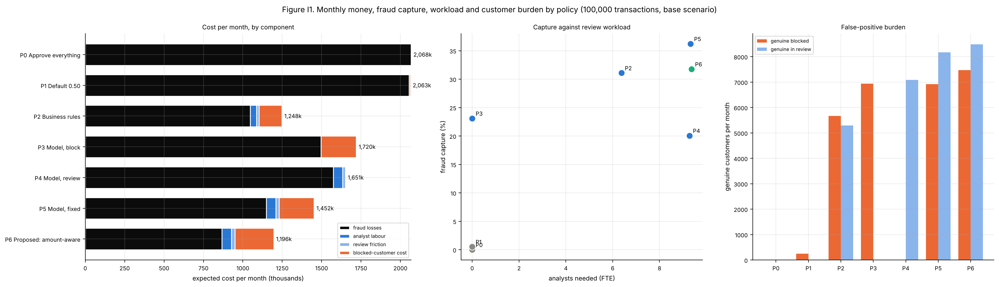

In [133]:
GREEN = "#1aaf7a"; names = [k.split(" ", 1)[1] for k in POL]; short = [k.split(" ")[0] + " " + " ".join(k.split(" ")[1:3]) for k in POL]
fig, ax = plt.subplots(1, 3, figsize=(20, 5.8), gridspec_kw=dict(width_ratios=[1.35, 1, 1]))
comp_cols = [("fraud losses", INK), ("analyst labour", BLUE), ("review friction", "#8ab4ec"), ("blocked-customer cost", ORANGE)]; left = np.zeros(len(MON)); yy = np.arange(len(MON))[::-1]
for c, col in comp_cols: ax[0].barh(yy, MON[c] / 1000, left=left / 1000, color=col, label=c, height=.7, edgecolor="white", linewidth=1.2); left += MON[c].values
for y_, v in zip(yy, MON["total cost"]): ax[0].text(v / 1000 + 15, y_, f"{v / 1000:,.0f}k", va="center", fontsize=8)
ax[0].set_yticks(yy); ax[0].set_yticklabels(short, fontsize=8); ax[0].set_xlabel("expected cost per month (thousands)"); ax[0].legend(fontsize=7, loc="lower right"); ax[0].set_title("Cost per month, by component", fontsize=9)
for i, k in enumerate(POL):
    col = GREEN if k == PROP else (GREY if k.startswith(("P0", "P1")) else BLUE); ax[1].scatter(T.loc[k, "analysts_needed_fte"], T.loc[k, "fraud_capture"] * 100, s=90, color=col, edgecolor="white", zorder=3); ax[1].annotate(k.split(" ")[0], (T.loc[k, "analysts_needed_fte"], T.loc[k, "fraud_capture"] * 100), xytext=(5, 4), textcoords="offset points", fontsize=8)
ax[1].set_xlabel("analysts needed (FTE)"); ax[1].set_ylabel("fraud capture (%)"); ax[1].set_title("Capture against review workload", fontsize=9)
w = .38; xx = np.arange(len(T)); ax[2].bar(xx - w / 2, T.legit_blocked, w, color=ORANGE, label="genuine blocked"); ax[2].bar(xx + w / 2, T.legit_reviewed, w, color="#8ab4ec", label="genuine in review"); ax[2].set_xticks(xx); ax[2].set_xticklabels([k.split(" ")[0] for k in POL]); ax[2].set_ylabel("genuine customers per month"); ax[2].legend(fontsize=7); ax[2].set_title("False-positive burden", fontsize=9)
fig.suptitle("Figure I1. Monthly money, fraud capture, workload and customer burden by policy (100,000 transactions, base scenario)", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "I01_policy_comparison.png", dpi=130, bbox_inches="tight"); plt.show()

### I5. The thresholds, written out
The proposed rule is not one cut-off: how much probability is needed to trigger a review or a block depends on the amount, because the loss from a missed fraud grows with the amount while the cost of a wrong decline barely does. The table gives the probability at which the decision changes for typical amounts, then the actual mix of decisions by amount band.

,review_from_p,block_from_p
amount,,
20,0.409,0.409
50,0.279,0.279
100,0.192,0.192
150,0.151,0.158
250,0.095,0.183
400,0.062,0.201
700,0.037,0.218
1500,0.018,0.231


,transactions,fraud rate,approve,review,block
<50,598,0.117,0.991,0.000,0.009
50-100,746,0.109,0.940,0.000,0.060
100-200,662,0.112,0.812,0.034,0.153
200-300,221,0.113,0.392,0.433,0.175
300-500,130,0.223,0.005,0.746,0.250
500+,43,0.279,0.000,0.600,0.400


Fixed-threshold policy P5 for comparison (same thresholds at every amount): {'t_review': 0.158, 't_block': 0.211}


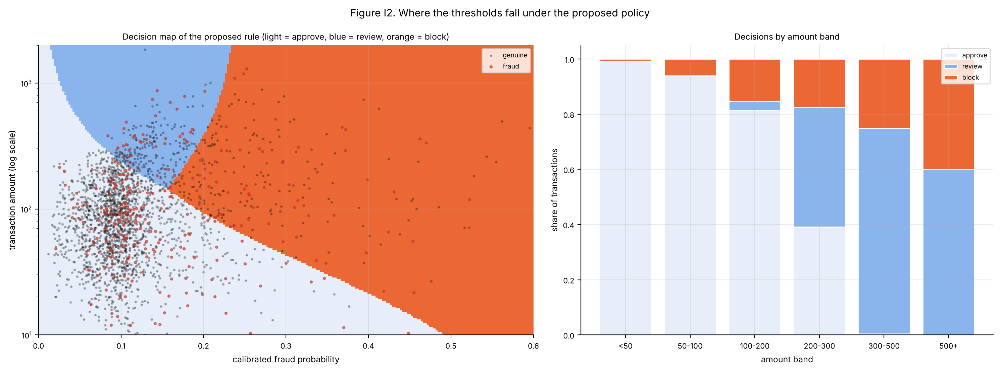

In [134]:
AMTS = [20, 50, 100, 150, 250, 400, 700, 1500]; ET = fo.effective_thresholds(SC, LAM, MU, AMTS); ET["amount"] = ET.amount.astype(int); display(ET.set_index("amount").round(3))
band = pd.cut(AMT, [0, 50, 100, 200, 300, 500, 1e9], labels=["<50", "50-100", "100-200", "200-300", "300-500", "500+"]); A6 = POL[PROP]
MIX = pd.DataFrame({"transactions": pd.Series(band).value_counts().sort_index(), "fraud rate": pd.Series(YI).groupby(band).mean(),
                    "approve": [(A6[:, band == b] == 0).mean() for b in band.categories], "review": [(A6[:, band == b] == 1).mean() for b in band.categories], "block": [(A6[:, band == b] == 2).mean() for b in band.categories]}); display(MIX.round(3))
print("Fixed-threshold policy P5 for comparison (same thresholds at every amount):", {k: round(float(v), 3) for k, v in CH["P5 Model, fixed two thresholds (Part E)"].mean().items()})
fig, ax = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw=dict(width_ratios=[1.2, 1]))
pg = np.linspace(0, .6, 241); ag = np.exp(np.linspace(np.log(10), np.log(2000), 160)); Z = np.zeros((len(ag), len(pg)), int)
for i, a in enumerate(ag): Z[i] = fo.decide(pg, np.full(len(pg), a), SC, LAM, MU)
from matplotlib.colors import ListedColormap
ax[0].pcolormesh(pg, ag, Z, cmap=ListedColormap(["#e7eef9", "#8ab4ec", ORANGE]), shading="auto"); ax[0].set_yscale("log"); ax[0].set_xlabel("calibrated fraud probability"); ax[0].set_ylabel("transaction amount (log scale)")
ax[0].scatter(CFI[0][YI == 0], AMT[YI == 0], s=3, color=INK, alpha=.25, label="genuine"); ax[0].scatter(CFI[0][YI == 1], AMT[YI == 1], s=6, color="#c0392b", alpha=.6, label="fraud"); ax[0].set_xlim(0, .6); ax[0].set_ylim(10, 2000); ax[0].legend(fontsize=7, loc="upper right")
ax[0].set_title("Decision map of the proposed rule (light = approve, blue = review, orange = block)", fontsize=9)
mm = MIX[["approve", "review", "block"]]; bottom = np.zeros(len(mm))
for c, col in [("approve", "#e7eef9"), ("review", "#8ab4ec"), ("block", ORANGE)]: ax[1].bar(mm.index.astype(str), mm[c], bottom=bottom, color=col, label=c, edgecolor="white"); bottom += mm[c].values
ax[1].set_ylabel("share of transactions"); ax[1].set_xlabel("amount band"); ax[1].legend(fontsize=7); ax[1].set_title("Decisions by amount band", fontsize=9)
fig.suptitle("Figure I2. Where the thresholds fall under the proposed policy", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "I02_decision_map.png", dpi=130, bbox_inches="tight"); plt.show()

### I6. Daily operations: how much does the workload vary?
A monthly average hides bad days. Simulated working days (2,000 per policy) draw 4,545 transactions each (100,000 per 22 working days) from the development mix and apply the policy. The review team must be sized for the busy days, not the average day.

,reviews_median,reviews_p95,reviews_p99,analysts_for_average_day,analysts_for_95pct_of_days,analysts_for_99pct_of_days,blocks_median,genuine_blocked_p95,frauds_leaking_median,frauds_leaking_p95,daily_cost_median,daily_cost_p05,daily_cost_p95
policy,,,,,,,,,,,,,
P2 Business rules (no model),310.0,339.0,351.0,6.4,7.0,8.0,369.0,283.0,379.6,409.5,56620.8,52412.7,60902.3
"P5 Model, fixed two thresholds (Part E)",456.0,509.0,526.0,9.3,11.0,11.0,443.0,357.0,351.1,381.0,65741.1,59990.1,72164.1
P6 Proposed: amount-aware rule,457.0,490.0,504.0,9.4,11.0,11.0,454.0,370.0,376.0,406.0,54340.9,50416.4,58499.0


If the proposed policy is staffed for the average day (10 analysts, 488 reviews per day), the queue exceeds daily capacity on 6.7% of days; one analyst more (536 per day) cuts this to 0.0%.


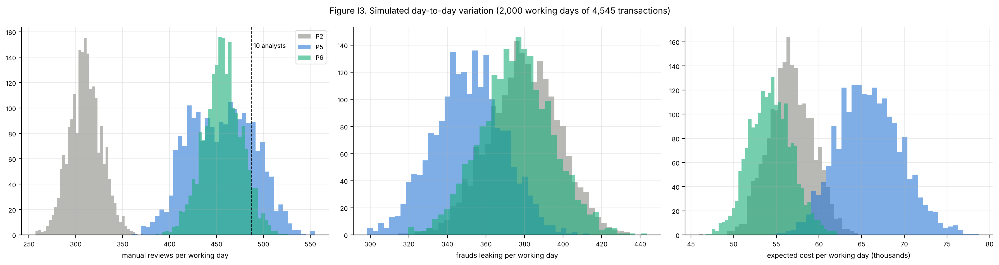

In [135]:
TPD = int(round(OPS["monthly_transactions"] / OPS["working_days"])); PER_AN_DAY = OPS["productive_hours_per_day"] * 60 / OPS["minutes_per_review"]; SIM = {}
for k in ["P2 Business rules (no model)", "P5 Model, fixed two thresholds (Part E)", PROP]: SIM[k] = fo.simulate_days(POL[k], YI, AMT, SC, n_days=2000, tx_per_day=TPD, seed=SEED_I)
rows = []
for k, s in SIM.items():
    q = s.reviews.quantile([.5, .95, .99]); rows.append(dict(policy=k, reviews_median=q[.5], reviews_p95=q[.95], reviews_p99=q[.99], analysts_for_average_day=s.reviews.mean() / PER_AN_DAY, analysts_for_95pct_of_days=np.ceil(q[.95] / PER_AN_DAY), analysts_for_99pct_of_days=np.ceil(q[.99] / PER_AN_DAY),
                                                                  blocks_median=s.blocks.median(), genuine_blocked_p95=s.legit_blocked.quantile(.95), frauds_leaking_median=s.frauds_leaking.median(), frauds_leaking_p95=s.frauds_leaking.quantile(.95), daily_cost_median=s.cost.median(), daily_cost_p05=s.cost.quantile(.05), daily_cost_p95=s.cost.quantile(.95)))
DAY = pd.DataFrame(rows).set_index("policy"); display(DAY.round(1))
FTE = int(np.ceil(SIM[PROP].reviews.mean() / PER_AN_DAY)); cap_day = FTE * PER_AN_DAY; print(f"If the proposed policy is staffed for the average day ({FTE} analysts, {cap_day:,.0f} reviews per day), the queue exceeds daily capacity on {(SIM[PROP].reviews > cap_day).mean():.1%} of days; one analyst more ({cap_day + PER_AN_DAY:,.0f} per day) cuts this to {(SIM[PROP].reviews > cap_day + PER_AN_DAY).mean():.1%}.")
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8)); cols = {"P2 Business rules (no model)": GREY, "P5 Model, fixed two thresholds (Part E)": BLUE, PROP: GREEN}
for k, s in SIM.items(): ax[0].hist(s.reviews, bins=40, alpha=.6, color=cols[k], label=k.split(" ")[0]); ax[1].hist(s.frauds_leaking, bins=40, alpha=.6, color=cols[k], label=k.split(" ")[0]); ax[2].hist(s.cost / 1000, bins=40, alpha=.6, color=cols[k], label=k.split(" ")[0])
ax[0].axvline(cap_day, color=INK, ls="--", lw=1); ax[0].text(cap_day, ax[0].get_ylim()[1] * .9, f" {FTE} analysts", fontsize=8); ax[0].set_xlabel("manual reviews per working day"); ax[1].set_xlabel("frauds leaking per working day"); ax[2].set_xlabel("expected cost per working day (thousands)"); ax[0].legend(fontsize=8)
fig.suptitle("Figure I3. Simulated day-to-day variation (2,000 working days of 4,545 transactions)", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "I03_daily_simulation.png", dpi=130, bbox_inches="tight"); plt.show()

### I7. Does the ranking of policies survive other cost assumptions?
The seven Part E scenarios are re-run for every policy with thresholds re-chosen honestly in each (the shadow prices of the proposed rule are recomputed too). Entries are monthly expected cost.

In [136]:
SCN = {}; rows = []
for nm, sc in fc_i.SCENARIOS.items():
    pol = {"P0": fo.static_actions(np.zeros(NI, int), 2), "P1": POL["P1 Default 0.50 cut-off"], "P2": POL["P2 Business rules (no model)"]}
    for key, kind in [("P3", "block"), ("P4", "review_only"), ("P5", "three_way")]: pol[key], _ = fo.honest_actions(P2, YI, AMT, sc, fc_i.chooser_cost(kind, sc, AMT, YI), n_cv_repeats=3, seed=SEED_I)
    pol["P6"], _, _ = fo.amount_aware_actions(CFI[::2], AMT, sc); SCN[nm] = pol
    mon = {k: fo.cost_components(v, YI, AMT, sc).total.mean() * OPS["monthly_transactions"] for k, v in pol.items()}
    rows.append(dict(scenario=nm, **mon, best_simpler=min([k for k in mon if k not in ("P6", "P0")], key=mon.get), proposed_vs_best_simpler_pct=100 * (mon["P6"] / min(v for k, v in mon.items() if k not in ("P6", "P0")) - 1),
                     proposed_review_share=np.mean([(a == 1).mean() for a in pol["P6"]]), proposed_block_share=np.mean([(a == 2).mean() for a in pol["P6"]]), proposed_capture=fo.ops_metrics(pol["P6"], YI, AMT, sc).fraud_capture))
SENS = pd.DataFrame(rows).set_index("scenario"); display(SENS.round(3))
print(f"The proposed policy is the cheapest of all seven policies in {int((SENS[['P0','P1','P2','P3','P4','P5']].min(axis=1) > SENS.P6).sum())} of {len(SENS)} scenarios; its saving over the cheapest simpler policy ranges from {-SENS.proposed_vs_best_simpler_pct.max():.1f}% to {-SENS.proposed_vs_best_simpler_pct.min():.1f}%.")

,P0,P1,P2,P3,P4,P5,P6,best_simpler,proposed_vs_best_simpler_pct,proposed_review_share,proposed_block_share,proposed_capture
scenario,,,,,,,,,,,,
S1_base,2067677.083,2063248.500,1248240.798,1723694.405,1653365.234,1454142.213,1196204.591,P2,-4.169,0.100,0.100,0.319
S2_fraud_averse,2370802.083,2362311.000,1398892.881,1879096.499,1893699.609,1571278.008,1315169.672,P2,-5.985,0.103,0.100,0.329
S3_customer_first,2067677.083,2074769.475,1510879.718,2084277.222,1674186.285,1714186.637,1314983.117,P2,-12.966,0.100,0.007,0.186
S4_review_expensive,2067677.083,2063248.500,1309740.798,1723694.405,1748273.629,1542613.951,1286654.591,P2,-1.763,0.100,0.100,0.319
S5_review_cheap_big_team,2067677.083,2063248.500,1224324.131,1723694.405,1317602.820,1255226.488,1023747.145,P2,-16.383,0.200,0.068,0.376
S6_partial_recovery,1252731.250,1253025.583,837935.565,1144016.391,1032718.799,1037466.769,794902.597,P2,-5.136,0.100,0.036,0.237
S7_no_operational_limits,2067677.083,2063248.500,1248240.798,1569788.273,1076897.707,1085166.088,992553.911,P4,-7.832,0.544,0.012,0.585


The proposed policy is the cheapest of all seven policies in 7 of 7 scenarios; its saving over the cheapest simpler policy ranges from 1.8% to 16.4%.


### I8. Capacity stress: what if the review team is smaller or larger, or fewer customers may be blocked?
The cost framework is unchanged; only the operating limits move. This shows how fast fraud leaks when the queue is capped, and what extra review capacity is worth.

,sweep,limit,policy,cost,fraud_capture,reviews,analysts,genuine_blocked
0,review capacity,2%,P5 fixed thresholds,1672950.633,0.253,1881.944,1.755,6784.722
1,review capacity,2%,P6 proposed,1332323.346,0.238,2137.500,1.993,7575.000
2,review capacity,5%,P5 fixed thresholds,1576344.352,0.305,5055.556,4.714,7041.667
3,review capacity,5%,P6 proposed,1267435.143,0.270,5129.167,4.782,7712.500
4,review capacity,10%,P5 fixed thresholds,1454142.213,0.362,9986.111,9.311,6930.556
5,review capacity,10%,P6 proposed,1196204.591,0.319,10050.000,9.371,7466.667
6,review capacity,15%,P5 fixed thresholds,1367658.933,0.407,15006.944,13.992,6895.833
7,review capacity,15%,P6 proposed,1148548.915,0.354,15000.000,13.986,6587.500
8,review capacity,20%,P5 fixed thresholds,1325796.836,0.419,19784.722,18.447,5354.167
9,review capacity,20%,P6 proposed,1093747.145,0.376,20000.000,18.648,4775.000


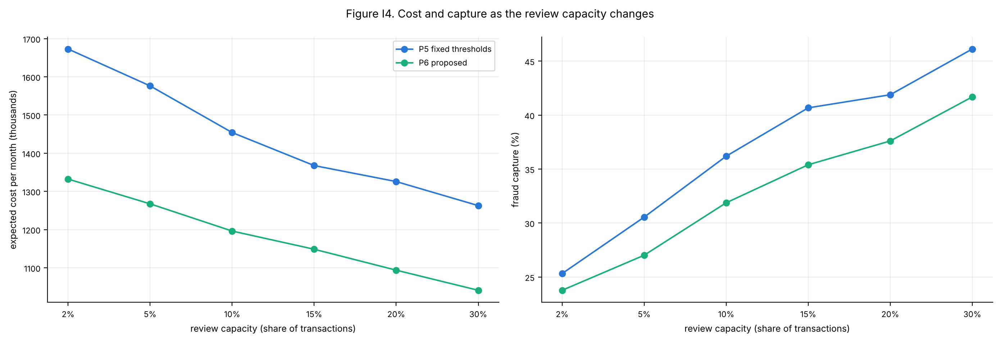

In [137]:
rows = []
for rc in [0.02, 0.05, 0.10, 0.15, 0.20, 0.30]:
    sc = SC.with_(review_capacity=rc); a6, l_, m_ = fo.amount_aware_actions(CFI[::2], AMT, sc); a5, _ = fo.honest_actions(P2, YI, AMT, sc, fc_i.chooser_cost("three_way", sc, AMT, YI), n_cv_repeats=3, seed=SEED_I)
    for nm, a in [("P5 fixed thresholds", a5), ("P6 proposed", a6)]:
        m = fo.ops_metrics(a, YI, AMT, sc); rows.append(dict(sweep="review capacity", limit=f"{rc:.0%}", policy=nm, cost=fo.cost_components(a, YI, AMT, sc).total.mean() * OPS["monthly_transactions"], fraud_capture=m.fraud_capture, reviews=m.review, analysts=m.analysts_needed_fte, genuine_blocked=m.legit_blocked))
for bc in [0.02, 0.05, 0.10, 0.15, 0.25]:
    sc = SC.with_(max_block_rate=bc); a6, l_, m_ = fo.amount_aware_actions(CFI[::2], AMT, sc); m = fo.ops_metrics(a6, YI, AMT, sc)
    rows.append(dict(sweep="block limit", limit=f"{bc:.0%}", policy="P6 proposed", cost=fo.cost_components(a6, YI, AMT, sc).total.mean() * OPS["monthly_transactions"], fraud_capture=m.fraud_capture, reviews=m.review, analysts=m.analysts_needed_fte, genuine_blocked=m.legit_blocked))
CAPS = pd.DataFrame(rows); display(CAPS.round(3))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8)); d = CAPS[CAPS.sweep == "review capacity"]
for nm, col in [("P5 fixed thresholds", BLUE), ("P6 proposed", GREEN)]:
    s = d[d.policy == nm]; ax[0].plot(s.limit, s.cost / 1000, "o-", color=col, label=nm); ax[1].plot(s.limit, s.fraud_capture * 100, "o-", color=col, label=nm)
ax[0].set_xlabel("review capacity (share of transactions)"); ax[0].set_ylabel("expected cost per month (thousands)"); ax[1].set_xlabel("review capacity (share of transactions)"); ax[1].set_ylabel("fraud capture (%)"); ax[0].legend(fontsize=8)
fig.suptitle("Figure I4. Cost and capture as the review capacity changes", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "I04_capacity_stress.png", dpi=130, bbox_inches="tight"); plt.show()

### I9. Findings

**Setup.** 100,000 hypothetical transactions per month with the development mix (12.1% fraud), base cost scenario S1, limits of 10% reviewed and 10% blocked, honest out-of-fold calibrated probabilities, hold-out untouched. All money is hypothetical.

**The three decisions and thresholds.** The cost framework gives break-even probabilities, not one cut-off: for fixed thresholds the cost search chooses review from 0.158 and block from 0.211 (calibrated probability), stable across training folds. The proposed rule instead compares the expected cost of the three actions per transaction. For amounts up to about 100 there is no review band (approve below roughly 0.19 to 0.41, block above); at 250 a transaction is reviewed from 0.095 and blocked from 0.183; at 700 review starts at 0.037. The shadow price of a review (13.2 against a real cost of 6) shows that the 10% review limit is the binding constraint.

**Monthly picture of the proposed policy (P6).** About 79,950 approved, 10,050 reviewed and 10,000 blocked. Of 12,125 frauds, 3,850 are stopped (31.8% by count, 60.6% by value: 1.14 million of 1.89 million of fraud value) and 8,270 leak. The burden on genuine customers: 7,475 blocked (8.5% of genuine transactions) and 8,490 held for review, so 18.2% of genuine customers are touched; about 5.2 flagged transactions per fraud stopped. Review needs about 457 reviews per working day, 9.4 analysts on average, 11 analysts to cover 95% and 99% of days. Expected cost 1.20 million a month against 2.07 million for approving everything.

**Comparison with simpler policies (monthly expected cost, saving of the proposed policy).**
* Approve everything 2.07 million: proposed saves 42.1% (871 thousand, interval 578 to 1,183 thousand); about 10.5 million a year.
* Default 0.50 cut-off 2.06 million: it blocks only 0.3% of transactions and stops under 1% of fraud, so it is no better than doing nothing (saving 42.0%).
* Model with one block threshold 1.72 million (saves 30.5%) and model with a review threshold only 1.65 million (27.5%): both significantly dearer.
* Part E fixed two thresholds 1.45 million: proposed saves 17.6% (256 thousand a month, interval 129 to 399 thousand). The fixed policy stops more frauds by count (36.2% against 31.8%) but the frauds it leaks are the expensive ones, so it loses on money: the objective is value, not the number of frauds caught.
* Business rules without a model 1.25 million: proposed saves 4.2% (52 thousand a month), **but the interval runs from a loss of 39 thousand to a saving of 149 thousand, so the difference is not statistically reliable**. These rules were fixed from Part B and H patterns on the same development data, so the benchmark is favourable to them. The rules are the cheapest simpler policy in 6 of 7 scenarios, which is an honest lesson: much of the value sits in red flags and large amounts, and a model that ignores the amount (P3 to P5) can lose to simple rules.

**Robustness to cost assumptions.** The proposed policy has the lowest expected cost in all seven Part E scenarios, with a saving of 1.8% to 16.4% over the cheapest simpler policy (smallest when reviews are expensive, largest with a bigger, cheaper team). Treat the ranking against business rules as suggestive, not proven.

**Capacity.** Fraud capture grows with review capacity: 23.8% at 2% reviewed, 27.0% at 5%, 31.9% at 10%, 37.6% at 20%, 41.7% at 30%, and expected cost falls from 1.33 to 1.04 million. Moving from 10% to 15% reviews (4.6 more analysts) lowers net cost by about 48 thousand a month after paying for the analysts, so extra capacity is worth adding in the base scenario but with diminishing returns. Tightening the block limit from 10% to 2% costs only about 47 thousand a month but cuts genuine customers blocked from 7,475 to 1,329, a useful lever if customer experience matters.

**Operational caution.** Staffing for the average day (10 analysts) leaves the queue over capacity on about 6.7% of days; one more analyst removes this in the simulation.

**Limits.** The 12.1% fraud rate is far above a real portfolio; at lower prevalence precision falls and review burden per fraud rises (Part J). Costs and staffing are assumptions. The rule was selected on the same development rows it is evaluated on (probabilities and fixed thresholds are out-of-fold, the design choice is not). The hold-out set is still unused and reserved for the final check. Capture by count is only about a third, reflecting the model's modest ranking power (PR-AUC about 0.24).

**Recommendation.** Deploy the amount-aware three-way rule with Platt-calibrated probabilities and staff reviews for about 11 analysts per 100,000 monthly transactions, with the fixed 0.158 / 0.211 thresholds as a simple fallback (still 30% cheaper than approving everything), and retain business rules for the largest amounts until the hold-out and drift checks of Parts J and K confirm the advantage.

In [138]:
policy_json = dict(policy="proposed amount-aware expected-cost rule", model="RF + Platt", scenario=SC.as_dict(), shadow_price_review=LAM, shadow_price_block=MU, platt=json.load(open(OUT / "F_calibration_choice.json"))["platt"],
                   fixed_threshold_alternative=json.load(open(OUT / "F_calibration_choice.json"))["thresholds_calibrated"], decide_function="fraud_ops.decide(p, amount, scenario, shadow_price_review, shadow_price_block)", ops_assumptions=OPS, seed=SEED_I)
json.dump(policy_json, open(OUT / "I_decision_policy.json", "w"), indent=2)
chk = fo.decide(CFI[0], AMT, SC, *[fcal_i.capped_bayes_actions(CFI[0], AMT, SC)[i] for i in (1, 2)]); assert (chk == fcal_i.capped_bayes_actions(CFI[0], AMT, SC)[0]).all(); print("fraud_ops.decide reproduces the rule exactly")
T.to_csv(OUT / "I_policy_comparison_monthly.csv"); CMP.to_csv(OUT / "I_paired_cost_comparison.csv"); ET.to_csv(OUT / "I_effective_thresholds_by_amount.csv", index=False); MIX.to_csv(OUT / "I_decision_mix_by_amount.csv"); DAY.to_csv(OUT / "I_daily_simulation_summary.csv")
SENS.to_csv(OUT / "I_scenario_sensitivity.csv"); CAPS.to_csv(OUT / "I_capacity_stress.csv", index=False); ASSUME.to_csv(OUT / "I_assumptions.csv")
print("Part I tables saved; figures:", sorted(p.name for p in FIG.glob("I0*.png")), "| hold-out rows read: none")

fraud_ops.decide reproduces the rule exactly
Part I tables saved; figures: ['I01_policy_comparison.png', 'I02_decision_map.png', 'I03_daily_simulation.png', 'I04_capacity_stress.png'] | hold-out rows read: none


---
## Part J. Robustness and Stress Testing

**Goal:** find out how far the decision engine can be pushed before it stops being useful, which kinds of change hurt it, how much of what we see is just sampling noise, and what should be watched after deployment.

| Task J requirement | Section |
|---|---|
| Simulated distribution shifts (amounts, velocity, channel mix) | J3, J4 |
| Sensitivity to missing values and extreme observations | J5, J6 |
| Cross-validation fold performance and its variability | J2 |
| Causes of degradation after deployment | J8, J9 |

**Design (fixed before looking at any result)**
1. **Honest by construction.** The production Random Forest pipeline is refitted on the training part of each outer fold (the same 5 x 2 folds as Part D); stresses are applied to the **test part only**; the model is never trained on stressed data (except in one labelled retraining test in J6). The Platt layer of Part F and the decision rule of Part I (base cost scenario S1) are applied; the rule's two shadow prices are set once, label-free, on the unstressed baseline scores and then frozen for every stress. Hold-out rows are not read.
2. **Two families of stress, because they answer different questions.** *Population shifts* change who arrives (more large amounts, more velocity, another channel mix, another fraud rate) while the link between inputs and fraud stays as measured; labels and inputs are untouched and rows are re-weighted (exponential tilting, post-stratification, class weights). *Input perturbations* feed the model distorted inputs (a unit change, a counting change, missing values, outliers, fraudsters hiding red flags) with labels kept, so the damage to scores and money is measured exactly.
3. **What is measured in every scenario:** ranking (PR-AUC, ROC-AUC, recall in the top 10%), calibration (mean predicted against observed rate, slope, ECE), the **frozen** Part I policy (review share, block share, fraud capture, cost per 100,000 and saving against approving everything in that same scenario), and an **adaptive** policy that only re-prices the shadow prices from the new scores (no labels), to see how much an operational re-tune recovers.
4. **Pass / Watch / Fail rules, set now.** Measured against the unstressed baseline: *Watch* if PR-AUC falls by more than 10% (relative), or the saving against approve-all falls by more than 5 points, or the frozen review share exceeds 12% (limit 10%), or mean predicted / observed leaves 0.80 to 1.25. *Fail* if PR-AUC falls by more than 25%, or the saving falls by more than 10 points, or the review share exceeds 15%, or the calibration ratio leaves 0.67 to 1.50. The same limits apply to the block share (10% limit: Watch above 12%, Fail above 15%). Two exceptions, because the yardstick itself moves: for **prevalence shifts** PR-AUC and the saving change by themselves, so the test is whether the policy still beats approving everything (Fail below 0%, Watch below 20%) and whether probabilities are right (calibration ratio as above); evaluations on **subsets** (extreme amounts removed) are labelled Info, since they change the population, not the model. These are judgement thresholds, not statistical tests; they are there so that "robust" has a fixed meaning.
5. **Noise yardstick.** Differences are judged against the fold-to-fold variability measured in J2 and against bootstrap intervals, because with 291 frauds a 3% change in PR-AUC is within noise.

### J1. Setup: honest out-of-fold baseline

In [139]:
import joblib, json
import fraud_models as fm_j, fraud_eval as fe_j, fraud_costs as fc_j, fraud_calibration as fcal_j, fraud_ops as fo_j, fraud_stress as st
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score
SEED_J = 42
Xj, yj, idj = fm_j.load_dev(); YJ = yj.to_numpy(); NJ = len(YJ)
SPL = fe_j.make_splits(yj, n_splits=5, n_repeats=2, seed=SEED_J)
TEMPLATE = clone(joblib.load(OUT / "models" / "D_RF.joblib")); CAL = json.load(open(OUT / "F_calibration_choice.json"))["platt"]; POLJ = json.load(open(OUT / "I_decision_policy.json"))
SCJ = fc_j.SCENARIOS["S1_base"]
meta_j = pd.DataFrame({ID: idj.values}).merge(df, on=ID, how="left"); AMTJ = meta_j.transaction_amount.fillna(meta_j.transaction_amount.median()).to_numpy()
import time; t0 = time.time(); MODELS = st.fit_folds(TEMPLATE, Xj, yj, SPL); print(f"{len(MODELS)} fold models fitted in {time.time() - t0:.0f}s (5 folds x 2 repeats; {len(SPL[0][0])} training / {len(SPL[0][1])} test rows each)")
KEEP_COLS = ["transaction_amount", "transactions_last_1h", "channel", "merchant_risk_score", "ip_risk_score"]
S0 = st.oof_predict(MODELS, SPL, Xj, yj, AMTJ, cal=CAL, keep_cols=KEEP_COLS); W1 = np.ones(NJ)
_a = np.where(np.isnan(S0["amount_seen"]), np.nanmedian(S0["amount_seen"]), S0["amount_seen"])
_pr = [st.capped_bayes_weighted(S0["p"][r], _a[r], SCJ, W1)[1:] for r in range(2)]; LAMJ, MUJ = float(np.mean([x[0] for x in _pr])), float(np.mean([x[1] for x in _pr]))     # label-free, from the baseline scores
print(f"Frozen shadow prices for this study (label-free, set on the unstressed baseline scores): review {LAMJ:.2f}, block {MUJ:.2f}  (Part I deliverable: {POLJ['shadow_price_review']:.2f} and {POLJ['shadow_price_block']:.2f}; the fold-refit models are spread slightly differently)")
BASE = st.evaluate_scenario(S0, YJ, W1, SCJ, LAMJ, MUJ); BASEROW = pd.Series(BASE)
print(f"Baseline (out-of-fold, unstressed): PR-AUC {BASE['pr_auc']:.3f}, ROC-AUC {BASE['roc_auc']:.3f}, recall in top 10% {BASE['recall_top10']:.3f}, Brier {BASE['brier']:.4f}, calibration slope {BASE['cal_slope']:.2f}")
print(f"Frozen Part I policy: review share {BASE['frozen_review_share']:.3f}, block share {BASE['frozen_block_share']:.3f}, fraud capture {BASE['frozen_capture']:.3f}, cost per 100,000 {BASE['frozen_cost_per_100k']:,.0f} vs {BASE['approve_all_per_100k']:,.0f} approving everything (saving {BASE['frozen_saving_pct']:.1f}%)")
print(f"Adaptive re-pricing on the same scores: saving {BASE['adaptive_saving_pct']:.1f}% (shadow price of a review {BASE['adaptive_shadow_review']:.2f} vs frozen {LAMJ:.2f})")

10 fold models fitted in 13s (5 folds x 2 repeats; 1920 training / 480 test rows each)


Frozen shadow prices for this study (label-free, set on the unstressed baseline scores): review 13.80, block 2.13  (Part I deliverable: 13.15 and 1.88; the fold-refit models are spread slightly differently)
Baseline (out-of-fold, unstressed): PR-AUC 0.235, ROC-AUC 0.662, recall in top 10% 0.234, Brier 0.1019, calibration slope 1.18
Frozen Part I policy: review share 0.101, block share 0.100, fraud capture 0.310, cost per 100,000 1,206,968 vs 2,067,677 approving everything (saving 41.6%)
Adaptive re-pricing on the same scores: saving 41.6% (shadow price of a review 13.80 vs frozen 13.80)


In [140]:
RESULTS = []
def judge(r, kind="standard"):
    ratio = r["mean_pred"] / r["observed"]; rev = r["frozen_review_share"]; blk = r["frozen_block_share"]; sav = r["frozen_saving_pct"]
    if kind == "info": return "Info", "evaluation on a subset, not a model change"
    flags = []; lv = 0
    if kind == "prevalence":                       # PR-AUC and the saving move with prevalence by themselves, so the yardsticks are: does it still beat approving everything, and are probabilities right?
        for cond_w, cond_f, msg in [(sav < 20, sav < 0, f"saving {sav:.1f}%"), (not .8 <= ratio <= 1.25, not .67 <= ratio <= 1.5, f"calibration ratio {ratio:.2f}")]:
            if cond_f: lv = max(lv, 2); flags.append(msg)
            elif cond_w: lv = max(lv, 1); flags.append(msg)
        return ["Pass", "Watch", "Fail"][lv], "; ".join(flags)
    drop_pr = 1 - r["pr_auc"] / BASE["pr_auc"]; drop_sav = BASE["frozen_saving_pct"] - sav
    for cond_w, cond_f, msg in [(drop_pr > .10, drop_pr > .25, f"PR-AUC {-100 * drop_pr:+.0f}%"), (drop_sav > 5, drop_sav > 10, f"saving {-drop_sav:+.1f} pts"), (rev > .12, rev > .15, f"review share {rev:.1%}"),
                                (blk > .12, blk > .15, f"block share {blk:.1%}"), (not .8 <= ratio <= 1.25, not .67 <= ratio <= 1.5, f"calibration ratio {ratio:.2f}")]:
        if cond_f: lv = max(lv, 2); flags.append(msg)
        elif cond_w: lv = max(lv, 1); flags.append(msg)
    return ["Pass", "Watch", "Fail"][lv], "; ".join(flags)
def run(group, name, desc, perturb=None, w=None, p_override_fn=None, boot=True, repeats_seed=SEED_J, kind="standard"):
    S = S0 if perturb is None else st.oof_predict(MODELS, SPL, Xj, yj, AMTJ, perturb=perturb, cal=CAL, keep_cols=KEEP_COLS, seed=repeats_seed); w_ = W1 if w is None else w
    po = None if p_override_fn is None else p_override_fn(S, w_)
    r = st.evaluate_scenario(S, YJ, w_, SCJ, LAMJ, MUJ, p_override=po); r.update(group=group, scenario=name, description=desc)
    if boot: r["pr_auc_lo"], r["pr_auc_hi"] = st.bootstrap_metric(S if po is None else dict(S, p=po), YJ, w_, lambda y, p, ww: average_precision_score(y, p, sample_weight=ww), B=120)
    r["status"], r["why"] = judge(r, kind)
    for c, f in [("psi_amount", ("transaction_amount", Xj.transaction_amount)), ("psi_velocity", ("transactions_last_1h", Xj.transactions_last_1h)), ("psi_channel", ("channel", Xj.channel))]:
        r[c] = st.psi(f[1], S["X_seen"][f[0]], w_)
    r["psi_score"] = st.psi(S0["p"][0], S["p"][0] if po is None else po[0], w_)
    RESULTS.append(r); return r, S
r0, _ = run("Baseline", "Unstressed", "Out-of-fold, no stress"); print("baseline PR-AUC interval:", round(r0["pr_auc_lo"], 3), round(r0["pr_auc_hi"], 3), "| PSI of the baseline against itself (should be near 0):", {k: round(v, 3) for k, v in r0.items() if k.startswith("psi")})

baseline PR-AUC interval: 0.201 0.277 | PSI of the baseline against itself (should be near 0): {'psi_amount': 0.0, 'psi_velocity': 0.0, 'psi_channel': 0.0, 'psi_score': 0.0}


### J2. Fold-to-fold variability: how much of any difference is noise?
Ten test folds (5 folds x 2 repeats) of about 480 transactions and 58 frauds each. The spread below is the yardstick for every later comparison.

In [141]:
FT = st.fold_table(S0["p"], YJ, SPL, AMTJ, SCJ, LAMJ, MUJ); ntr, nte = len(SPL[0][0]), len(SPL[0][1])
cols = ["pr_auc", "roc_auc", "recall_top10", "brier", "cal_slope", "ece", "cost_per_1000", "saving_pct", "review_share", "block_share", "capture"]
summ = pd.DataFrame({"mean": FT[cols].mean(), "sd": FT[cols].std(ddof=1), "min": FT[cols].min(), "max": FT[cols].max()}); summ["cv_pct"] = 100 * summ.sd / summ["mean"].abs()
summ["corrected_se_of_mean"] = [st.nadeau_bengio_se(FT[c], ntr, nte) for c in cols]; summ["95%_interval_of_mean"] = [f"[{m - 2.26 * s:.3f}, {m + 2.26 * s:.3f}]" for m, s in zip(summ["mean"], summ.corrected_se_of_mean)]; display(summ.round(4))
rng_f = np.random.default_rng(SEED_J); wb = []
for i, (tr, te) in enumerate(SPL[:5]):
    p, yy = S0["p"][0][te], YJ[te]; wb.append(np.std([average_precision_score(yy[j], p[j]) for j in (rng_f.integers(0, len(te), len(te)) for _ in range(300))], ddof=1))
print(f"Observed SD of PR-AUC across folds {FT.pr_auc.std(ddof=1):.3f}; sampling noise inside one fold of {nte} rows (bootstrap) {np.mean(wb):.3f}  -> most of the fold-to-fold spread is plain sampling noise from only {FT.frauds.mean():.0f} frauds per fold.")
print(f"Repeat 0 mean PR-AUC {FT[FT.repeat == 0].pr_auc.mean():.3f}, repeat 1 {FT[FT.repeat == 1].pr_auc.mean():.3f} (the choice of random partition moves the average by {abs(FT[FT.repeat == 0].pr_auc.mean() - FT[FT.repeat == 1].pr_auc.mean()):.3f}).")
print(f"Worst fold PR-AUC {FT.pr_auc.min():.3f} (no-skill {YJ.mean():.3f}); worst fold saving against approve-all {FT.saving_pct.min():.1f}% vs best {FT.saving_pct.max():.1f}%; share of folds where the model beats no-skill PR-AUC: {(FT.pr_auc > YJ.mean()).mean():.0%}; share where the policy beats approve-all: {(FT.saving_pct > 0).mean():.0%}")
display(FT.round(3).set_index("fold")[["repeat", "frauds", "pr_auc", "roc_auc", "recall_top10", "brier", "cal_slope", "saving_pct", "review_share", "block_share", "capture"]])

,mean,sd,min,max,cv_pct,corrected_se_of_mean,95%_interval_of_mean
pr_auc,0.2588,0.0530,0.2028,0.3797,20.4906,0.0314,"[0.188, 0.330]"
roc_auc,0.6647,0.0370,0.6365,0.7575,5.5610,0.0219,"[0.615, 0.714]"
recall_top10,0.2369,0.0436,0.1897,0.3390,18.3833,0.0258,"[0.179, 0.295]"
brier,0.1019,0.0016,0.0988,0.1037,1.5365,0.0009,"[0.100, 0.104]"
cal_slope,1.2210,0.3847,0.9057,2.1862,31.5097,0.2276,"[0.707, 1.735]"
ece,0.0363,0.0087,0.0242,0.0487,23.9410,0.0051,"[0.025, 0.048]"
cost_per_1000,12069.6836,948.6952,10527.0762,13515.1030,7.8601,561.2556,"[10801.246, 13338.121]"
saving_pct,40.8018,9.1201,28.5391,55.0329,22.3523,5.3955,"[28.608, 52.996]"
review_share,0.1008,0.0125,0.0896,0.1229,12.4043,0.0074,"[0.084, 0.118]"
block_share,0.0998,0.0132,0.0854,0.1250,13.2567,0.0078,"[0.082, 0.117]"


Observed SD of PR-AUC across folds 0.053; sampling noise inside one fold of 480 rows (bootstrap) 0.050  -> most of the fold-to-fold spread is plain sampling noise from only 58 frauds per fold.
Repeat 0 mean PR-AUC 0.260, repeat 1 0.257 (the choice of random partition moves the average by 0.003).
Worst fold PR-AUC 0.203 (no-skill 0.121); worst fold saving against approve-all 28.5% vs best 55.0%; share of folds where the model beats no-skill PR-AUC: 100%; share where the policy beats approve-all: 100%


,repeat,frauds,pr_auc,roc_auc,recall_top10,brier,cal_slope,saving_pct,review_share,block_share,capture
fold,,,,,,,,,,,
0,0,59,0.380,0.757,0.339,0.099,2.186,46.148,0.096,0.085,0.287
1,0,58,0.203,0.671,0.207,0.103,0.997,50.807,0.121,0.096,0.363
2,0,58,0.281,0.637,0.259,0.101,1.148,45.295,0.092,0.088,0.329
3,0,58,0.212,0.648,0.190,0.104,0.906,30.789,0.090,0.125,0.272
4,0,58,0.226,0.638,0.190,0.103,0.969,32.924,0.108,0.100,0.290
5,1,59,0.240,0.644,0.237,0.104,0.997,32.282,0.094,0.110,0.273
6,1,58,0.257,0.675,0.259,0.101,1.333,55.033,0.123,0.112,0.454
7,1,58,0.291,0.687,0.224,0.101,1.505,42.276,0.102,0.085,0.272
8,1,58,0.216,0.652,0.241,0.102,1.057,28.539,0.090,0.092,0.216


,segment,group,n,frauds,observed_rate,mean_predicted,ratio_pred_obs,ratio_lo,ratio_hi,pr_auc,roc_auc,calibration_flag
0,channel,E-commerce,938,134,0.143,0.123,0.858,0.742,1.014,0.269,0.673,
1,channel,POS,770,73,0.095,0.119,1.256,1.039,1.574,0.223,0.685,interval excludes 1
2,channel,Mobile App,471,62,0.132,0.125,0.953,0.772,1.194,0.282,0.661,
3,channel,ATM,221,22,0.100,0.125,1.255,0.862,1.927,0.152,0.543,
4,amount band,<50,598,70,0.117,0.114,0.972,0.786,1.232,0.274,0.708,
5,amount band,50-100,746,81,0.109,0.115,1.056,0.861,1.324,0.223,0.662,
6,amount band,100-200,662,74,0.112,0.122,1.088,0.892,1.354,0.222,0.608,
7,amount band,300+,173,41,0.237,0.178,0.749,0.587,1.014,0.282,0.478,
8,amount band,200-300,221,25,0.113,0.130,1.146,0.842,1.725,0.282,0.663,
9,customer tier,Basic,898,130,0.145,0.124,0.859,0.736,1.008,0.264,0.655,


Segments whose calibration interval excludes parity: [{'segment': 'channel', 'group': 'POS', 'ratio_pred_obs': 1.26}, {'segment': 'merchant category', 'group': 'Fuel', 'ratio_pred_obs': 1.47}, {'segment': 'merchant category', 'group': 'Jewelry', 'ratio_pred_obs': 0.61}]


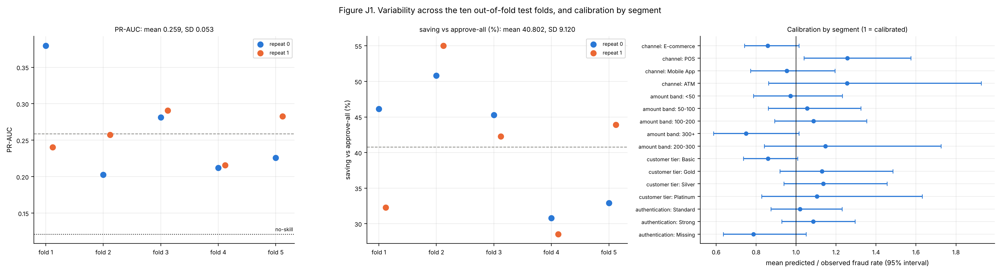

In [142]:
def seg_table(label, seg):
    rows = []; rng = np.random.default_rng(SEED_J)
    for g in pd.Series(seg).dropna().unique():
        m = (np.asarray(seg) == g)
        if m.sum() < 60: continue
        p = S0["p"].mean(0)[m]; y_ = YJ[m]; ratios = [p[i].mean() / max(y_[i].mean(), 1e-9) for i in (rng.integers(0, m.sum(), m.sum()) for _ in range(400))]
        rows.append(dict(segment=label, group=str(g), n=int(m.sum()), frauds=int(y_.sum()), observed_rate=y_.mean(), mean_predicted=p.mean(), ratio_pred_obs=p.mean() / y_.mean(), ratio_lo=np.quantile(ratios, .025), ratio_hi=np.quantile(ratios, .975),
                         pr_auc=average_precision_score(y_, p) if y_.sum() >= 5 else np.nan, roc_auc=roc_auc_score(y_, p) if 0 < y_.sum() < len(y_) else np.nan))
    return pd.DataFrame(rows)
band_j = pd.cut(AMTJ, [0, 50, 100, 200, 300, 1e9], labels=["<50", "50-100", "100-200", "200-300", "300+"])
SEG = pd.concat([seg_table("channel", Xj.channel.astype(str).to_numpy()), seg_table("amount band", band_j.astype(str)), seg_table("customer tier", Xj.customer_tier.astype(str).to_numpy()), seg_table("authentication", Xj.authentication_level.fillna("Missing").astype(str).to_numpy()),
                 seg_table("merchant category", Xj.merchant_category.astype(str).to_numpy()), seg_table("country", Xj.country.astype(str).to_numpy())], ignore_index=True)
SEG["calibration_flag"] = np.where((SEG.ratio_lo > 1) | (SEG.ratio_hi < 1), "interval excludes 1", ""); display(SEG.round(3))
print("Segments whose calibration interval excludes parity:", SEG[SEG.calibration_flag != ""][["segment", "group", "ratio_pred_obs"]].round(2).to_dict("records"))
fig, ax = plt.subplots(1, 3, figsize=(19, 5.2), gridspec_kw=dict(width_ratios=[1.15, 1.15, 1.3]))
for a, c, t in [(ax[0], "pr_auc", "PR-AUC"), (ax[1], "saving_pct", "saving vs approve-all (%)")]:
    for rep, col in [(0, BLUE), (1, ORANGE)]: d = FT[FT.repeat == rep]; a.scatter(np.arange(5) + .12 * rep, d[c], color=col, s=55, label=f"repeat {rep}", zorder=3)
    a.axhline(FT[c].mean(), color=GREY, ls="--", lw=1); a.set_xticks(range(5)); a.set_xticklabels([f"fold {i + 1}" for i in range(5)]); a.set_ylabel(t); a.set_title(f"{t}: mean {FT[c].mean():.3f}, SD {FT[c].std(ddof=1):.3f}", fontsize=9); a.legend(fontsize=7)
ax[0].axhline(YJ.mean(), color=INK, ls=":", lw=1); ax[0].text(4.3, YJ.mean() + .004, "no-skill", fontsize=7, ha="right")
d = SEG[SEG.segment.isin(["channel", "amount band", "customer tier", "authentication"])].reset_index(drop=True); yy = np.arange(len(d))[::-1]; ax[2].errorbar(d.ratio_pred_obs, yy, xerr=[d.ratio_pred_obs - d.ratio_lo, d.ratio_hi - d.ratio_pred_obs], fmt="o", color=BLUE, capsize=3, ms=5)
ax[2].axvline(1, color=INK, lw=.8); ax[2].set_yticks(yy); ax[2].set_yticklabels(d.segment + ": " + d.group, fontsize=7); ax[2].set_xlabel("mean predicted / observed fraud rate (95% interval)"); ax[2].set_title("Calibration by segment (1 = calibrated)", fontsize=9)
fig.suptitle("Figure J1. Variability across the ten out-of-fold test folds, and calibration by segment", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "J01_fold_variability.png", dpi=130, bbox_inches="tight"); plt.show()

### J3. Population shifts: more large amounts, more velocity, a different channel mix
Rows are re-weighted so the evaluated population looks like the shifted one; the relationship between inputs and fraud is unchanged (a covariate-shift assumption: if the shift also changes *how* fraud behaves, the effect would be worse, see J4). The effective sample size (ESS) tells how many of the 2,400 rows still carry the evaluation.

In [143]:
ch = Xj.channel.astype(str).to_numpy(); base_share = pd.Series(ch).value_counts(normalize=True)
WS = {"Mix: mean amount +30%": st.tilt_weights(AMTJ, AMTJ.mean() * 1.3), "Mix: mean amount +60%": st.tilt_weights(AMTJ, AMTJ.mean() * 1.6), "Mix: velocity (1h) +50%": st.tilt_weights(Xj.transactions_last_1h.to_numpy(), Xj.transactions_last_1h.mean() * 1.5),
      "Mix: E-commerce +15 pts": st.poststrat_weights(ch, {"E-commerce": base_share["E-commerce"] + .15}), "Mix: Mobile App +15 pts": st.poststrat_weights(ch, {"Mobile App": base_share["Mobile App"] + .15}), "Mix: ATM +10 pts": st.poststrat_weights(ch, {"ATM": base_share["ATM"] + .10})}
WS["Mix: amount +30%, velocity +50%, E-commerce +15 pts"] = st.tilt_weights(Xj.transactions_last_1h.to_numpy(), Xj.transactions_last_1h.mean() * 1.5, base_w=st.tilt_weights(AMTJ, AMTJ.mean() * 1.3, base_w=st.poststrat_weights(ch, {"E-commerce": base_share["E-commerce"] + .15})))
for nm, w in WS.items(): run("Population shift", nm, f"Re-weighted population (ESS {st.ess(w):.0f} of {NJ} rows)", w=w)
RS = pd.DataFrame([r for r in RESULTS if r["group"] == "Population shift"]).set_index("scenario")
shiftcols = ["fraud_rate", "ess", "pr_auc", "roc_auc", "recall_top10", "mean_pred", "observed", "frozen_review_share", "frozen_block_share", "frozen_capture", "frozen_saving_pct", "adaptive_saving_pct", "psi_amount", "psi_velocity", "psi_channel", "psi_score", "status", "why"]
display(pd.concat([pd.DataFrame([BASE | dict(ess=NJ, psi_amount=0, psi_velocity=0, psi_channel=0, psi_score=0, status="baseline", why="")], index=["Unstressed"])[shiftcols], RS[shiftcols]]).round(3))

,fraud_rate,ess,pr_auc,roc_auc,recall_top10,mean_pred,observed,frozen_review_share,frozen_block_share,frozen_capture,frozen_saving_pct,adaptive_saving_pct,psi_amount,psi_velocity,psi_channel,psi_score,status,why
Unstressed,0.121,2400.000,0.235,0.662,0.234,0.122,0.121,0.101,0.100,0.310,41.627,41.610,0.000,0.000,0.000,0.000,baseline,
Mix: mean amount +30%,0.122,2333.319,0.234,0.660,0.234,0.123,0.122,0.115,0.101,0.324,43.817,42.995,0.003,0.000,0.000,0.000,Pass,
Mix: mean amount +60%,0.121,2141.824,0.233,0.658,0.230,0.124,0.121,0.124,0.102,0.330,44.410,43.376,0.007,0.000,0.000,0.001,Watch,review share 12.4%
Mix: velocity (1h) +50%,0.151,1324.375,0.264,0.651,0.232,0.135,0.151,0.103,0.139,0.325,41.403,41.356,0.003,0.383,0.000,0.085,Watch,block share 13.9%
Mix: E-commerce +15 pts,0.127,2192.772,0.243,0.664,0.235,0.122,0.127,0.097,0.100,0.305,41.783,41.934,0.000,0.000,0.091,0.000,Pass,
Mix: Mobile App +15 pts,0.123,2100.393,0.243,0.661,0.247,0.123,0.123,0.101,0.101,0.314,42.456,42.563,0.000,0.001,0.116,0.000,Pass,
Mix: ATM +10 pts,0.119,2143.601,0.225,0.650,0.233,0.123,0.119,0.105,0.102,0.311,40.411,40.487,0.001,0.000,0.085,0.000,Pass,
"Mix: amount +30%, velocity +50%, E-commerce +15 pts",0.155,1230.536,0.256,0.644,0.222,0.136,0.155,0.113,0.143,0.339,44.384,45.107,0.007,0.389,0.086,0.095,Watch,block share 14.3%


### J4. Input perturbations: units, counting, channel recording, and fraudsters adapting
The model receives distorted inputs and the labels are unchanged. *Real inflation* also raises the amount at stake (costs scale with it); the other perturbations are data faults, so the true amounts and costs do not change.

In [144]:
for k in (1.25, 1.5, 2.0): run("Input perturbation", f"Real inflation: amounts x{k}", "Model sees and costs use amount x k", perturb=st.p_inflate_amount(k))
for k in (1.5, 2.0): run("Input perturbation", f"Velocity counts recorded x{k}", "1h and 24h counts multiplied (counting change)", perturb=st.p_scale_velocity(k))
run("Input perturbation", "Velocity counts recorded x0.5", "Counts halved (under-counting)", perturb=st.p_scale_velocity(0.5))
for f in (.2, .5): run("Input perturbation", f"{int(f * 100)}% of POS recorded as E-commerce", "Channel field mislabelled", perturb=st.p_relabel_channel(f))
for f in (.3, .6): run("Input perturbation", f"Evasion: {int(f * 100)}% of frauds hide red flags", "new device, billing mismatch, failed logins, prior chargebacks set to 0 on that share of frauds", perturb=st.p_evasion(f))
RP = pd.DataFrame([r for r in RESULTS if r["group"] == "Input perturbation"]).set_index("scenario"); display(RP[["pr_auc", "pr_auc_lo", "pr_auc_hi", "roc_auc", "recall_top10", "mean_pred", "observed", "frozen_review_share", "frozen_block_share", "frozen_capture", "frozen_saving_pct", "adaptive_saving_pct", "psi_amount", "psi_velocity", "psi_channel", "psi_score", "status", "why"]].round(3))

,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc,recall_top10,mean_pred,observed,frozen_review_share,frozen_block_share,frozen_capture,frozen_saving_pct,adaptive_saving_pct,psi_amount,psi_velocity,psi_channel,psi_score,status,why
scenario,,,,,,,,,,,,,,,,,,
Real inflation: amounts x1.25,0.236,0.203,0.280,0.661,0.227,0.126,0.121,0.146,0.119,0.361,45.527,43.836,0.069,0.000,0.000,0.005,Watch,review share 14.6%
Real inflation: amounts x1.5,0.234,0.198,0.277,0.656,0.225,0.130,0.121,0.191,0.139,0.430,50.735,45.652,0.221,0.000,0.000,0.021,Fail,review share 19.1%; block share 13.9%
Real inflation: amounts x2.0,0.227,0.195,0.272,0.653,0.227,0.137,0.121,0.282,0.164,0.529,57.117,49.979,0.626,0.000,0.000,0.088,Fail,review share 28.2%; block share 16.4%
Velocity counts recorded x1.5,0.235,0.201,0.272,0.663,0.237,0.133,0.121,0.105,0.125,0.333,40.242,41.063,0.000,2.109,0.000,0.089,Watch,block share 12.5%
Velocity counts recorded x2.0,0.240,0.206,0.279,0.664,0.244,0.140,0.121,0.108,0.139,0.358,41.047,41.151,0.000,4.050,0.000,0.184,Watch,block share 13.9%
Velocity counts recorded x0.5,0.227,0.189,0.268,0.660,0.232,0.111,0.121,0.099,0.070,0.281,42.379,41.821,0.000,1.370,0.000,0.101,Pass,
20% of POS recorded as E-commerce,0.234,0.201,0.275,0.662,0.234,0.122,0.121,0.101,0.100,0.310,41.539,41.598,0.000,0.000,0.029,0.000,Pass,
50% of POS recorded as E-commerce,0.235,0.201,0.277,0.661,0.235,0.123,0.121,0.101,0.102,0.312,41.516,41.769,0.000,0.000,0.191,0.000,Pass,
Evasion: 30% of frauds hide red flags,0.199,0.170,0.241,0.623,0.198,0.121,0.121,0.101,0.096,0.287,39.576,39.431,0.000,0.000,0.000,0.000,Watch,PR-AUC -15%


### J5. Missing values
Values are removed at random from the **test** rows and the unchanged pipeline imputes them with training medians (it also adds a missing-value flag for the numeric fields that had gaps in training). Missing at random is the mild case; the informative case drops only the *high* risk readings, as a failing feed would.

In [145]:
RISK = ["merchant_risk_score", "ip_risk_score"]; DEVICE = ["new_device", "device_age_days", "billing_address_mismatch"]
NUMF = ["transaction_amount", "distance_from_usual_location_km", "merchant_risk_score", "ip_risk_score", "login_to_transaction_minutes", "transactions_last_1h", "transactions_last_24h", "account_age_days", "device_age_days", "email_age_days", "failed_logins_24h", "prior_chargebacks"]
for rate in (.05, .2, .5):
    run("Missing values", f"Risk scores missing {int(rate * 100)}%", "merchant and IP risk score, at random", perturb=st.p_missing(RISK, rate))
for rate in (.05, .2): run("Missing values", f"Amount missing {int(rate * 100)}%", "transaction_amount, at random (the policy then uses the median amount)", perturb=st.p_missing(["transaction_amount"], rate))
run("Missing values", "Device fields missing 20%", "new_device, device age, billing mismatch, at random", perturb=st.p_missing(DEVICE, .2))
run("Missing values", "Velocity missing 20%", "1h and 24h counts, at random", perturb=st.p_missing(["transactions_last_1h", "transactions_last_24h"], .2))
run("Missing values", "Authentication level missing 40%", "category field, at random", perturb=st.p_missing(["authentication_level"], .4))
for rate in (.1, .3): run("Missing values", f"All numeric fields missing {int(rate * 100)}%", "12 numeric fields, each at random", perturb=st.p_missing(NUMF, rate))
run("Missing values", "Risk scores: high readings dropped (80%)", "informative missingness: a risk score above the training median goes missing with probability 0.8", perturb=st.p_missing_informative(RISK, .8))
RM = pd.DataFrame([r for r in RESULTS if r["group"] == "Missing values"]).set_index("scenario"); display(RM[["pr_auc", "pr_auc_lo", "pr_auc_hi", "roc_auc", "recall_top10", "mean_pred", "observed", "frozen_review_share", "frozen_block_share", "frozen_capture", "frozen_saving_pct", "adaptive_saving_pct", "psi_score", "status", "why"]].round(3))
tr_miss = Xj.isna().mean(); print("Share of missing values in the development data (the pipeline learned some tolerance to this):", {k: f"{v:.1%}" for k, v in tr_miss[tr_miss > 0].items()})

,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc,recall_top10,mean_pred,observed,frozen_review_share,frozen_block_share,frozen_capture,frozen_saving_pct,adaptive_saving_pct,psi_score,status,why
scenario,,,,,,,,,,,,,,,
Risk scores missing 5%,0.235,0.197,0.277,0.661,0.232,0.121,0.121,0.101,0.095,0.301,41.365,41.392,0.001,Pass,
Risk scores missing 20%,0.232,0.195,0.275,0.660,0.239,0.118,0.121,0.101,0.085,0.289,41.532,41.181,0.007,Pass,
Risk scores missing 50%,0.225,0.195,0.263,0.654,0.229,0.112,0.121,0.101,0.069,0.263,40.628,41.004,0.048,Pass,
Amount missing 5%,0.235,0.198,0.279,0.660,0.230,0.121,0.121,0.095,0.097,0.299,39.565,39.942,0.000,Pass,
Amount missing 20%,0.235,0.197,0.282,0.654,0.235,0.119,0.121,0.079,0.090,0.272,33.828,35.152,0.008,Watch,saving -7.8 pts
Device fields missing 20%,0.219,0.190,0.261,0.644,0.225,0.117,0.121,0.104,0.081,0.281,41.035,40.337,0.009,Pass,
Velocity missing 20%,0.234,0.197,0.281,0.658,0.234,0.119,0.121,0.101,0.090,0.302,42.116,41.616,0.007,Pass,
Authentication level missing 40%,0.213,0.180,0.256,0.659,0.223,0.138,0.121,0.091,0.159,0.368,40.207,42.439,0.079,Fail,block share 15.9%
All numeric fields missing 10%,0.228,0.189,0.271,0.658,0.230,0.116,0.121,0.089,0.081,0.266,36.634,37.447,0.019,Pass,


Share of missing values in the development data (the pipeline learned some tolerance to this): {'transaction_amount': '1.7%', 'distance_from_usual_location_km': '2.3%', 'merchant_risk_score': '2.1%', 'ip_risk_score': '1.3%', 'login_to_transaction_minutes': '2.0%', 'authentication_level': '9.5%'}


### J6. Extreme observations
(a) Outliers injected into the test rows (a unit error multiplies a field by 10). (b) The same with a mitigation: inputs are capped at the training 99.5th percentile before scoring. (c) How much the results depend on the real extreme transactions already in the data: evaluation with the top 1% and 5% of amounts removed, and a **retrained** model without the top 1% of amounts in training.

In [146]:
for frac in (.01, .03): run("Extreme observations", f"Amount x10 in {int(frac * 100)}% of rows", "unit error, not mitigated", perturb=st.p_outliers("transaction_amount", 10, frac))
run("Extreme observations", "Amount x10 in 3% of rows, capped at train p99.5", "mitigation: clip input at the training 99.5th percentile", perturb=st.p_outliers("transaction_amount", 10, .03, cap_q=.995))
run("Extreme observations", "Velocity x10 in 3% of rows", "burst error, not mitigated", perturb=st.p_outliers("transactions_last_1h", 10, .03))
run("Extreme observations", "Velocity x10 in 3% of rows, capped at train p99.5", "mitigation", perturb=st.p_outliers("transactions_last_1h", 10, .03, cap_q=.995))
run("Extreme observations", "Risk scores x3 in 3% of rows", "scale error in the risk score feed", perturb=st.p_outliers("merchant_risk_score", 3, .03))
q99, q95 = np.quantile(AMTJ, .99), np.quantile(AMTJ, .95)
run("Extreme observations", "Evaluation without the top 1% of amounts", f"rows with amount above {q99:,.0f} removed from the evaluation", w=(AMTJ <= q99).astype(float), kind="info")
run("Extreme observations", "Evaluation without the top 5% of amounts", f"rows with amount above {q95:,.0f} removed from the evaluation", w=(AMTJ <= q95).astype(float), kind="info")
Mx = st.fit_folds(TEMPLATE, Xj, yj, SPL, train_filter=lambda Xtr: Xtr.transaction_amount.fillna(0) <= np.nanquantile(Xj.transaction_amount, .99)); Sx = st.oof_predict(Mx, SPL, Xj, yj, AMTJ, cal=CAL, keep_cols=KEEP_COLS)
rx = st.evaluate_scenario(Sx, YJ, W1, SCJ, LAMJ, MUJ); rx.update(group="Extreme observations", scenario="Retrained without the top 1% of amounts", description="training rows with amount above the 99th percentile removed; evaluated on all rows", pr_auc_lo=np.nan, pr_auc_hi=np.nan)
rx["status"], rx["why"] = judge(rx); rx.update(psi_amount=0, psi_velocity=0, psi_channel=0, psi_score=st.psi(S0["p"][0], Sx["p"][0])); RESULTS.append(rx)
RE = pd.DataFrame([r for r in RESULTS if r["group"] == "Extreme observations"]).set_index("scenario"); display(RE[["pr_auc", "pr_auc_lo", "pr_auc_hi", "roc_auc", "recall_top10", "mean_pred", "observed", "frozen_review_share", "frozen_block_share", "frozen_capture", "frozen_saving_pct", "adaptive_saving_pct", "status", "why"]].round(3))
print(f"Amount distribution: median {np.median(AMTJ):,.0f}, 95th {q95:,.0f}, 99th {q99:,.0f}, maximum {AMTJ.max():,.0f}; the top 1% ({int((AMTJ > q99).sum())} rows) hold {100 * AMTJ[AMTJ > q99].sum() / AMTJ.sum():.0f}% of all amount")

,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc,recall_top10,mean_pred,observed,frozen_review_share,frozen_block_share,frozen_capture,frozen_saving_pct,adaptive_saving_pct,status,why
scenario,,,,,,,,,,,,,,
Amount x10 in 1% of rows,0.233,0.198,0.274,0.659,0.230,0.123,0.121,0.107,0.102,0.311,41.183,41.008,Pass,
Amount x10 in 3% of rows,0.233,0.195,0.274,0.659,0.227,0.124,0.121,0.118,0.105,0.326,41.610,40.867,Pass,
"Amount x10 in 3% of rows, capped at train p99.5",0.233,0.195,0.274,0.659,0.227,0.124,0.121,0.117,0.105,0.326,41.521,40.777,Pass,
Velocity x10 in 3% of rows,0.233,0.198,0.274,0.660,0.232,0.123,0.121,0.102,0.101,0.313,41.821,41.978,Pass,
"Velocity x10 in 3% of rows, capped at train p99.5",0.233,0.198,0.274,0.660,0.232,0.123,0.121,0.102,0.101,0.313,41.821,41.978,Pass,
Risk scores x3 in 3% of rows,0.229,0.196,0.269,0.657,0.223,0.125,0.121,0.099,0.111,0.321,41.220,41.740,Pass,
Evaluation without the top 1% of amounts,0.234,0.199,0.276,0.659,0.240,0.122,0.119,0.093,0.099,0.295,34.696,35.439,Info,"evaluation on a subset, not a model change"
Evaluation without the top 5% of amounts,0.232,0.193,0.280,0.657,0.242,0.119,0.115,0.067,0.092,0.245,22.533,24.519,Info,"evaluation on a subset, not a model change"
Retrained without the top 1% of amounts,0.236,NaN,NaN,0.658,0.235,0.120,0.121,0.105,0.094,0.316,42.736,42.633,Pass,


Amount distribution: median 90, 95th 353, 99th 683, maximum 5,538; the top 1% (24 rows) hold 12% of all amount


### J7. Fraud prevalence shift, and what recalibration recovers
The real fraud rate will not stay at 12.1%. Re-weighting the classes simulates a change in prevalence with the same fraud and genuine behaviour. Three variants: the frozen policy on the uncorrected probabilities; the probabilities corrected for the new base rate (a one-line logit shift, the prior-shift correction, which needs only a current estimate of the fraud rate); and that correction plus re-priced shadow prices.

,pr_auc,mean_pred_uncorrected,mean_pred_corrected,observed,ece_uncorrected,ece_corrected,brier_uncorrected,brier_corrected,review_share_uncorrected,review_share_corrected,review_precision_uncorrected,saving_frozen_uncorrected,saving_frozen_corrected,saving_adaptive_corrected,saving_adaptive_uncorrected,capture_frozen_uncorrected,capture_frozen_corrected
fraud_rate,,,,,,,,,,,,,,,,,
0.02,0.048,0.118,0.020,0.02,0.098,0.003,0.031,0.019,0.097,0.009,0.028,-42.444,6.383,17.520,-50.683,0.31,0.018
0.05,0.110,0.120,0.050,0.05,0.070,0.007,0.052,0.046,0.098,0.052,0.068,17.963,25.249,32.445,16.423,0.31,0.106
0.08,0.166,0.121,0.081,0.08,0.041,0.012,0.073,0.071,0.099,0.086,0.108,33.064,36.425,37.681,32.756,0.31,0.207
0.12,0.233,0.122,0.121,0.12,0.016,0.016,0.101,0.101,0.101,0.101,0.160,41.454,41.652,41.456,41.436,0.31,0.310
0.20,0.349,0.125,0.202,0.20,0.075,0.027,0.157,0.150,0.104,0.061,0.258,48.166,52.991,49.452,47.966,0.31,0.542
0.30,0.470,0.129,0.304,0.30,0.171,0.034,0.228,0.195,0.108,0.001,0.373,51.522,67.343,53.205,50.131,0.31,0.794


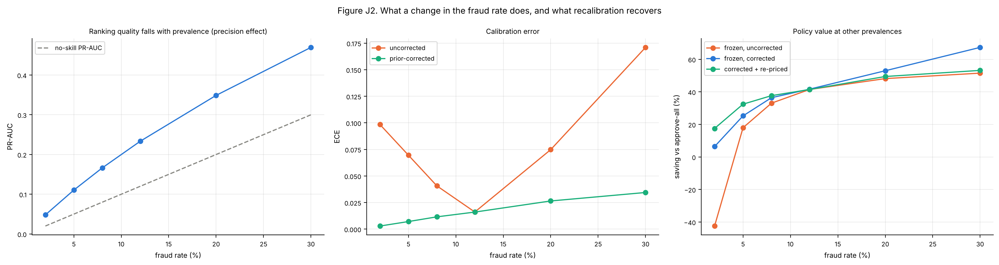

In [147]:
def prior_shift(S, w):
    return np.array([fcal_j.sigmoid(fcal_j.logit(np.clip(p, 1e-4, 1 - 1e-4)) + np.log(RATE / (1 - RATE)) - np.log(YJ.mean() / (1 - YJ.mean()))) for p in S["p"]])
PREV = {}
for rate in (.02, .05, .08, .12, .20, .30):
    RATE = rate; w = st.prevalence_weights(YJ, rate)
    ru, _ = run("Prevalence shift", f"Fraud rate {rate:.0%}: uncorrected", f"class weights to a {rate:.0%} fraud rate; probabilities unchanged", w=w, kind="prevalence")
    rc, _ = run("Prevalence shift", f"Fraud rate {rate:.0%}: prior-corrected", "probabilities shifted to the new base rate", w=w, p_override_fn=prior_shift, boot=False, kind="prevalence")
    PREV[rate] = (ru, rc)
PV = pd.DataFrame([{"fraud_rate": rate, "pr_auc": u["pr_auc"], "mean_pred_uncorrected": u["mean_pred"], "mean_pred_corrected": c["mean_pred"], "observed": u["observed"], "ece_uncorrected": u["ece"], "ece_corrected": c["ece"], "brier_uncorrected": u["brier"], "brier_corrected": c["brier"],
                    "review_share_uncorrected": u["frozen_review_share"], "review_share_corrected": c["frozen_review_share"], "review_precision_uncorrected": u["frozen_review_precision"], "saving_frozen_uncorrected": u["frozen_saving_pct"], "saving_frozen_corrected": c["frozen_saving_pct"],
                    "saving_adaptive_corrected": c["adaptive_saving_pct"], "saving_adaptive_uncorrected": u["adaptive_saving_pct"], "capture_frozen_uncorrected": u["frozen_capture"], "capture_frozen_corrected": c["frozen_capture"]} for rate, (u, c) in PREV.items()]).set_index("fraud_rate"); display(PV.round(3))
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8)); x_ = PV.index * 100
ax[0].plot(x_, PV.pr_auc, "o-", color=BLUE); ax[0].plot(x_, x_ / 100, "--", color=GREY, label="no-skill PR-AUC"); ax[0].set_xlabel("fraud rate (%)"); ax[0].set_ylabel("PR-AUC"); ax[0].legend(fontsize=8); ax[0].set_title("Ranking quality falls with prevalence (precision effect)", fontsize=9)
ax[1].plot(x_, PV.ece_uncorrected, "o-", color=ORANGE, label="uncorrected"); ax[1].plot(x_, PV.ece_corrected, "o-", color=GREEN, label="prior-corrected"); ax[1].set_xlabel("fraud rate (%)"); ax[1].set_ylabel("ECE"); ax[1].legend(fontsize=8); ax[1].set_title("Calibration error", fontsize=9)
for c, col, lab in [("saving_frozen_uncorrected", ORANGE, "frozen, uncorrected"), ("saving_frozen_corrected", BLUE, "frozen, corrected"), ("saving_adaptive_corrected", GREEN, "corrected + re-priced")]: ax[2].plot(x_, PV[c], "o-", color=col, label=lab)
ax[2].set_xlabel("fraud rate (%)"); ax[2].set_ylabel("saving vs approve-all (%)"); ax[2].legend(fontsize=8); ax[2].set_title("Policy value at other prevalences", fontsize=9)
fig.suptitle("Figure J2. What a change in the fraud rate does, and what recalibration recovers", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "J02_prevalence_shift.png", dpi=130, bbox_inches="tight"); plt.show()

### J8. Scorecard: all stresses together, and what the input monitors would have caught
Every scenario with its pass / watch / fail status under the rules fixed at the start, and the population-stability index (PSI, a standard drift monitor: below 0.10 stable, 0.10 to 0.25 watch, above 0.25 alert) of the amount, velocity, channel and the model score. The point of the last columns is to see whether **drift monitors that need no labels** would have warned before performance degraded.

,group,status,pr_auc,pr_auc_change_pct,frozen_review_share,frozen_capture,frozen_saving_pct,saving_change_pts,adaptive_saving_pct,cal_ratio,monitor_psi_max,monitor_alert,why
scenario,,,,,,,,,,,,,
Mix: mean amount +30%,Population shift,Pass,0.234,-0.476,0.115,0.324,43.817,2.190,42.995,1.012,0.003,quiet,
Mix: mean amount +60%,Population shift,Watch,0.233,-1.183,0.124,0.330,44.410,2.783,43.376,1.019,0.007,quiet,review share 12.4%
Mix: velocity (1h) +50%,Population shift,Watch,0.264,11.967,0.103,0.325,41.403,-0.224,41.356,0.892,0.383,alert,block share 13.9%
Mix: E-commerce +15 pts,Population shift,Pass,0.243,3.078,0.097,0.305,41.783,0.156,41.934,0.966,0.091,quiet,
Mix: Mobile App +15 pts,Population shift,Pass,0.243,3.051,0.101,0.314,42.456,0.829,42.563,0.997,0.116,watch,
Mix: ATM +10 pts,Population shift,Pass,0.225,-4.437,0.105,0.311,40.411,-1.216,40.487,1.031,0.085,quiet,
"Mix: amount +30%, velocity +50%, E-commerce +15 pts",Population shift,Watch,0.256,8.883,0.113,0.339,44.384,2.757,45.107,0.877,0.389,alert,block share 14.3%
Real inflation: amounts x1.25,Input perturbation,Watch,0.236,0.314,0.146,0.361,45.527,3.900,43.836,1.038,0.069,quiet,review share 14.6%
Real inflation: amounts x1.5,Input perturbation,Fail,0.234,-0.698,0.191,0.430,50.735,9.108,45.652,1.070,0.221,watch,review share 19.1%; block share 13.9%


Status counts: {'Pass': 28, 'Fail': 10, 'Watch': 9, 'Info': 2}
label-free PSI monitor  alert  quiet  watch
performance status                         
Fail                        1      7      2
Info                        0      2      0
Pass                        5     20      3
Watch                       5      4      0
Scenarios rated Watch or Fail that no label-free PSI monitor would flag: ['Mix: mean amount +60%', 'Real inflation: amounts x1.25', 'Evasion: 30% of frauds hide red flags', 'Evasion: 60% of frauds hide red flags', 'Amount missing 20%', 'Authentication level missing 40%', 'Evaluation without the top 1% of amounts', 'Evaluation without the top 5% of amounts', 'Fraud rate 2%: uncorrected', 'Fraud rate 5%: uncorrected', 'Fraud rate 8%: uncorrected', 'Fraud rate 20%: uncorrected', 'Fraud rate 30%: uncorrected']


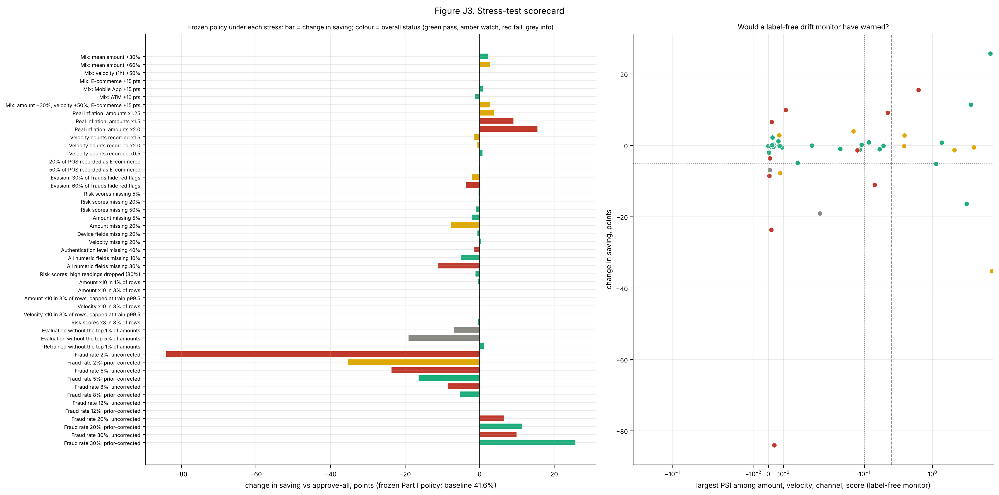

In [148]:
RES = pd.DataFrame(RESULTS); RES = RES[RES.scenario != "Unstressed"].copy()
RES["pr_auc_change_pct"] = 100 * (RES.pr_auc / BASE["pr_auc"] - 1); RES["saving_change_pts"] = RES.frozen_saving_pct - BASE["frozen_saving_pct"]; RES["cal_ratio"] = RES.mean_pred / RES.observed
RES["monitor_psi_max"] = RES[["psi_amount", "psi_velocity", "psi_channel", "psi_score"]].max(axis=1); RES["monitor_alert"] = np.select([RES.monitor_psi_max >= .25, RES.monitor_psi_max >= .10], ["alert", "watch"], "quiet")
SC_COLS = ["group", "scenario", "status", "pr_auc", "pr_auc_change_pct", "frozen_review_share", "frozen_capture", "frozen_saving_pct", "saving_change_pts", "adaptive_saving_pct", "cal_ratio", "monitor_psi_max", "monitor_alert", "why"]
pd.set_option("display.width", 250); display(RES[SC_COLS].set_index("scenario").round(3))
print("Status counts:", RES.status.value_counts().to_dict()); print(pd.crosstab(RES.status, RES.monitor_alert).rename_axis(index="performance status", columns="label-free PSI monitor"))
print("Scenarios rated Watch or Fail that no label-free PSI monitor would flag:", RES[(RES.status != "Pass") & (RES.monitor_alert == "quiet")].scenario.tolist())
fig, ax = plt.subplots(1, 2, figsize=(18, 9), gridspec_kw=dict(width_ratios=[1.25, 1]))
d = RES.reset_index(drop=True); yy = np.arange(len(d))[::-1]; colr = d.status.map({"Pass": GREEN, "Watch": "#e0a800", "Fail": "#c0392b", "Info": GREY})
ax[0].barh(yy, d.saving_change_pts, color=colr, height=.7); ax[0].axvline(0, color=INK, lw=.8); ax[0].set_yticks(yy); ax[0].set_yticklabels(d.scenario, fontsize=6.5); ax[0].set_xlabel("change in saving vs approve-all, points (frozen Part I policy; baseline " + f"{BASE['frozen_saving_pct']:.1f}%)")
ax[0].set_title("Frozen policy under each stress: bar = change in saving; colour = overall status (green pass, amber watch, red fail, grey info)", fontsize=8)
ax[1].scatter(d.monitor_psi_max, d.saving_change_pts, c=colr, s=45, edgecolor="white"); ax[1].axvline(.1, color=GREY, ls=":", lw=1); ax[1].axvline(.25, color=GREY, ls="--", lw=1); ax[1].axhline(-5, color=GREY, ls=":", lw=1); ax[1].set_xscale("symlog", linthresh=.05)
ax[1].set_xlabel("largest PSI among amount, velocity, channel, score (label-free monitor)"); ax[1].set_ylabel("change in saving, points"); ax[1].set_title("Would a label-free drift monitor have warned?", fontsize=9)
fig.suptitle("Figure J3. Stress-test scorecard", fontsize=11); plt.tight_layout(); plt.savefig(FIG / "J03_scorecard.png", dpi=130, bbox_inches="tight"); plt.show()

### J9. What could degrade the model after deployment, and how it would be noticed
The causes below are grouped by what changes. The evidence column points to the test in this notebook that measures it. The monitoring plan turns the stress results into alerts and actions.

In [149]:
CAUSES = pd.DataFrame([
 ("Covariate drift", "Amounts, velocity or channel mix move (seasonality, promotions, new merchants)", "J3: re-weighting tests", "Score and decision-mix drift; review share above its limit"),
 ("Prior (prevalence) shift", "Fraud rate changes (attack wave, or a quiet period)", "J7", "Probabilities become over- or under-confident; review precision and saving change; fixed by recalibration plus re-pricing, needs a current fraud-rate estimate"),
 ("Concept drift / adversarial adaptation", "Fraudsters learn which signals are checked and hide them", "J4 evasion", "Recall falls while input drift is small; only outcome monitoring sees it"),
 ("Data-pipeline faults", "Unit changes, counting changes, mislabelled channel, failed feeds, missing values, outliers", "J4 to J6", "Field-level PSI, missing-rate and range checks before scoring"),
 ("Feedback loops", "Blocked and reviewed transactions are not observed as fraud outcomes, and past decisions shape the labels", "Part H (labels from past decisions)", "Hold back a small random sample of approvals for review to keep unbiased labels"),
 ("Label delay", "Chargebacks arrive weeks later, so performance is seen late", "Discussion", "Use label-free monitors and analyst-review outcomes as early proxies"),
 ("Calibration drift", "Platt layer fitted on old data", "J2 segments, J7", "Monthly reliability check; refit the Platt layer; the scale factor is a cheap fix"),
 ("Operational constraints", "Review team smaller or larger than assumed, new cost levels", "Part I capacity stress", "Re-price shadow prices; re-run cost scenarios"),
 ("Small-sample optimism", "291 frauds only, rule chosen on the same rows", "J2 noise, Part I caveats", "Final hold-out check and a staged roll-out with shadow mode")], columns=["cause", "example", "tested in", "how it shows up and what to do"]).set_index("cause")
pd.set_option("display.max_colwidth", 200); display(CAUSES)
MON = pd.DataFrame([("Input drift", "PSI of amount, 1h velocity, channel, merchant and IP risk score vs the development data", "daily", "0.10 watch, 0.25 alert", "Investigate the feed or business change; re-run J3-style re-weighting to estimate the effect"),
 ("Score drift", "PSI of the calibrated probability; share of scores above the review and block cut-offs", "daily", "PSI 0.10 / 0.25; review share outside 8% to 12%", "Re-price shadow prices (label-free); check capacity"),
 ("Data quality", "Missing rate per field; values outside the training 0.1 to 99.9 percentile; unseen categories", "every batch", "missing rate above 2x its development level; out-of-range above 0.5%", "Block the feed or impute; log the share of imputed scores"),
 ("Calibration", "Mean predicted vs observed fraud rate, by channel and amount band, on matured labels", "monthly", "ratio outside 0.8 to 1.25", "Refit Platt layer; prior-shift correction if the fraud rate moved"),
 ("Ranking quality", "PR-AUC and recall in the top 10% on matured labels, with a bootstrap interval", "monthly (labels mature in weeks)", "PR-AUC down more than 10% relative, beyond the fold noise (SD 0.053)", "Investigate; retrain if confirmed in two consecutive months"),
 ("Policy value", "Realised cost, review precision, genuine customers blocked, reviewed-fraud detection rate", "weekly", "saving vs approve-all down 5 points; review precision below the Part I level", "Re-price; review cost assumptions"),
 ("Evasion", "Share of confirmed frauds that had zero red flags; fraud rate in a random sample of approvals", "monthly", "share of red-flag-free frauds up by 10 points", "Add or retire signals; retrain"),
 ("Retraining", "Scheduled retrain on the latest matured data with the full Part D to F procedure", "quarterly or on trigger", "two consecutive ranking alerts, or a confirmed concept change", "Champion/challenger comparison on a fresh hold-out before promotion")], columns=["monitor", "statistic", "frequency", "alert rule", "action"]).set_index("monitor"); display(MON)

,example,tested in,how it shows up and what to do
cause,,,
Covariate drift,"Amounts, velocity or channel mix move (seasonality, promotions, new merchants)",J3: re-weighting tests,Score and decision-mix drift; review share above its limit
Prior (prevalence) shift,"Fraud rate changes (attack wave, or a quiet period)",J7,"Probabilities become over- or under-confident; review precision and saving change; fixed by recalibration plus re-pricing, needs a current fraud-rate estimate"
Concept drift / adversarial adaptation,Fraudsters learn which signals are checked and hide them,J4 evasion,Recall falls while input drift is small; only outcome monitoring sees it
Data-pipeline faults,"Unit changes, counting changes, mislabelled channel, failed feeds, missing values, outliers",J4 to J6,"Field-level PSI, missing-rate and range checks before scoring"
Feedback loops,"Blocked and reviewed transactions are not observed as fraud outcomes, and past decisions shape the labels",Part H (labels from past decisions),Hold back a small random sample of approvals for review to keep unbiased labels
Label delay,"Chargebacks arrive weeks later, so performance is seen late",Discussion,Use label-free monitors and analyst-review outcomes as early proxies
Calibration drift,Platt layer fitted on old data,"J2 segments, J7",Monthly reliability check; refit the Platt layer; the scale factor is a cheap fix
Operational constraints,"Review team smaller or larger than assumed, new cost levels",Part I capacity stress,Re-price shadow prices; re-run cost scenarios
Small-sample optimism,"291 frauds only, rule chosen on the same rows","J2 noise, Part I caveats",Final hold-out check and a staged roll-out with shadow mode


,statistic,frequency,alert rule,action
monitor,,,,
Input drift,"PSI of amount, 1h velocity, channel, merchant and IP risk score vs the development data",daily,"0.10 watch, 0.25 alert",Investigate the feed or business change; re-run J3-style re-weighting to estimate the effect
Score drift,PSI of the calibrated probability; share of scores above the review and block cut-offs,daily,PSI 0.10 / 0.25; review share outside 8% to 12%,Re-price shadow prices (label-free); check capacity
Data quality,Missing rate per field; values outside the training 0.1 to 99.9 percentile; unseen categories,every batch,missing rate above 2x its development level; out-of-range above 0.5%,Block the feed or impute; log the share of imputed scores
Calibration,"Mean predicted vs observed fraud rate, by channel and amount band, on matured labels",monthly,ratio outside 0.8 to 1.25,Refit Platt layer; prior-shift correction if the fraud rate moved
Ranking quality,"PR-AUC and recall in the top 10% on matured labels, with a bootstrap interval",monthly (labels mature in weeks),"PR-AUC down more than 10% relative, beyond the fold noise (SD 0.053)",Investigate; retrain if confirmed in two consecutive months
Policy value,"Realised cost, review precision, genuine customers blocked, reviewed-fraud detection rate",weekly,saving vs approve-all down 5 points; review precision below the Part I level,Re-price; review cost assumptions
Evasion,Share of confirmed frauds that had zero red flags; fraud rate in a random sample of approvals,monthly,share of red-flag-free frauds up by 10 points,Add or retire signals; retrain
Retraining,Scheduled retrain on the latest matured data with the full Part D to F procedure,quarterly or on trigger,"two consecutive ranking alerts, or a confirmed concept change",Champion/challenger comparison on a fresh hold-out before promotion


### J10. Findings

**Scope.** 49 stress scenarios on out-of-fold predictions of the refitted production pipeline (Random Forest, Platt layer, Part I decision rule at 10% review and 10% block limits, base cost scenario S1). Stresses touch test rows only. Hold-out untouched. Under the rules fixed at the start: **28 Pass, 9 Watch, 10 Fail, 2 Info** (the two Info rows evaluate subsets, not model changes).

**Fold variability (J2).** Across the ten test folds (about 58 frauds each): PR-AUC mean 0.259, SD 0.053, range 0.203 to 0.380 (corrected 95% interval of the mean 0.19 to 0.33); ROC-AUC 0.665, SD 0.037; recall in the top 10% 0.237, SD 0.044; Brier score 0.1019, SD 0.0016; saving against approving everything 40.8%, SD 9.1 points, range 28.5% to 55.0%; review share 9.0% to 12.3% and block share 8.5% to 12.5% fold by fold. The sampling noise inside one 480-row fold (0.050) is almost the whole observed spread (0.053), so the fold-to-fold variation is mostly the luck of which 58 frauds land in a fold; a different random partition moves the mean by only 0.003. All ten folds beat the no-skill PR-AUC (0.121) and all ten policy runs beat approving everything. The pooled out-of-fold PR-AUC is lower (0.235, interval 0.20 to 0.28) than the fold average because folds with different score scales are mixed. **Practical consequence: any change in PR-AUC smaller than about 0.05 (20%) on a month of data is within noise.** Calibration by segment: 3 of 33 segment intervals exclude parity (POS over-predicted 1.26 times, Fuel 1.47, Jewelry under-predicted 0.61); the high-fraud segments are under-predicted and the low-fraud ones over-predicted (amounts 300+ 0.75, missing authentication 0.79, Fashion 0.78, Gaming 0.76), a mild shrinkage toward the average typical of a shallow forest. About 1.7 exclusions would be expected by chance, so this is weak evidence.

**Population shifts (J3).** The ranking is robust: with 30% to 60% higher amounts, 50% more velocity, or a channel mix moved by 10 to 15 points, PR-AUC stays between 0.225 and 0.264 (higher only where the fraud rate itself rises). What moves is the **operating load**, because the frozen thresholds are fixed: amounts +60% push the review share to 12.4% (limit 10%); 50% more velocity raises the fraud rate to 15.1% and the block share to 13.9%; the combined shift gives block 14.3%. Channel mix shifts alone are harmless (all Pass).

**Input perturbations (J4).**
* **Real inflation** of amounts (x1.25, x1.5, x2) leaves ranking unchanged (PR-AUC 0.236, 0.234, 0.227) but the frozen rule sends 14.6%, 19.1% and 28.2% of transactions to review (block 11.9%, 13.9%, 16.4%): the queue would swamp the team. The saving against approve-all rises (45.5%, 50.7%, 57.1%) only because the frozen rule ignores the capacity limit; re-pricing the shadow prices (label-free) keeps the limits and still saves 43.8%, 45.7% and 50.0%.
* **Counting changes** in velocity (x1.5, x2) leave ranking unchanged (0.235, 0.240) but raise the block share to 12.5% and 13.9%; halving counts cuts fraud capture from 31% to 28%.
* **Channel mislabelling** (20% or 50% of POS recorded as E-commerce) has no effect (PR-AUC 0.234 and 0.235): the model barely uses the channel.
* **Evasion** is the most damaging ranking stress: if 30% of frauds hide their red flags PR-AUC falls 15% (0.199, interval 0.170 to 0.241), at 60% it falls 26% (0.173, interval 0.152 to 0.204), recall in the top 10% drops from 0.234 to 0.198 and 0.165, and the money saved falls by 2.0 and 3.7 points. The score distribution does not move (PSI 0.000 to 0.001) and neither do the inputs, so **no label-free drift monitor would see it**.

**Missing values (J5).** Mild damage in most cases: risk scores missing at random at 5%, 20%, 50% lower PR-AUC by 0.1%, 1.3% and 4.4%; velocity or device fields missing at 20% by 0.4% and 7.0%. Costlier cases: **amount missing for 20%** keeps ranking but loses 7.8 points of saving (the policy uses the median amount and misses large frauds; Watch); **authentication level missing for 40%** pushes the block share to 15.9% because "missing" carries a 21% fraud rate in training (Fail); **all numeric fields missing for 30%** cuts PR-AUC 10.6%, capture to 20% and saving by 11.1 points (Fail), while 10% is tolerable (PR-AUC -3.0%, saving -5.0 points). Dropping only the high risk readings (80%) lowers PR-AUC 6.2% and makes the model under-predict (calibration ratio 0.85).

**Extreme observations (J6).** Outliers hardly matter: amounts x10 in 1% or 3% of rows lower PR-AUC by 0.9% and 1.0% (review share 10.7% and 11.8%); velocity x10 by 1.1%; risk scores x3 by 2.7%. Capping inputs at the training 99.5th percentile gave no gain (a tree only compares to thresholds, so an extreme value just lands in the top bin). A model **retrained without the top 1% of amounts** performs the same (PR-AUC 0.236 against 0.235). The ranking therefore does not depend on extremes; the **money does**: the top 1% of amounts (24 rows) hold 12% of all amount, and evaluating without the top 1% or top 5% of amounts (above 353) lowers the saving from 41.6% to 34.7% and 22.5%. Value is concentrated in large transactions.

**Prevalence shift (J7).** PR-AUC tracks the fraud rate (0.048 at 2%, 0.110 at 5%, 0.166 at 8%, 0.349 at 20%, 0.470 at 30%; no-skill equals the rate itself). The uncorrected probabilities mis-state risk by a factor of 5.9 at 2% (observed against predicted 0.63 at 20% and 0.43 at 30%) and the frozen policy would **lose money at a 2% fraud rate (saving -42%, worse than approving everything)** and save only 18% at 5%. A one-line prior-shift correction restores calibration (ECE 0.098 to 0.003 at 2%) and moves the saving to 6.4% at 2%, 25.2% at 5% and 36.4% at 8%; adding re-priced shadow prices gives 17.5%, 32.4% and 37.7%. At 20% to 30% the corrected frozen rule would block up to 70% of transactions, ignoring the limit, so re-pricing is needed in that direction as well (53% saving at 30% with limits respected). This is the largest risk for a real portfolio, where fraud rates are far lower than 12%.

**What the monitors would catch.** Of the 19 Watch or Fail scenarios (excluding Info) 11 would not trigger any label-free PSI alert on amount, velocity, channel or score: evasion, uncorrected prevalence shifts, missing authentication, missing amounts and the mildest amount shifts. Label-free monitors detect data and load drift well (velocity, amounts, counting changes) but not changes in fraud behaviour or fraud rate, which need matured labels or a random sample of approvals.

**Causes of degradation to plan for (J9):** covariate drift in amounts, velocity and channel mix; prevalence shift; adversarial adaptation by fraudsters; pipeline faults (units, counting, mislabelled fields, missing feeds); feedback loops and selective labels; delayed chargebacks; calibration drift; changed operational limits; and small-sample optimism (only 291 frauds). The monitoring plan in J9 ties each to a statistic, a frequency, an alert rule and an action.

**Recommendations.** (1) Monitor the review and block shares daily and re-price the shadow prices label-free when they leave 8% to 12%. (2) Track the fraud rate monthly (matured labels plus a small random sample of approvals) and apply the prior-shift correction. (3) Add data-quality gates for missing amounts, missing authentication and velocity counts. (4) Watch for evasion with the share of confirmed frauds that had zero red flags. (5) Re-run the cost framework at a realistic fraud rate before go-live, because at low prevalence the value of the policy falls sharply. (6) Run the engine in shadow mode against the hold-out set and a fresh month of data before switching it on.

**Limits.** Population shifts assume the link between inputs and fraud is unchanged (covariate shift); perturbations are simulated, not observed; the effective sample is smaller under strong re-weighting (ESS 1,230 to 2,330 of 2,400); there are no timestamps in the data, so true temporal drift cannot be tested; the Pass, Watch and Fail limits are judgement; the hold-out set is still reserved for the final check.


In [150]:
RES.drop(columns=[c for c in RES.columns if c.startswith("adaptive_cost") or c.endswith("_cost")], errors="ignore").to_csv(OUT / "J_stress_scorecard.csv", index=False)
FT.to_csv(OUT / "J_fold_variability.csv", index=False); summ.to_csv(OUT / "J_fold_summary.csv"); SEG.to_csv(OUT / "J_segment_calibration.csv", index=False); PV.to_csv(OUT / "J_prevalence_shift.csv"); CAUSES.to_csv(OUT / "J_degradation_causes.csv"); MON.to_csv(OUT / "J_monitoring_plan.csv")
pd.DataFrame({k: v for k, v in WS.items()}).describe().T.assign(ess=[st.ess(v) for v in WS.values()]).to_csv(OUT / "J_shift_weights_summary.csv")
print("Part J tables saved; figures:", sorted(p.name for p in FIG.glob("J0*.png")), "| hold-out rows read: none")

Part J tables saved; figures: ['J01_fold_variability.png', 'J02_prevalence_shift.png', 'J03_scorecard.png'] | hold-out rows read: none


---
## Part K. Model Governance

**Goal:** make the decision engine governable: a model card, production monitoring, drift monitoring, and written rules for when to retrain, review or switch the model off. The same part answers the eight management questions of the task, each with the evidence it rests on.

| Task K requirement | Section |
|---|---|
| Model card (intended use, limitations, data assumptions, evaluation method, known risks) | K2 here; full document in `06_model_card.pdf` |
| At least five production monitoring metrics | K3, K4 (ten metrics) |
| Drift monitoring for important features and model outputs | K5 |
| When to retrain, review or temporarily disable | K6 |
| The eight questions | Q1 to Q8 |

**Rules for this part**
1. **Nothing is refitted and the hold-out set is not read.** All evidence comes from the saved out-of-fold predictions and the tables of Parts B to J. The Part K code is in `fraud_governance.py`.
2. **The cost framework is re-implemented** so that new cost structures can be tried (Q6, Q7). K1 proves it reproduces Part E before it is used.
3. **Every monitoring threshold is tied to something measured**: the Pass / Watch / Fail rules and stress results of Part J, the Part F calibration results, or the sampling-noise levels computed in K3. Judgement thresholds are labelled as such.
4. **The cost-structure ranges and the seed (42) used in Q7 were fixed in the code before it was run.**
5. **Wording.** `authentication_level` contains the literal value `None` for 289 of 3,000 rows. The pipeline reads it as a missing value and keeps it as its own level, so the models are unaffected, but in every governance document it is called **"authentication = None (not performed)"**, not "missing".


In [1]:
import sys, json, glob, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr
sys.path.insert(0, ".")
import fraud_governance as fg                      # independent re-implementation of the Part E cost framework + Part K evidence functions
try: OUT
except NameError: OUT = Path("outputs")
try: FIG
except NameError: FIG = Path("figures")
OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
SRC = [str(OUT), ".", "/mnt/user-data/uploads"]; find = lambda n: fg.find(n, *SRC)
INK, BLUE, ORANGE, GREY, GREEN = "#1b2a41", "#2a78d6", "#e8863a", "#8a94a6", "#1baf7a"
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
oof, raw, AMT, Y, S = fg.load_dev(find("D_oof_predictions.csv"), globals().get("DATA_PATH", None) or find("transaction_fraud_risk_advanced_dataset.csv"))
N = len(Y); MODELS = fg.MODELS; SEED_K = 42
aud = pd.read_csv(find("02a_audited_dataset.csv")); dev = aud[aud.split == "development"].reset_index(drop=True)
assert N == 2400 and Y.sum() == 291 and len(dev) == 2400
print(f"development rows {N} | frauds {int(Y.sum())} ({Y.mean():.1%}) | hold-out rows read: none | seed {SEED_K}")

development rows 2400 | frauds 291 (12.1%) | hold-out rows read: none | seed 42


### K1. The cost framework used here reproduces Part E
Part E's helper module is not needed for Part K: the cost matrix is rebuilt from the documented parameters, thresholds are chosen on training rows only and scored on unseen rows, exactly as in E2. The test is whether the numbers agree.

In [2]:
# K1. The cost framework is re-implemented (fraud_governance.py) so Part K can run new cost structures. First prove it reproduces Part E.
PART_E = {  # honest three-way cost per 1,000 transactions printed in Part E3 (models in the order LR_baseline, LR_tuned, RF, HGB)
 "S1_base": [16669, 16794, 14264, 15577], "S2_fraud_averse": [17877, 18021, 15427, 16637], "S3_customer_first": [18213, 17637, 16766, 17404],
 "S4_review_expensive": [17602, 17843, 15151, 16488], "S5_review_cheap_big_team": [14812, 15250, 12337, 12843], "S6_partial_recovery": [11229, 10929, 10047, 10812], "S7_no_operational_limits": [11378, 11489, 10467, 10894]}
ROW, rows = {}, []
for sn, sc in fg.SCENARIOS.items():
    costs = fg.row_costs(AMT, Y, sc)
    for i, m in enumerate(MODELS):
        ROW[(sn, m)] = fg.honest_row_costs(S[m], Y, costs, sc)
        rows.append(dict(scenario=sn, model=m, rebuilt_cost=ROW[(sn, m)].mean() * 1000, part_E_cost=PART_E[sn][i]))
V = pd.DataFrame(rows); V["diff_pct"] = 100 * (V.rebuilt_cost / V.part_E_cost - 1)
print("Rebuilt honest cost per 1,000 (thresholds chosen on training rows, applied to unseen rows):"); display(V.pivot(index="scenario", columns="model", values="rebuilt_cost").reindex(list(fg.SCENARIOS))[MODELS].round(0))
print(f"Difference to Part E: mean absolute {V.diff_pct.abs().mean():.2f}%, maximum {V.diff_pct.abs().max():.2f}% (different CV fold seeds and a slightly different threshold grid)")
rk_ok = all(V[V.scenario == s].sort_values("rebuilt_cost").model.iloc[0] == "RF" for s in fg.SCENARIOS)
print("RF is the cheapest model in every scenario in the rebuilt numbers as well:", rk_ok)
c = fg.row_costs(AMT, Y, fg.SCENARIOS["S1_base"]); g = fg.make_grid(S["RF"]); t1, t2, cc = fg.best_pair(fg.surface(S["RF"], c, g), g, "three_way", .1, .1)
print(f"In-sample RF optimum, base scenario: thresholds {t1:.3f} / {t2:.3f}, cost {cc / N * 1000:,.0f} per 1,000 (Part E: 0.156 / 0.208, 14,183; the finer grid here finds a cost about 0.3% lower)")
V.to_csv(OUT / "K_validation_vs_partE.csv", index=False)

Rebuilt honest cost per 1,000 (thresholds chosen on training rows, applied to unseen rows):


model,LR_baseline,LR_tuned,RF,HGB
scenario,,,,
S1_base,16700.0,16853.0,14354.0,15739.0
S2_fraud_averse,17896.0,18132.0,15566.0,16951.0
S3_customer_first,18266.0,17619.0,16789.0,17512.0
S4_review_expensive,17599.0,17856.0,15230.0,16666.0
S5_review_cheap_big_team,14907.0,15272.0,12361.0,12826.0
S6_partial_recovery,11222.0,10934.0,10087.0,10790.0
S7_no_operational_limits,11343.0,11524.0,10468.0,10908.0


Difference to Part E: mean absolute 0.40%, maximum 1.89% (different CV fold seeds and a slightly different threshold grid)
RF is the cheapest model in every scenario in the rebuilt numbers as well: True


In-sample RF optimum, base scenario: thresholds 0.157 / 0.208, cost 14,140 per 1,000 (Part E: 0.156 / 0.208, 14,183; the finer grid here finds a cost about 0.3% lower)


### K2. Model card facts
The values below are read from the saved artefacts so that the model card cannot drift from the notebook. The card itself (intended use, out-of-scope use, data assumptions, evaluation method, performance, limitations, known risks, monitoring and sign-off) is `06_model_card.pdf`.

In [3]:
# K2. Facts that go into the model card, read from the saved artefacts (no model is refitted)
fm = json.load(open(find("D_final_models.json"))); cal = json.load(open(find("F_calibration_choice.json"))); pol = json.load(open(find("E_chosen_policy.json")))
lb = pd.read_csv(find("D_leaderboard.csv"), index_col=0); rawcal = pd.read_csv(find("F_raw_calibration_metrics.csv"), index_col=0)
rf = fm["models"]["RF"]["best_params"]
FACTS = pd.DataFrame([
 ("Model", "Random Forest, 300 trees (gini), no class weights, no resampling", "D_final_models.json"),
 ("Hyper-parameters", f"max_depth {rf['model__max_depth']}, min_samples_leaf {rf['model__min_samples_leaf']}, max_features {rf['model__max_features']}, max_samples {rf['model__max_samples']}", "D_final_models.json"),
 ("Feature set", f"'{rf['select__feature_set']}' = base fields + velocity, risk, time and interaction groups; 74 encoded inputs", "D_final_models.json, C_recommended_feature_set.json"),
 ("Seed", f"{fm['seed']} (split, CV, forest, bootstraps)", "D_final_models.json"),
 ("Ranking quality, nested CV (5x2)", f"PR-AUC {lb.loc['RF','pr_auc_mean']:.3f} (SD {lb.loc['RF','pr_auc_std']:.3f}) against no-skill {lb.loc['Dummy','pr_auc_mean']:.3f}; ROC-AUC {lb.loc['RF','roc_auc_mean']:.3f}; recall in top 10% {lb.loc['RF','recall_at_10pct_mean']:.3f}", "D_leaderboard.csv"),
 ("Probability quality, out-of-fold", f"Brier {lb.loc['RF','brier_mean']:.4f} (no-skill {lb.loc['Dummy','brier_mean']:.4f}); log loss {lb.loc['RF','log_loss_mean']:.4f}; ECE {rawcal.loc['RF','ECE']:.3f}; calibration slope {rawcal.loc['RF','cal_slope']}", "D_leaderboard.csv, F_raw_calibration_metrics.csv"),
 ("Calibration layer", f"Platt scaling, intercept {cal['platt']['intercept']:.3f}, slope {cal['platt']['slope']:.3f}, fitted on 4,800 out-of-fold pairs", "F_calibration_choice.json"),
 ("Fixed thresholds (fallback)", f"review from {cal['thresholds_calibrated']['t_review']:.3f}, block from {cal['thresholds_calibrated']['t_block']:.3f} (calibrated); raw {pol['t_review']:.3f} / {pol['t_block']:.3f}", "F_calibration_choice.json, E_chosen_policy.json"),
 ("Cost base case (hypothetical)", ", ".join(f"{k} {v}" for k, v in pol["base_scenario"].items() if k != "name"), "E_chosen_policy.json"),
 ("Fraud prevalence in development data", f"{Y.mean():.1%} ({int(Y.sum())} of {N}); whole file 364 of 3,000", "A, Part G"),
 ("Hold-out set", "600 rows, 73 frauds, never read by any part, including K", "split_assignment.csv")], columns=["item", "value", "source"])
display(FACTS); FACTS.to_csv(OUT / "K_model_card_facts.csv", index=False)
fr_zero = float(((dev.fraud == 1) & ((dev.new_device + dev.billing_address_mismatch + (dev.prior_chargebacks >= 1) + dev.authentication_level.isna() + (dev.failed_logins_24h >= 2)) == 0)).sum() / dev.fraud.sum())
print(f"Reference for the evasion monitor: {fr_zero:.1%} of development frauds carry none of the five red flags.")

,item,value,source
0,Model,"Random Forest, 300 trees (gini), no class weights, no resampling",D_final_models.json
1,Hyper-parameters,"max_depth 3, min_samples_leaf 19, max_features 0.6, max_samples 0.6",D_final_models.json
2,Feature set,"'recommended' = base fields + velocity, risk, time and interaction groups; 74 encoded ...","D_final_models.json, C_recommended_feature_set.json"
3,Seed,"42 (split, CV, forest, bootstraps)",D_final_models.json
4,"Ranking quality, nested CV (5x2)",PR-AUC 0.249 (SD 0.049) against no-skill 0.121; ROC-AUC 0.665; recall in top 10% 0.246,D_leaderboard.csv
5,"Probability quality, out-of-fold",Brier 0.1020 (no-skill 0.1065); log loss 0.3508; ECE 0.016; calibration slope 1.05 [0....,"D_leaderboard.csv, F_raw_calibration_metrics.csv"
6,Calibration layer,"Platt scaling, intercept 0.068, slope 1.031, fitted on 4,800 out-of-fold pairs",F_calibration_choice.json
7,Fixed thresholds (fallback),"review from 0.158, block from 0.212 (calibrated); raw 0.156 / 0.208","F_calibration_choice.json, E_chosen_policy.json"
8,Cost base case (hypothetical),"loss_share 1.0, chargeback_fee 15.0, fp_margin 0.05, fp_friction 20.0, review_cost 6.0...",E_chosen_policy.json
9,Fraud prevalence in development data,"12.1% (291 of 2400); whole file 364 of 3,000","A, Part G"


Reference for the evasion monitor: 40.9% of development frauds carry none of the five red flags.


### K3. How large is "normal"? Noise levels for the monitors
A monitor is only useful if its alarm level is above ordinary sampling noise and below the level that hurts. Two measurements:
* **PSI noise.** When live traffic has exactly the reference distribution, the population stability index is still not zero. At a daily volume of 4,545 transactions the 99th percentile is about 0.005; at monthly volume it is 0.0002. The textbook bands (0.10 watch, 0.25 alert) are therefore 20 to 50 times above daily noise, and Part J8 showed that several damaging stresses sat well below them.
* **Ranking-quality noise.** PR-AUC measured on a window with 100 matured frauds has a standard deviation of about 0.033, so only a drop of roughly one third could be seen; 25% needs about 175 frauds and 10% about 1,100. This is why the ranking monitor uses a trailing window sized by the number of **matured frauds**, not by calendar time.

Caveat: pure sampling noise is a floor. Real days differ by weekday and season, so every PSI threshold must be re-calibrated on four to eight weeks of live data in shadow mode (K6, step 6 of the roll-out) before it is allowed to page anyone.

In [4]:
# K3. How big is "normal"? Calibrate monitoring thresholds against sampling noise before trusting them.
fields = {"transaction_amount": dev.transaction_amount.dropna().to_numpy(), "transactions_last_1h": dev.transactions_last_1h.to_numpy(), "merchant_risk_score": dev.merchant_risk_score.dropna().to_numpy(),
          "ip_risk_score": dev.ip_risk_score.dropna().to_numpy(), "model score (RF, out-of-fold)": np.mean(S["RF"], axis=0)}
PSI0 = fg.psi_null(fields, seed=SEED_K); print("PSI expected from sampling noise alone (live population identical to the reference), 10 reference-quantile bins:")
display(PSI0.pivot(index="field", columns="window", values="psi_null_p99").round(4).rename(columns=lambda c: f"p99, {c}")[["p99, day", "p99, week", "p99, month"]])
PW = fg.prauc_window_noise(np.mean(S["RF"], axis=0), Y, seed=SEED_K)
rel = float((PW.min_detectable_relative_drop * np.sqrt(PW.frauds_in_window)).mean())      # minimum detectable relative drop is about rel / sqrt(F)
print("PR-AUC of the Random Forest in a monitoring window with F matured frauds (bootstrap of out-of-fold rows):"); display(PW[["frauds_in_window", "rows_at_dev_rate", "pr_auc_sd", "min_detectable_relative_drop"]].round(3))
print(f"Extrapolating with 1/sqrt(F): a 25% relative PR-AUC drop is detectable (80% power) from about {(rel / .25) ** 2:,.0f} matured frauds in the window, a 10% drop from about {(rel / .10) ** 2:,.0f}.")
print("Calibration ratio (mean predicted / observed): standard error is about 1/sqrt(F), so telling 1.25 from 1.00 needs about", int(np.ceil((1.645 / 0.25) ** 2 + 0.5)), "frauds in the segment; the monthly review should therefore be overall plus a few large segments, not many small ones.")
PW.to_csv(OUT / "K_prauc_window_noise.csv", index=False); PSI0.to_csv(OUT / "K_psi_null_by_window.csv", index=False)

PSI expected from sampling noise alone (live population identical to the reference), 10 reference-quantile bins:


window,"p99, day","p99, week","p99, month"
field,,,
ip_risk_score,0.0044,0.0008,0.0002
merchant_risk_score,0.0048,0.0010,0.0002
"model score (RF, out-of-fold)",0.0046,0.0009,0.0002
transaction_amount,0.0052,0.0009,0.0002
transactions_last_1h,0.0029,0.0007,0.0001


PR-AUC of the Random Forest in a monitoring window with F matured frauds (bootstrap of out-of-fold rows):


,frauds_in_window,rows_at_dev_rate,pr_auc_sd,min_detectable_relative_drop
0,30,247,0.063,0.601
1,60,495,0.044,0.450
2,100,825,0.033,0.333
3,200,1649,0.022,0.222
4,400,3299,0.016,0.165


Extrapolating with 1/sqrt(F): a 25% relative PR-AUC drop is detectable (80% power) from about 175 matured frauds in the window, a 10% drop from about 1,095.
Calibration ratio (mean predicted / observed): standard error is about 1/sqrt(F), so telling 1.25 from 1.00 needs about 44 frauds in the segment; the monthly review should therefore be overall plus a few large segments, not many small ones.


### K4. Production monitoring metrics
Ten metrics: four need no labels (M1, M2, M6, M9) and can run daily; the others need matured labels, the analyst outcomes, or a small random sample of approved transactions held back for review (the only way to see fraud that the model approved). Thresholds are in the table; the last column says where each comes from.

In [5]:
# K4. Production monitoring metrics (10). Every threshold is anchored to a measured quantity from Parts F, I and J or to the noise levels in K3.
MON = pd.DataFrame([
 ("M1", "Review share of traffic", "share of scored transactions sent to Review", "daily", "no", "8% to 12%", "12% to 15%: re-price shadow prices (label-free)", "above 15% for 2 days after re-pricing", "J3/J4: amounts +60% gave 12.4%, x1.5 gave 19.1%, x2 gave 28.2% (limit 10%)"),
 ("M2", "Block share of traffic", "share of scored transactions blocked", "daily", "no", "8% to 12%", "12% to 15%: re-price, check feeds", "above 15% for 2 days after re-pricing", "J4: velocity x2 gave 13.9%; authentication None at 40% gave 15.9% (Fail)"),
 ("M3", "Calibration ratio", "mean calibrated probability / observed fraud rate, overall and by channel and amount band", "monthly (matured labels)", "yes", "0.80 to 1.25", "outside 0.80 to 1.25: refit Platt, apply prior-shift correction", "outside 0.67 to 1.50 after recalibration", "J7: at 8% fraud the ratio is 1.51 (Fail), at 20% it is 0.63"),
 ("M4", "Ranking quality", "PR-AUC and recall in the top 10% with bootstrap interval, trailing window with enough matured frauds (K3)", "monthly", "yes", "within 10% of the 0.24 to 0.26 reference", "down more than 10% relative, beyond noise", "down more than 25% relative, or two consecutive amber months", "J2: fold SD 0.053; J4 evasion: -15% Watch, -26% Fail"),
 ("M5", "Policy value", "realised cost against approve-all on the same traffic (uses the random approval sample)", "monthly, trend weekly", "yes", "within 5 points of the 41% to 42% expected saving", "down 5 to 10 points", "saving below 0% over a month, or down more than 10 points", "I9: 42.1% saving; J7: -42% when uncorrected at 2% fraud"),
 ("M6", "Input data quality", "missing rate, out-of-range share (outside training 0.1 to 99.9 percentile) and unseen categories per scored field", "every batch", "no", "every key field within 2x its development missing rate", "any key field above 2x its development rate, amount missing 10% or more, or out-of-range above 0.5%", "authentication None at 35% or more, or 20% or more of all numeric fields missing", "J5: amount 5% missing Pass, 20% Watch; authentication None 40% Fail; all numeric fields 10% Pass, 30% Fail"),
 ("M7", "Evasion indicator", "share of confirmed frauds with none of the five red flags", "monthly", "yes", "within 10 points of the development 41%", "up 10 to 30 points", "up 30 points or more", "J4: 30% of frauds hiding flags is +18 points (Watch); 60% is +35 points (Fail); invisible to PSI"),
 ("M8", "Fraud-rate estimate", "fraud rate of the random approval sample plus matured confirmed cases, relative to the rate used at the last calibration", "monthly", "yes", "within 20% relative", "20% to 33% relative: apply prior-shift correction", "more than 33% relative, or correction fails M3", "J7: prevalence 8% is -34% relative and already Fail on calibration"),
 ("M9", "Score drift", "PSI of the calibrated probability against the development scores; share above review and block cut-offs", "daily", "no", "PSI below 0.01 (about 2x the daily noise p99)", "PSI 0.01 sustained 3 days, or above 0.10", "PSI above 0.25", "K3: daily noise p99 is about 0.005; J8: textbook 0.10 misses several Watch cases"),
 ("M10", "Review-queue precision", "share of reviewed transactions the analysts confirm as fraud, and fraud detection rate of reviewers", "weekly", "partly (analyst outcome)", "14.6% to 24.4% (19.5% reference, +/-25%)", "outside +/-25% of reference", "outside +/-50% of reference", "F9: fraud rates 9.2% / 19.5% / 30.0% in Approve / Review / Block")],
 columns=["id", "metric", "definition", "cadence", "needs labels", "green", "amber (review)", "red (escalate or disable)", "evidence for the threshold"]).set_index("id")
display(MON); MON.to_csv(OUT / "K_monitoring_metrics.csv")
print(len(MON), "metrics; labels-free:", ", ".join(MON.index[MON["needs labels"] == "no"]), "| need matured labels:", ", ".join(MON.index[MON["needs labels"] == "yes"]))

,metric,definition,cadence,needs labels,green,amber (review),red (escalate or disable),evidence for the threshold
id,,,,,,,,
M1,Review share of traffic,share of scored transactions sent to Review,daily,no,8% to 12%,12% to 15%: re-price shadow prices (label-free),above 15% for 2 days after re-pricing,"J3/J4: amounts +60% gave 12.4%, x1.5 gave 19.1%, x2 gave 28.2% (limit 10%)"
M2,Block share of traffic,share of scored transactions blocked,daily,no,8% to 12%,"12% to 15%: re-price, check feeds",above 15% for 2 days after re-pricing,J4: velocity x2 gave 13.9%; authentication None at 40% gave 15.9% (Fail)
M3,Calibration ratio,"mean calibrated probability / observed fraud rate, overall and by channel and amount band",monthly (matured labels),yes,0.80 to 1.25,"outside 0.80 to 1.25: refit Platt, apply prior-shift correction",outside 0.67 to 1.50 after recalibration,"J7: at 8% fraud the ratio is 1.51 (Fail), at 20% it is 0.63"
M4,Ranking quality,"PR-AUC and recall in the top 10% with bootstrap interval, trailing window with enough ...",monthly,yes,within 10% of the 0.24 to 0.26 reference,"down more than 10% relative, beyond noise","down more than 25% relative, or two consecutive amber months","J2: fold SD 0.053; J4 evasion: -15% Watch, -26% Fail"
M5,Policy value,realised cost against approve-all on the same traffic (uses the random approval sample),"monthly, trend weekly",yes,within 5 points of the 41% to 42% expected saving,down 5 to 10 points,"saving below 0% over a month, or down more than 10 points",I9: 42.1% saving; J7: -42% when uncorrected at 2% fraud
M6,Input data quality,"missing rate, out-of-range share (outside training 0.1 to 99.9 percentile) and unseen ...",every batch,no,every key field within 2x its development missing rate,"any key field above 2x its development rate, amount missing 10% or more, or out-of-ran...","authentication None at 35% or more, or 20% or more of all numeric fields missing","J5: amount 5% missing Pass, 20% Watch; authentication None 40% Fail; all numeric field..."
M7,Evasion indicator,share of confirmed frauds with none of the five red flags,monthly,yes,within 10 points of the development 41%,up 10 to 30 points,up 30 points or more,J4: 30% of frauds hiding flags is +18 points (Watch); 60% is +35 points (Fail); invisi...
M8,Fraud-rate estimate,"fraud rate of the random approval sample plus matured confirmed cases, relative to the...",monthly,yes,within 20% relative,20% to 33% relative: apply prior-shift correction,"more than 33% relative, or correction fails M3",J7: prevalence 8% is -34% relative and already Fail on calibration
M9,Score drift,PSI of the calibrated probability against the development scores; share above review a...,daily,no,PSI below 0.01 (about 2x the daily noise p99),"PSI 0.01 sustained 3 days, or above 0.10",PSI above 0.25,K3: daily noise p99 is about 0.005; J8: textbook 0.10 misses several Watch cases


10 metrics; labels-free: M1, M2, M6, M9 | need matured labels: M3, M4, M5, M7, M8


### K5. Drift monitoring: which fields, which model outputs
Fields are ranked by how much the model leans on them (Part D permutation importance, Part H SHAP) and by what happened to the decision engine when they were stressed in Part J. Reference distributions are the development data (refreshed at every retrain); statistics are computed on the same ten reference-quantile bins used in K3.

In [6]:
# K5. Which fields to watch for drift. Priority = how much the model leans on the field (Part D permutation importance, Part H SHAP) x what happened when the field was stressed in Part J.
cons = pd.read_csv(find("D_importance_consensus.csv")).set_index("feature")
J_EVIDENCE = {   # measured in Part J8 (scenario: status, effect)
 "transaction_amount": "x1.5 inflation Fail (review share 19.1%); +60% mix Watch (12.4%); 20% missing Watch (saving -7.8 pts); top 1% of rows hold 12% of amount, value concentrated in the tail",
 "transactions_last_1h": "+50% mix Watch (block 13.9%); counts x1.5 / x2 Watch (block 12.5% / 13.9%); halved counts cut capture 31% to 28%",
 "authentication_level": "None share about 9.5% in development; 40% None = Fail (block 15.9%); PSI monitors stay quiet",
 "merchant_risk_score": "top SHAP field family (2.3 pts); 5% to 50% missing lowers PR-AUC 0.1% to 4.4%; dropping the high readings (80%) gives PR-AUC -6.2% and calibration ratio 0.85 (rated Pass by the Part J rules, which is why M3 exists)",
 "ip_risk_score": "second member of the risk family; same missing-value behaviour as merchant risk",
 "new_device": "rank 1 in permutation importance for all three tuned models; feeds n_red_flags, so a feed fault moves several inputs at once",
 "prior_chargebacks": "red-flag input; rank 4 to 6; delayed-label field, check its definition (as of scoring time)",
 "billing_address_mismatch": "red-flag input; rank 6 to 7",
 "failed_logins_24h": "red-flag input (2 or more); rank 7 to 17, unstable",
 "channel": "mix +/-15 points and 50% POS mislabelled as E-commerce are all Pass; the model barely uses channel",
 "hour": "all time-of-day units within noise in Part H; schema checks only",
 "country": "within noise; schema and unseen-category check only"}
rank = cons.mean_rank.rank(method="min").astype(int)
DR = pd.DataFrame([(f, int(rank.get(f, 99)) if f in rank.index else np.nan, J_EVIDENCE[f]) for f in J_EVIDENCE], columns=["field", "importance_rank_of_23", "stress evidence (Part J)"]).set_index("field")
tier = {"transaction_amount": 1, "transactions_last_1h": 1, "authentication_level": 1, "merchant_risk_score": 1, "ip_risk_score": 1, "new_device": 1, "prior_chargebacks": 2, "billing_address_mismatch": 2, "failed_logins_24h": 2, "channel": 3, "hour": 3, "country": 3}
stat = {1: "PSI vs reference (10 quantile bins) daily + missing rate every batch + p1/p50/p99 shift", 2: "rate of the flag / PSI weekly + missing rate every batch", 3: "schema, range and unseen-category check only"}
DR["priority_tier"] = pd.Series(tier); DR["what to compute"] = DR.priority_tier.map(stat)
OUTPUTS = pd.DataFrame([("calibrated probability", "PSI of the score vs development; mean score per day", "daily", "see M9"), ("decision mix", "review share, block share, share above each cut-off", "daily", "see M1, M2"),
  ("shadow prices of the decision rule", "the two label-free prices that keep review and block shares inside their limits; drift of the prices is an early sign of score or amount drift", "daily", "price more than doubles vs its 4-week median"),
  ("expected vs observed fraud count in each action band", "calibration within Approve / Review / Block (F5)", "monthly", "see M3"), ("fragile reason codes", "share of Review/Block transactions whose top reason is unstable (31.5% in development)", "after each refit", "above 40%")],
  columns=["model output", "statistic", "cadence", "alert rule"]).set_index("model output")
print("Fields to monitor for drift, most important first:"); display(DR.sort_values(["priority_tier", "importance_rank_of_23"])); print("Model outputs to monitor:"); display(OUTPUTS)
DR.sort_values(["priority_tier", "importance_rank_of_23"]).to_csv(OUT / "K_drift_monitoring_fields.csv"); OUTPUTS.to_csv(OUT / "K_drift_monitoring_outputs.csv")

Fields to monitor for drift, most important first:


,importance_rank_of_23,stress evidence (Part J),priority_tier,what to compute
field,,,,
new_device,1,"rank 1 in permutation importance for all three tuned models; feeds n_red_flags, so a f...",1,PSI vs reference (10 quantile bins) daily + missing rate every batch + p1/p50/p99 shift
merchant_risk_score,2,top SHAP field family (2.3 pts); 5% to 50% missing lowers PR-AUC 0.1% to 4.4%; droppin...,1,PSI vs reference (10 quantile bins) daily + missing rate every batch + p1/p50/p99 shift
transactions_last_1h,3,+50% mix Watch (block 13.9%); counts x1.5 / x2 Watch (block 12.5% / 13.9%); halved cou...,1,PSI vs reference (10 quantile bins) daily + missing rate every batch + p1/p50/p99 shift
authentication_level,3,None share about 9.5% in development; 40% None = Fail (block 15.9%); PSI monitors stay...,1,PSI vs reference (10 quantile bins) daily + missing rate every batch + p1/p50/p99 shift
transaction_amount,7,x1.5 inflation Fail (review share 19.1%); +60% mix Watch (12.4%); 20% missing Watch (s...,1,PSI vs reference (10 quantile bins) daily + missing rate every batch + p1/p50/p99 shift
ip_risk_score,8,second member of the risk family; same missing-value behaviour as merchant risk,1,PSI vs reference (10 quantile bins) daily + missing rate every batch + p1/p50/p99 shift
prior_chargebacks,3,"red-flag input; rank 4 to 6; delayed-label field, check its definition (as of scoring ...",2,rate of the flag / PSI weekly + missing rate every batch
billing_address_mismatch,6,red-flag input; rank 6 to 7,2,rate of the flag / PSI weekly + missing rate every batch
failed_logins_24h,10,"red-flag input (2 or more); rank 7 to 17, unstable",2,rate of the flag / PSI weekly + missing rate every batch


Model outputs to monitor:


,statistic,cadence,alert rule
model output,,,
calibrated probability,PSI of the score vs development; mean score per day,daily,see M9
decision mix,"review share, block share, share above each cut-off",daily,"see M1, M2"
shadow prices of the decision rule,the two label-free prices that keep review and block shares inside their limits; drift...,daily,price more than doubles vs its 4-week median
expected vs observed fraud count in each action band,calibration within Approve / Review / Block (F5),monthly,see M3
fragile reason codes,share of Review/Block transactions whose top reason is unstable (31.5% in development),after each refit,above 40%


### K6. When to retrain, review or temporarily disable
"Temporarily disabled" means the model stops making automatic decisions and the documented **rule policy** takes over (block at two or more red flags, review amounts of 300 or more; Part I). It does not mean approve everything, which Part I showed is the most expensive policy. Re-enabling needs a named model owner and a named data owner to sign off.

Escalation is deliberately asymmetric: operational and data-quality problems act within hours because they are measured without labels; anything that needs matured labels (ranking quality, calibration, fraud rate) is reviewed monthly and never triggers an automatic switch-off except when the policy is losing money.

In [7]:
# K6. When to retrain, review, or temporarily disable. "Disable" means: stop using the model for automatic decisions and fall back to the documented rule policy (block at 2+ red flags, review amounts >= 300), not to approve-all.
TRG = pd.DataFrame([
 ("DISABLE", "D1", "Data integrity", "authentication None share at or above 35% of a batch (development about 9.5%), or at least 20% of all numeric fields missing in a batch", "J5: authentication None 40% = Fail (block 15.9%); all numeric fields 30% = Fail, 10% tolerable", "immediate, automatic fallback; model owner and data owner sign off before re-enable"),
 ("DISABLE", "D2", "Operating limits", "review share or block share above 15% for 2 consecutive days after the shadow prices were re-priced", "J rules: Fail above 15%", "fallback; queue protection; root-cause within 1 working day"),
 ("DISABLE", "D3", "Calibration", "calibration ratio outside 0.67 to 1.50 on matured labels after the prior-shift correction", "J7: uncorrected ratios of 5.9 at 2% fraud; corrected ratios stay 1.00 to 1.01", "fallback for the probability-based rule; thresholds-only policy or rules until recalibrated"),
 ("DISABLE", "D4", "Policy value", "realised cost worse than approve-all over a full month (saving below 0%)", "J7: -42% when uncorrected at 2% fraud", "fallback; full model-risk review"),
 ("REVIEW", "R1", "Score or input drift", "PSI above 0.01 for 3 consecutive days on a Tier-1 field or the score, or above 0.10 on any field", "K3 noise; J8", "model owner reviews within 5 working days; estimate impact with a J3-style re-weighting"),
 ("REVIEW", "R2", "Operating limits", "review or block share between 12% and 15%, or shadow price more than doubles vs its 4-week median", "J rules: Watch above 12%", "re-price shadow prices; check capacity; no model change"),
 ("REVIEW", "R3", "Calibration / prevalence", "calibration ratio outside 0.80 to 1.25 or fraud-rate estimate moved more than 20% relative", "J7; K3", "refit Platt layer or apply prior-shift correction; re-run cost framework at the new fraud rate"),
 ("REVIEW", "R4", "Ranking quality", "PR-AUC or recall@10% down more than 10% relative on a window with enough matured frauds (K3)", "J2 noise; J4 evasion", "investigate; confirm next month"),
 ("REVIEW", "R5", "Evasion", "share of confirmed frauds with no red flag up by 10 points or more", "J4 evasion", "analyst review of missed frauds; candidate new signals"),
 ("REVIEW", "R6", "Data quality", "any key field above 2x its development missing rate, amount missing 10% or more, or out-of-range share above 0.5%", "J5: amount 5% missing Pass, 20% Watch (saving -7.8 points)", "fix the feed; log the share of imputed scores; no model change"),
 ("RETRAIN", "T1", "Schedule", "every quarter, with the full Part D to F procedure on the latest matured data", "291 frauds only: more data is the biggest single improvement available", "champion/challenger on a fresh hold-out before promotion"),
 ("RETRAIN", "T2", "Ranking quality", "two consecutive monthly ranking alerts (M4 amber), or one red", "J4 evasion Fail at -26%", "retrain; compare candidates on cost, not only PR-AUC"),
 ("RETRAIN", "T3", "Data volume", "matured confirmed frauds since the last fit reach 3 times the training set (about 900)", "Part G: 5.2 frauds per LR input; Part J2 fold noise", "retrain and re-tune thresholds"),
 ("RETRAIN", "T4", "Change in the world", "new channel, new merchant category, change in a scored field's definition or unit, or fraud rate shifted more than 33% relative for 2 months", "J4 unit and counting faults; J7", "retrain after the feed is fixed; never retrain on faulty inputs")],
 columns=["level", "id", "area", "trigger", "evidence", "action"]).set_index("id")
display(TRG); TRG.to_csv(OUT / "K_retrain_review_disable_triggers.csv")

,level,area,trigger,evidence,action
id,,,,,
D1,DISABLE,Data integrity,"authentication None share at or above 35% of a batch (development about 9.5%), or at l...","J5: authentication None 40% = Fail (block 15.9%); all numeric fields 30% = Fail, 10% t...","immediate, automatic fallback; model owner and data owner sign off before re-enable"
D2,DISABLE,Operating limits,review share or block share above 15% for 2 consecutive days after the shadow prices w...,J rules: Fail above 15%,fallback; queue protection; root-cause within 1 working day
D3,DISABLE,Calibration,calibration ratio outside 0.67 to 1.50 on matured labels after the prior-shift correction,J7: uncorrected ratios of 5.9 at 2% fraud; corrected ratios stay 1.00 to 1.01,fallback for the probability-based rule; thresholds-only policy or rules until recalib...
D4,DISABLE,Policy value,realised cost worse than approve-all over a full month (saving below 0%),J7: -42% when uncorrected at 2% fraud,fallback; full model-risk review
R1,REVIEW,Score or input drift,"PSI above 0.01 for 3 consecutive days on a Tier-1 field or the score, or above 0.10 on...",K3 noise; J8,model owner reviews within 5 working days; estimate impact with a J3-style re-weighting
R2,REVIEW,Operating limits,"review or block share between 12% and 15%, or shadow price more than doubles vs its 4-...",J rules: Watch above 12%,re-price shadow prices; check capacity; no model change
R3,REVIEW,Calibration / prevalence,calibration ratio outside 0.80 to 1.25 or fraud-rate estimate moved more than 20% rela...,J7; K3,refit Platt layer or apply prior-shift correction; re-run cost framework at the new fr...
R4,REVIEW,Ranking quality,PR-AUC or recall@10% down more than 10% relative on a window with enough matured fraud...,J2 noise; J4 evasion,investigate; confirm next month
R5,REVIEW,Evasion,share of confirmed frauds with no red flag up by 10 points or more,J4 evasion,analyst review of missed frauds; candidate new signals


---
### The eight questions
Each question has a code cell with the evidence and a short answer below it.

#### Q1. Which features are the strongest predictors of fraud, and are they stable across validation folds?

In [8]:
# Q1. Strongest predictors and their stability across validation folds (Part D permutation importance on the 10 outer test folds)
pi = pd.read_csv(find("D_permutation_importance_by_fold.csv")); rows = []
for m in ["LR_tuned", "RF", "HGB"]:
    P = pi[pi.model == m].pivot(index="feature", columns="fold", values="importance")
    rho = [spearmanr(P[a], P[b]).statistic for a in P.columns for b in P.columns if a < b]
    top5 = (P.rank(ascending=False) <= 5).mean(axis=1)
    rows.append(dict(model=m, mean_pairwise_rank_correlation=np.mean(rho), min_pairwise=np.min(rho), top3_fields=", ".join(P.mean(axis=1).sort_values(ascending=False).index[:3]), top2_in_top5_share=", ".join(f"{top5[f]:.1f}" for f in P.mean(axis=1).sort_values(ascending=False).index[:2])))
display(pd.DataFrame(rows).round(2))
st = pd.read_csv(find("D_importance_stability.csv"), index_col=0); st = st[st.index == "RF"]
t = st.sort_values("mean_importance", ascending=False).head(8)[["feature", "mean_importance", "sd_across_folds", "folds_with_positive_importance", "in_top5_share_of_folds"]]
print("Random Forest, top fields (importance = fall in PR-AUC when the field is shuffled on the outer test fold):"); display(t.round(3).reset_index(drop=True))
fam = pd.read_csv(find("H_importance_families.csv"), index_col=0); print("SHAP importance by business family (mean |SHAP|, percentage points of probability):"); display(fam.round(2).T)
st = pd.read_csv(find("H_stability_units.csv"), index_col=0); print("Stability of SHAP units over 30 bootstrap refits (top 6):"); display(st[["importance_pts", "mean_rank", "in_top5_share", "in_top10_share"]].head(6).round(2))

,model,mean_pairwise_rank_correlation,min_pairwise,top3_fields,top2_in_top5_share
0,LR_tuned,0.48,-0.11,"new_device, merchant_risk_score, prior_chargebacks","0.8, 0.9"
1,RF,0.39,-0.09,"new_device, merchant_risk_score, authentication_level","1.0, 0.7"
2,HGB,0.46,-0.20,"new_device, merchant_risk_score, transactions_last_1h","0.7, 0.9"


Random Forest, top fields (importance = fall in PR-AUC when the field is shuffled on the outer test fold):


,feature,mean_importance,sd_across_folds,folds_with_positive_importance,in_top5_share_of_folds
0,new_device,0.038,0.014,1.0,1.0
1,merchant_risk_score,0.030,0.027,0.9,0.7
2,authentication_level,0.019,0.014,0.8,0.7
3,transactions_last_1h,0.018,0.015,0.9,0.7
4,transaction_amount,0.017,0.026,0.9,0.3
5,prior_chargebacks,0.015,0.016,0.9,0.3
6,billing_address_mismatch,0.014,0.011,1.0,0.4
7,ip_risk_score,0.012,0.012,0.9,0.5


SHAP importance by business family (mean |SHAP|, percentage points of probability):


,Merchant and IP risk scores,Chargeback history and red flags,Transaction velocity,Amount,Device and authentication,Account and customer profile,Merchant and channel context,Location,Time of day
mean_abs_shap_pts,2.34,1.7,1.44,0.74,0.45,0.25,0.11,0.09,0.06


Stability of SHAP units over 30 bootstrap refits (top 6):


,importance_pts,mean_rank,in_top5_share,in_top10_share
n_red_flags,1.63,1.93,0.97,1.00
risk_mean,0.91,5.33,0.57,0.90
velocity_x_logamt,0.90,4.43,0.70,0.93
transaction_amount,0.74,5.43,0.60,0.93
newdev_x_iprisk,0.47,7.60,0.33,0.83
logamt_x_merchrisk,0.46,8.27,0.30,0.77


**Answer.** Two fields are strong and stable; the rest of the ranking is only moderately stable.
* **`new_device` and `merchant_risk_score` rank first and second in all three tuned models** on permutation importance measured on the outer test folds. For the Random Forest, shuffling them costs 0.038 and 0.030 PR-AUC; `new_device` is in a fold's top five in 100% of folds, `merchant_risk_score` in 70%. Next, with importances of 0.012 to 0.019, come authentication = None, 1-hour velocity, amount, prior chargebacks, billing mismatch and IP risk, in an order that changes from fold to fold.
* **By business family (SHAP):** merchant and IP risk scores 2.3 points, chargeback history and red flags 1.7, velocity 1.4, amount 0.7, device and authentication 0.5; time of day 0.06, which matches the flat time pattern of Part B.
* **Stability is the weak point beyond the top two.** The mean pairwise rank correlation between folds is 0.48 (LR tuned), 0.39 (RF) and 0.46 (HGB), with some fold pairs negative (minimum -0.20). Each test fold has only about 58 frauds. Over 30 bootstrap refits `n_red_flags` is a top-5 SHAP unit in 97% of refits, while the next units (risk_mean, velocity x amount, amount) manage only 30% to 70%, because credit is shared between near-copies of the same information (Part H). Use family totals for management reporting and unit values only inside one transaction's explanation.
* These are statements about what the model relies on, not about what causes fraud (Part H8).

#### Q2. Does the highest-ROC-AUC model also produce the best business outcome?

In [9]:
# Q2. Highest ROC-AUC versus best business outcome
lb = pd.read_csv(find("D_leaderboard.csv"), index_col=0).loc[MODELS]
cap = fg.value_weighted_capture(S, Y, AMT); cap10 = cap[cap.top_share == .10].set_index("model")
tab = pd.DataFrame({"ROC-AUC": lb.roc_auc_mean, "PR-AUC": lb.pr_auc_mean, "recall top 10% (count)": lb.recall_at_10pct_mean, "fraud VALUE caught in top 10%": cap10.fraud_value_recall})
for sn in ["S1_base", "S3_customer_first", "S5_review_cheap_big_team"]: tab[f"cost/1000 {sn.split('_')[0]}"] = [ROW[(sn, m)].mean() * 1000 for m in MODELS]
tab["ROC rank"] = tab["ROC-AUC"].rank(ascending=False).astype(int); tab["cost rank (S1)"] = tab["cost/1000 S1"].rank().astype(int); display(tab.round(3))
cmp = []
for sn in fg.SCENARIOS:
    for m in ["LR_tuned", "HGB", "RF"]:
        d, lo, hi, p = fg.paired_bootstrap(ROW[(sn, m)], ROW[(sn, "LR_baseline")]); cmp.append(dict(scenario=sn, model=m, minus_LR_baseline_per_1000=d, ci_low=lo, ci_high=hi, interval_excludes_zero=(hi < 0) or (lo > 0)))
CMP = pd.DataFrame(cmp); print("Paired cost difference to the highest-ROC-AUC model (LR baseline); negative = cheaper:"); display(CMP.pivot(index="scenario", columns="model", values="minus_LR_baseline_per_1000").reindex(list(fg.SCENARIOS)).round(0))
print("RF interval excludes zero in", int(CMP[(CMP.model == "RF")].interval_excludes_zero.sum()), "of 7 scenarios;  HGB in", int(CMP[(CMP.model == "HGB")].interval_excludes_zero.sum()), ";  LR tuned in", int(CMP[(CMP.model == "LR_tuned")].interval_excludes_zero.sum()))
print(f"Value actually reached by a capacity-limited policy: RF finds {cap10.loc['RF','fraud_value_recall']:.1%} of fraud value in its top 10% against {cap10.loc['LR_baseline','fraud_value_recall']:.1%} for the LR baseline, although the counts of frauds found are {cap10.loc['RF','fraud_count_recall']:.1%} and {cap10.loc['LR_baseline','fraud_count_recall']:.1%}.")
cap.to_csv(OUT / "K_value_weighted_capture.csv", index=False); CMP.to_csv(OUT / "K_model_cost_vs_LR_baseline.csv", index=False)

,ROC-AUC,PR-AUC,recall top 10% (count),fraud VALUE caught in top 10%,cost/1000 S1,cost/1000 S3,cost/1000 S5,ROC rank,cost rank (S1)
model,,,,,,,,,
LR_baseline,0.669,0.249,0.223,0.208,16699.910,18266.233,14907.420,1,3
LR_tuned,0.660,0.247,0.240,0.231,16852.576,17618.650,15272.107,3,4
RF,0.665,0.249,0.246,0.296,14353.506,16788.574,12360.826,2,1
HGB,0.659,0.244,0.223,0.253,15738.849,17512.100,12826.056,4,2


Paired cost difference to the highest-ROC-AUC model (LR baseline); negative = cheaper:


model,HGB,LR_tuned,RF
scenario,,,
S1_base,-961.0,153.0,-2346.0
S2_fraud_averse,-945.0,236.0,-2329.0
S3_customer_first,-754.0,-648.0,-1478.0
S4_review_expensive,-933.0,257.0,-2369.0
S5_review_cheap_big_team,-2081.0,365.0,-2547.0
S6_partial_recovery,-433.0,-288.0,-1135.0
S7_no_operational_limits,-435.0,181.0,-875.0


RF interval excludes zero in 7 of 7 scenarios;  HGB in 1 ;  LR tuned in 0
Value actually reached by a capacity-limited policy: RF finds 29.6% of fraud value in its top 10% against 20.8% for the LR baseline, although the counts of frauds found are 24.6% and 22.0%.


**Answer: no.** The Logistic Regression baseline has the highest ROC-AUC (0.669; Random Forest 0.665), yet the Random Forest has the lowest honest cost in all seven cost scenarios, and its paired interval against the baseline excludes zero in all seven (rebuilt numbers; Part E found the same).
* **Size of the gap:** base scenario 14,354 against 16,700 per 1,000 transactions (Part E: 14,264 against 16,669), a saving of 875 to 2,547 per 1,000 across scenarios, i.e. roughly 88 thousand to 255 thousand a month at 100,000 transactions. The other models are not reliably different from the baseline (HGB significant in one scenario, LR tuned in none).
* **Why:** a capacity-limited policy only uses the top 10% to 20% of scores, where large frauds matter most, while ROC-AUC averages over the whole range. In its top 10% the Random Forest finds 29.6% of the fraud **value** against 20.8% for the baseline, although the counts of frauds are closer (24.6% against 22.0%). At 60% recall the baseline actually needs fewer reviews (35% of traffic against 41%), which is the part of the curve ROC-AUC rewards.
* **Honesty note:** PR-AUC differences between the models are not significant (Part D, smallest p = 0.75), so the choice of Random Forest rests on cost evidence alone, on 291 frauds.

#### Q3. How does calibration change the operational meaning of a predicted probability?

In [10]:
# Q3. What a predicted probability means once it is calibrated
REL = fg.reliability_bins(S, Y); display(REL.pivot(index="bin", columns="model", values=["mean_predicted", "observed_rate"]).round(3))
band = pd.read_csv(find("F_action_band_forecast.csv"), index_col=0)[["n", "actual_frauds", "actual_rate", "raw_mean_p", "platt_mean_p", "actual_fraud_amount", "raw_expected_amount", "platt_expected_amount"]]; print("Approve / Review / Block groups of the Part E policy, forecast against outcome:"); display(band.round(3))
be = pd.read_csv(find("F_breakeven_probabilities.csv"), index_col=0); print("Break-even probabilities (average amounts): review above, block above"); display(be.round(3))
print(f"Calibrated forecast for the Review queue: {band.loc['Manual review','platt_mean_p']:.1%} fraud (observed {band.loc['Manual review','actual_rate']:.1%}), i.e. about 1 fraud in {1 / band.loc['Manual review','platt_mean_p']:.1f} reviewed transactions; Block group {band.loc['Block','platt_mean_p']:.1%} against {band.loc['Block','actual_rate']:.1%}.")
print(f"Expected loss in the Block group is forecast at {band.loc['Block','platt_expected_amount']:,.0f} against {band.loc['Block','actual_fraud_amount']:,.0f} observed ({band.loc['Block','platt_expected_amount'] / band.loc['Block','actual_fraud_amount'] - 1:+.0%}): probabilities can be right while the amount forecast is not.")

mean_predicted        observed_rate       
model    LR_baseline     RF   LR_baseline     RF
bin                                             
1              0.023  0.050         0.058  0.058
2              0.040  0.069         0.069  0.056
3              0.053  0.080         0.065  0.060
4              0.067  0.088         0.065  0.081
5              0.081  0.097         0.077  0.129
6              0.101  0.108         0.100  0.108
7              0.126  0.121         0.148  0.133
8              0.159  0.140         0.175  0.108
9              0.210  0.176         0.190  0.188
10             0.362  0.273         0.267  0.290

Approve / Review / Block groups of the Part E policy, forecast against outcome:


,n,actual_frauds,actual_rate,raw_mean_p,platt_mean_p,actual_fraud_amount,raw_expected_amount,platt_expected_amount
action,,,,,,,,
Approve,1936.0,178.0,0.092,0.095,0.094,22714.025,21903.376,21888.496
Manual review,240.0,46.5,0.195,0.179,0.185,9880.850,9065.302,9305.320
Block,224.0,66.5,0.300,0.276,0.295,12664.375,14412.267,15242.098


Break-even probabilities (average amounts): review above, block above


,breakeven_review_p,breakeven_block_p
scenario,,
S1_base,0.056,0.366
S2_fraud_averse,0.048,0.195
S3_customer_first,0.074,0.653
S4_review_expensive,0.117,0.185
S5_review_cheap_big_team,0.033,0.436
S6_partial_recovery,0.092,0.459
S7_no_operational_limits,0.056,0.366


Calibrated forecast for the Review queue: 18.5% fraud (observed 19.5%), i.e. about 1 fraud in 5.4 reviewed transactions; Block group 29.5% against 30.0%.
Expected loss in the Block group is forecast at 15,242 against 12,664 observed (+20%): probabilities can be right while the amount forecast is not.


**Answer.** Calibration turns a score into a quantity that can be planned with. A calibrated 0.20 means about one in five such transactions is fraud, so the queue can be forecast, the cost table can be applied per transaction, and thresholds can follow the amount.
* **Raw models differ.** The Random Forest is already close to calibrated (slope 1.05, ECE 0.016), so its Platt layer (intercept 0.068, slope 1.031) is a documented safeguard, not an improvement. The Logistic Regression baseline is over-confident (slope 0.66): its top decile is predicted at 0.36 but 27% are fraud.
* **What it buys.** In the Approve / Review / Block groups the calibrated forecasts are 9.4%, 18.5% and 29.5% against actual 9.2%, 19.5% and 30.0%: "about one fraud in five reviewed transactions". The break-even probabilities from the cost table are 0.056 to review and 0.366 to block at average amounts, and fall as the amount rises (Part I: review from 0.095 at an amount of 250, from 0.037 at 700), which only makes sense for real probabilities. The amount-aware rule built on this (Part I) is the cheapest of seven policies in all seven scenarios, 1.8% to 16.4% below the cheapest simpler policy.
* **Limits.** Right probabilities do not guarantee right money: the expected loss in the Block group is forecast 20% too high (15,242 against 12,664 observed, about 66 frauds). Calibration does not improve ranking. It also depends on prevalence: at a 2% fraud rate the uncorrected probabilities are 5.9 times too high (Part J7), so recalibration is a monitored, scheduled action (M3, M8).

#### Q4. What happens to manual-review workload when recall is increased?

,flagged_share,reviews_per_month,analysts,precision,flagged_per_fraud_found,extra_reviews_per_extra_fraud
target_recall,,,,,,
0.2,0.08,7500.00,7.00,0.33,3.09,NaN
0.3,0.13,13166.67,12.28,0.28,3.62,4.67
0.4,0.20,20458.33,19.08,0.24,4.22,6.01
0.5,0.32,32125.00,29.97,0.19,5.30,9.62
0.6,0.41,41375.00,38.60,0.18,5.69,7.63
0.7,0.50,50458.33,47.07,0.17,5.95,7.49
0.8,0.61,61458.33,57.33,0.16,6.34,9.07
0.9,0.78,77750.00,72.53,0.14,7.12,13.44


Share of traffic that must be flagged to reach each recall, by model:


model,LR_baseline,LR_tuned,RF,HGB
target_recall,,,,
0.2,0.091,0.086,0.075,0.084
0.3,0.145,0.146,0.132,0.151
0.4,0.222,0.234,0.205,0.220
0.5,0.286,0.325,0.321,0.304
0.6,0.354,0.432,0.414,0.403
0.7,0.465,0.537,0.505,0.515
0.8,0.622,0.621,0.615,0.640
0.9,0.805,0.811,0.778,0.788


Cost of review capacity (RF, base costs, block cap 10%, in-sample optimum; 1 analyst = 1,072 reviews a month; per month at 100,000 transactions):


,review_capacity,cost_per_1000,analysts_needed,fraud_flagged_share,review_rate,block_rate,cost_saved_vs_previous,extra_analysts,saving_per_extra_analyst_per_month
0,0.00,16807.11,0.00,0.24,0.00,0.10,NaN,NaN,NaN
1,0.05,15531.65,4.66,0.32,0.05,0.09,1275.46,4.66,27345.82
2,0.10,14140.31,9.33,0.39,0.10,0.09,1391.35,4.66,29830.52
3,0.15,13644.51,13.99,0.43,0.15,0.10,495.79,4.66,10629.78
4,0.20,12888.63,18.66,0.45,0.20,0.06,755.88,4.66,16206.05
5,0.30,12208.03,27.99,0.52,0.30,0.04,680.61,9.33,7296.10
6,0.50,10718.96,46.64,0.72,0.49,0.03,1489.07,18.66,7981.43
7,1.00,10240.41,93.28,0.84,0.64,0.01,478.55,46.64,1026.00


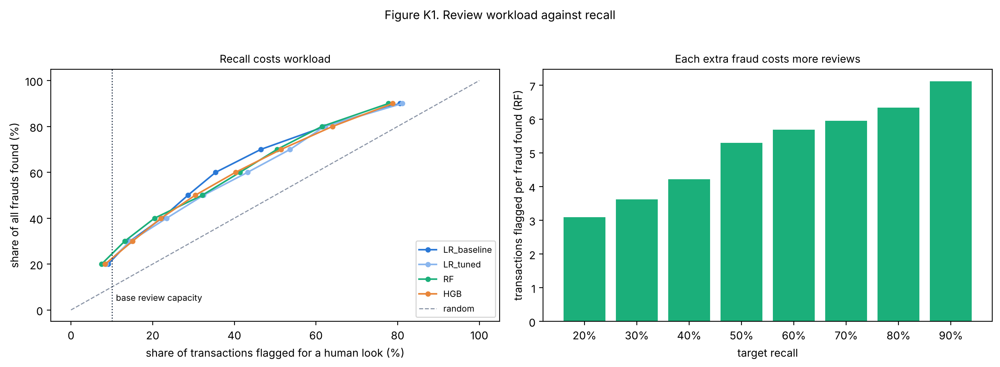

In [11]:
# Q4. Manual-review workload when recall rises
WL = fg.workload_vs_recall(S, Y); rf_w = WL[WL.model == "RF"].set_index("target_recall"); display(rf_w[["flagged_share", "reviews_per_month", "analysts", "precision", "flagged_per_fraud_found", "extra_reviews_per_extra_fraud"]].round(2))
print("Share of traffic that must be flagged to reach each recall, by model:"); display(WL.pivot(index="target_recall", columns="model", values="flagged_share")[MODELS].round(3))
rows = []; base = fg.SCENARIOS["S1_base"]; g = fg.make_grid(S["RF"]); costs = fg.row_costs(AMT, Y, base); surf = fg.surface(S["RF"], costs, g)
for cap_ in [0, .05, .10, .15, .20, .30, .50, 1.0]:
    t1, t2, c = fg.best_pair(surf, g, "three_way", cap_, .10); cost_, rr, br = surf; i, j = np.searchsorted(g, t1), np.searchsorted(g, t2)
    cap_frauds = np.mean([Y[s >= t1].sum() / Y.sum() for s in S["RF"]])
    rows.append(dict(review_capacity=cap_, cost_per_1000=c / N * 1000, analysts_needed=cap_ * 100000 / 1072, fraud_flagged_share=cap_frauds, review_rate=rr[i, j], block_rate=br[j]))
CAP = pd.DataFrame(rows); CAP["cost_saved_vs_previous"] = -CAP.cost_per_1000.diff(); CAP["extra_analysts"] = CAP.analysts_needed.diff(); CAP["saving_per_extra_analyst_per_month"] = CAP.cost_saved_vs_previous * 100 / CAP.extra_analysts
print("Cost of review capacity (RF, base costs, block cap 10%, in-sample optimum; 1 analyst = 1,072 reviews a month; per month at 100,000 transactions):"); display(CAP.round(2))
WL.to_csv(OUT / "K_workload_vs_recall.csv", index=False); CAP.to_csv(OUT / "K_review_capacity_value.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6)); C_ = {"LR_baseline": BLUE, "LR_tuned": "#8ab6ee", "RF": GREEN, "HGB": ORANGE}
for m in MODELS: q = WL[WL.model == m]; ax[0].plot(q.flagged_share * 100, q.target_recall * 100, marker="o", ms=4, color=C_[m], label=m)
ax[0].plot([0, 100], [0, 100], color=GREY, ls="--", lw=1, label="random"); ax[0].axvline(10, color=INK, ls=":", lw=1); ax[0].text(11, 4, "base review capacity", fontsize=8)
ax[0].set_xlabel("share of transactions flagged for a human look (%)"); ax[0].set_ylabel("share of all frauds found (%)"); ax[0].legend(fontsize=8); ax[0].set_title("Recall costs workload", fontsize=10)
ax[1].bar(range(len(rf_w)), rf_w.flagged_per_fraud_found, color=GREEN); ax[1].set_xticks(range(len(rf_w))); ax[1].set_xticklabels([f"{int(t * 100)}%" for t in rf_w.index]); ax[1].set_xlabel("target recall"); ax[1].set_ylabel("transactions flagged per fraud found (RF)"); ax[1].set_title("Each extra fraud costs more reviews", fontsize=10)
fig.suptitle("Figure K1. Review workload against recall", y=1.02, fontsize=11); plt.tight_layout(); plt.savefig(FIG / "K01_workload_vs_recall.png", dpi=130, bbox_inches="tight"); plt.show()

**Answer: it grows faster than recall, and every extra fraud costs more reviews than the last.** For the Random Forest, flagging 7.5% of traffic finds 20% of the frauds, 13% finds 30%, 20% finds 40%, 41% finds 60%, 61% finds 80% and 78% finds 90%.
* **Precision falls** from 33% to 14%; the number of transactions flagged per fraud found rises from 3.1 (20% recall) to 7.1 (90% recall), and the marginal cost from about 5 extra reviews per extra fraud (30% recall) to 13 (90%).
* **In people:** at 100,000 transactions a month, 20% recall needs about 7,500 reviews (7 analysts at 1,072 reviews each), 80% recall about 61,500 (57 analysts) and 90% about 77,750 (73 analysts). The base 10% capacity (9.3 analysts) can reach only about a quarter of the frauds by review alone, which is why the block tier exists.
* **Is more capacity worth it?** In the base scenario each step up in capacity lowers cost, with diminishing returns: 10% to 15% saves about 496 per 1,000 (roughly 50 thousand a month at 100,000 transactions, for 4.7 more analysts). The figure is already net of analyst time costed at 45 per productive hour; overheads, idle time and recruitment are not included, so the real saving is somewhat smaller; beyond 50% the saving per added analyst falls to about 1 thousand a month. The right size is a cost question, not a recall target.

#### Q5. Which feature interactions create the greatest change in risk?

In [12]:
# Q5. Which interactions change risk most? Development rows only. Flags are the same kind used in Part B; thresholds for "top quartile" and "top 10%" are learned on development rows.
IP, ACC = fg.interaction_pairs(dev, seed=SEED_K)
print("Fraud rate as warning signs accumulate (the five Part B red flags):"); display(ACC.round(3))
print("Pairs of flags with the highest fraud rate when both are present (36 pairs screened; excess = joint rate minus the additive expectation):")
display(IP.head(8)[["flag_a", "flag_b", "n_both", "rate_neither", "rate_a_only", "rate_b_only", "rate_both", "excess_over_additive", "ci_low", "ci_high"]].round(3))
print(f"{int(IP.excludes_zero.sum())} of {len(IP)} pairs have a 95% interval for the excess that excludes zero; about {0.05 * len(IP):.1f} would be expected by chance, and the smallest cells hold 8 to 68 rows.")
b = pd.read_csv(find("B_interaction_screen.csv")); print(f"Part B likelihood-ratio screen: {int(b.significant_bonferroni.sum())} of {len(b)} pairs significant after Bonferroni; smallest p = {b.p_value.min():.3f}.")
SH = pd.DataFrame([("n_red_flags x newdev_x_iprisk", .334, "yes (new_device)"), ("account_age_days x n_red_flags", .091, "no"), ("velocity_ratio_1h_24h x n_red_flags", .078, "no"), ("risk_mean x velocity_x_logamt", .078, "no"), ("n_red_flags x velocity_x_logamt", .073, "no")],
    columns=["SHAP interaction pair (Part H3 output)", "mean |interaction| (pts)", "shares a raw field"]); display(SH)
IP.to_csv(OUT / "K_interaction_pairs_dev.csv", index=False); ACC.to_csv(OUT / "K_red_flag_accumulation.csv", index=False)

Fraud rate as warning signs accumulate (the five Part B red flags):


,flags,n,fraud_rate
0,0,1376,0.086
1,1,829,0.136
2,2,168,0.262
3,3,27,0.556


Pairs of flags with the highest fraud rate when both are present (36 pairs screened; excess = joint rate minus the additive expectation):


,flag_a,flag_b,n_both,rate_neither,rate_a_only,rate_b_only,rate_both,excess_over_additive,ci_low,ci_high
0,auth_None,failed_logins_2plus,8,0.110,0.190,0.163,0.750,0.506,0.110,0.802
1,prior_chargeback,failed_logins_2plus,14,0.108,0.189,0.174,0.429,0.173,-0.116,0.471
2,new_device,auth_None,41,0.100,0.172,0.165,0.415,0.178,0.009,0.347
3,failed_logins_2plus,amount_top_10pct,5,0.108,0.198,0.199,0.400,0.111,-0.330,0.690
4,billing_mismatch,amount_top_10pct,20,0.108,0.156,0.185,0.400,0.166,-0.063,0.407
5,new_device,failed_logins_2plus,18,0.103,0.188,0.170,0.389,0.134,-0.105,0.367
6,new_device,prior_chargeback,43,0.098,0.176,0.170,0.372,0.124,-0.032,0.287
7,billing_mismatch,auth_None,27,0.108,0.152,0.188,0.370,0.138,-0.067,0.338


4 of 36 pairs have a 95% interval for the excess that excludes zero; about 1.8 would be expected by chance, and the smallest cells hold 8 to 68 rows.
Part B likelihood-ratio screen: 0 of 13 pairs significant after Bonferroni; smallest p = 0.083.


,SHAP interaction pair (Part H3 output),mean |interaction| (pts),shares a raw field
0,n_red_flags x newdev_x_iprisk,0.334,yes (new_device)
1,account_age_days x n_red_flags,0.091,no
2,velocity_ratio_1h_24h x n_red_flags,0.078,no
3,risk_mean x velocity_x_logamt,0.078,no
4,n_red_flags x velocity_x_logamt,0.073,no


**Answer: risk rises most when independent warning signs accumulate; no single pairwise interaction is supported statistically.**
* **Accumulation:** with 0, 1, 2 and 3 or more of the five red flags the fraud rate is 8.6%, 13.6%, 26.2% and 55.6% (27 rows).
* **Pairs:** the highest rates when both signs are present are authentication = None with two or more failed logins (75%, 8 rows), new device with authentication = None (41.5%, 41 rows) and prior chargeback with a top-quartile merchant risk (36.8%, 68 rows); their excess over the additive expectation has an interval above zero (+0.51, +0.18, +0.16). But 4 of 36 pairs pass such a test where about 1.8 would by chance, the cells are small, and the flags were chosen after seeing the data.
* **Part B and Part H agree:** none of 13 screened pairs, including new device x distance, amount x merchant risk and authentication x channel, survives Bonferroni (smallest p = 0.083). In the model, pairs carry 35% of SHAP magnitude, but the strongest pair (0.33 points) combines two inputs that both contain `new_device`; between inputs sharing no raw field the strongest is 0.09 points.
* **Power warning:** with 291 frauds a moderate interaction could exist and not be detected. The practical lever is the red-flag count, not a particular pair.

#### Q6. How sensitive is the recommended threshold to the assumed financial costs?

Base optimum on the rebuilt framework: review 0.157, block 0.208, cost 14,140 per 1,000 (Part E: 0.156 / 0.208, 14,183)


,parameter,low,high,cost_low,cost_high,swing,t_review_low,t_review_high,t_block_low,t_block_high,regret_low,regret_high
0,loss_share,0.50,1.00,9002.444,14140.305,5137.862,0.180,0.157,0.268,0.208,109.318,0.000
1,chargeback_fee,5.00,60.00,13369.889,17607.180,4237.292,0.157,0.157,0.208,0.208,0.000,0.000
2,fp_friction,5.00,60.00,13103.218,16262.026,3158.808,0.157,0.179,0.205,0.264,14.431,605.362
3,review_capacity,0.05,0.20,15531.654,12888.634,2643.020,0.179,0.137,0.208,0.239,-1391.349,1251.671
4,max_block_rate,0.02,0.20,15963.983,14084.383,1879.599,0.195,0.131,0.349,0.157,-1823.678,55.922
5,fp_margin,0.00,0.10,13270.402,15003.419,1733.018,0.157,0.157,0.206,0.208,6.790,-0.000
6,review_detect,0.60,0.95,15166.155,13704.999,1461.155,0.157,0.157,0.206,0.210,34.209,11.282
7,review_cost,2.00,15.00,13751.139,15015.017,1263.878,0.157,0.157,0.208,0.206,0.000,0.914
8,review_delay,0.00,5.00,14023.118,14413.743,390.625,0.157,0.157,0.208,0.208,0.000,0.000
9,review_wrong_decline,0.00,0.10,14068.681,14307.429,238.748,0.157,0.157,0.208,0.208,0.000,0.000


Sampling noise only (200 bootstrap resamples): review threshold 0.158 +/- 0.004, block threshold 0.209 +/- 0.008


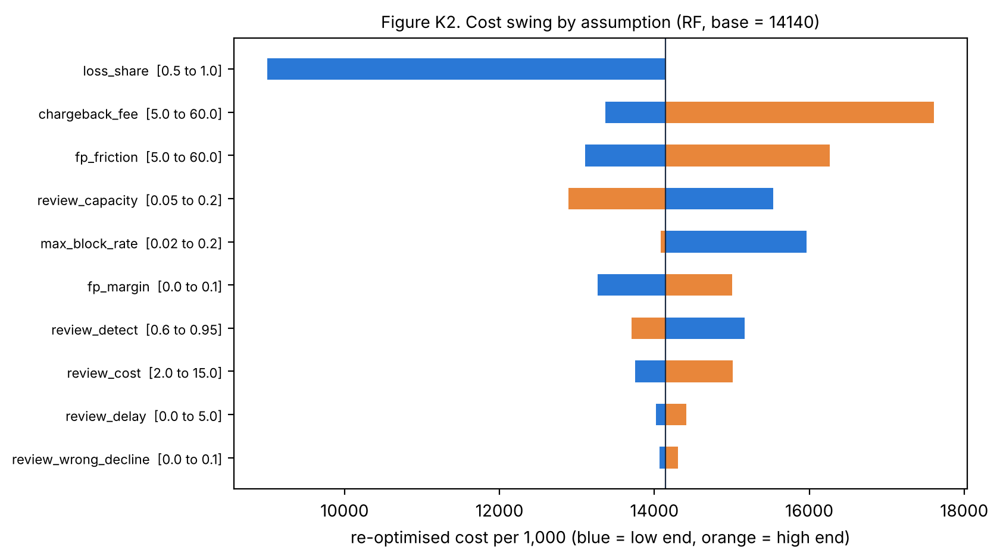

In [13]:
# Q6. Sensitivity of the recommended thresholds to the assumed costs (Random Forest, one parameter at a time, thresholds re-optimised)
TOR, (T1, T2, CB) = fg.tornado(S["RF"], AMT, Y); print(f"Base optimum on the rebuilt framework: review {T1:.3f}, block {T2:.3f}, cost {CB:,.0f} per 1,000 (Part E: 0.156 / 0.208, 14,183)")
display(TOR[["parameter", "low", "high", "cost_low", "cost_high", "swing", "t_review_low", "t_review_high", "t_block_low", "t_block_high", "regret_low", "regret_high"]].round(3))
rng = np.random.default_rng(SEED_K); costs = fg.row_costs(AMT, Y, fg.SCENARIOS["S1_base"]); bt = []
for _ in range(200):
    ix = rng.integers(0, N, N); Sb = [s[ix] for s in S["RF"]]; g_ = fg.make_grid(Sb, 500); t1, t2, c = fg.best_pair(fg.surface(Sb, tuple(x[ix] for x in costs), g_), g_, "three_way", .1, .1); bt.append((t1, t2))
bt = np.array(bt); print(f"Sampling noise only (200 bootstrap resamples): review threshold {bt[:, 0].mean():.3f} +/- {bt[:, 0].std():.3f}, block threshold {bt[:, 1].mean():.3f} +/- {bt[:, 1].std():.3f}")
fig, ax = plt.subplots(figsize=(8.5, 4.8)); o = TOR.sort_values("swing"); y_ = np.arange(len(o))
ax.barh(y_, o.cost_high - CB, left=CB, color=ORANGE, height=.5); ax.barh(y_, o.cost_low - CB, left=CB, color=BLUE, height=.5); ax.axvline(CB, color=INK, lw=.8)
ax.set_yticks(y_); ax.set_yticklabels([f"{p}  [{l} to {h}]" for p, l, h in zip(o.parameter, o.low, o.high)], fontsize=8); ax.set_xlabel("re-optimised cost per 1,000 (blue = low end, orange = high end)")
ax.set_title("Figure K2. Cost swing by assumption (RF, base = %.0f)" % CB, fontsize=10); plt.tight_layout(); plt.savefig(FIG / "K02_threshold_sensitivity.png", dpi=130, bbox_inches="tight"); plt.show()
TOR.to_csv(OUT / "K_threshold_sensitivity_tornado.csv", index=False)

**Answer: robust to sampling noise and to the cost of the review process, sensitive to the size of the loss, the cost of a wrongly blocked customer and the operating limits.**
* **Not sensitive:** review cost (2 to 15), review delay, the analysts' wrong-decline rate and detection rate leave the review threshold at 0.157 and the block threshold within 0.205 to 0.210. Sampling noise alone moves them by +/-0.004 and +/-0.008.
* **Sensitive:** the loss share of a fraud (0.5 raises the thresholds to 0.180 / 0.268), the friction cost of a blocked customer (at 60: 0.179 / 0.264, keeping the base thresholds would cost 605 per 1,000 more), review capacity (5%: 0.179 / 0.208; 20%: 0.137 / 0.239) and the block cap (2%: 0.195 / 0.349). Cost swings are largest for the loss share (5,138 per 1,000), chargeback fee (4,237), friction (3,159) and capacity (2,643).
* **Regret of keeping the base thresholds** elsewhere (Part E6): 0% to 0.2% in S2, S4, S6, but 7% in S3, 13% in S5 and 38% in S7. Negative regret in the table for capacity 5% and block cap 2% only means the base thresholds would break the tighter limit.
* **Consequence:** do not hard-code thresholds. The amount-aware rule with label-free shadow prices re-prices itself when limits change, and the textbook 0.135 does not apply because limits and the review option change the optimum.

#### Q7. Could a model with slightly lower predictive performance be preferable operationally under a different cost structure?

A. Honest cost per 1,000 by review capacity (block cap 10%):


model,LR_baseline,LR_tuned,RF,HGB
review_capacity,,,,
0.000,19046.0,18102.0,17029.0,18049.0
0.025,18145.0,17627.0,16554.0,17414.0
0.050,17578.0,17384.0,15788.0,16997.0
0.100,16700.0,16853.0,14354.0,15739.0
0.150,16080.0,16222.0,13982.0,14132.0
0.200,15593.0,15953.0,13065.0,13535.0
0.300,14316.0,15137.0,12534.0,12462.0
0.400,13536.0,14518.0,11728.0,11849.0
0.500,13039.0,13001.0,10858.0,11070.0


Paired verdict against RF (95% interval of the cost difference):


model,HGB_minus_RF,LR_baseline_minus_RF,LR_tuned_minus_RF
review_capacity,,,
0.000,tie,RF cheaper,tie
0.025,tie,tie,tie
0.050,tie,RF cheaper,RF cheaper
0.100,tie,RF cheaper,RF cheaper
0.150,tie,RF cheaper,RF cheaper
0.200,tie,RF cheaper,RF cheaper
0.300,tie,RF cheaper,RF cheaper
0.400,tie,RF cheaper,RF cheaper
0.500,tie,RF cheaper,RF cheaper


B. Which model is cheapest across 300 random cost structures (ranges: loss share 0.4-1.0, chargeback 5-80, FP friction 5-300, review cost 1-25, review capacity 2%-50%, block cap 2%-100%)


,structures,RF_cheapest_pct,HGB_cheapest_pct,LR_cheapest_pct,RF_significantly_cheaper_pct,alternative_significantly_cheaper_pct,median_RF_minus_best_alt_per1000,median_model_saving_vs_approve_all_pct
bucket,,,,,,,,
all 300 structures,300.0,65.0,31.0,4.0,5.0,1.0,-145.3,13.9
<1,60.0,38.3,48.3,13.3,3.3,5.0,53.1,4.5
1 to 3,92.0,66.3,29.3,4.3,6.5,0.0,-94.8,9.1
3 to 10,128.0,71.9,28.1,0.0,2.3,0.0,-305.2,17.9
>10,20.0,95.0,5.0,0.0,20.0,0.0,-439.6,30.7
<=5%,100.0,50.0,44.0,6.0,3.0,0.0,6.2,7.6
10% to 15%,80.0,85.0,13.8,1.2,8.8,0.0,-499.7,16.0
20% to 30%,86.0,61.6,33.7,4.7,4.7,2.3,-104.2,19.3
50%,34.0,70.6,26.5,2.9,2.9,2.9,-139.0,18.6


   Structures where an alternative is significantly cheaper than RF:


,fn_fp_ratio,fp_friction,review_capacity,max_block_rate,cheapest,approve_all,cost_RF,RF_minus_best_alt
3,0.62,105.50,0.3,0.02,LR_baseline,8968.74,9079.95,111.21
66,0.91,66.97,0.2,1.00,LR_baseline,8936.43,9063.63,127.20
116,0.61,120.96,0.5,0.05,LR_baseline,9266.04,9396.62,130.58


C. Monthly value of RF over the simple LR baseline at 100,000 transactions (hypothetical currency): {'S1': 235, 'S2': 233, 'S3': 148, 'S4': 237, 'S5': 255, 'S6': 113, 'S7': 88}


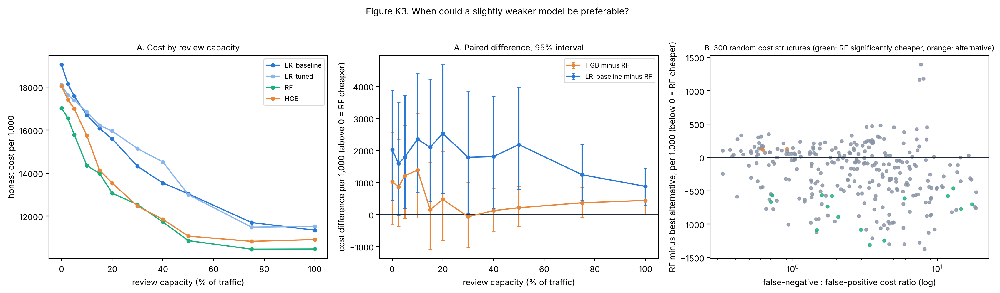

In [14]:
# Q7. Could a slightly weaker model be preferable under a different cost structure? Three quantitative tests, all with honest costs (thresholds chosen on training rows).
# Which is "slightly weaker"? By nested-CV PR-AUC and ROC-AUC the lowest is HGB (0.244, 0.659) against RF (0.249, 0.665); the LR baseline has the highest ROC-AUC (0.669) and is the simplest.
# Test A: review capacity (the cost structure parameter that changes ranking at depth), base cost parameters.
f_cap = OUT / "K_capacity_sweep_models.csv"; CAPS = pd.read_csv(f_cap) if f_cap.exists() else fg.capacity_sweep(S, AMT, Y)
if not f_cap.exists(): CAPS.to_csv(f_cap, index=False)
a = CAPS[~CAPS.model.str.contains("minus")].pivot(index="review_capacity", columns="model", values="cost_per_1000")[MODELS]; d_ = CAPS[CAPS.model.str.contains("minus")]
print("A. Honest cost per 1,000 by review capacity (block cap 10%):"); display(a.round(0))
dd = d_.assign(verdict=lambda x: np.where(x.ci_low > 0, "RF cheaper", np.where(x.ci_high < 0, "alternative cheaper", "tie"))).pivot(index="review_capacity", columns="model", values="verdict")
print("Paired verdict against RF (95% interval of the cost difference):"); display(dd)
# Test B: 300 random cost structures drawn from wide ranges fixed before running (seed 42).
f_mc = OUT / "K_cost_structure_monte_carlo.csv"; MC = pd.read_csv(f_mc) if f_mc.exists() else fg.cost_structure_monte_carlo(S, AMT, Y, K=300, seed=SEED_K)
if not f_mc.exists(): MC.to_csv(f_mc, index=False)
tot = fg.summarise_monte_carlo(MC.assign(all=1), "all", [0, 2], ["all 300 structures"])
by_ratio = fg.summarise_monte_carlo(MC, "fn_fp_ratio", [0, 1, 3, 10, 1e9], ["<1", "1 to 3", "3 to 10", ">10"]); by_cap = fg.summarise_monte_carlo(MC, "review_capacity", [0, .05, .15, .30, 1], ["<=5%", "10% to 15%", "20% to 30%", "50%"])
print("B. Which model is cheapest across 300 random cost structures (ranges: loss share 0.4-1.0, chargeback 5-80, FP friction 5-300, review cost 1-25, review capacity 2%-50%, block cap 2%-100%)"); display(pd.concat([tot, by_ratio, by_cap]).round(1))
print("   Structures where an alternative is significantly cheaper than RF:"); display(MC[MC.ci_low > 0][["fn_fp_ratio", "fp_friction", "review_capacity", "max_block_rate", "cheapest", "approve_all", "cost_RF", "RF_minus_best_alt"]].round(2))
# Test C: what the RF advantage is worth against what complexity might cost.
ad = {sn: -(ROW[(sn, "RF")] - ROW[(sn, "LR_baseline")]).mean() * 100000 / 1000 for sn in fg.SCENARIOS}; print("C. Monthly value of RF over the simple LR baseline at 100,000 transactions (hypothetical currency):", {k.split('_')[0]: round(v) for k, v in ad.items()})
by_ratio.to_csv(OUT / "K_weaker_model_by_cost_ratio.csv"); by_cap.to_csv(OUT / "K_weaker_model_by_capacity.csv")
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8)); x = a.index.values * 100
for m in MODELS: ax[0].plot(x, a[m], marker="o", ms=4, color=C_[m], label=m)
ax[0].set_xlabel("review capacity (% of traffic)"); ax[0].set_ylabel("honest cost per 1,000"); ax[0].set_title("A. Cost by review capacity", fontsize=10); ax[0].legend(fontsize=8)
for m, c_ in [("HGB", ORANGE), ("LR_baseline", BLUE)]:
    q = d_[d_.model == f"{m}_minus_RF"]; ax[1].errorbar(q.review_capacity * 100, q.cost_per_1000, yerr=[q.cost_per_1000 - q.ci_low, q.ci_high - q.cost_per_1000], fmt="o-", ms=4, capsize=2, color=c_, label=f"{m} minus RF")
ax[1].axhline(0, color=INK, lw=.8); ax[1].set_xlabel("review capacity (% of traffic)"); ax[1].set_ylabel("cost difference per 1,000 (above 0 = RF cheaper)"); ax[1].set_title("A. Paired difference, 95% interval", fontsize=10); ax[1].legend(fontsize=8)
ax[2].scatter(MC.fn_fp_ratio, MC.RF_minus_best_alt, s=14, c=np.where(MC.ci_high < 0, GREEN, np.where(MC.ci_low > 0, ORANGE, GREY)), alpha=.8); ax[2].axhline(0, color=INK, lw=.8); ax[2].set_xscale("log")
ax[2].set_xlabel("false-negative : false-positive cost ratio (log)"); ax[2].set_ylabel("RF minus best alternative, per 1,000 (below 0 = RF cheaper)"); ax[2].set_title("B. 300 random cost structures (green: RF significantly cheaper, orange: alternative)", fontsize=9)
fig.suptitle("Figure K3. When could a slightly weaker model be preferable?", y=1.03, fontsize=11); plt.tight_layout(); plt.savefig(FIG / "K03_weaker_model.png", dpi=130, bbox_inches="tight"); plt.show()

**Answer: in principle yes, but this data does not show a case where the weaker model is reliably better; it shows where the Random Forest's advantage is large and where it disappears.** Evidence from three tests with honest costs:
* **A. Review capacity (base costs).** HGB, which has the lowest PR-AUC (0.244 against 0.249) and ROC-AUC, is statistically tied with the Random Forest at every capacity below 100% and has a lower point estimate only at 30% (12,462 against 12,534, a difference of about 70 that is inside the noise). The Logistic Regression baseline is significantly dearer than the Random Forest at 10 of 11 capacities, by 875 to 2,528 per 1,000.
* **B. 300 random cost structures** (wide ranges, seed fixed in advance). The Random Forest is cheapest by point estimate in 65%, HGB in 31%, an LR model in 4%. But its advantage over the best alternative is statistically significant in only 5% of structures, and an alternative is significantly cheaper in 1% (3 structures). In those 3 the cost of a wrongly blocked customer exceeds the cost of a missed fraud (ratio 0.6 to 0.9) and the model policy costs more than approving everything, so the lesson is that no model is worth running, not that the weaker one is better. Where missed frauds cost less than wrongly blocked customers (60 structures) the Random Forest is cheapest in only 38% and the model saves a median of 4.5% against approving everything; with review capacity of 5% or less it is cheapest in 50%, with a median gap of 6 per 1,000, i.e. none. Where fraud is much dearer than a block (ratio above 10) it is cheapest in 95%.
* **C. What the advantage is worth.** Against the simple baseline the Random Forest saves 88 to 255 thousand a month at 100,000 transactions (hypothetical currency; base 235 thousand). A simpler model would only be preferable if its operational advantages (transparency, stability, maintenance) were worth more than that. Against HGB the paired difference is not distinguishable from zero at any capacity below 100%, so there the choice can be made on other grounds.
* **Recommendation:** keep the Random Forest; keep the Logistic Regression baseline as the transparent challenger and as the first model to use if review capacity falls to a few percent or the business becomes strongly customer-first, where the gap is smallest.

#### Q8. Which data fields should be monitored most closely for drift after deployment?

In [15]:
# Q8. Fields to monitor most closely: the ranked table above (K5) plus the evidence on what label-free monitors can and cannot see
print("Part J8: 19 scenarios were rated Watch or Fail (excluding the 2 Info rows); 11 of them would not have triggered any PSI alert at the textbook 0.10 / 0.25 bands.")
print("Missed by the textbook PSI bands: mean amount +60%, amounts x1.25 (PSI 0.069), evasion (PSI 0.000), authentication None at 40% (PSI 0.079), amount missing 20% (PSI 0.008), uncorrected prevalence shifts (PSI 0.00).")
print("Caught early: velocity changes (PSI 0.38 to 4.05), the combined shift (0.39), amounts x2 (0.63). Missing-rate and decision-mix monitors (M1, M2, M6) cover the first group; outcome monitors (M3, M4, M7, M8) cover the evasion and prevalence cases.")
print("Tier-1 fields:", ", ".join(DR[DR.priority_tier == 1].index))

Part J8: 19 scenarios were rated Watch or Fail (excluding the 2 Info rows); 11 of them would not have triggered any PSI alert at the textbook 0.10 / 0.25 bands.
Missed by the textbook PSI bands: mean amount +60%, amounts x1.25 (PSI 0.069), evasion (PSI 0.000), authentication None at 40% (PSI 0.079), amount missing 20% (PSI 0.008), uncorrected prevalence shifts (PSI 0.00).
Caught early: velocity changes (PSI 0.38 to 4.05), the combined shift (0.39), amounts x2 (0.63). Missing-rate and decision-mix monitors (M1, M2, M6) cover the first group; outcome monitors (M3, M4, M7, M8) cover the evasion and prevalence cases.
Tier-1 fields: transaction_amount, transactions_last_1h, authentication_level, merchant_risk_score, ip_risk_score, new_device


**Answer: six Tier-1 fields, monitored daily, then three Tier-2 fields (prior chargebacks, billing mismatch, failed logins) weekly; channel, time and country need only schema checks.**
1. **`transaction_amount`**: the largest operational risk. Amounts x1.5 push the review queue to 19% (Fail), +60% to 12.4% (Watch), 20% missing costs 7.8 points of saving, and the top 1% of rows hold 12% of all value.
2. **`transactions_last_1h`** (velocity): +50% moves the block share to 13.9%; counting changes x1.5 and x2 to 12.5% and 13.9%.
3. **`authentication_level`**: watch the share of "None". At 40% (development 9.5%) the block share reaches 15.9% (Fail) and the usual drift statistic stays quiet (PSI 0.079), so use a level-share and missing-rate check, not PSI alone.
4. **`merchant_risk_score` and `ip_risk_score`**: the largest SHAP family; if the vendor feed drops its high readings PR-AUC falls 6% and probabilities run 15% low (calibration ratio 0.85), yet the Part J rules still rate it Pass, so only M3 would catch it.
5. **`new_device`**: first in permutation importance and an input to `n_red_flags`, so a feed fault there changes several inputs at once.
* **Model outputs:** the calibrated probability and the review and block shares daily, the shadow prices daily, calibration and the fraud-rate estimate monthly.
* **What drift statistics cannot see:** 11 of the 19 Watch or Fail scenarios in Part J would not trigger a PSI alert at 0.10 / 0.25, among them fraudsters hiding red flags (PSI 0.000) and a changed fraud rate. Those need outcome monitors (M3, M4, M7, M8) and a random sample of approved transactions.

### K7. Save the Part K outputs

In [16]:
# K7. Save the Part K evidence tables (the monitoring plan and trigger tables were saved above)
saved = sorted(p.name for p in OUT.glob("K_*.csv")); print(len(saved), "Part K files in", OUT, ":", saved); print("figures:", sorted(p.name for p in FIG.glob("K0*.png")))

19 Part K files in outputs : ['K_capacity_sweep_models.csv', 'K_cost_structure_monte_carlo.csv', 'K_drift_monitoring_fields.csv', 'K_drift_monitoring_outputs.csv', 'K_interaction_pairs_dev.csv', 'K_model_card_facts.csv', 'K_model_cost_vs_LR_baseline.csv', 'K_monitoring_metrics.csv', 'K_prauc_window_noise.csv', 'K_psi_null_by_window.csv', 'K_red_flag_accumulation.csv', 'K_retrain_review_disable_triggers.csv', 'K_review_capacity_value.csv', 'K_threshold_sensitivity_tornado.csv', 'K_validation_vs_partE.csv', 'K_value_weighted_capture.csv', 'K_weaker_model_by_capacity.csv', 'K_weaker_model_by_cost_ratio.csv', 'K_workload_vs_recall.csv']
figures: ['K01_workload_vs_recall.png', 'K02_threshold_sensitivity.png', 'K03_weaker_model.png']


### K8. Findings and decisions

**Governance outputs.** A model card (`06_model_card.pdf`), ten monitoring metrics with green / amber / red rules (K4), a drift plan for six Tier-1 fields, three Tier-2 fields and five model outputs (K5), and fourteen retrain / review / disable triggers (K6) that name the action and the evidence behind each threshold. The tables are in `outputs/K_*.csv`.

**Calibration of the plan against noise.** Daily PSI sampling noise is about 0.005, so the usual 0.10 / 0.25 bands are too coarse for amount and score; the plan uses 0.01 sustained for three days as an investigation level and the decision-mix guards (review and block shares) as the operational trigger. A 10% PR-AUC drop needs about 1,100 matured frauds to be seen, so ranking quality is judged on a window sized by frauds.

**Answers in one line each.** (1) `new_device` and `merchant_risk_score` lead and are stable; the rest is only moderately stable. (2) No: the Random Forest is cheapest in all seven scenarios although the baseline has the best ROC-AUC. (3) Calibrated probabilities can be planned with, priced by amount and audited per action group. (4) Workload grows faster than recall: 7.5% flagged finds 20% of frauds, 62% finds 80%. (5) Accumulating red flags matter; no pairwise interaction is supported. (6) Thresholds are robust to sampling and review-process costs and sensitive to loss size, friction and operating limits. (7) A weaker model was never reliably better; the Random Forest's advantage shrinks when review capacity is tiny or false positives are dearer than missed frauds. (8) Amount, velocity, authentication = None, merchant and IP risk, new device.

**Limits.** Costs are hypothetical and the 12.1% fraud rate is far above a real portfolio, so absolute amounts and the PSI and window sizes will change; the monitoring thresholds that are not tied to a measurement are judgement; the interaction screen and the random cost structures are exploratory; everything rests on 291 frauds; the hold-out set (600 rows, 73 frauds) has not been read and is still available for one final check; no fairness assessment by customer group has been done, because the data has no protected attributes (country and customer tier are used only as inputs).

**Before go-live:** run in shadow mode for a full month, calibrate the PSI levels on live data, re-run the cost framework at the real fraud rate, and carry out the single hold-out check.

---
## Conclusion and submission map

**What was built.** A Random Forest (no class weights, no resampling) with a Platt calibration layer, and an amount-aware Approve / Review / Block rule that picks the cheapest of the three actions for each transaction under review and block limits of 10% each. A fixed-threshold version (review from 0.158, block from 0.212 on the calibrated probability) is the simple fallback.

**What it is worth (hypothetical costs, 100,000 transactions a month).** Expected cost about 1.20 million against 2.07 million for approving everything (42% lower) and 1.25 million for simple business rules (4.2% lower, not statistically reliable). It stops 31.8% of frauds by number and 60.6% by value, touches 18.2% of genuine customers, and needs about 11 analysts.

**How far to trust it.** The ranking signal is modest (PR-AUC 0.249 against 0.121 for no skill) and rests on 291 frauds. Model differences are mostly within noise, so the choice of the Random Forest rests on cost evidence. The largest risk is a real fraud rate far below 12.1%, which needs the prior-shift correction and a re-run of the cost analysis before go-live.

**Where each task question is answered**

| Question | Where |
|---|---|
| Strongest predictors and their stability | B8, D7, H10, Q1 |
| Highest ROC-AUC vs best business outcome | E7, Q2 |
| What calibration changes operationally | F9, Q3 |
| Review workload as recall rises | E7, Q4 |
| Interactions with the greatest change in risk | B8, H10, Q5 |
| Threshold sensitivity to costs | E7, Q6 |
| Could a weaker model be preferable | E7, Q7 |
| Fields to monitor for drift | J, K5, Q8 |

**Status of the hold-out set.** The 600-row hold-out set (73 frauds) has not been read by any part. The remaining step before sign-off is one final check: score it once with the frozen `04_calibrated_model.joblib` and the fixed thresholds above, record the result in the model card, and change nothing afterwards.

**Final deliverables:** `01` this notebook, `02_processed_dataset.csv`, `03_fraud_model_pipeline.joblib`, `04_calibrated_model.joblib`, `05_threshold_cost_analysis.csv`, `06_model_card.pdf`, `07_business_fraud_strategy.pdf`, `08_README.md`.